# Attention-Enhanced Deep Learning for Microplastic Segmentation

## Project Description

Microplastic pollution is an increasing environmental concern, and the accurate identification and segmentation of microplastic particles from Scanning Electron Microscopy (SEM) images is important for automated microplastic analysis.

This project develops an **attention-enhanced deep learning framework for semantic segmentation of microplastics in SEM images**. A standard **U-Net** is first established as the baseline model, followed by an **Attention U-Net** that incorporates attention gates into the encoder-decoder architecture to emphasize informative regions and suppress irrelevant background features.

The framework is evaluated through a systematic experimental pipeline including:

- Baseline U-Net vs. Attention U-Net comparison
- Attention-gate ablation experiments
- Quantitative analysis of attention maps
- Robustness evaluation under image perturbations
- Qualitative segmentation visualization
- Comprehensive segmentation performance evaluation

The experiments are conducted using a validated **Microplastics SEM dataset containing 237 image-mask pairs** with leakage-controlled training, validation, and test splits.

Model performance is evaluated using:

**Dice Score, IoU, Precision, Recall, Specificity, F1-Score, Accuracy, and Balanced Accuracy.**

The main objective is to investigate whether attention mechanisms can improve microplastic segmentation performance and to analyze the contribution, behavior, and robustness of individual attention gates within the segmentation architecture.

---

### Research Objectives

1. Develop a reliable U-Net-based semantic segmentation framework for microplastic SEM images.
2. Evaluate the effect of incorporating attention mechanisms into U-Net.
3. Investigate the contribution of individual attention gates through systematic ablation experiments.
4. Analyze attention maps to understand where the model focuses during segmentation.
5. Evaluate model robustness under realistic image perturbations.
6. Provide reproducible and publication-oriented experimental results for automated microplastic segmentation.

**Kaggle Environment + Project Initialization**

In [2]:
# ============================================================
# CELL 1 — Kaggle Environment & Project Initialization
# Project: Attention-Enhanced Deep Learning for Microplastic Segmentation
# ============================================================

import os
import sys
import random
import platform
from pathlib import Path

import numpy as np
import torch
import torchvision


# ============================================================
# 1. Reproducibility
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Reproducibility where practical
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# 2. Project Directory Structure
# ============================================================

PROJECT_ROOT = Path("/kaggle/working/microplastic_project")

DIRECTORIES = [
    "configs",
    "data",
    "checkpoints",
    "logs",
    "results",
    "figures",
    "predictions",
    "reports",
    "source",
]

for directory in DIRECTORIES:
    (PROJECT_ROOT / directory).mkdir(parents=True, exist_ok=True)


# ============================================================
# 3. GPU / CUDA Information
# ============================================================

cuda_available = torch.cuda.is_available()

if cuda_available:
    gpu_count = torch.cuda.device_count()
    gpu_name = torch.cuda.get_device_name(0)

    gpu_memory_gb = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    cuda_version = torch.version.cuda
else:
    gpu_count = 0
    gpu_name = "N/A"
    gpu_memory_gb = 0.0
    cuda_version = None


# ============================================================
# 4. Environment Summary
# ============================================================

print("=" * 72)
print("MICROPLASTIC SEGMENTATION — KAGGLE ENVIRONMENT")
print("=" * 72)

print(f"Python Version      : {sys.version.split()[0]}")
print(f"Platform            : {platform.platform()}")
print(f"PyTorch Version     : {torch.__version__}")
print(f"Torchvision Version : {torchvision.__version__}")
print(f"CUDA Available      : {cuda_available}")
print(f"CUDA Version        : {cuda_version}")
print(f"GPU Count           : {gpu_count}")
print(f"GPU                 : {gpu_name}")
print(f"GPU Memory          : {gpu_memory_gb:.2f} GB")
print(f"Random Seed         : {SEED}")
print(f"Project Root        : {PROJECT_ROOT}")

print("\nProject Directories:")

for directory in DIRECTORIES:
    path = PROJECT_ROOT / directory
    print(f"  ✓ {path}")


# ============================================================
# 5. Final Verification
# ============================================================

print("\nDirectory Verification:")

all_directories_exist = all(
    (PROJECT_ROOT / directory).is_dir()
    for directory in DIRECTORIES
)

print(f"All directories created successfully: {all_directories_exist}")

print("\n" + "=" * 72)
print("CELL 1 COMPLETED — DATASET NOT TOUCHED")
print("=" * 72)

MICROPLASTIC SEGMENTATION — KAGGLE ENVIRONMENT
Python Version      : 3.12.13
Platform            : Linux-6.12.90+-x86_64-with-glibc2.35
PyTorch Version     : 2.10.0+cu128
Torchvision Version : 0.25.0+cu128
CUDA Available      : True
CUDA Version        : 12.8
GPU Count           : 2
GPU                 : Tesla T4
GPU Memory          : 14.56 GB
Random Seed         : 42
Project Root        : /kaggle/working/microplastic_project

Project Directories:
  ✓ /kaggle/working/microplastic_project/configs
  ✓ /kaggle/working/microplastic_project/data
  ✓ /kaggle/working/microplastic_project/checkpoints
  ✓ /kaggle/working/microplastic_project/logs
  ✓ /kaggle/working/microplastic_project/results
  ✓ /kaggle/working/microplastic_project/figures
  ✓ /kaggle/working/microplastic_project/predictions
  ✓ /kaggle/working/microplastic_project/reports
  ✓ /kaggle/working/microplastic_project/source

Directory Verification:
All directories created successfully: True

CELL 1 COMPLETED — DATASET NOT TOUCHE

**Inspect Installed Packages**

In [3]:
# ============================================================
# CELL 2 — Installed Package Verification
# ============================================================

import importlib.util
import pkgutil

# Packages relevant to our research pipeline
REQUIRED_PACKAGES = [
    "numpy",
    "pandas",
    "PIL",
    "cv2",
    "matplotlib",
    "seaborn",
    "sklearn",
    "scipy",
    "yaml",
    "tqdm",
    "albumentations",
    "torchmetrics",
    "segmentation_models_pytorch",
    "timm",
    "torchinfo",
]

print("=" * 72)
print("PACKAGE AVAILABILITY CHECK")
print("=" * 72)

for package in REQUIRED_PACKAGES:
    available = importlib.util.find_spec(package) is not None
    status = "AVAILABLE" if available else "NOT INSTALLED"
    print(f"{package:<30} : {status}")

print("\n" + "=" * 72)
print("PACKAGE CHECK COMPLETED")
print("No packages were installed or modified.")
print("=" * 72)

PACKAGE AVAILABILITY CHECK
numpy                          : AVAILABLE
pandas                         : AVAILABLE
PIL                            : AVAILABLE
cv2                            : AVAILABLE
matplotlib                     : AVAILABLE
seaborn                        : AVAILABLE
sklearn                        : AVAILABLE
scipy                          : AVAILABLE
yaml                           : AVAILABLE
tqdm                           : AVAILABLE
albumentations                 : AVAILABLE
torchmetrics                   : AVAILABLE
segmentation_models_pytorch    : NOT INSTALLED
timm                           : AVAILABLE
torchinfo                      : AVAILABLE

PACKAGE CHECK COMPLETED
No packages were installed or modified.


**Create Research Configuration**

In [4]:
# ============================================================
# CELL 3 — Central Research Configuration
# ============================================================

from pathlib import Path
import json

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path("/kaggle/working/microplastic_project")

CONFIG_DIR = PROJECT_ROOT / "configs"
CONFIG_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Research configuration
# ------------------------------------------------------------

CONFIG = {
    "project": {
        "name": "Attention-Enhanced Deep Learning for Microplastic Segmentation",
        "version": "1.0",
        "seed": 42,
        "platform": "Kaggle",
        "independent_research": True
    },

    "data": {
        "dataset_name": "Microplastics_SEM",
        "source": "Mendeley Data",
        "dataset_url": "https://data.mendeley.com/datasets/z6459vntbr/3",
        "image_size": None,
        "num_classes": None,
        "class_names": None
    },

    "training": {
        "batch_size": None,
        "epochs": None,
        "optimizer": None,
        "learning_rate": None,
        "weight_decay": None,
        "scheduler": None,
        "mixed_precision": True,
        "gradient_clipping": False,
        "early_stopping": True
    },

    "evaluation": {
        "metrics": [
            "mIoU",
            "mean_Dice",
            "per_class_IoU",
            "per_class_Dice",
            "precision",
            "recall",
            "pixel_accuracy"
        ]
    },

    "compute": {
        "gpu_count": 2,
        "multi_gpu": False,
        "measure_parameters": True,
        "measure_flops": True,
        "measure_inference_time": True,
        "measure_gpu_memory": True
    },

    "experiments": {
        "baselines": [
            "U-Net",
            "strong_segmentation_baseline"
        ],
        "ablation_required": True,
        "robustness_required": True,
        "explainability_required": True,
        "multiple_seeds_if_feasible": True
    }
}

# ------------------------------------------------------------
# Save configuration
# ------------------------------------------------------------

config_path = CONFIG_DIR / "research_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=4)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 72)
print("CENTRAL RESEARCH CONFIGURATION")
print("=" * 72)

print(f"Configuration file : {config_path}")
print(f"Project name       : {CONFIG['project']['name']}")
print(f"Dataset            : {CONFIG['data']['dataset_name']}")
print(f"Random seed        : {CONFIG['project']['seed']}")
print(f"Mixed precision    : {CONFIG['training']['mixed_precision']}")
print(f"Evaluation metrics : {len(CONFIG['evaluation']['metrics'])}")
print(f"Ablation required  : {CONFIG['experiments']['ablation_required']}")
print(f"Robustness required: {CONFIG['experiments']['robustness_required']}")
print(f"Explainability     : {CONFIG['experiments']['explainability_required']}")

print("\nConfiguration saved successfully.")
print("=" * 72)

CENTRAL RESEARCH CONFIGURATION
Configuration file : /kaggle/working/microplastic_project/configs/research_config.json
Project name       : Attention-Enhanced Deep Learning for Microplastic Segmentation
Dataset            : Microplastics_SEM
Random seed        : 42
Mixed precision    : True
Evaluation metrics : 7
Ablation required  : True
Robustness required: True
Explainability     : True

Configuration saved successfully.


**Locate the Dataset on Kaggle**

In [8]:
# ============================================================
# CELL 5 — Search Kaggle Input Directory / Metadata
# ============================================================

from pathlib import Path
import os

print("=" * 72)
print("KAGGLE DATASET ENVIRONMENT CHECK")
print("=" * 72)

print("\nKaggle input directory:")
print(Path("/kaggle/input"))

print("\nCurrent Kaggle environment variables:")
for key in sorted(os.environ):
    if "KAGGLE" in key.upper():
        value = os.environ[key]

        # Avoid printing potentially sensitive values
        if any(x in key.upper() for x in ["KEY", "TOKEN", "PASSWORD", "SECRET"]):
            value = "[HIDDEN]"

        print(f"{key}: {value}")

print("\n" + "=" * 72)
print("No dataset files will be downloaded or modified.")
print("=" * 72)

KAGGLE DATASET ENVIRONMENT CHECK

Kaggle input directory:
/kaggle/input

Current Kaggle environment variables:
KAGGLE_API_V1_TOKEN: [HIDDEN]
KAGGLE_CONTAINER_NAME: kaggle_uJ3IaW0h1VXMFxpyQHqhzCtNwExzpHzIMyZDQ1IDAAc-353584739-webtier
KAGGLE_DATA_PROXY_PROJECT: kaggle-161607
KAGGLE_DATA_PROXY_TOKEN: [HIDDEN]
KAGGLE_DATA_PROXY_URL: https://dp.kaggle.net
KAGGLE_DISABLE_GOOGLE_GENERATIVE_AI_INTEGRATION: True
KAGGLE_DOCKER_IMAGE: gcr.io/kaggle-gpu-images/python@sha256:37c64f7dd9c54116ecd1bcc88817c5469b88387388fade02bfa8bf3fc647d461
KAGGLE_GCP_ZONE: us-central1-f
KAGGLE_GRPC_DATA_PROXY_URL: dp.kaggle.net:443
KAGGLE_KERNEL_INTEGRATIONS: 
KAGGLE_KERNEL_RUN_TYPE: Interactive
KAGGLE_URL_BASE: https://www.kaggle.com
KAGGLE_USER_SECRETS_TOKEN: [HIDDEN]

No dataset files will be downloaded or modified.


In [2]:
# ============================================================
# CELL 5 — Dataset Structure Inspection
# ============================================================

from pathlib import Path

KAGGLE_INPUT = Path("/kaggle/input")

print("=" * 72)
print("MICROPLASTICS_SEM — DATASET STRUCTURE INSPECTION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Find attached datasets
# ------------------------------------------------------------

dataset_dirs = [
    path for path in KAGGLE_INPUT.iterdir()
    if path.is_dir()
]

print(f"\nAttached datasets found: {len(dataset_dirs)}")

if not dataset_dirs:
    raise FileNotFoundError(
        "No dataset found under /kaggle/input/. "
        "Please verify that the Kaggle dataset is attached."
    )

# ------------------------------------------------------------
# 2. Inspect each dataset
# ------------------------------------------------------------

for dataset_dir in sorted(dataset_dirs):

    print("\n" + "-" * 72)
    print(f"DATASET DIRECTORY: {dataset_dir}")
    print("-" * 72)

    # Recursive file listing
    all_files = [
        path for path in dataset_dir.rglob("*")
        if path.is_file()
    ]

    all_dirs = [
        path for path in dataset_dir.rglob("*")
        if path.is_dir()
    ]

    print(f"Directories : {len(all_dirs)}")
    print(f"Files       : {len(all_files)}")

    # --------------------------------------------------------
    # Show directory tree (limited for readability)
    # --------------------------------------------------------

    print("\nDirectory / file structure:")

    relative_items = sorted(
        dataset_dir.rglob("*"),
        key=lambda p: str(p).lower()
    )

    max_items = 200

    for i, item in enumerate(relative_items[:max_items]):

        relative_path = item.relative_to(dataset_dir)

        if item.is_dir():
            print(f"  [DIR]  {relative_path}")
        else:
            size_mb = item.stat().st_size / (1024 ** 2)
            print(f"  [FILE] {relative_path} ({size_mb:.2f} MB)")

    if len(relative_items) > max_items:
        print(
            f"\n  ... {len(relative_items) - max_items} additional "
            "items not displayed."
        )

    # --------------------------------------------------------
    # File-extension summary
    # --------------------------------------------------------

    extension_counts = {}

    for file in all_files:
        extension = file.suffix.lower() or "[NO EXTENSION]"
        extension_counts[extension] = (
            extension_counts.get(extension, 0) + 1
        )

    print("\nFile extension summary:")

    for extension, count in sorted(extension_counts.items()):
        print(f"  {extension:<15} : {count}")

print("\n" + "=" * 72)
print("DATASET STRUCTURE INSPECTION COMPLETED")
print("No dataset files were modified.")
print("=" * 72)

MICROPLASTICS_SEM — DATASET STRUCTURE INSPECTION

Attached datasets found: 1

------------------------------------------------------------------------
DATASET DIRECTORY: /kaggle/input/datasets
------------------------------------------------------------------------
Directories : 113
Files       : 7533

Directory / file structure:
  [DIR]  mahmudnadim
  [DIR]  mahmudnadim/microplastics-sem-v1-semantic-segmentation
  [DIR]  mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1
  [DIR]  mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1
  [DIR]  mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1/dataset1
  [DIR]  mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1/dataset1/[datasets_full]_Exp1_Exp4
  [DIR]  mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1/dataset1/[datasets_full]_Exp1_Exp4/image
  [FILE] mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/

Inspect the Mounted Dataset Completely

**Identify Images, Masks, Labels & Dataset Subsets**

In [4]:
# ============================================================
# CELL 7 — Identify Images, Masks, Labels & Dataset Subsets
# ============================================================

from pathlib import Path
from collections import Counter

INPUT_ROOT = Path("/kaggle/input/datasets")

print("=" * 72)
print("MICROPLASTICS_SEM — IMAGE / MASK / LABEL STRUCTURE")
print("=" * 72)

# ------------------------------------------------------------
# 1. Find all directories
# ------------------------------------------------------------

all_dirs = sorted(
    [p for p in INPUT_ROOT.rglob("*") if p.is_dir()],
    key=lambda p: str(p).lower()
)

print(f"\nTotal directories: {len(all_dirs)}")

print("\nImportant directories:")
print("-" * 72)

keywords = [
    "image",
    "images",
    "mask",
    "masks",
    "label",
    "labels",
    "annotation",
    "annotations",
    "segmentation",
    "semantic",
    "ground",
    "truth",
    "gt",
    "train",
    "test",
    "validation",
    "val"
]

matched_dirs = []

for directory in all_dirs:
    name_lower = directory.name.lower()

    if any(keyword in name_lower for keyword in keywords):
        matched_dirs.append(directory)

for directory in matched_dirs:
    relative = directory.relative_to(INPUT_ROOT)

    files_inside = [
        p for p in directory.rglob("*")
        if p.is_file()
    ]

    print(f"\n[{directory.name}]")
    print(f"Path  : {relative}")
    print(f"Files : {len(files_inside)}")

# ------------------------------------------------------------
# 2. Count files by immediate parent directory
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("FILE COUNTS BY PARENT DIRECTORY")
print("=" * 72)

parent_counts = Counter()

for file in INPUT_ROOT.rglob("*"):
    if file.is_file():
        parent_counts[str(file.parent.relative_to(INPUT_ROOT))] += 1

for parent, count in sorted(
    parent_counts.items(),
    key=lambda x: (-x[1], x[0])
):
    print(f"{count:5d} files | {parent}")

# ------------------------------------------------------------
# 3. JSON / TXT files
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("METADATA / ANNOTATION FILES")
print("=" * 72)

special_files = [
    p for p in INPUT_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in {".json", ".txt"}
]

print(f"\nJSON/TXT files found: {len(special_files)}")

for file in sorted(special_files, key=lambda p: str(p).lower()):
    print(f"  {file.relative_to(INPUT_ROOT)}")

# ------------------------------------------------------------
# 4. File counts by extension within each major directory
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("EXTENSION DISTRIBUTION BY MAJOR DATA DIRECTORY")
print("=" * 72)

# Only inspect directories containing substantial numbers of files
major_dirs = [
    directory for directory in all_dirs
    if sum(1 for p in directory.iterdir() if p.is_file()) >= 10
]

for directory in major_dirs:
    files = [
        p for p in directory.iterdir()
        if p.is_file()
    ]

    extensions = Counter(
        p.suffix.lower() if p.suffix else "[NO EXT]"
        for p in files
    )

    print(f"\n{directory.relative_to(INPUT_ROOT)}")
    print(f"Total immediate files: {len(files)}")

    for ext, count in sorted(extensions.items()):
        print(f"  {ext:<12} : {count}")

print("\n" + "=" * 72)
print("STRUCTURE ANALYSIS COMPLETED")
print("No files were modified.")
print("=" * 72)

MICROPLASTICS_SEM — IMAGE / MASK / LABEL STRUCTURE

Total directories: 113

Important directories:
------------------------------------------------------------------------

[microplastics-sem-v1-semantic-segmentation]
Path  : mahmudnadim/microplastics-sem-v1-semantic-segmentation
Files : 7533

[image]
Path  : mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1/dataset1/[datasets_full]_Exp1_Exp4/image
Files : 237

[label]
Path  : mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1/dataset1/[datasets_full]_Exp1_Exp4/label
Files : 237

[image]
Path  : mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1/dataset1/[datasets_subset]_Exp2/bead/image
Files : 51

[label]
Path  : mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1/dataset1/[datasets_subset]_Exp2/bead/label
Files : 51

[image]
Path  : mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1/dataset1/[datasets_sub

**Validate the actual segmentation labels**

In [5]:
# ============================================================
# CELL 8 — SEGMENTATION LABEL VALIDATION
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
from collections import Counter

print("=" * 78)
print("MICROPLASTICS_SEM — SEGMENTATION LABEL VALIDATION")
print("=" * 78)

# ------------------------------------------------------------
# 1. Locate the uploaded dataset automatically
# ------------------------------------------------------------

INPUT_ROOT = Path("/kaggle/input/datasets")

dataset_roots = list(
    INPUT_ROOT.glob(
        "*/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1"
    )
)

if not dataset_roots:
    raise FileNotFoundError(
        "Microplastics dataset root was not found."
    )

DATASET_ROOT = dataset_roots[0]

print("\nDataset root:")
print(DATASET_ROOT)

# ------------------------------------------------------------
# 2. Candidate image/label pairs
# ------------------------------------------------------------

candidates = [
    (
        "Dataset1 Full — Exp1/Exp4",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_full]_Exp1_Exp4/image",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_full]_Exp1_Exp4/label"
    ),

    (
        "Dataset1 Subset — Exp2 Bead",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/bead/image",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/bead/label"
    ),

    (
        "Dataset1 Subset — Exp2 Fibre 1",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/fibre_1/image",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/fibre_1/label"
    ),

    (
        "Dataset1 Subset — Exp2 Fibre 1 Crop",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/fibre_1crop/image",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/fibre_1crop/label"
    ),

    (
        "Dataset1 Subset — Exp2 Fibre 2",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/fibre_2/image",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/fibre_2/label"
    ),

    (
        "Dataset1 Subset — Exp2 Fibre 2 Crop",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/fibre_2crop/image",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/fibre_2crop/label"
    ),

    (
        "Dataset1 Subset — Exp2 Fragment 1",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/fragment_1/image",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/fragment_1/label"
    ),

    (
        "Dataset1 Subset — Exp2 Fragment 2",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/fragment_2/image",
        DATASET_ROOT /
        "dataset1/dataset1/[datasets_subset]_Exp2/fragment_2/label"
    ),

    (
        "Dataset2 — Exp3",
        DATASET_ROOT /
        "dataset2/dataset2/[fibre_1crop]_Exp3/image",
        DATASET_ROOT /
        "dataset2/dataset2/[fibre_1crop]_Exp3/label_gray"
    ),

    (
        "Dataset3 — Bead",
        DATASET_ROOT /
        "dataset3/dataset3/bead/bead/image",
        DATASET_ROOT /
        "dataset3/dataset3/bead/bead/label"
    ),

    (
        "Dataset3 — Fibre 1",
        DATASET_ROOT /
        "dataset3/dataset3/fibre/fibre_1/image",
        DATASET_ROOT /
        "dataset3/dataset3/fibre/fibre_1/label"
    ),

    (
        "Dataset3 — Fibre 1 Crop",
        DATASET_ROOT /
        "dataset3/dataset3/fibre/fibre_1crop/image",
        DATASET_ROOT /
        "dataset3/dataset3/fibre/fibre_1crop/label_gray"
    ),

    (
        "Dataset3 — Fibre 2",
        DATASET_ROOT /
        "dataset3/dataset3/fibre/fibre_2/image",
        DATASET_ROOT /
        "dataset3/dataset3/fibre/fibre_2/label"
    ),

    (
        "Dataset3 — Fibre 2 Crop",
        DATASET_ROOT /
        "dataset3/dataset3/fibre/fibre_2crop/image",
        DATASET_ROOT /
        "dataset3/dataset3/fibre/fibre_2crop/label"
    ),

    (
        "Dataset3 — Fragment 1",
        DATASET_ROOT /
        "dataset3/dataset3/fragment/fragment_1/image",
        DATASET_ROOT /
        "dataset3/dataset3/fragment/fragment_1/label"
    ),

    (
        "Dataset3 — Fragment 2",
        DATASET_ROOT /
        "dataset3/dataset3/fragment/fragment_2/image",
        DATASET_ROOT /
        "dataset3/dataset3/fragment/fragment_2/label"
    ),
]

# ------------------------------------------------------------
# 3. Inspect every candidate
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("CANDIDATE DATASET SUMMARY")
print("=" * 78)

for name, image_dir, label_dir in candidates:

    if not image_dir.exists() or not label_dir.exists():
        print(f"\n{name}")
        print("STATUS: MISSING")
        continue

    image_files = sorted([
        p for p in image_dir.iterdir()
        if p.is_file()
    ])

    label_files = sorted([
        p for p in label_dir.iterdir()
        if p.is_file()
    ])

    image_names = {p.stem for p in image_files}
    label_names = {p.stem for p in label_files}

    common = image_names & label_names
    missing_labels = image_names - label_names
    missing_images = label_names - image_names

    print(f"\n{name}")
    print("-" * 78)
    print(f"Images              : {len(image_files)}")
    print(f"Labels              : {len(label_files)}")
    print(f"Matched filenames   : {len(common)}")
    print(f"Images without mask : {len(missing_labels)}")
    print(f"Masks without image : {len(missing_images)}")

    # --------------------------------------------------------
    # Inspect up to 5 matched samples
    # --------------------------------------------------------

    matched_files = sorted(common)[:5]

    image_modes = Counter()
    image_sizes = Counter()

    label_modes = Counter()
    label_sizes = Counter()

    label_values = set()

    for stem in matched_files:

        image_path = next(
            p for p in image_files
            if p.stem == stem
        )

        label_path = next(
            p for p in label_files
            if p.stem == stem
        )

        with Image.open(image_path) as img:
            image_modes[img.mode] += 1
            image_sizes[img.size] += 1

        with Image.open(label_path) as lbl:
            label_modes[lbl.mode] += 1
            label_sizes[lbl.size] += 1

            arr = np.array(lbl)

            # Limit reporting to actual values
            unique_values = np.unique(arr)

            if len(unique_values) <= 50:
                label_values.update(
                    unique_values.tolist()
                )
            else:
                label_values.add(
                    f">50 unique ({len(unique_values)})"
                )

    print(f"Sample image modes  : {dict(image_modes)}")
    print(f"Sample image sizes  : {dict(image_sizes)}")
    print(f"Sample label modes  : {dict(label_modes)}")
    print(f"Sample label sizes  : {dict(label_sizes)}")
    print(f"Sample label values : {sorted(label_values, key=str)}")

# ------------------------------------------------------------
# 4. Inspect the official indexed train/test structure
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("OFFICIAL INDEXED DATASET STRUCTURE")
print("=" * 78)

indexed_root = (
    DATASET_ROOT /
    "dataset2/dataset2/[fibre_1crop]_Exp3/label_index"
)

if indexed_root.exists():

    for split in ["train&val", "test"]:

        split_root = indexed_root / split

        if not split_root.exists():
            continue

        image_dir = split_root / "image"

        if split == "train&val":
            label_dir = split_root / "label_uint8"
        else:
            label_dir = split_root / "label"

        print(f"\nSplit: {split}")
        print(f"Image directory exists : {image_dir.exists()}")
        print(f"Label directory exists : {label_dir.exists()}")

        if image_dir.exists():
            images = [
                p for p in image_dir.iterdir()
                if p.is_file()
            ]
            print(f"Images: {len(images)}")

        if label_dir.exists():
            labels = [
                p for p in label_dir.iterdir()
                if p.is_file()
            ]
            print(f"Labels: {len(labels)}")

# ------------------------------------------------------------
# 5. Read dataset readme files if available
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("AVAILABLE READMES")
print("=" * 78)

readmes = list(DATASET_ROOT.rglob("readme.txt"))

print(f"Readme files found: {len(readmes)}")

for readme in readmes:

    print("\n" + "-" * 78)
    print(readme.relative_to(DATASET_ROOT))

    try:
        text = readme.read_text(
            encoding="utf-8",
            errors="replace"
        )

        print(text[:4000])

    except Exception as e:
        print(f"Could not read: {e}")

print("\n" + "=" * 78)
print("CELL 8 COMPLETED")
print("No dataset files were modified.")
print("=" * 78)

MICROPLASTICS_SEM — SEGMENTATION LABEL VALIDATION

Dataset root:
/kaggle/input/datasets/mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1

CANDIDATE DATASET SUMMARY

Dataset1 Full — Exp1/Exp4
------------------------------------------------------------------------------
Images              : 237
Labels              : 237
Matched filenames   : 237
Images without mask : 0
Masks without image : 0
Sample image modes  : {'L': 5}
Sample image sizes  : {(1280, 900): 5}
Sample label modes  : {'L': 5}
Sample label sizes  : {(1280, 900): 5}
Sample label values : ['>50 unique (199)', '>50 unique (204)', '>50 unique (212)', '>50 unique (218)']

Dataset1 Subset — Exp2 Bead
------------------------------------------------------------------------------
Images              : 51
Labels              : 51
Matched filenames   : 51
Images without mask : 0
Masks without image : 0
Sample image modes  : {'L': 5}
Sample image sizes  : {(1280, 900): 5}
Sample label modes  : {'L': 5}
Sample lab

**Visual + Pixel-Level Ground-Truth Analysis**

MICROPLASTICS_SEM — GROUND-TRUTH VISUAL ANALYSIS

Image files       : 237
Label files       : 237
Matched pairs     : 237

GLOBAL LABEL PIXEL ANALYSIS

Total unique label pixel values: 238

Top label values by pixel frequency:
  value=  0 | pixels=422,341,509
  value=255 | pixels=58,839,492
  value=  1 | pixels=16,497,859
  value=254 | pixels=48,376
  value= 14 | pixels=7,463
  value=250 | pixels=7,163
  value= 43 | pixels=5,637
  value=243 | pixels=4,729
  value=252 | pixels=4,604
  value=102 | pixels=4,595
  value=  7 | pixels=4,521
  value= 20 | pixels=4,356
  value=227 | pixels=4,290
  value=253 | pixels=4,242
  value= 60 | pixels=4,227
  value= 85 | pixels=4,135
  value= 51 | pixels=4,070
  value= 28 | pixels=4,054
  value= 31 | pixels=4,022
  value=204 | pixels=3,909
  value=153 | pixels=3,794
  value=221 | pixels=3,572
  value=211 | pixels=3,551
  value= 10 | pixels=3,406
  value=215 | pixels=3,263
  value= 15 | pixels=3,208
  value=241 | pixels=3,189
  value=249 | pixels=3,133


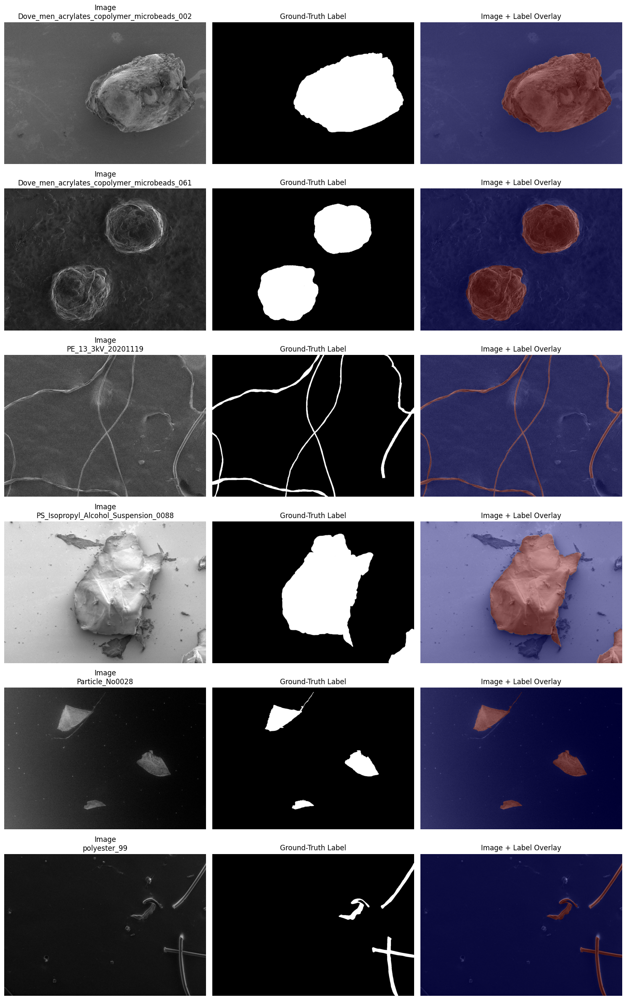


Diagnostic figure saved:
/kaggle/working/microplastic_project/figures/ground_truth_visual_analysis.png

CELL 9 COMPLETED
Dataset files were not modified.


In [6]:
# ============================================================
# CELL 9 — GROUND-TRUTH VISUALIZATION & PIXEL ANALYSIS
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

print("=" * 78)
print("MICROPLASTICS_SEM — GROUND-TRUTH VISUAL ANALYSIS")
print("=" * 78)

# ------------------------------------------------------------
# 1. Dataset paths
# ------------------------------------------------------------

INPUT_ROOT = Path("/kaggle/input/datasets")

dataset_roots = list(
    INPUT_ROOT.glob(
        "*/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1"
    )
)

if not dataset_roots:
    raise FileNotFoundError(
        "Microplastics dataset root not found."
    )

DATASET_ROOT = dataset_roots[0]

IMAGE_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/image"
)

LABEL_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/label"
)

# ------------------------------------------------------------
# 2. Collect matched pairs
# ------------------------------------------------------------

image_files = {
    p.stem: p
    for p in IMAGE_DIR.iterdir()
    if p.is_file()
}

label_files = {
    p.stem: p
    for p in LABEL_DIR.iterdir()
    if p.is_file()
}

common_names = sorted(
    set(image_files) & set(label_files)
)

print(f"\nImage files       : {len(image_files)}")
print(f"Label files       : {len(label_files)}")
print(f"Matched pairs     : {len(common_names)}")

if len(common_names) == 0:
    raise RuntimeError("No matched image-label pairs found.")

# ------------------------------------------------------------
# 3. Global label statistics
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("GLOBAL LABEL PIXEL ANALYSIS")
print("=" * 78)

global_counts = {}
sample_names = common_names[:10]

for stem in common_names:

    label = np.array(
        Image.open(label_files[stem])
    )

    values, counts = np.unique(
        label,
        return_counts=True
    )

    for value, count in zip(values, counts):

        value = int(value)

        if value not in global_counts:
            global_counts[value] = 0

        global_counts[value] += int(count)

print(f"\nTotal unique label pixel values: {len(global_counts)}")

print("\nTop label values by pixel frequency:")

for value, count in sorted(
    global_counts.items(),
    key=lambda x: x[1],
    reverse=True
)[:30]:

    print(
        f"  value={value:3d} | "
        f"pixels={count:,}"
    )

# ------------------------------------------------------------
# 4. Image-level foreground analysis
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("IMAGE-LEVEL FOREGROUND ANALYSIS")
print("=" * 78)

image_stats = []

for stem in common_names:

    image = np.array(
        Image.open(image_files[stem])
    )

    label = np.array(
        Image.open(label_files[stem])
    )

    unique_values = np.unique(label)

    # Treat zero as background for this diagnostic only.
    foreground_pixels = np.count_nonzero(label > 0)

    total_pixels = label.size

    foreground_ratio = (
        foreground_pixels / total_pixels
    )

    image_stats.append({
        "name": stem,
        "height": label.shape[0],
        "width": label.shape[1],
        "unique_values": len(unique_values),
        "foreground_pixels": foreground_pixels,
        "foreground_ratio": foreground_ratio
    })

foreground_ratios = np.array([
    x["foreground_ratio"]
    for x in image_stats
])

print(
    f"\nForeground ratio "
    f"(label > 0):"
)

print(
    f"  Minimum : {foreground_ratios.min():.6f}"
)

print(
    f"  Maximum : {foreground_ratios.max():.6f}"
)

print(
    f"  Mean    : {foreground_ratios.mean():.6f}"
)

print(
    f"  Median  : {np.median(foreground_ratios):.6f}"
)

# ------------------------------------------------------------
# 5. Display representative samples
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("DISPLAYING REPRESENTATIVE IMAGE / LABEL PAIRS")
print("=" * 78)

# Select samples across the dataset
indices = np.linspace(
    0,
    len(common_names) - 1,
    min(6, len(common_names)),
    dtype=int
)

selected_names = [
    common_names[i]
    for i in indices
]

fig, axes = plt.subplots(
    len(selected_names),
    3,
    figsize=(15, 4 * len(selected_names))
)

if len(selected_names) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, stem in enumerate(selected_names):

    image = np.array(
        Image.open(image_files[stem])
    )

    label = np.array(
        Image.open(label_files[stem])
    )

    # Convert RGBA/RGB to grayscale for visualization
    if image.ndim == 3:
        image_display = image[..., :3]

        if image_display.shape[-1] == 3:
            # Simple grayscale conversion
            image_display = (
                0.299 * image_display[..., 0] +
                0.587 * image_display[..., 1] +
                0.114 * image_display[..., 2]
            )
    else:
        image_display = image

    # Overlay: normalize label for visualization only
    label_float = label.astype(np.float32)

    if label_float.max() > label_float.min():
        label_norm = (
            (label_float - label_float.min()) /
            (label_float.max() - label_float.min())
        )
    else:
        label_norm = label_float

    axes[row, 0].imshow(
        image_display,
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"Image\n{stem}"
    )

    axes[row, 0].axis("off")

    axes[row, 1].imshow(
        label,
        cmap="gray"
    )

    axes[row, 1].set_title(
        "Ground-Truth Label"
    )

    axes[row, 1].axis("off")

    axes[row, 2].imshow(
        image_display,
        cmap="gray"
    )

    axes[row, 2].imshow(
        label_norm,
        cmap="jet",
        alpha=0.40
    )

    axes[row, 2].set_title(
        "Image + Label Overlay"
    )

    axes[row, 2].axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Save diagnostic figure
# ------------------------------------------------------------

FIGURE_DIR = Path(
    "/kaggle/working/microplastic_project/figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

figure_path = (
    FIGURE_DIR /
    "ground_truth_visual_analysis.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

print("\nDiagnostic figure saved:")
print(figure_path)

print("\n" + "=" * 78)
print("CELL 9 COMPLETED")
print("Dataset files were not modified.")
print("=" * 78)

**Decode the Label Representation**

In [8]:
# ============================================================
# CELL 10 — DECODE DATASET1 LABEL REPRESENTATION
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
from collections import Counter

print("=" * 78)
print("MICROPLASTICS_SEM — LABEL ENCODING ANALYSIS")
print("=" * 78)

# ------------------------------------------------------------
# Dataset paths
# ------------------------------------------------------------

INPUT_ROOT = Path("/kaggle/input/datasets")

dataset_roots = list(
    INPUT_ROOT.glob(
        "*/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1"
    )
)

if not dataset_roots:
    raise FileNotFoundError("Dataset root not found.")

DATASET_ROOT = dataset_roots[0]

LABEL_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/label"
)

IMAGE_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/image"
)

# ------------------------------------------------------------
# 1. Analyze every label image
# ------------------------------------------------------------

label_files = sorted(
    [p for p in LABEL_DIR.iterdir() if p.is_file()]
)

print(f"\nLabel images: {len(label_files)}")

global_value_counts = Counter()

per_image_stats = []

for label_path in label_files:

    arr = np.array(
        Image.open(label_path)
    )

    values, counts = np.unique(
        arr,
        return_counts=True
    )

    global_value_counts.update(
        {
            int(v): int(c)
            for v, c in zip(values, counts)
        }
    )

    nonzero = arr > 0

    per_image_stats.append({
        "name": label_path.stem,
        "unique_values": len(values),
        "min": int(arr.min()),
        "max": int(arr.max()),
        "zero_ratio": float(np.mean(arr == 0)),
        "nonzero_ratio": float(np.mean(nonzero)),
        "exact_255_ratio": float(np.mean(arr == 255)),
        "exact_1_ratio": float(np.mean(arr == 1)),
    })

# ------------------------------------------------------------
# 2. Exact global values
# ------------------------------------------------------------

all_values = sorted(global_value_counts.keys())

print("\n" + "-" * 78)
print("GLOBAL LABEL VALUE RANGE")
print("-" * 78)

print(f"Minimum value : {min(all_values)}")
print(f"Maximum value : {max(all_values)}")
print(f"Unique values : {len(all_values)}")

print("\nAll unique values:")
print(all_values)

# ------------------------------------------------------------
# 3. Most common values
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("MOST COMMON LABEL VALUES")
print("-" * 78)

total_pixels = sum(global_value_counts.values())

for value, count in global_value_counts.most_common(40):

    percentage = (
        100.0 * count / total_pixels
    )

    print(
        f"value={value:3d} | "
        f"pixels={count:12,d} | "
        f"{percentage:8.4f}%"
    )

# ------------------------------------------------------------
# 4. Investigate whether values are mostly binary
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("BINARY / MULTI-VALUE DIAGNOSTIC")
print("-" * 78)

binary_images = 0
two_value_images = 0
multi_value_images = 0

for stats in per_image_stats:

    if stats["unique_values"] == 2:
        two_value_images += 1

        # Check whether values could be {0,255}
        # or another binary encoding
        if (
            stats["min"] == 0 and
            stats["max"] == 255
        ):
            binary_images += 1

    elif stats["unique_values"] > 2:
        multi_value_images += 1

print(f"Exactly 2 unique values : {two_value_images}")
print(f"Binary-looking (0/255)  : {binary_images}")
print(f">2 unique values        : {multi_value_images}")

# ------------------------------------------------------------
# 5. Identify common intermediate values
# ------------------------------------------------------------

intermediate_values = [
    value for value in all_values
    if value not in {0, 1, 254, 255}
]

print("\n" + "-" * 78)
print("INTERMEDIATE GRAYSCALE VALUES")
print("-" * 78)

print(
    f"Number of intermediate values: "
    f"{len(intermediate_values)}"
)

print(
    intermediate_values
)

# ------------------------------------------------------------
# 6. Check whether intermediate values occur
#    mainly at boundaries
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("BOUNDARY / INTERIOR DIAGNOSTIC")
print("-" * 78)

sample_count = min(20, len(label_files))

boundary_like_ratios = []

for label_path in label_files[:sample_count]:

    arr = np.array(
        Image.open(label_path)
    )

    # Intermediate grayscale pixels
    intermediate = (
        (arr > 1) &
        (arr < 254)
    )

    nonzero = arr > 0

    if np.sum(nonzero) == 0:
        continue

    ratio = (
        np.sum(intermediate) /
        np.sum(nonzero)
    )

    boundary_like_ratios.append(
        float(ratio)
    )

if boundary_like_ratios:

    print(
        f"Samples analyzed : "
        f"{len(boundary_like_ratios)}"
    )

    print(
        f"Intermediate / nonzero ratio:"
    )

    print(
        f"  Minimum : "
        f"{min(boundary_like_ratios):.6f}"
    )

    print(
        f"  Maximum : "
        f"{max(boundary_like_ratios):.6f}"
    )

    print(
        f"  Mean    : "
        f"{np.mean(boundary_like_ratios):.6f}"
    )

# ------------------------------------------------------------
# 7. Print representative image statistics
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("REPRESENTATIVE LABEL FILES")
print("-" * 78)

for stats in per_image_stats[:15]:

    print(
        f"{stats['name']:<60} "
        f"unique={stats['unique_values']:3d} "
        f"min={stats['min']:3d} "
        f"max={stats['max']:3d} "
        f"zero={stats['zero_ratio']:.3f} "
        f"255={stats['exact_255_ratio']:.3f}"
    )

# ------------------------------------------------------------
# 8. IMPORTANT: check whether source result files exist
# ------------------------------------------------------------

RESULT_DIR = (
    DATASET_ROOT /
    "result/result/Exp1"
)

print("\n" + "-" * 78)
print("ORIGINAL RESULT DIRECTORY")
print("-" * 78)

print(f"Exists: {RESULT_DIR.exists()}")

if RESULT_DIR.exists():

    result_dirs = [
        p for p in RESULT_DIR.iterdir()
        if p.is_dir()
    ]

    for directory in result_dirs:
        print(
            f"  {directory.name} : "
            f"{len(list(directory.rglob('*')))} items"
        )

print("\n" + "=" * 78)
print("CELL 10 COMPLETED")
print("No dataset files were modified.")
print("=" * 78)


------------------------------------------------------------------------------
GLOBAL LABEL VALUE RANGE
------------------------------------------------------------------------------
Minimum value : 0
Maximum value : 255
Unique values : 238

All unique values:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 26, 28, 29, 30, 31, 32, 34, 35, 36, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 55, 56, 58, 59, 60, 62, 63, 64, 65, 67, 68, 69, 70, 71, 72, 73, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 99, 101, 102, 103, 104, 105, 106, 107, 109, 110, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124, 125, 126, 127, 128, 129, 130, 131, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 18

**Label Encoding Visualization**

MICROPLASTICS_SEM — LABEL PIXEL ENCODING VISUALIZATION

Total image-label pairs: 237
Selected samples: [0, 1, 2, 10, 20]

------------------------------------------------------------------------------
Sample: Dove_men_acrylates_copolymer_microbeads_002.png
------------------------------------------------------------------------------
Image shape : (900, 1280)
Label shape : (900, 1280)
Unique label values : 199
255 pixels : 247,473
1 pixels : 319
Intermediate pixels : 2,384
All nonzero pixels : 250,579


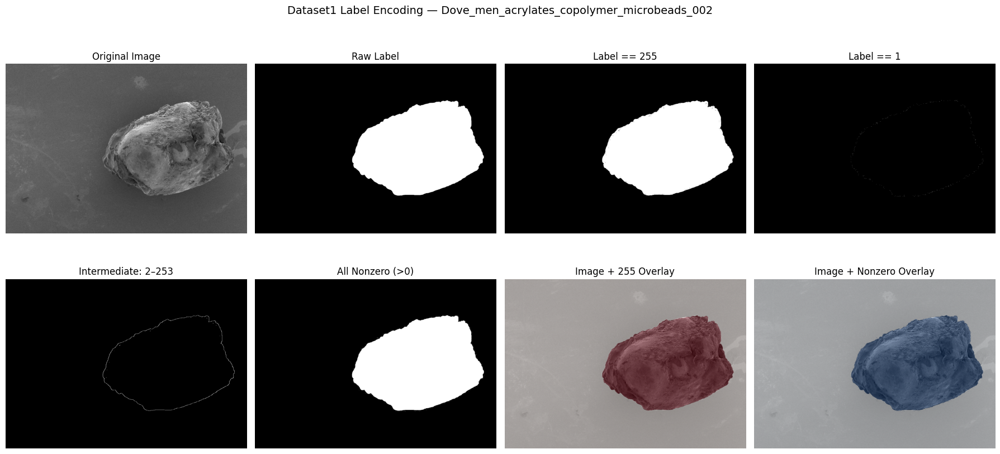


------------------------------------------------------------------------------
Sample: Dove_men_acrylates_copolymer_microbeads_003.png
------------------------------------------------------------------------------
Image shape : (900, 1280)
Label shape : (900, 1280)
Unique label values : 218
255 pixels : 122,540
1 pixels : 322
Intermediate pixels : 2,499
All nonzero pixels : 125,759


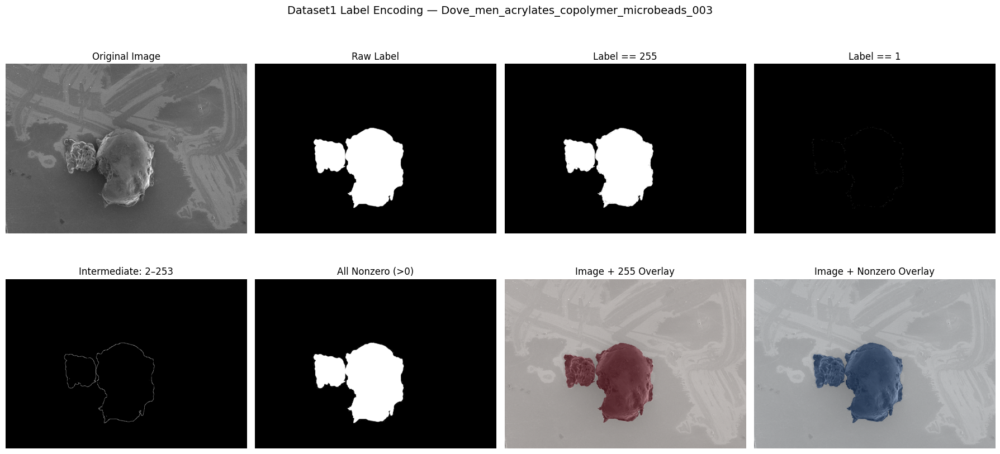


------------------------------------------------------------------------------
Sample: Dove_men_acrylates_copolymer_microbeads_004.png
------------------------------------------------------------------------------
Image shape : (900, 1280)
Label shape : (900, 1280)
Unique label values : 212
255 pixels : 196,084
1 pixels : 341
Intermediate pixels : 2,799
All nonzero pixels : 199,660


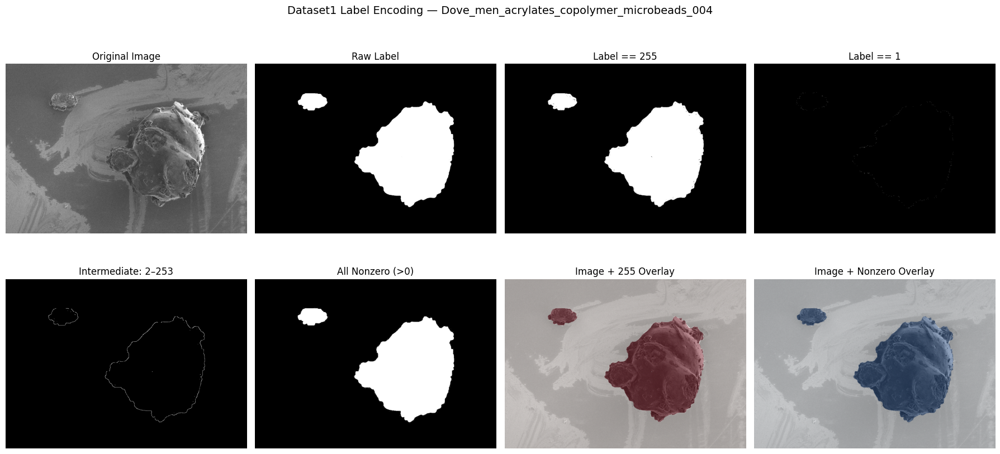


------------------------------------------------------------------------------
Sample: Dove_men_acrylates_copolymer_microbeads_018.png
------------------------------------------------------------------------------
Image shape : (900, 1280)
Label shape : (900, 1280)
Unique label values : 2
255 pixels : 205,528
1 pixels : 0
Intermediate pixels : 0
All nonzero pixels : 205,528


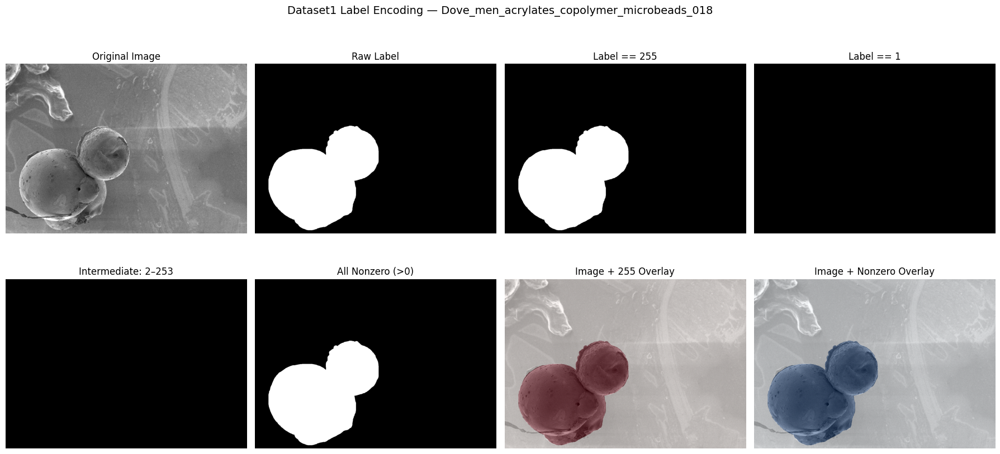


------------------------------------------------------------------------------
Sample: Dove_men_acrylates_copolymer_microbeads_031.png
------------------------------------------------------------------------------
Image shape : (900, 1280)
Label shape : (900, 1280)
Unique label values : 2
255 pixels : 270,565
1 pixels : 0
Intermediate pixels : 0
All nonzero pixels : 270,565


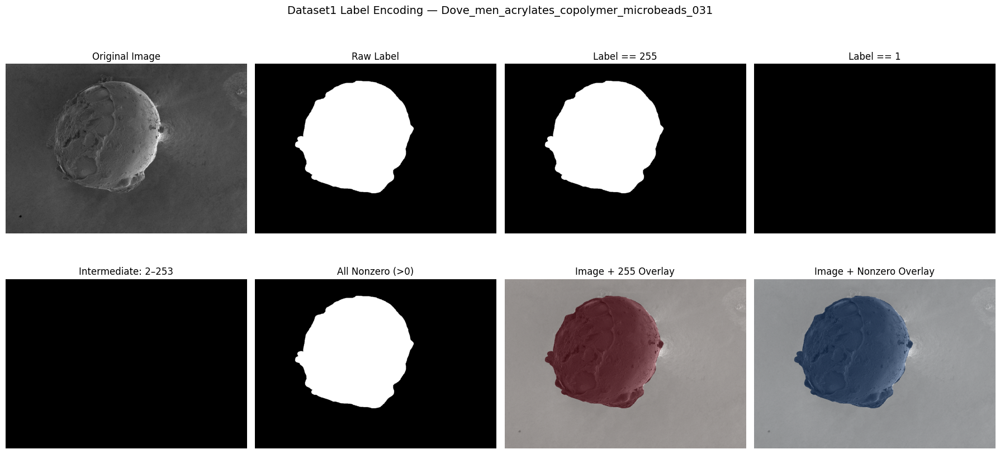


CELL 11 COMPLETED
No dataset files were modified.


In [9]:
# ============================================================
# CELL 11 — VISUALIZE LABEL PIXEL ENCODING
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

print("=" * 78)
print("MICROPLASTICS_SEM — LABEL PIXEL ENCODING VISUALIZATION")
print("=" * 78)

# ------------------------------------------------------------
# 1. Locate dataset
# ------------------------------------------------------------

INPUT_ROOT = Path("/kaggle/input/datasets")

dataset_roots = list(
    INPUT_ROOT.glob(
        "*/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1"
    )
)

if not dataset_roots:
    raise FileNotFoundError("Dataset root not found.")

DATASET_ROOT = dataset_roots[0]

IMAGE_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/image"
)

LABEL_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/label"
)

image_files = sorted(
    [p for p in IMAGE_DIR.iterdir() if p.is_file()]
)

label_files = sorted(
    [p for p in LABEL_DIR.iterdir() if p.is_file()]
)

# ------------------------------------------------------------
# 2. Select representative samples
# ------------------------------------------------------------

selected_indices = [0, 1, 2, 10, 20]

print(f"\nTotal image-label pairs: {len(image_files)}")
print(f"Selected samples: {selected_indices}")

# ------------------------------------------------------------
# 3. Visualize each sample
# ------------------------------------------------------------

for idx in selected_indices:

    image_path = image_files[idx]
    label_path = LABEL_DIR / image_path.name

    if not label_path.exists():
        print(
            f"\nWARNING: Missing label for {image_path.name}"
        )
        continue

    image = np.array(
        Image.open(image_path)
    )

    label = np.array(
        Image.open(label_path)
    )

    mask_255 = (label == 255)
    mask_1 = (label == 1)
    mask_intermediate = (
        (label > 1) &
        (label < 254)
    )
    mask_nonzero = (
        label > 0
    )

    print("\n" + "-" * 78)
    print(f"Sample: {image_path.name}")
    print("-" * 78)

    print(f"Image shape : {image.shape}")
    print(f"Label shape : {label.shape}")

    print(
        f"Unique label values : "
        f"{len(np.unique(label))}"
    )

    print(
        f"255 pixels : "
        f"{np.sum(mask_255):,}"
    )

    print(
        f"1 pixels : "
        f"{np.sum(mask_1):,}"
    )

    print(
        f"Intermediate pixels : "
        f"{np.sum(mask_intermediate):,}"
    )

    print(
        f"All nonzero pixels : "
        f"{np.sum(mask_nonzero):,}"
    )

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(18, 9)
    )

    # Original image
    if image.ndim == 2:
        axes[0, 0].imshow(
            image,
            cmap="gray"
        )
    else:
        axes[0, 0].imshow(image)

    axes[0, 0].set_title("Original Image")

    # Raw label
    axes[0, 1].imshow(
        label,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[0, 1].set_title("Raw Label")

    # Exact 255
    axes[0, 2].imshow(
        mask_255,
        cmap="gray"
    )

    axes[0, 2].set_title("Label == 255")

    # Exact 1
    axes[0, 3].imshow(
        mask_1,
        cmap="gray"
    )

    axes[0, 3].set_title("Label == 1")

    # Intermediate
    axes[1, 0].imshow(
        mask_intermediate,
        cmap="gray"
    )

    axes[1, 0].set_title(
        "Intermediate: 2–253"
    )

    # Nonzero
    axes[1, 1].imshow(
        mask_nonzero,
        cmap="gray"
    )

    axes[1, 1].set_title(
        "All Nonzero (>0)"
    )

    # Overlay 255 on image
    axes[1, 2].imshow(
        image,
        cmap="gray"
        if image.ndim == 2
        else None
    )

    axes[1, 2].imshow(
        mask_255,
        alpha=0.45,
        cmap="Reds"
    )

    axes[1, 2].set_title(
        "Image + 255 Overlay"
    )

    # Overlay all nonzero
    axes[1, 3].imshow(
        image,
        cmap="gray"
        if image.ndim == 2
        else None
    )

    axes[1, 3].imshow(
        mask_nonzero,
        alpha=0.45,
        cmap="Blues"
    )

    axes[1, 3].set_title(
        "Image + Nonzero Overlay"
    )

    for ax in axes.flat:
        ax.axis("off")

    plt.suptitle(
        f"Dataset1 Label Encoding — {image_path.stem}",
        fontsize=14
    )

    plt.tight_layout()

    plt.show()

print("\n" + "=" * 78)
print("CELL 11 COMPLETED")
print("No dataset files were modified.")
print("=" * 78)

**Validate the Ground-Truth Encoding**

In [10]:
# ============================================================
# CELL 12 — VALIDATE GROUND-TRUTH MASK ENCODING
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

print("=" * 78)
print("MICROPLASTICS_SEM — GROUND-TRUTH ENCODING VALIDATION")
print("=" * 78)

# ------------------------------------------------------------
# 1. Locate dataset
# ------------------------------------------------------------

INPUT_ROOT = Path("/kaggle/input/datasets")

dataset_roots = list(
    INPUT_ROOT.glob(
        "*/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1"
    )
)

if not dataset_roots:
    raise FileNotFoundError("Dataset root not found.")

DATASET_ROOT = dataset_roots[0]

IMAGE_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/image"
)

LABEL_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/label"
)

label_files = sorted(
    [p for p in LABEL_DIR.iterdir() if p.is_file()]
)

# ------------------------------------------------------------
# 2. Analyze every label
# ------------------------------------------------------------

records = []

total_pixels = 0
total_255 = 0
total_1 = 0
total_intermediate = 0
total_nonzero = 0
total_difference = 0

dice_values = []

for label_path in label_files:

    label = np.array(
        Image.open(label_path)
    )

    mask_255 = (
        label == 255
    )

    mask_nonzero = (
        label > 0
    )

    mask_1 = (
        label == 1
    )

    mask_intermediate = (
        (label > 1) &
        (label < 254)
    )

    total = label.size

    pixels_255 = int(
        np.sum(mask_255)
    )

    pixels_1 = int(
        np.sum(mask_1)
    )

    pixels_intermediate = int(
        np.sum(mask_intermediate)
    )

    pixels_nonzero = int(
        np.sum(mask_nonzero)
    )

    difference = int(
        np.sum(mask_nonzero != mask_255)
    )

    intersection = np.sum(
        mask_255 & mask_nonzero
    )

    denominator = (
        np.sum(mask_255) +
        np.sum(mask_nonzero)
    )

    if denominator > 0:
        dice = (
            2.0 * intersection /
            denominator
        )
    else:
        dice = 1.0

    total_pixels += total
    total_255 += pixels_255
    total_1 += pixels_1
    total_intermediate += pixels_intermediate
    total_nonzero += pixels_nonzero
    total_difference += difference

    dice_values.append(dice)

    records.append({
        "file": label_path.name,
        "pixels": total,
        "255_pixels": pixels_255,
        "1_pixels": pixels_1,
        "intermediate_pixels": pixels_intermediate,
        "nonzero_pixels": pixels_nonzero,
        "difference_pixels": difference,
        "difference_ratio": difference / total,
        "dice_255_vs_nonzero": dice,
    })

df_validation = pd.DataFrame(records)

# ------------------------------------------------------------
# 3. Global comparison
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("GLOBAL MASK COMPARISON")
print("-" * 78)

print(
    f"Images analyzed              : "
    f"{len(label_files)}"
)

print(
    f"Total pixels                 : "
    f"{total_pixels:,}"
)

print(
    f"Exact 255 pixels             : "
    f"{total_255:,}"
)

print(
    f"Value-1 pixels               : "
    f"{total_1:,}"
)

print(
    f"Intermediate pixels (2-253)  : "
    f"{total_intermediate:,}"
)

print(
    f"All nonzero pixels           : "
    f"{total_nonzero:,}"
)

print(
    f"Pixels where masks differ    : "
    f"{total_difference:,}"
)

print(
    f"Global difference ratio      : "
    f"{total_difference / total_pixels:.8f}"
)

print(
    f"Mean Dice (255 vs >0)        : "
    f"{np.mean(dice_values):.8f}"
)

print(
    f"Minimum Dice                 : "
    f"{np.min(dice_values):.8f}"
)

# ------------------------------------------------------------
# 4. Per-image difference analysis
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("PER-IMAGE DIFFERENCE ANALYSIS")
print("-" * 78)

print(
    f"Images with zero difference  : "
    f"{np.sum(df_validation['difference_pixels'] == 0)}"
)

print(
    f"Images with differences      : "
    f"{np.sum(df_validation['difference_pixels'] > 0)}"
)

print(
    f"Maximum difference pixels    : "
    f"{df_validation['difference_pixels'].max():,}"
)

print(
    f"Maximum difference ratio     : "
    f"{df_validation['difference_ratio'].max():.8f}"
)

# ------------------------------------------------------------
# 5. Largest differences
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("TOP 15 IMAGES BY MASK DIFFERENCE")
print("-" * 78)

top_difference = (
    df_validation
    .sort_values(
        "difference_pixels",
        ascending=False
    )
    .head(15)
)

print(
    top_difference[
        [
            "file",
            "255_pixels",
            "1_pixels",
            "intermediate_pixels",
            "difference_pixels",
            "difference_ratio",
            "dice_255_vs_nonzero"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 6. Check whether nonzero expansion is caused by value 1
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("NONZERO EXPANSION BREAKDOWN")
print("-" * 78)

extra_pixels = (
    mask_nonzero &
    (~mask_255)
)

print(
    "Note: the variables above refer to the final label "
    "processed in the loop."
)

print(
    f"Global extra pixels beyond 255:"
    f" {total_nonzero - total_255:,}"
)

print(
    f"Global value-1 pixels:"
    f" {total_1:,}"
)

print(
    f"Global intermediate pixels:"
    f" {total_intermediate:,}"
)

# ------------------------------------------------------------
# 7. Save analysis table
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    "/kaggle/working/microplastic_project/results"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

output_file = (
    OUTPUT_DIR /
    "ground_truth_encoding_validation.csv"
)

df_validation.to_csv(
    output_file,
    index=False
)

print("\nSaved validation table:")
print(output_file)

print("\n" + "=" * 78)
print("CELL 12 COMPLETED")
print("No original dataset files were modified.")
print("=" * 78)

MICROPLASTICS_SEM — GROUND-TRUTH ENCODING VALIDATION

------------------------------------------------------------------------------
GLOBAL MASK COMPARISON
------------------------------------------------------------------------------
Images analyzed              : 237
Total pixels                 : 498,044,908
Exact 255 pixels             : 58,839,492
Value-1 pixels               : 16,497,859
Intermediate pixels (2-253)  : 317,672
All nonzero pixels           : 75,703,399
Pixels where masks differ    : 16,863,907
Global difference ratio      : 0.03386021
Mean Dice (255 vs >0)        : 0.64676407
Minimum Dice                 : 0.00000000

------------------------------------------------------------------------------
PER-IMAGE DIFFERENCE ANALYSIS
------------------------------------------------------------------------------
Images with zero difference  : 75
Images with differences      : 162
Maximum difference pixels    : 711,006
Maximum difference ratio     : 0.61588889

--------------

**Determine Foreground Encoding Patterns**

In [11]:
# ============================================================
# CELL 13 — DETERMINE FOREGROUND ENCODING PATTERNS
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
from collections import Counter

print("=" * 78)
print("MICROPLASTICS_SEM — FOREGROUND ENCODING PATTERN ANALYSIS")
print("=" * 78)

# ------------------------------------------------------------
# 1. Locate dataset
# ------------------------------------------------------------

INPUT_ROOT = Path("/kaggle/input/datasets")

dataset_roots = list(
    INPUT_ROOT.glob(
        "*/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1"
    )
)

if not dataset_roots:
    raise FileNotFoundError("Dataset root not found.")

DATASET_ROOT = dataset_roots[0]

LABEL_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/label"
)

label_files = sorted(
    [p for p in LABEL_DIR.iterdir() if p.is_file()]
)

# ------------------------------------------------------------
# 2. Analyze each label
# ------------------------------------------------------------

records = []

for label_path in label_files:

    label = np.array(
        Image.open(label_path)
    )

    unique_values = set(
        np.unique(label).tolist()
    )

    has_255 = 255 in unique_values
    has_1 = 1 in unique_values

    intermediate_values = [
        v for v in unique_values
        if 1 < v < 255
    ]

    has_intermediate = (
        len(intermediate_values) > 0
    )

    pixels_255 = int(
        np.sum(label == 255)
    )

    pixels_1 = int(
        np.sum(label == 1)
    )

    pixels_intermediate = int(
        np.sum(
            (label > 1) &
            (label < 255)
        )
    )

    pixels_nonzero = int(
        np.sum(label > 0)
    )

    # --------------------------------------------------------
    # Determine encoding pattern
    # --------------------------------------------------------

    if has_255 and not has_1 and not has_intermediate:

        pattern = "0/255"

    elif has_1 and not has_255 and not has_intermediate:

        pattern = "0/1"

    elif has_255 and not has_1 and has_intermediate:

        pattern = "0/255 + intermediate"

    elif has_1 and not has_255 and has_intermediate:

        pattern = "0/1 + intermediate"

    elif has_1 and has_255 and has_intermediate:

        pattern = "0/1/255 + intermediate"

    elif has_1 and has_255 and not has_intermediate:

        pattern = "0/1/255"

    elif has_intermediate and not has_1 and not has_255:

        pattern = "0/intermediate"

    elif has_intermediate:

        pattern = "0 + intermediate"

    else:

        pattern = "0 only"

    records.append({

        "file": label_path.name,

        "unique_values": len(unique_values),

        "has_1": has_1,

        "has_255": has_255,

        "has_intermediate": has_intermediate,

        "pixels_1": pixels_1,

        "pixels_255": pixels_255,

        "pixels_intermediate": pixels_intermediate,

        "pixels_nonzero": pixels_nonzero,

        "pattern": pattern,

    })

df_encoding = pd.DataFrame(records)

# ------------------------------------------------------------
# 3. Pattern frequency
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("ENCODING PATTERN FREQUENCY")
print("-" * 78)

pattern_counts = (
    df_encoding["pattern"]
    .value_counts()
)

for pattern, count in pattern_counts.items():

    print(
        f"{pattern:<30} : {count:3d} images"
    )

# ------------------------------------------------------------
# 4. Basic foreground statistics
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("FOREGROUND PIXEL STATISTICS")
print("-" * 78)

print(
    f"Images containing value 255 : "
    f"{df_encoding['has_255'].sum()}"
)

print(
    f"Images containing value 1   : "
    f"{df_encoding['has_1'].sum()}"
)

print(
    f"Images containing intermediate values : "
    f"{df_encoding['has_intermediate'].sum()}"
)

# ------------------------------------------------------------
# 5. Images using value 1 as the main foreground
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("IMAGES WHERE VALUE 1 IS PRESENT")
print("-" * 78)

value1_df = (
    df_encoding[
        df_encoding["has_1"]
    ]
    .sort_values(
        "pixels_1",
        ascending=False
    )
)

print(
    value1_df[
        [
            "file",
            "unique_values",
            "pixels_1",
            "pixels_255",
            "pixels_intermediate",
            "pixels_nonzero",
            "pattern"
        ]
    ]
    .head(30)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 6. Images where 255 is absent but 1 is present
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("255 ABSENT / VALUE 1 PRESENT")
print("-" * 78)

one_without_255 = df_encoding[
    (df_encoding["has_1"]) &
    (~df_encoding["has_255"])
]

print(
    f"Number of images: "
    f"{len(one_without_255)}"
)

print(
    one_without_255[
        [
            "file",
            "pixels_1",
            "pixels_intermediate",
            "pixels_nonzero",
            "pattern"
        ]
    ]
    .sort_values(
        "pixels_1",
        ascending=False
    )
    .head(30)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 7. Images where both 1 and 255 occur
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("VALUE 1 AND 255 BOTH PRESENT")
print("-" * 78)

both = df_encoding[
    (df_encoding["has_1"]) &
    (df_encoding["has_255"])
]

print(
    f"Number of images: "
    f"{len(both)}"
)

if len(both) > 0:

    print(
        both[
            [
                "file",
                "pixels_1",
                "pixels_255",
                "pixels_intermediate",
                "pattern"
            ]
        ]
        .head(30)
        .to_string(index=False)
    )

# ------------------------------------------------------------
# 8. Intermediate pixel importance
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("INTERMEDIATE PIXEL ANALYSIS")
print("-" * 78)

total_intermediate = (
    df_encoding[
        "pixels_intermediate"
    ].sum()
)

total_nonzero = (
    df_encoding[
        "pixels_nonzero"
    ].sum()
)

print(
    f"Total intermediate pixels : "
    f"{total_intermediate:,}"
)

print(
    f"Total nonzero pixels      : "
    f"{total_nonzero:,}"
)

if total_nonzero > 0:

    print(
        f"Intermediate / nonzero   : "
        f"{total_intermediate / total_nonzero:.8f}"
    )

# ------------------------------------------------------------
# 9. Save encoding analysis
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    "/kaggle/working/microplastic_project/results"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

output_file = (
    OUTPUT_DIR /
    "label_encoding_patterns.csv"
)

df_encoding.to_csv(
    output_file,
    index=False
)

print("\nSaved analysis:")
print(output_file)

print("\n" + "=" * 78)
print("CELL 13 COMPLETED")
print("No original dataset files were modified.")
print("=" * 78)

MICROPLASTICS_SEM — FOREGROUND ENCODING PATTERN ANALYSIS

------------------------------------------------------------------------------
ENCODING PATTERN FREQUENCY
------------------------------------------------------------------------------
0/1                            :  83 images
0/255                          :  75 images
0/1/255 + intermediate         :  57 images
0/255 + intermediate           :  22 images

------------------------------------------------------------------------------
FOREGROUND PIXEL STATISTICS
------------------------------------------------------------------------------
Images containing value 255 : 154
Images containing value 1   : 140
Images containing intermediate values : 79

------------------------------------------------------------------------------
IMAGES WHERE VALUE 1 IS PRESENT
------------------------------------------------------------------------------
                   file  unique_values  pixels_1  pixels_255  pixels_intermediate  pixels_no

**Spatial Relationship of Label Values**

In [15]:
# ============================================================
# CELL 14 — ROBUST LABEL CHANNEL + SPATIAL ENCODING ANALYSIS
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
from scipy import ndimage

print("=" * 78)
print("MICROPLASTICS_SEM — ROBUST LABEL ENCODING ANALYSIS")
print("=" * 78)

# ------------------------------------------------------------
# 1. Locate dataset
# ------------------------------------------------------------

INPUT_ROOT = Path("/kaggle/input/datasets")

dataset_roots = list(
    INPUT_ROOT.glob(
        "*/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1"
    )
)

if not dataset_roots:
    raise FileNotFoundError(
        "Dataset root not found."
    )

DATASET_ROOT = dataset_roots[0]

LABEL_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/label"
)

label_files = sorted(
    [
        p for p in LABEL_DIR.iterdir()
        if p.is_file()
    ]
)

print(f"\nLabels found: {len(label_files)}")


# ------------------------------------------------------------
# 2. Helper function
# ------------------------------------------------------------

def inspect_label_array(path):
    """
    Load a label and safely determine whether it can be
    represented as a single grayscale channel.

    Returns:
        label_2d
        original_shape
        channel_status
    """

    arr = np.array(
        Image.open(path)
    )

    original_shape = arr.shape

    # --------------------------------------------------------
    # Standard 2D grayscale label
    # --------------------------------------------------------

    if arr.ndim == 2:

        return (
            arr,
            original_shape,
            "2D_grayscale"
        )

    # --------------------------------------------------------
    # 3D label: RGB/RGBA/multi-channel
    # --------------------------------------------------------

    if arr.ndim == 3:

        h, w, c = arr.shape

        # ----------------------------------------------------
        # Check whether all channels are identical
        # ----------------------------------------------------

        reference = arr[:, :, 0]

        channels_identical = True

        for channel in range(1, c):

            if not np.array_equal(
                reference,
                arr[:, :, channel]
            ):

                channels_identical = False
                break

        # ----------------------------------------------------
        # If channels are identical, safely use one channel
        # ----------------------------------------------------

        if channels_identical:

            return (
                reference,
                original_shape,
                f"{c}D_channels_identical"
            )

        # ----------------------------------------------------
        # Channels differ.
        #
        # We do NOT silently choose a channel.
        # ----------------------------------------------------

        raise ValueError(
            f"Non-identical label channels detected: "
            f"{path.name} | shape={original_shape}"
        )

    # --------------------------------------------------------
    # Unsupported dimensionality
    # --------------------------------------------------------

    raise ValueError(
        f"Unsupported label dimensionality: "
        f"{path.name} | shape={original_shape}"
    )


# ------------------------------------------------------------
# 3. First inspect dimensionality of ALL labels
# ------------------------------------------------------------

shape_records = []

for label_path in label_files:

    arr = np.array(
        Image.open(label_path)
    )

    shape_records.append({

        "file":
            label_path.name,

        "shape":
            str(arr.shape),

        "ndim":
            arr.ndim,

        "height":
            arr.shape[0],

        "width":
            arr.shape[1],

        "channels":
            arr.shape[2]
            if arr.ndim == 3
            else 1
    })


df_shapes = pd.DataFrame(
    shape_records
)

print("\n" + "-" * 78)
print("LABEL DIMENSIONALITY")
print("-" * 78)

print(
    df_shapes[
        ["ndim", "channels"]
    ]
    .value_counts()
    .to_string()
)

# ------------------------------------------------------------
# 4. Analyze labels
# ------------------------------------------------------------

records = []

channel_warnings = []

for label_path in label_files:

    try:

        label, original_shape, channel_status = (
            inspect_label_array(label_path)
        )

    except ValueError as e:

        channel_warnings.append(
            str(e)
        )

        continue

    # --------------------------------------------------------
    # Basic label values
    # --------------------------------------------------------

    unique_values = np.unique(
        label
    )

    mask_255 = (
        label == 255
    )

    mask_1 = (
        label == 1
    )

    mask_intermediate = (
        (label > 1) &
        (label < 255)
    )

    mask_nonzero = (
        label > 0
    )

    # --------------------------------------------------------
    # Spatial analysis relative to 255
    # --------------------------------------------------------

    if np.any(mask_255):

        # Distance from every pixel to nearest 255 pixel
        distance_map = (
            ndimage.distance_transform_edt(
                ~mask_255
            )
        )

        distance_1 = (
            distance_map[
                mask_1
            ]
        )

        distance_intermediate = (
            distance_map[
                mask_intermediate
            ]
        )

        # ----------------------------------------------------
        # Value 1
        # ----------------------------------------------------

        if len(distance_1) > 0:

            mean_distance_1 = float(
                np.mean(distance_1)
            )

            max_distance_1 = float(
                np.max(distance_1)
            )

            fraction_1_near_2px = float(
                np.mean(
                    distance_1 <= 2
                )
            )

        else:

            mean_distance_1 = np.nan
            max_distance_1 = np.nan
            fraction_1_near_2px = np.nan

        # ----------------------------------------------------
        # Intermediate
        # ----------------------------------------------------

        if len(distance_intermediate) > 0:

            mean_distance_intermediate = float(
                np.mean(
                    distance_intermediate
                )
            )

            max_distance_intermediate = float(
                np.max(
                    distance_intermediate
                )
            )

            fraction_intermediate_near_2px = float(
                np.mean(
                    distance_intermediate <= 2
                )
            )

        else:

            mean_distance_intermediate = np.nan
            max_distance_intermediate = np.nan
            fraction_intermediate_near_2px = np.nan

    else:

        mean_distance_1 = np.nan
        max_distance_1 = np.nan
        fraction_1_near_2px = np.nan

        mean_distance_intermediate = np.nan
        max_distance_intermediate = np.nan
        fraction_intermediate_near_2px = np.nan

    # --------------------------------------------------------
    # Encoding pattern
    # --------------------------------------------------------

    values = set(
        unique_values.tolist()
    )

    has_1 = (
        1 in values
    )

    has_255 = (
        255 in values
    )

    has_intermediate = any(
        1 < v < 255
        for v in values
    )

    if (
        has_1
        and has_255
        and has_intermediate
    ):

        pattern = (
            "0/1/255 + intermediate"
        )

    elif (
        has_1
        and has_255
    ):

        pattern = (
            "0/1/255"
        )

    elif (
        has_1
        and has_intermediate
    ):

        pattern = (
            "0/1 + intermediate"
        )

    elif (
        has_255
        and has_intermediate
    ):

        pattern = (
            "0/255 + intermediate"
        )

    elif has_1:

        pattern = "0/1"

    elif has_255:

        pattern = "0/255"

    elif has_intermediate:

        pattern = "0/intermediate"

    else:

        pattern = "0 only"

    # --------------------------------------------------------
    # Save record
    # --------------------------------------------------------

    records.append({

        "file":
            label_path.name,

        "original_shape":
            str(original_shape),

        "channel_status":
            channel_status,

        "height":
            label.shape[0],

        "width":
            label.shape[1],

        "unique_values":
            len(unique_values),

        "pixels_1":
            int(
                np.sum(mask_1)
            ),

        "pixels_255":
            int(
                np.sum(mask_255)
            ),

        "pixels_intermediate":
            int(
                np.sum(mask_intermediate)
            ),

        "pixels_nonzero":
            int(
                np.sum(mask_nonzero)
            ),

        "mean_distance_1_to_255":
            mean_distance_1,

        "max_distance_1_to_255":
            max_distance_1,

        "fraction_value1_within_2px":
            fraction_1_near_2px,

        "mean_distance_intermediate_to_255":
            mean_distance_intermediate,

        "max_distance_intermediate_to_255":
            max_distance_intermediate,

        "fraction_intermediate_within_2px":
            fraction_intermediate_near_2px,

        "pattern":
            pattern
    })


# ------------------------------------------------------------
# 5. Report channel issues
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("CHANNEL VALIDATION")
print("-" * 78)

print(
    f"Labels successfully analyzed : "
    f"{len(records)}"
)

print(
    f"Labels requiring inspection   : "
    f"{len(channel_warnings)}"
)

if channel_warnings:

    print("\nFirst channel warning:")

    print(
        channel_warnings[0]
    )


# ------------------------------------------------------------
# 6. DataFrame
# ------------------------------------------------------------

df_spatial = pd.DataFrame(
    records
)

# ------------------------------------------------------------
# 7. Encoding frequency
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("ENCODING PATTERN FREQUENCY")
print("-" * 78)

if len(df_spatial) > 0:

    print(
        df_spatial[
            "pattern"
        ]
        .value_counts()
        .to_string()
    )

# ------------------------------------------------------------
# 8. Value-1 analysis
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("VALUE-1 ANALYSIS")
print("-" * 78)

value1_images = df_spatial[
    df_spatial["pixels_1"] > 0
]

print(
    f"Images containing value 1 : "
    f"{len(value1_images)}"
)

print(
    f"Total value-1 pixels      : "
    f"{value1_images['pixels_1'].sum():,}"
)

value1_with_255 = value1_images[
    value1_images["pixels_255"] > 0
]

value1_without_255 = value1_images[
    value1_images["pixels_255"] == 0
]

print(
    f"Value-1 images with 255    : "
    f"{len(value1_with_255)}"
)

print(
    f"Value-1 images without 255 : "
    f"{len(value1_without_255)}"
)

if len(value1_with_255) > 0:

    valid = (
        value1_with_255[
            "fraction_value1_within_2px"
        ]
        .dropna()
    )

    print(
        f"\nMean distance of value-1 "
        f"pixels to 255 : "
        f"{value1_with_255['mean_distance_1_to_255'].mean():.4f} px"
    )

    print(
        f"Maximum distance observed : "
        f"{value1_with_255['max_distance_1_to_255'].max():.4f} px"
    )

    if len(valid) > 0:

        print(
            f"Mean fraction of value-1 "
            f"pixels within 2 px of 255 : "
            f"{valid.mean():.6f}"
        )


# ------------------------------------------------------------
# 9. Intermediate analysis
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("INTERMEDIATE PIXEL ANALYSIS")
print("-" * 78)

intermediate_images = df_spatial[
    df_spatial["pixels_intermediate"] > 0
]

print(
    f"Images with intermediate pixels : "
    f"{len(intermediate_images)}"
)

print(
    f"Total intermediate pixels       : "
    f"{intermediate_images['pixels_intermediate'].sum():,}"
)

intermediate_with_255 = (
    intermediate_images[
        intermediate_images["pixels_255"] > 0
    ]
)

if len(intermediate_with_255) > 0:

    valid = (
        intermediate_with_255[
            "fraction_intermediate_within_2px"
        ]
        .dropna()
    )

    print(
        f"Mean distance of intermediate "
        f"pixels to 255 : "
        f"{intermediate_with_255['mean_distance_intermediate_to_255'].mean():.4f} px"
    )

    print(
        f"Maximum distance observed : "
        f"{intermediate_with_255['max_distance_intermediate_to_255'].max():.4f} px"
    )

    if len(valid) > 0:

        print(
            f"Mean fraction of intermediate "
            f"pixels within 2 px of 255 : "
            f"{valid.mean():.6f}"
        )


# ------------------------------------------------------------
# 10. Save results
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    "/kaggle/working/microplastic_project/results"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

output_file = (
    OUTPUT_DIR /
    "label_spatial_encoding_analysis.csv"
)

df_spatial.to_csv(
    output_file,
    index=False
)

shape_file = (
    OUTPUT_DIR /
    "label_shape_analysis.csv"
)

df_shapes.to_csv(
    shape_file,
    index=False
)

print("\n" + "-" * 78)
print("OUTPUT FILES")
print("-" * 78)

print(
    output_file
)

print(
    shape_file
)

print("\n" + "=" * 78)
print("CELL 14 COMPLETED")
print("No original dataset files were modified.")
print("=" * 78)

MICROPLASTICS_SEM — ROBUST LABEL ENCODING ANALYSIS

Labels found: 237

------------------------------------------------------------------------------
LABEL DIMENSIONALITY
------------------------------------------------------------------------------
ndim  channels
2     1           230
3     4             7

------------------------------------------------------------------------------
CHANNEL VALIDATION
------------------------------------------------------------------------------
Labels successfully analyzed : 230
Labels requiring inspection   : 7

First channel warning:
Non-identical label channels detected: p12polyester_fibre.png | shape=(899, 1279, 4)

------------------------------------------------------------------------------
ENCODING PATTERN FREQUENCY
------------------------------------------------------------------------------
pattern
0/1                       83
0/255                     68
0/1/255 + intermediate    57
0/255 + intermediate      22

------------------------

**Inspect the 7 RGBA Labels**

In [16]:
# ============================================================
# CELL 15 — INSPECT RGBA LABEL FILES
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

print("=" * 78)
print("MICROPLASTICS_SEM — RGBA LABEL INSPECTION")
print("=" * 78)

INPUT_ROOT = Path("/kaggle/input/datasets")

dataset_roots = list(
    INPUT_ROOT.glob(
        "*/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1"
    )
)

if not dataset_roots:
    raise FileNotFoundError(
        "Dataset root not found."
    )

DATASET_ROOT = dataset_roots[0]

LABEL_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/label"
)

label_files = sorted(
    [
        p for p in LABEL_DIR.iterdir()
        if p.is_file()
    ]
)

# ------------------------------------------------------------
# Find all 4-channel labels
# ------------------------------------------------------------

rgba_files = []

for path in label_files:

    arr = np.array(
        Image.open(path)
    )

    if arr.ndim == 3 and arr.shape[2] == 4:

        rgba_files.append(path)

print(
    f"\nRGBA labels found: {len(rgba_files)}"
)

# ------------------------------------------------------------
# Inspect each channel independently
# ------------------------------------------------------------

for path in rgba_files:

    arr = np.array(
        Image.open(path)
    )

    print("\n" + "-" * 78)
    print(f"FILE: {path.name}")
    print("-" * 78)

    print(
        f"Shape: {arr.shape}"
    )

    for channel in range(4):

        channel_data = arr[:, :, channel]

        unique_values, counts = np.unique(
            channel_data,
            return_counts=True
        )

        print(
            f"\nChannel {channel}:"
        )

        print(
            f"  Min          : "
            f"{channel_data.min()}"
        )

        print(
            f"  Max          : "
            f"{channel_data.max()}"
        )

        print(
            f"  Unique values : "
            f"{len(unique_values)}"
        )

        # Print most common values

        order = np.argsort(
            counts
        )[::-1]

        print(
            "  Most common:"
        )

        for idx in order[:10]:

            print(
                f"    value={int(unique_values[idx]):3d} "
                f"pixels={int(counts[idx]):,}"
            )

    # --------------------------------------------------------
    # Channel equality tests
    # --------------------------------------------------------

    print("\nChannel equality:")

    for c1 in range(4):

        for c2 in range(c1 + 1, 4):

            identical = np.array_equal(
                arr[:, :, c1],
                arr[:, :, c2]
            )

            print(
                f"  Channel {c1} == "
                f"Channel {c2}: "
                f"{identical}"
            )

    # --------------------------------------------------------
    # Check whether alpha behaves like a mask
    # --------------------------------------------------------

    alpha = arr[:, :, 3]

    alpha_unique, alpha_counts = np.unique(
        alpha,
        return_counts=True
    )

    print("\nAlpha channel summary:")

    print(
        f"  Unique values: "
        f"{len(alpha_unique)}"
    )

    print(
        f"  Nonzero ratio: "
        f"{np.mean(alpha > 0):.6f}"
    )

    print(
        f"  255 ratio: "
        f"{np.mean(alpha == 255):.6f}"
    )

print("\n" + "=" * 78)
print("CELL 15 COMPLETED")
print("No dataset files were modified.")
print("=" * 78)

MICROPLASTICS_SEM — RGBA LABEL INSPECTION

RGBA labels found: 7

------------------------------------------------------------------------------
FILE: p12polyester_fibre.png
------------------------------------------------------------------------------
Shape: (899, 1279, 4)

Channel 0:
  Min          : 0
  Max          : 255
  Unique values : 2
  Most common:
    value=  0 pixels=905,079
    value=255 pixels=244,742

Channel 1:
  Min          : 0
  Max          : 255
  Unique values : 2
  Most common:
    value=  0 pixels=905,079
    value=255 pixels=244,742

Channel 2:
  Min          : 0
  Max          : 255
  Unique values : 2
  Most common:
    value=  0 pixels=905,079
    value=255 pixels=244,742

Channel 3:
  Min          : 255
  Max          : 255
  Unique values : 1
  Most common:
    value=255 pixels=1,149,821

Channel equality:
  Channel 0 == Channel 1: True
  Channel 0 == Channel 2: True
  Channel 0 == Channel 3: False
  Channel 1 == Channel 2: True
  Channel 1 == Channel 3: F

**Final Ground-Truth Decoder Validation**

In [17]:
# ============================================================
# CELL 16 — FINAL GROUND-TRUTH DECODER VALIDATION
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

print("=" * 78)
print("MICROPLASTICS_SEM — FINAL GROUND-TRUTH DECODER VALIDATION")
print("=" * 78)

# ------------------------------------------------------------
# 1. Locate dataset
# ------------------------------------------------------------

INPUT_ROOT = Path("/kaggle/input/datasets")

dataset_roots = list(
    INPUT_ROOT.glob(
        "*/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1"
    )
)

if not dataset_roots:
    raise FileNotFoundError(
        "Dataset root not found."
    )

DATASET_ROOT = dataset_roots[0]

IMAGE_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/image"
)

LABEL_DIR = (
    DATASET_ROOT /
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4/label"
)

image_files = sorted(
    [
        p for p in IMAGE_DIR.iterdir()
        if p.is_file()
    ]
)

label_files = sorted(
    [
        p for p in LABEL_DIR.iterdir()
        if p.is_file()
    ]
)

print(
    f"\nImages : {len(image_files)}"
)

print(
    f"Labels : {len(label_files)}"
)

# ------------------------------------------------------------
# 2. Robust label decoder
# ------------------------------------------------------------

def decode_binary_mask(label_path):
    """
    Convert a Dataset1 label into a canonical binary mask.

    Rules:
      - 2D labels: use directly
      - RGB/RGBA labels:
            use the first channel ONLY if all RGB channels
            are identical
      - Alpha channel is ignored
      - Any value > 0 becomes foreground
      - 0 remains background

    Returns:
      binary_mask, original_shape, encoding_type
    """

    arr = np.array(
        Image.open(label_path)
    )

    original_shape = arr.shape

    # --------------------------------------------------------
    # 2D grayscale label
    # --------------------------------------------------------

    if arr.ndim == 2:

        mask_source = arr

        encoding_type = "2D"

    # --------------------------------------------------------
    # RGB/RGBA label
    # --------------------------------------------------------

    elif arr.ndim == 3:

        channels = arr.shape[2]

        if channels < 3:

            raise ValueError(
                f"Unexpected channel count for "
                f"{label_path.name}: "
                f"{arr.shape}"
            )

        # Compare RGB channels
        rgb_equal = (
            np.array_equal(
                arr[:, :, 0],
                arr[:, :, 1]
            )
            and
            np.array_equal(
                arr[:, :, 0],
                arr[:, :, 2]
            )
        )

        if not rgb_equal:

            raise ValueError(
                f"RGB channels are not identical for "
                f"{label_path.name}: "
                f"{arr.shape}"
            )

        mask_source = arr[:, :, 0]

        encoding_type = (
            f"RGB{channels}_identical_RGB"
        )

    else:

        raise ValueError(
            f"Unsupported label shape for "
            f"{label_path.name}: "
            f"{arr.shape}"
        )

    # --------------------------------------------------------
    # Canonical binary mask
    # --------------------------------------------------------

    binary_mask = (
        mask_source > 0
    ).astype(
        np.uint8
    )

    return (
        binary_mask,
        original_shape,
        encoding_type
    )


# ------------------------------------------------------------
# 3. Decode all labels
# ------------------------------------------------------------

records = []

failed_files = []

for label_path in label_files:

    try:

        mask, original_shape, encoding_type = (
            decode_binary_mask(
                label_path
            )
        )

        total_pixels = mask.size

        foreground_pixels = int(
            np.sum(mask)
        )

        background_pixels = (
            total_pixels -
            foreground_pixels
        )

        foreground_ratio = (
            foreground_pixels /
            total_pixels
        )

        records.append({

            "file":
                label_path.name,

            "original_shape":
                str(original_shape),

            "encoding_type":
                encoding_type,

            "height":
                mask.shape[0],

            "width":
                mask.shape[1],

            "foreground_pixels":
                foreground_pixels,

            "background_pixels":
                background_pixels,

            "foreground_ratio":
                foreground_ratio,

            "empty_mask":
                foreground_pixels == 0
        })

    except Exception as e:

        failed_files.append(
            (
                label_path.name,
                str(e)
            )
        )


df_decoder = pd.DataFrame(
    records
)

# ------------------------------------------------------------
# 4. Decoder success
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("DECODER SUCCESS")
print("-" * 78)

print(
    f"Successfully decoded : "
    f"{len(df_decoder)} / {len(label_files)}"
)

print(
    f"Failed                : "
    f"{len(failed_files)}"
)

if failed_files:

    print("\nFailures:")

    for name, error in failed_files:

        print(
            f"{name}: {error}"
        )

# ------------------------------------------------------------
# 5. Encoding types
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("DECODER INPUT TYPES")
print("-" * 78)

print(
    df_decoder[
        "encoding_type"
    ]
    .value_counts()
    .to_string()
)

# ------------------------------------------------------------
# 6. Empty masks
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("EMPTY MASK CHECK")
print("-" * 78)

empty_count = int(
    df_decoder[
        "empty_mask"
    ].sum()
)

print(
    f"Empty masks : "
    f"{empty_count}"
)

# ------------------------------------------------------------
# 7. Foreground statistics
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("FOREGROUND RATIO STATISTICS")
print("-" * 78)

ratios = (
    df_decoder[
        "foreground_ratio"
    ]
)

print(
    f"Minimum : "
    f"{ratios.min():.6f}"
)

print(
    f"Maximum : "
    f"{ratios.max():.6f}"
)

print(
    f"Mean    : "
    f"{ratios.mean():.6f}"
)

print(
    f"Median  : "
    f"{ratios.median():.6f}"
)

print(
    f"Std     : "
    f"{ratios.std():.6f}"
)

# ------------------------------------------------------------
# 8. Percentile analysis
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("FOREGROUND RATIO PERCENTILES")
print("-" * 78)

for percentile in [
    1,
    5,
    10,
    25,
    50,
    75,
    90,
    95,
    99
]:

    value = np.percentile(
        ratios,
        percentile
    )

    print(
        f"{percentile:>2}th percentile : "
        f"{value:.6f}"
    )

# ------------------------------------------------------------
# 9. Sanity checks
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("SANITY CHECKS")
print("-" * 78)

all_binary = True

for label_path in label_files:

    mask, _, _ = (
        decode_binary_mask(
            label_path
        )
    )

    unique_mask_values = (
        np.unique(mask)
    )

    if not np.array_equal(
        unique_mask_values,
        np.array([0, 1])
    ):

        # A completely empty mask has only [0]
        if not np.array_equal(
            unique_mask_values,
            np.array([0])
        ):

            all_binary = False

print(
    f"All decoded masks are binary : "
    f"{all_binary}"
)

print(
    f"All masks contain foreground : "
    f"{empty_count == 0}"
)

# ------------------------------------------------------------
# 10. Save decoder validation
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    "/kaggle/working/microplastic_project/results"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

output_file = (
    OUTPUT_DIR /
    "final_ground_truth_decoder_validation.csv"
)

df_decoder.to_csv(
    output_file,
    index=False
)

print("\nSaved validation table:")
print(output_file)

print("\n" + "=" * 78)
print("CELL 16 COMPLETED")
print("No original dataset files were modified.")
print("=" * 78)

MICROPLASTICS_SEM — FINAL GROUND-TRUTH DECODER VALIDATION

Images : 237
Labels : 237

------------------------------------------------------------------------------
DECODER SUCCESS
------------------------------------------------------------------------------
Successfully decoded : 237 / 237
Failed                : 0

------------------------------------------------------------------------------
DECODER INPUT TYPES
------------------------------------------------------------------------------
encoding_type
2D                    230
RGB4_identical_RGB      7

------------------------------------------------------------------------------
EMPTY MASK CHECK
------------------------------------------------------------------------------
Empty masks : 0

------------------------------------------------------------------------------
FOREGROUND RATIO STATISTICS
------------------------------------------------------------------------------
Minimum : 0.008171
Maximum : 0.615889
Mean    : 0.148337


**Analyze filename/group structure**

In [20]:
# ============================================================
# CELL 17 — DATASET GROUP / FILENAME STRUCTURE ANALYSIS
# ============================================================

from pathlib import Path
from collections import Counter
import re
import pandas as pd

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
DATASET_ROOT = Path(
    "/kaggle/input/datasets/mahmudnadim/"
    "microplastics-sem-v1-semantic-segmentation/"
    "z6459vntbr-1"
)

IMAGE_DIR = (
    DATASET_ROOT /
    "dataset1" /
    "dataset1" /
    "[datasets_full]_Exp1_Exp4" /
    "image"
)

LABEL_DIR = (
    DATASET_ROOT /
    "dataset1" /
    "dataset1" /
    "[datasets_full]_Exp1_Exp4" /
    "label"
)

# ------------------------------------------------------------
# Collect matched pairs
# ------------------------------------------------------------
image_paths = sorted(IMAGE_DIR.glob("*.png"))
label_paths = sorted(LABEL_DIR.glob("*.png"))

image_names = {p.name for p in image_paths}
label_names = {p.name for p in label_paths}

matched_names = sorted(image_names & label_names)

print("=" * 75)
print("MICROPLASTICS_SEM — FILENAME / GROUP STRUCTURE ANALYSIS")
print("=" * 75)

print(f"\nImages found       : {len(image_paths)}")
print(f"Labels found       : {len(label_paths)}")
print(f"Matched pairs      : {len(matched_names)}")
print(f"Missing labels     : {len(image_names - label_names)}")
print(f"Missing images     : {len(label_names - image_names)}")

# ------------------------------------------------------------
# Filename inspection
# ------------------------------------------------------------
print("\n" + "-" * 75)
print("SAMPLE FILENAMES")
print("-" * 75)

for name in matched_names[:30]:
    print(name)

# ------------------------------------------------------------
# Token analysis
# ------------------------------------------------------------
token_counter = Counter()

for name in matched_names:
    stem = Path(name).stem.lower()

    # Split on common separators
    tokens = re.split(r"[_\-\s]+", stem)

    for token in tokens:
        if token:
            token_counter[token] += 1

print("\n" + "-" * 75)
print("MOST COMMON FILENAME TOKENS")
print("-" * 75)

for token, count in token_counter.most_common(40):
    print(f"{token:35s} : {count}")

# ------------------------------------------------------------
# Candidate material/group extraction
# ------------------------------------------------------------
# We intentionally inspect rather than assume a definitive
# grouping rule at this stage.
candidate_keywords = [
    "pp",
    "pe",
    "ps",
    "pan",
    "pet",
    "polyester",
    "polyethylene",
    "polypropylene",
    "polystyrene",
    "polyamide",
    "acrylate",
    "acrylates",
    "nylon",
    "fiber",
    "fibre",
    "microbead",
    "microbeads",
    "fragment",
    "foam"
]

keyword_counts = Counter()

for name in matched_names:
    stem = Path(name).stem.lower()

    for keyword in candidate_keywords:
        if keyword in stem:
            keyword_counts[keyword] += 1

print("\n" + "-" * 75)
print("CANDIDATE MATERIAL / OBJECT KEYWORDS")
print("-" * 75)

for keyword, count in keyword_counts.most_common():
    print(f"{keyword:35s} : {count}")

# ------------------------------------------------------------
# Save raw filename metadata
# ------------------------------------------------------------
metadata = pd.DataFrame({
    "filename": matched_names,
    "stem": [Path(x).stem for x in matched_names]
})

metadata["filename_length"] = metadata["filename"].str.len()

metadata_path = (
    Path("/kaggle/working/microplastic_project/results")
    / "dataset_filename_metadata.csv"
)

metadata.to_csv(metadata_path, index=False)

print("\n" + "-" * 75)
print("OUTPUT")
print("-" * 75)
print(f"Saved metadata : {metadata_path}")

print("\n" + "=" * 75)
print("CELL 17 COMPLETED")
print("=" * 75)

MICROPLASTICS_SEM — FILENAME / GROUP STRUCTURE ANALYSIS

Images found       : 237
Labels found       : 237
Matched pairs      : 237
Missing labels     : 0
Missing images     : 0

---------------------------------------------------------------------------
SAMPLE FILENAMES
---------------------------------------------------------------------------
Dove_men_acrylates_copolymer_microbeads_002.png
Dove_men_acrylates_copolymer_microbeads_003.png
Dove_men_acrylates_copolymer_microbeads_004.png
Dove_men_acrylates_copolymer_microbeads_006.png
Dove_men_acrylates_copolymer_microbeads_007.png
Dove_men_acrylates_copolymer_microbeads_008.png
Dove_men_acrylates_copolymer_microbeads_009.png
Dove_men_acrylates_copolymer_microbeads_012.png
Dove_men_acrylates_copolymer_microbeads_015.png
Dove_men_acrylates_copolymer_microbeads_016.png
Dove_men_acrylates_copolymer_microbeads_018.png
Dove_men_acrylates_copolymer_microbeads_019.png
Dove_men_acrylates_copolymer_microbeads_021.png
Dove_men_acrylates_copolymer

**Build candidate experimental groups**

In [21]:
# ============================================================
# CELL 18 — EXPERIMENTAL GROUP / MATERIAL STRUCTURE
# ============================================================

from pathlib import Path
from collections import Counter, defaultdict
import re
import pandas as pd

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
DATASET_ROOT = Path(
    "/kaggle/input/datasets/mahmudnadim/"
    "microplastics-sem-v1-semantic-segmentation/"
    "z6459vntbr-1"
)

IMAGE_DIR = (
    DATASET_ROOT /
    "dataset1" /
    "dataset1" /
    "[datasets_full]_Exp1_Exp4" /
    "image"
)

LABEL_DIR = (
    DATASET_ROOT /
    "dataset1" /
    "dataset1" /
    "[datasets_full]_Exp1_Exp4" /
    "label"
)

image_paths = sorted(IMAGE_DIR.glob("*.png"))

# ------------------------------------------------------------
# Helper: remove numeric/index suffixes
# ------------------------------------------------------------
def normalize_filename(stem):
    """
    Create a normalized filename representation by removing
    trailing image/sample identifiers while preserving the
    descriptive material/source information.
    """
    s = stem.lower()

    # Remove common trailing numeric identifiers.
    s = re.sub(r'[_\-]\d+$', '', s)

    # Remove trailing numbered experiment/sample patterns.
    s = re.sub(r'[_\-](no)?\d+$', '', s)

    return s


# ------------------------------------------------------------
# Construct metadata
# ------------------------------------------------------------
records = []

for path in image_paths:
    stem = path.stem
    normalized = normalize_filename(stem)

    records.append({
        "filename": path.name,
        "stem": stem,
        "normalized_group": normalized
    })

df_groups = pd.DataFrame(records)

# ------------------------------------------------------------
# Exact normalized groups
# ------------------------------------------------------------
group_counts = (
    df_groups["normalized_group"]
    .value_counts()
    .sort_values(ascending=False)
)

print("=" * 75)
print("MICROPLASTICS_SEM — EXPERIMENTAL GROUP STRUCTURE")
print("=" * 75)

print(f"\nTotal images : {len(df_groups)}")
print(f"Unique normalized groups : {len(group_counts)}")

print("\n" + "-" * 75)
print("NORMALIZED GROUPS")
print("-" * 75)

for group, count in group_counts.items():
    print(f"{count:4d}  |  {group}")

# ------------------------------------------------------------
# Display every filename grouped by normalized group
# ------------------------------------------------------------
print("\n" + "-" * 75)
print("GROUP MEMBERS")
print("-" * 75)

for group, count in group_counts.items():

    print(f"\n[{count} images] {group}")

    members = (
        df_groups.loc[
            df_groups["normalized_group"] == group,
            "filename"
        ]
        .tolist()
    )

    for filename in members:
        print(f"   {filename}")

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------
output_path = (
    Path("/kaggle/working/microplastic_project/results")
    / "experimental_group_analysis.csv"
)

df_groups.to_csv(output_path, index=False)

print("\n" + "-" * 75)
print("OUTPUT")
print("-" * 75)
print(f"Saved : {output_path}")

print("\n" + "=" * 75)
print("CELL 18 COMPLETED")
print("=" * 75)

MICROPLASTICS_SEM — EXPERIMENTAL GROUP STRUCTURE

Total images : 237
Unique normalized groups : 49

---------------------------------------------------------------------------
NORMALIZED GROUPS
---------------------------------------------------------------------------
  51  |  dove_men_acrylates_copolymer_microbeads
  41  |  ps_isopropyl_alcohol_suspension
  41  |  polyester
  28  |  particle
  15  |  particle_2
  12  |  foam
   2  |  pan_01_2kv
   2  |  pan_01_3kv
   2  |  pan_03_2kv
   2  |  pan_05_3kv
   2  |  pe_01_2kv
   2  |  pp_01_3kv
   1  |  pan_04_2kv
   1  |  pan_02_3kv
   1  |  pan_01_2.5kv
   1  |  pan_02_2kv
   1  |  pan_02_2.5kv
   1  |  pan_19_3kv
   1  |  pan_13_3kv
   1  |  pan_11_3kv
   1  |  pan_10_3kv
   1  |  pan_09_3kv
   1  |  pan_07_3kv
   1  |  pe_01_3kv
   1  |  pan_23_3kv
   1  |  pe_05_3kv
   1  |  pe_06_3kv
   1  |  pe_08_3kv
   1  |  pe_07_3kv
   1  |  pe_02_3kv
   1  |  pe_03_2kv
   1  |  pe_03_3kv
   1  |  pe_02_2kv
   1  |  pp_02_3kv
   1  |  pp_02_2k

**Build conservative leakage groups**

In [22]:
# ============================================================
# CELL 19 — CONSERVATIVE LEAKAGE-GROUP IDENTIFICATION
# ============================================================

from pathlib import Path
import re
import pandas as pd

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
DATASET_ROOT = Path(
    "/kaggle/input/datasets/mahmudnadim/"
    "microplastics-sem-v1-semantic-segmentation/"
    "z6459vntbr-1"
)

IMAGE_DIR = (
    DATASET_ROOT /
    "dataset1" /
    "dataset1" /
    "[datasets_full]_Exp1_Exp4" /
    "image"
)

image_paths = sorted(IMAGE_DIR.glob("*.png"))

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------
def normalize_stem(stem):
    """
    Lowercase and normalize common filename formatting.
    """
    s = stem.lower()
    s = s.replace("-", "_")
    s = re.sub(r"_+", "_", s)
    return s


def remove_date(s):
    """
    Remove the acquisition date suffix when present.
    """
    return re.sub(r"_20201119$", "", s)


def remove_voltage(s):
    """
    Remove voltage information such as:
    _2kv, _2.5kv, _3kv
    """
    return re.sub(r"_(2|2\.5|3)kv$", "", s)


def remove_number_suffix(s):
    """
    Remove trailing image/sample numbers.
    """
    return re.sub(r"_(?:no)?\d+$", "", s)


# ------------------------------------------------------------
# Build candidate grouping metadata
# ------------------------------------------------------------
records = []

for path in image_paths:

    stem = normalize_stem(path.stem)

    # Remove date first
    no_date = remove_date(stem)

    # Remove voltage
    no_voltage = remove_voltage(no_date)

    # Remove trailing sample number
    base_group = remove_number_suffix(no_voltage)

    # Also generate a more conservative acquisition key
    # retaining the main material/source identifier.
    acquisition_group = base_group

    records.append({
        "filename": path.name,
        "stem_normalized": stem,
        "no_date": no_date,
        "no_voltage": no_voltage,
        "base_group": base_group,
        "acquisition_group": acquisition_group
    })

df = pd.DataFrame(records)

# ------------------------------------------------------------
# Group statistics
# ------------------------------------------------------------
group_counts = (
    df["acquisition_group"]
    .value_counts()
    .sort_values(ascending=False)
)

print("=" * 75)
print("MICROPLASTICS_SEM — CONSERVATIVE LEAKAGE GROUP ANALYSIS")
print("=" * 75)

print(f"\nTotal images              : {len(df)}")
print(f"Unique candidate groups   : {len(group_counts)}")
print(f"Largest candidate group   : {group_counts.max()}")
print(f"Smallest candidate group  : {group_counts.min()}")

# ------------------------------------------------------------
# Candidate groups
# ------------------------------------------------------------
print("\n" + "-" * 75)
print("CANDIDATE LEAKAGE GROUPS")
print("-" * 75)

for group, count in group_counts.items():
    print(f"{count:4d} | {group}")

# ------------------------------------------------------------
# Groups with multiple images
# ------------------------------------------------------------
multi_groups = group_counts[group_counts > 1]

print("\n" + "-" * 75)
print("MULTI-IMAGE GROUPS")
print("-" * 75)

print(f"Number of multi-image groups : {len(multi_groups)}")
print(f"Images contained in them     : {multi_groups.sum()}")

for group, count in multi_groups.items():

    print(f"\n[{count} images] {group}")

    members = df.loc[
        df["acquisition_group"] == group,
        "filename"
    ].tolist()

    for filename in members:
        print(f"   {filename}")

# ------------------------------------------------------------
# Save candidate grouping metadata
# ------------------------------------------------------------
output_path = (
    Path("/kaggle/working/microplastic_project/results")
    / "candidate_leakage_groups.csv"
)

df.to_csv(output_path, index=False)

print("\n" + "-" * 75)
print("OUTPUT")
print("-" * 75)
print(f"Saved : {output_path}")

print("\n" + "=" * 75)
print("CELL 19 COMPLETED")
print("=" * 75)

MICROPLASTICS_SEM — CONSERVATIVE LEAKAGE GROUP ANALYSIS

Total images              : 237
Unique candidate groups   : 16
Largest candidate group   : 51
Smallest candidate group  : 1

---------------------------------------------------------------------------
CANDIDATE LEAKAGE GROUPS
---------------------------------------------------------------------------
  51 | dove_men_acrylates_copolymer_microbeads
  41 | ps_isopropyl_alcohol_suspension
  41 | polyester
  28 | particle
  20 | pan
  15 | particle_2
  12 | pe
  12 | foam
  10 | pp
   1 | p12polyester_fibre
   1 | p23polyester_fibre
   1 | p13polyester_fibre
   1 | p26polyester_fibre
   1 | p29polyester_fibre
   1 | p31polyester_fibre
   1 | p8polyester_fibre

---------------------------------------------------------------------------
MULTI-IMAGE GROUPS
---------------------------------------------------------------------------
Number of multi-image groups : 9
Images contained in them     : 230

[51 images] dove_men_acrylates_copolyme

**Duplicate and paired-image leakage audit**

In [25]:
# ============================================================
# CELL 20 — DYNAMIC DATASET DISCOVERY + LEAKAGE AUDIT
# ============================================================

from pathlib import Path
from collections import defaultdict
import hashlib
import re
import pandas as pd
from PIL import Image

print("=" * 75)
print("MICROPLASTICS_SEM — DYNAMIC DATASET DISCOVERY + LEAKAGE AUDIT")
print("=" * 75)

# ------------------------------------------------------------
# 1. Dynamically locate the dataset
# ------------------------------------------------------------
KAGGLE_INPUT = Path("/kaggle/input")

TARGET_RELATIVE = Path(
    "dataset1/dataset1/[datasets_full]_Exp1_Exp4"
)

candidate_dirs = []

for p in KAGGLE_INPUT.rglob("image"):

    if not p.is_dir():
        continue

    # Check whether this image directory has the expected
    # dataset structure.
    if p.parent.name == "[datasets_full]_Exp1_Exp4":

        label_dir = p.parent / "label"

        if label_dir.exists() and label_dir.is_dir():
            candidate_dirs.append(p.parent)

print("\n" + "-" * 75)
print("DATASET DISCOVERY")
print("-" * 75)

print(f"Kaggle input root : {KAGGLE_INPUT}")
print(f"Candidate dataset roots found : {len(candidate_dirs)}")

for root in candidate_dirs:
    print(f"   {root}")

if len(candidate_dirs) == 0:

    # Additional diagnostic: show the top-level Kaggle inputs.
    print("\nTop-level /kaggle/input contents:")

    for p in sorted(KAGGLE_INPUT.iterdir()):
        print(f"   {p}")

    raise FileNotFoundError(
        "Could not dynamically locate the "
        "'[datasets_full]_Exp1_Exp4' image/label directories."
    )

if len(candidate_dirs) > 1:

    raise RuntimeError(
        "Multiple candidate dataset roots found. "
        "Please inspect the paths above before continuing."
    )

DATASET_ROOT = candidate_dirs[0]

IMAGE_DIR = DATASET_ROOT / "image"
LABEL_DIR = DATASET_ROOT / "label"

print(f"\nSelected dataset root : {DATASET_ROOT}")
print(f"Image directory       : {IMAGE_DIR}")
print(f"Label directory       : {LABEL_DIR}")

# ------------------------------------------------------------
# 2. Collect files robustly
# ------------------------------------------------------------
VALID_EXTENSIONS = {
    ".png",
    ".jpg",
    ".jpeg",
    ".tif",
    ".tiff"
}

image_paths = sorted(
    [
        p for p in IMAGE_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower() in VALID_EXTENSIONS
    ],
    key=lambda p: p.name.lower()
)

label_paths = sorted(
    [
        p for p in LABEL_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower() in VALID_EXTENSIONS
    ],
    key=lambda p: p.name.lower()
)

print("\n" + "-" * 75)
print("FILE COLLECTION")
print("-" * 75)

print(f"Images found : {len(image_paths)}")
print(f"Labels found : {len(label_paths)}")

if len(image_paths) == 0 or len(label_paths) == 0:
    raise RuntimeError(
        "Expected image/label files were not found."
    )

# ------------------------------------------------------------
# 3. Exact image duplicate audit
# ------------------------------------------------------------
def file_md5(path, chunk_size=1024 * 1024):

    h = hashlib.md5()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


print("\n" + "-" * 75)
print("EXACT DUPLICATE IMAGE AUDIT")
print("-" * 75)

image_hashes = defaultdict(list)

for path in image_paths:
    image_hashes[file_md5(path)].append(path.name)

duplicate_image_groups = {
    h: names
    for h, names in image_hashes.items()
    if len(names) > 1
}

print(f"Unique image hashes   : {len(image_hashes)}")
print(f"Duplicate hash groups : {len(duplicate_image_groups)}")

if duplicate_image_groups:

    for h, names in duplicate_image_groups.items():

        print(f"\nHash: {h}")

        for name in names:
            print(f"   {name}")

else:

    print("No exact duplicate image files detected.")

# ------------------------------------------------------------
# 4. Exact label duplicate audit
# ------------------------------------------------------------
print("\n" + "-" * 75)
print("EXACT DUPLICATE LABEL AUDIT")
print("-" * 75)

label_hashes = defaultdict(list)

for path in label_paths:
    label_hashes[file_md5(path)].append(path.name)

duplicate_label_groups = {
    h: names
    for h, names in label_hashes.items()
    if len(names) > 1
}

print(f"Unique label hashes   : {len(label_hashes)}")
print(f"Duplicate hash groups : {len(duplicate_label_groups)}")

if duplicate_label_groups:

    for h, names in duplicate_label_groups.items():

        print(f"\nHash: {h}")

        for name in names:
            print(f"   {name}")

else:

    print("No exact duplicate label files detected.")

# ------------------------------------------------------------
# 5. Image-label correspondence
# ------------------------------------------------------------
print("\n" + "-" * 75)
print("IMAGE-LABEL CORRESPONDENCE")
print("-" * 75)

image_names = {p.name for p in image_paths}
label_names = {p.name for p in label_paths}

matched_names = sorted(image_names & label_names)
missing_labels = sorted(image_names - label_names)
missing_images = sorted(label_names - image_names)

print(f"Matched pairs  : {len(matched_names)}")
print(f"Missing labels : {len(missing_labels)}")
print(f"Missing images : {len(missing_images)}")

# ------------------------------------------------------------
# 6. _20201119 paired-image analysis
# ------------------------------------------------------------
print("\n" + "-" * 75)
print("DATE-PAIRED IMAGE ANALYSIS")
print("-" * 75)

dated_files = [
    p.name
    for p in image_paths
    if re.search(
        r"_20201119\.[^.]+$",
        p.name,
        flags=re.IGNORECASE
    )
]

print(f"Files with _20201119 suffix : {len(dated_files)}")

paired_records = []

for dated_name in dated_files:

    base_name = re.sub(
        r"_20201119(?=\.[^.]+$)",
        "",
        dated_name,
        flags=re.IGNORECASE
    )

    paired_records.append({
        "dated_file": dated_name,
        "undated_counterpart": base_name,
        "counterpart_exists": base_name in image_names
    })

paired_df = pd.DataFrame(paired_records)

if len(paired_df) > 0:

    paired_count = int(
        paired_df["counterpart_exists"].sum()
    )

    print(
        f"Matching undated counterparts : {paired_count}"
    )

    print(
        f"No undated counterpart          : "
        f"{len(paired_df) - paired_count}"
    )

    print("\nPair status:")

    for _, row in paired_df.iterrows():

        status = (
            "PAIRED"
            if row["counterpart_exists"]
            else "NO_COUNTERPART"
        )

        print(
            f"{status:16s} | "
            f"{row['dated_file']} -> "
            f"{row['undated_counterpart']}"
        )

else:

    print("No _20201119 files found.")

# ------------------------------------------------------------
# 7. Image dimensions and modes
# ------------------------------------------------------------
print("\n" + "-" * 75)
print("IMAGE DIMENSION / MODE AUDIT")
print("-" * 75)

dimension_records = []

for path in image_paths:

    try:

        with Image.open(path) as img:

            dimension_records.append({
                "filename": path.name,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "format": img.format
            })

    except Exception as e:

        print(
            f"WARNING: Could not inspect "
            f"{path.name}: {e}"
        )

dimension_df = pd.DataFrame(dimension_records)

print(
    f"\nSuccessfully inspected : "
    f"{len(dimension_df)}"
)

if not dimension_df.empty:

    print("\nDimension/mode distribution:")

    print(
        dimension_df
        .groupby(
            ["width", "height", "mode", "format"]
        )
        .size()
        .sort_values(ascending=False)
        .to_string()
    )

# ------------------------------------------------------------
# 8. Save complete audit table
# ------------------------------------------------------------
audit_df = dimension_df.copy()

audit_df["image_md5"] = audit_df["filename"].map({
    name: h
    for h, names_list in image_hashes.items()
    for name in names_list
})

audit_df["has_20201119"] = audit_df["filename"].str.contains(
    r"_20201119\.[^.]+$",
    case=False,
    regex=True
)

audit_df["undated_counterpart"] = audit_df["filename"].apply(
    lambda x: re.sub(
        r"_20201119(?=\.[^.]+$)",
        "",
        x,
        flags=re.IGNORECASE
    )
)

audit_df["counterpart_exists"] = audit_df[
    "undated_counterpart"
].isin(image_names)

output_path = (
    Path("/kaggle/working/microplastic_project/results")
    / "duplicate_pair_leakage_audit.csv"
)

audit_df.to_csv(
    output_path,
    index=False
)

print("\n" + "-" * 75)
print("OUTPUT")
print("-" * 75)

print(f"Saved : {output_path}")

print("\n" + "=" * 75)
print("CELL 20 COMPLETED")
print("=" * 75)

MICROPLASTICS_SEM — DYNAMIC DATASET DISCOVERY + LEAKAGE AUDIT

---------------------------------------------------------------------------
DATASET DISCOVERY
---------------------------------------------------------------------------
Kaggle input root : /kaggle/input
Candidate dataset roots found : 1
   /kaggle/input/datasets/mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1/dataset1/[datasets_full]_Exp1_Exp4

Selected dataset root : /kaggle/input/datasets/mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1/dataset1/[datasets_full]_Exp1_Exp4
Image directory       : /kaggle/input/datasets/mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1/dataset1/[datasets_full]_Exp1_Exp4/image
Label directory       : /kaggle/input/datasets/mahmudnadim/microplastics-sem-v1-semantic-segmentation/z6459vntbr-1/dataset1/dataset1/[datasets_full]_Exp1_Exp4/label

----------------------------------------------------------------------

**Resolution and paired-group consistency**

In [26]:
# ============================================================
# CELL 21 — RESOLUTION + PAIRED ACQUISITION CONSISTENCY
# ============================================================

from pathlib import Path
from PIL import Image
import pandas as pd
import re

# ------------------------------------------------------------
# Dynamically locate dataset
# ------------------------------------------------------------
KAGGLE_INPUT = Path("/kaggle/input")

candidate_dirs = []

for p in KAGGLE_INPUT.rglob("image"):

    if (
        p.is_dir()
        and p.parent.name == "[datasets_full]_Exp1_Exp4"
        and (p.parent / "label").is_dir()
    ):
        candidate_dirs.append(p.parent)

if len(candidate_dirs) != 1:
    raise RuntimeError(
        f"Expected exactly one dataset root, found {len(candidate_dirs)}"
    )

DATASET_ROOT = candidate_dirs[0]
IMAGE_DIR = DATASET_ROOT / "image"

image_paths = sorted(
    [
        p for p in IMAGE_DIR.iterdir()
        if p.is_file() and p.suffix.lower() == ".png"
    ],
    key=lambda p: p.name.lower()
)

# ------------------------------------------------------------
# Build metadata
# ------------------------------------------------------------
records = []

for path in image_paths:

    with Image.open(path) as img:

        stem = path.stem.lower()

        no_date = re.sub(
            r"_20201119$",
            "",
            stem
        )

        records.append({
            "filename": path.name,
            "width": img.width,
            "height": img.height,
            "pixels": img.width * img.height,
            "has_date_suffix": "_20201119" in stem,
            "base_name": no_date
        })

df = pd.DataFrame(records)

# ------------------------------------------------------------
# Resolution distribution
# ------------------------------------------------------------
print("=" * 75)
print("MICROPLASTICS_SEM — RESOLUTION / PAIRED ACQUISITION CHECK")
print("=" * 75)

print("\n" + "-" * 75)
print("RESOLUTION DISTRIBUTION")
print("-" * 75)

resolution_counts = (
    df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

print(resolution_counts.to_string())

# ------------------------------------------------------------
# Resolution statistics
# ------------------------------------------------------------
print("\n" + "-" * 75)
print("RESOLUTION STATISTICS")
print("-" * 75)

print(f"Unique resolutions : {len(resolution_counts)}")
print(f"Minimum width     : {df['width'].min()}")
print(f"Maximum width     : {df['width'].max()}")
print(f"Minimum height    : {df['height'].min()}")
print(f"Maximum height    : {df['height'].max()}")

# ------------------------------------------------------------
# Dated/undated pairs
# ------------------------------------------------------------
name_set = set(df["filename"])

dated = df[df["has_date_suffix"]].copy()

print("\n" + "-" * 75)
print("DATED / UNDATED PAIR CONSISTENCY")
print("-" * 75)

pair_records = []

for _, row in dated.iterrows():

    dated_name = row["filename"]

    undated_name = re.sub(
        r"_20201119(?=\.png$)",
        "",
        dated_name,
        flags=re.IGNORECASE
    )

    counterpart = df[
        df["filename"] == undated_name
    ]

    if len(counterpart) == 1:

        counterpart_row = counterpart.iloc[0]

        pair_records.append({
            "dated_file": dated_name,
            "dated_width": row["width"],
            "dated_height": row["height"],
            "undated_file": undated_name,
            "undated_width": counterpart_row["width"],
            "undated_height": counterpart_row["height"],
            "same_resolution": (
                row["width"] == counterpart_row["width"]
                and
                row["height"] == counterpart_row["height"]
            )
        })

pair_df = pd.DataFrame(pair_records)

print(f"Dated files                 : {len(dated)}")
print(f"Dated/undated pairs found   : {len(pair_df)}")

if not pair_df.empty:

    print(
        f"Same resolution             : "
        f"{pair_df['same_resolution'].sum()}"
    )

    print(
        f"Different resolution        : "
        f"{(~pair_df['same_resolution']).sum()}"
    )

    print("\nPair details:")

    print(
        pair_df.to_string(index=False)
    )

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
output_path = (
    Path("/kaggle/working/microplastic_project/results")
    / "resolution_pair_consistency.csv"
)

df.to_csv(
    output_path,
    index=False
)

print("\n" + "-" * 75)
print("OUTPUT")
print("-" * 75)

print(f"Saved : {output_path}")

print("\n" + "=" * 75)
print("CELL 21 COMPLETED")
print("=" * 75)

MICROPLASTICS_SEM — RESOLUTION / PAIRED ACQUISITION CHECK

---------------------------------------------------------------------------
RESOLUTION DISTRIBUTION
---------------------------------------------------------------------------
width  height
1280   900       126
2560   1800       57
1280   898        39
1279   899         7
1536   1080        4
800    561         2
1280   850         1
2560   1794        1

---------------------------------------------------------------------------
RESOLUTION STATISTICS
---------------------------------------------------------------------------
Unique resolutions : 8
Minimum width     : 800
Maximum width     : 2560
Minimum height    : 561
Maximum height    : 1800

---------------------------------------------------------------------------
DATED / UNDATED PAIR CONSISTENCY
---------------------------------------------------------------------------
Dated files                 : 16
Dated/undated pairs found   : 6
Same resolution             : 3
Diff

**Create and freeze Train/Validation/Test split**********

In [28]:
# ============================================================
# CELL 23 — CORRECTED GROUP-AWARE STRATIFIED SPLIT
# ============================================================

from pathlib import Path
from collections import defaultdict
import re
import random

import numpy as np
import pandas as pd
from PIL import Image

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
SEED = 42

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

random.seed(SEED)
np.random.seed(SEED)

# ------------------------------------------------------------
# Dynamically locate dataset
# ------------------------------------------------------------
KAGGLE_INPUT = Path("/kaggle/input")

candidate_dirs = []

for p in KAGGLE_INPUT.rglob("image"):

    if (
        p.is_dir()
        and p.parent.name == "[datasets_full]_Exp1_Exp4"
        and (p.parent / "label").is_dir()
    ):
        candidate_dirs.append(p.parent)

if len(candidate_dirs) != 1:
    raise RuntimeError(
        f"Expected exactly one dataset root, "
        f"found {len(candidate_dirs)}"
    )

DATASET_ROOT = candidate_dirs[0]

IMAGE_DIR = DATASET_ROOT / "image"
LABEL_DIR = DATASET_ROOT / "label"

RESULTS_DIR = Path(
    "/kaggle/working/microplastic_project/results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Collect matched pairs
# ------------------------------------------------------------
image_paths = sorted(
    [
        p for p in IMAGE_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower() == ".png"
    ],
    key=lambda p: p.name.lower()
)

label_paths = sorted(
    [
        p for p in LABEL_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower() == ".png"
    ],
    key=lambda p: p.name.lower()
)

image_map = {p.name: p for p in image_paths}
label_map = {p.name: p for p in label_paths}

matched_names = sorted(
    set(image_map) & set(label_map)
)

if len(matched_names) != 237:
    raise RuntimeError(
        f"Expected 237 matched pairs, "
        f"found {len(matched_names)}"
    )

# ------------------------------------------------------------
# Ground-truth decoder
# ------------------------------------------------------------
def decode_binary_mask(label_path):

    arr = np.array(
        Image.open(label_path)
    )

    if arr.ndim == 2:

        source = arr

    elif arr.ndim == 3:

        if arr.shape[2] < 3:
            raise ValueError(
                f"Unexpected label shape: {arr.shape}"
            )

        rgb = arr[:, :, :3]

        if not (
            np.array_equal(
                rgb[:, :, 0],
                rgb[:, :, 1]
            )
            and
            np.array_equal(
                rgb[:, :, 0],
                rgb[:, :, 2]
            )
        ):
            raise ValueError(
                f"RGB channels differ: {arr.shape}"
            )

        source = rgb[:, :, 0]

    else:

        raise ValueError(
            f"Unexpected label dimensions: {arr.shape}"
        )

    return (source > 0).astype(np.uint8)


# ------------------------------------------------------------
# Material-group extraction
# ------------------------------------------------------------
def get_material_group(filename):

    stem = Path(filename).stem.lower()

    if stem.startswith(
        "dove_men_acrylates_copolymer_microbeads"
    ):
        return "dove_microbeads"

    if stem.startswith(
        "ps_isopropyl_alcohol_suspension"
    ):
        return "ps_suspension"

    if stem.startswith("polyester_"):
        return "polyester"

    if stem.startswith("particle_2_"):
        return "particle_2"

    if stem.startswith("particle_"):
        return "particle"

    if stem.startswith("foam_"):
        return "foam"

    if stem.startswith("pan_"):
        return "pan"

    if stem.startswith("pe_"):
        return "pe"

    if stem.startswith("pp_"):
        return "pp"

    if "polyester_fibre" in stem:
        return "polyester_fibre"

    return "other"


# ------------------------------------------------------------
# CORRECT pair detection
# ------------------------------------------------------------
all_names = set(matched_names)

dated_pattern = re.compile(
    r"_20201119(?=\.png$)",
    flags=re.IGNORECASE
)

# Actual paired acquisition units only.
pair_map = {}

for filename in matched_names:

    # Only a dated file can initiate a candidate pair.
    if dated_pattern.search(filename):

        undated_name = dated_pattern.sub(
            "",
            filename
        )

        if undated_name in all_names:

            pair_id = (
                "pair::"
                + undated_name.lower()
            )

            pair_map[filename] = pair_id
            pair_map[undated_name] = pair_id


# ------------------------------------------------------------
# Build metadata
# ------------------------------------------------------------
records = []

for filename in matched_names:

    image_path = image_map[filename]
    label_path = label_map[filename]

    with Image.open(image_path) as img:

        width = img.width
        height = img.height

    mask = decode_binary_mask(label_path)

    if mask.shape != (height, width):

        raise ValueError(
            f"Image/label shape mismatch: "
            f"{filename} | "
            f"image={(height, width)} | "
            f"mask={mask.shape}"
        )

    if filename in pair_map:

        unit_id = pair_map[filename]

    else:

        unit_id = (
            "single::"
            + filename.lower()
        )

    records.append({
        "filename": filename,
        "image_path": str(image_path),
        "label_path": str(label_path),
        "width": width,
        "height": height,
        "foreground_ratio": float(mask.mean()),
        "material_group": get_material_group(filename),
        "unit_id": unit_id
    })

df = pd.DataFrame(records)

# ------------------------------------------------------------
# Verify true pair count
# ------------------------------------------------------------
unit_sizes = (
    df.groupby("unit_id")
    .size()
)

actual_pair_units = unit_sizes[
    unit_sizes == 2
]

unexpected_units = unit_sizes[
    unit_sizes > 2
]

print("=" * 75)
print("MICROPLASTICS_SEM — CORRECTED GROUP-AWARE SPLIT")
print("=" * 75)

print(f"\nTotal images              : {len(df)}")
print(f"Total atomic units        : {len(unit_sizes)}")
print(f"Actual paired units       : {len(actual_pair_units)}")
print(f"Images in paired units    : {actual_pair_units.sum()}")

if len(unexpected_units) > 0:

    raise RuntimeError(
        "Unexpected group containing >2 images."
    )

# Expected from Cell 20:
# 237 images - 12 paired images + 6 pair units = 231 units.
if len(unit_sizes) != 231:
    raise RuntimeError(
        f"Expected 231 atomic units, "
        f"found {len(unit_sizes)}"
    )

if len(actual_pair_units) != 6:
    raise RuntimeError(
        f"Expected 6 actual paired units, "
        f"found {len(actual_pair_units)}"
    )

# ------------------------------------------------------------
# Build atomic-unit metadata
# ------------------------------------------------------------
unit_records = []

for unit_id, unit_df in df.groupby(
    "unit_id",
    sort=False
):

    filenames = sorted(
        unit_df["filename"].tolist()
    )

    unit_records.append({
        "unit_id": unit_id,
        "material_group": unit_df[
            "material_group"
        ].mode().iloc[0],
        "n_images": len(unit_df),
        "mean_foreground_ratio":
            unit_df["foreground_ratio"].mean(),
        "filenames": " || ".join(filenames)
    })

units_df = pd.DataFrame(unit_records)

# ------------------------------------------------------------
# Stratified allocation within material groups
# ------------------------------------------------------------
#
# Each atomic unit stays intact.
# Within each material group, units are shuffled deterministically
# and allocated toward the 70/15/15 image-count targets.
# ------------------------------------------------------------

rng = np.random.RandomState(SEED)

assignments = []

for material, material_units in units_df.groupby(
    "material_group",
    sort=True
):

    material_units = material_units.copy()

    # Deterministic shuffle
    material_units = material_units.iloc[
        rng.permutation(len(material_units))
    ].reset_index(drop=True)

    total_images = material_units[
        "n_images"
    ].sum()

    target = {
        "train": total_images * TRAIN_RATIO,
        "val": total_images * VAL_RATIO,
        "test": total_images * TEST_RATIO
    }

    current = {
        "train": 0,
        "val": 0,
        "test": 0
    }

    # Assign largest atomic units first.
    material_units = material_units.sort_values(
        ["n_images", "unit_id"],
        ascending=[False, True]
    ).reset_index(drop=True)

    for _, unit in material_units.iterrows():

        unit_size = int(unit["n_images"])

        # Choose split minimizing the absolute
        # deviation from its material-specific target.
        candidate_scores = []

        for split in ["train", "val", "test"]:

            projected = current.copy()
            projected[split] += unit_size

            error = sum(
                abs(
                    projected[s] - target[s]
                )
                for s in ["train", "val", "test"]
            )

            # Slight preference for train when tied.
            priority = {
                "train": 0,
                "val": 1,
                "test": 2
            }[split]

            candidate_scores.append(
                (error, priority, split)
            )

        candidate_scores.sort()

        selected_split = candidate_scores[0][2]

        current[selected_split] += unit_size

        assignments.append({
            "unit_id": unit["unit_id"],
            "split": selected_split
        })


assignment_df = pd.DataFrame(assignments)

# ------------------------------------------------------------
# Merge assignments
# ------------------------------------------------------------
df = df.merge(
    assignment_df,
    on="unit_id",
    how="left",
    validate="many_to_one"
)

if df["split"].isna().any():

    raise RuntimeError(
        "Some samples were not assigned."
    )

# ------------------------------------------------------------
# Leakage verification
# ------------------------------------------------------------
print("\n" + "-" * 75)
print("LEAKAGE / INTEGRITY VERIFICATION")
print("-" * 75)

# Filename overlap
train_names = set(
    df.loc[df["split"] == "train", "filename"]
)

val_names = set(
    df.loc[df["split"] == "val", "filename"]
)

test_names = set(
    df.loc[df["split"] == "test", "filename"]
)

filename_overlap = (
    (train_names & val_names)
    | (train_names & test_names)
    | (val_names & test_names)
)

if filename_overlap:

    raise RuntimeError(
        f"Filename leakage detected: "
        f"{filename_overlap}"
    )

print("Filename leakage       : PASS")

# Unit overlap
unit_split_counts = (
    df.groupby("unit_id")["split"]
    .nunique()
)

if not (unit_split_counts == 1).all():

    raise RuntimeError(
        "Atomic unit appears in multiple splits."
    )

print("Atomic-unit leakage    : PASS")

# Pair verification
pair_violations = []

for pair_id in actual_pair_units.index:

    splits = (
        df.loc[
            df["unit_id"] == pair_id,
            "split"
        ]
        .unique()
    )

    if len(splits) != 1:

        pair_violations.append(
            (pair_id, list(splits))
        )

if pair_violations:

    raise RuntimeError(
        f"Pair leakage detected: {pair_violations}"
    )

print("Dated/undated pairs    : PASS")

# ------------------------------------------------------------
# Split counts
# ------------------------------------------------------------
split_counts = (
    df["split"]
    .value_counts()
    .reindex(
        ["train", "val", "test"],
        fill_value=0
    )
)

print("\n" + "-" * 75)
print("FINAL SPLIT COUNTS")
print("-" * 75)

for split, count in split_counts.items():

    percentage = (
        count / len(df) * 100
    )

    print(
        f"{split:6s} : "
        f"{count:3d} images "
        f"({percentage:6.2f}%)"
    )

# ------------------------------------------------------------
# Material distribution
# ------------------------------------------------------------
material_distribution = pd.crosstab(
    df["material_group"],
    df["split"]
).reindex(
    columns=["train", "val", "test"],
    fill_value=0
)

print("\n" + "-" * 75)
print("MATERIAL DISTRIBUTION")
print("-" * 75)

print(
    material_distribution.to_string()
)

# ------------------------------------------------------------
# Foreground statistics
# ------------------------------------------------------------
split_summary = (
    df.groupby("split")
    .agg(
        samples=("filename", "count"),
        mean_foreground_ratio=(
            "foreground_ratio", "mean"
        ),
        median_foreground_ratio=(
            "foreground_ratio", "median"
        ),
        min_foreground_ratio=(
            "foreground_ratio", "min"
        ),
        max_foreground_ratio=(
            "foreground_ratio", "max"
        )
    )
    .reindex(["train", "val", "test"])
)

split_summary["percentage"] = (
    split_summary["samples"]
    / len(df)
    * 100
)

print("\n" + "-" * 75)
print("FOREGROUND DISTRIBUTION")
print("-" * 75)

print(
    split_summary.to_string()
)

# ------------------------------------------------------------
# Save manifests
# ------------------------------------------------------------
train_df = (
    df[df["split"] == "train"]
    .sort_values("filename")
    .reset_index(drop=True)
)

val_df = (
    df[df["split"] == "val"]
    .sort_values("filename")
    .reset_index(drop=True)
)

test_df = (
    df[df["split"] == "test"]
    .sort_values("filename")
    .reset_index(drop=True)
)

train_df.to_csv(
    RESULTS_DIR / "train.csv",
    index=False
)

val_df.to_csv(
    RESULTS_DIR / "val.csv",
    index=False
)

test_df.to_csv(
    RESULTS_DIR / "test.csv",
    index=False
)

df.sort_values(
    ["split", "filename"]
).to_csv(
    RESULTS_DIR / "master_split_manifest.csv",
    index=False
)

split_summary.to_csv(
    RESULTS_DIR / "split_summary.csv"
)

material_distribution.to_csv(
    RESULTS_DIR / "split_material_distribution.csv"
)

# Save atomic-unit manifest
units_with_split = units_df.merge(
    assignment_df,
    on="unit_id",
    how="left"
)

units_with_split.to_csv(
    RESULTS_DIR / "atomic_split_units.csv",
    index=False
)

# Save configuration
with open(
    RESULTS_DIR / "split_config.txt",
    "w"
) as f:

    f.write(
        "MICROPLASTICS_SEM — FROZEN SPLIT\n"
    )
    f.write("=" * 60 + "\n")
    f.write(f"Seed: {SEED}\n")
    f.write("Train target: 70%\n")
    f.write("Validation target: 15%\n")
    f.write("Test target: 15%\n")
    f.write(
        "Pair constraint: actual dated/undated "
        "pairs are indivisible.\n"
    )
    f.write(
        "Stratification: material-group aware.\n"
    )
    f.write(
        "Canonical label rule: foreground = decoded label > 0.\n"
    )

# ------------------------------------------------------------
# Final confirmation
# ------------------------------------------------------------
print("\n" + "-" * 75)
print("SAVED FILES")
print("-" * 75)

print(
    f"Train manifest       : "
    f"{RESULTS_DIR / 'train.csv'}"
)

print(
    f"Validation manifest  : "
    f"{RESULTS_DIR / 'val.csv'}"
)

print(
    f"Test manifest        : "
    f"{RESULTS_DIR / 'test.csv'}"
)

print(
    f"Master manifest      : "
    f"{RESULTS_DIR / 'master_split_manifest.csv'}"
)

print(
    f"Atomic units         : "
    f"{RESULTS_DIR / 'atomic_split_units.csv'}"
)

print(
    f"Split summary        : "
    f"{RESULTS_DIR / 'split_summary.csv'}"
)

print(
    f"Material distribution: "
    f"{RESULTS_DIR / 'split_material_distribution.csv'}"
)

print("\n" + "=" * 75)
print("CELL 23 COMPLETED")
print("CORRECTED FROZEN SPLIT CREATED AND VERIFIED")
print("=" * 75)

MICROPLASTICS_SEM — CORRECTED GROUP-AWARE SPLIT

Total images              : 237
Total atomic units        : 231
Actual paired units       : 6
Images in paired units    : 12

---------------------------------------------------------------------------
LEAKAGE / INTEGRITY VERIFICATION
---------------------------------------------------------------------------
Filename leakage       : PASS
Atomic-unit leakage    : PASS
Dated/undated pairs    : PASS

---------------------------------------------------------------------------
FINAL SPLIT COUNTS
---------------------------------------------------------------------------
train  : 167 images ( 70.46%)
val    :  36 images ( 15.19%)
test   :  34 images ( 14.35%)

---------------------------------------------------------------------------
MATERIAL DISTRIBUTION
---------------------------------------------------------------------------
split            train  val  test
material_group                   
dove_microbeads     36    8     7
foam       

**Build and validate preprocessing pipeline**

In [29]:
# ============================================================
# CELL 24 — PREPROCESSING + AUGMENTATION PIPELINE
# Microplastics SEM Segmentation
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import cv2
import torch
import albumentations as A

from PIL import Image
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 2. Project paths
# ------------------------------------------------------------
PROJECT_ROOT = "/kaggle/working/microplastic_project"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")

TRAIN_CSV = os.path.join(RESULTS_DIR, "train.csv")
VAL_CSV   = os.path.join(RESULTS_DIR, "val.csv")
TEST_CSV  = os.path.join(RESULTS_DIR, "test.csv")

# ------------------------------------------------------------
# 3. Load frozen manifests
# ------------------------------------------------------------
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print("=" * 75)
print("MICROPLASTICS_SEM — PREPROCESSING PIPELINE")
print("=" * 75)

print(f"Train samples : {len(train_df)}")
print(f"Val samples   : {len(val_df)}")
print(f"Test samples  : {len(test_df)}")

# ------------------------------------------------------------
# 4. Dynamically identify image/label columns
# ------------------------------------------------------------
def find_column(df, candidates):
    lower_map = {c.lower(): c for c in df.columns}

    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    for c in df.columns:
        cl = c.lower()
        if any(candidate.lower() in cl for candidate in candidates):
            return c

    return None


IMAGE_COL = find_column(
    train_df,
    ["image_path", "image", "img_path", "filepath", "file"]
)

LABEL_COL = find_column(
    train_df,
    ["label_path", "label", "mask_path", "mask"]
)

if IMAGE_COL is None or LABEL_COL is None:
    raise ValueError(
        f"Could not identify image/label columns.\n"
        f"Columns found: {list(train_df.columns)}"
    )

print("\nManifest columns:")
print(f"Image column : {IMAGE_COL}")
print(f"Label column : {LABEL_COL}")

# ------------------------------------------------------------
# 5. Helper for resolving paths
# ------------------------------------------------------------
def resolve_path(path):
    """
    Resolve manifest paths robustly.

    Supports:
    - absolute Kaggle paths
    - paths relative to the dataset root
    - paths already relative to /kaggle/working
    """

    path = str(path)

    if os.path.exists(path):
        return path

    candidates = [
        os.path.join(PROJECT_ROOT, path),
        os.path.join("/kaggle/input", path.lstrip("/")),
        os.path.join("/kaggle/working", path.lstrip("/")),
    ]

    for candidate in candidates:
        if os.path.exists(candidate):
            return candidate

    raise FileNotFoundError(f"Could not resolve path: {path}")


# ------------------------------------------------------------
# 6. Canonical mask decoder
# ------------------------------------------------------------
def decode_mask(mask_path):
    """
    Canonical Microplastics_SEM mask decoder.

    Rules established during label validation:
      - 2D masks: use directly
      - RGB/RGBA masks: RGB channels must be identical
      - Alpha channel is ignored
      - foreground = source pixel > 0
    """

    mask = np.array(Image.open(mask_path))

    # Standard grayscale mask
    if mask.ndim == 2:
        source = mask

    # RGB / RGBA
    elif mask.ndim == 3 and mask.shape[2] in [3, 4]:

        rgb = mask[:, :, :3]

        if not (
            np.array_equal(rgb[:, :, 0], rgb[:, :, 1])
            and np.array_equal(rgb[:, :, 0], rgb[:, :, 2])
        ):
            raise ValueError(
                f"Non-identical RGB channels found in mask: {mask_path}"
            )

        source = rgb[:, :, 0]

    else:
        raise ValueError(
            f"Unsupported mask shape {mask.shape}: {mask_path}"
        )

    # Canonical binary segmentation mask
    binary_mask = (source > 0).astype(np.uint8)

    return binary_mask


# ------------------------------------------------------------
# 7. Image loader
# ------------------------------------------------------------
def load_image(image_path):
    """
    Load SEM image as RGB uint8.
    """

    image = np.array(Image.open(image_path).convert("RGB"))

    return image


# ------------------------------------------------------------
# 8. Target image size
# ------------------------------------------------------------
IMAGE_SIZE = 512

print(f"\nTarget image size: {IMAGE_SIZE} x {IMAGE_SIZE}")


# ------------------------------------------------------------
# 9. Training augmentation
# ------------------------------------------------------------
train_transform = A.Compose([
    A.Resize(
        height=IMAGE_SIZE,
        width=IMAGE_SIZE,
        interpolation=cv2.INTER_LINEAR,
        mask_interpolation=cv2.INTER_NEAREST
    ),

    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),

    A.RandomRotate90(p=0.5),

    A.ShiftScaleRotate(
        shift_limit=0.05,
        scale_limit=0.10,
        rotate_limit=15,
        interpolation=cv2.INTER_LINEAR,
        mask_interpolation=cv2.INTER_NEAREST,
        border_mode=cv2.BORDER_REFLECT_101,
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.10,
        contrast_limit=0.10,
        p=0.3
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
        max_pixel_value=255.0
    )
])


# ------------------------------------------------------------
# 10. Validation / Test transformation
# ------------------------------------------------------------
eval_transform = A.Compose([
    A.Resize(
        height=IMAGE_SIZE,
        width=IMAGE_SIZE,
        interpolation=cv2.INTER_LINEAR,
        mask_interpolation=cv2.INTER_NEAREST
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
        max_pixel_value=255.0
    )
])


# ------------------------------------------------------------
# 11. Dataset class
# ------------------------------------------------------------
class MicroplasticSegmentationDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = resolve_path(row[IMAGE_COL])
        label_path = resolve_path(row[LABEL_COL])

        image = load_image(image_path)
        mask = decode_mask(label_path)

        if image.shape[:2] != mask.shape[:2]:
            raise ValueError(
                f"Image/mask size mismatch:\n"
                f"Image: {image.shape}\n"
                f"Mask : {mask.shape}\n"
                f"Image path: {image_path}\n"
                f"Mask path : {label_path}"
            )

        if self.transform is not None:

            transformed = self.transform(
                image=image,
                mask=mask
            )

            image = transformed["image"]
            mask = transformed["mask"]

        # Albumentations Normalize converts image to float32
        image = torch.from_numpy(
            image.transpose(2, 0, 1)
        ).float()

        mask = torch.from_numpy(
            mask.astype(np.float32)
        ).unsqueeze(0)

        # Final safety checks
        mask = (mask > 0.5).float()

        return image, mask


# ------------------------------------------------------------
# 12. Create datasets
# ------------------------------------------------------------
train_dataset = MicroplasticSegmentationDataset(
    train_df,
    transform=train_transform
)

val_dataset = MicroplasticSegmentationDataset(
    val_df,
    transform=eval_transform
)

test_dataset = MicroplasticSegmentationDataset(
    test_df,
    transform=eval_transform
)

print("\nDatasets created successfully.")


# ------------------------------------------------------------
# 13. Verify one sample from every split
# ------------------------------------------------------------
def inspect_dataset(dataset, name):

    image, mask = dataset[0]

    print(f"\n{name}")
    print("-" * 50)
    print("Image shape :", tuple(image.shape))
    print("Image dtype :", image.dtype)
    print(
        "Image range :",
        f"{image.min().item():.4f}",
        "to",
        f"{image.max().item():.4f}"
    )

    print("Mask shape  :", tuple(mask.shape))
    print("Mask dtype  :", mask.dtype)
    print("Mask values :", torch.unique(mask).tolist())
    print(
        "Foreground ratio :",
        f"{mask.mean().item():.6f}"
    )


inspect_dataset(train_dataset, "TRAIN")
inspect_dataset(val_dataset, "VALIDATION")
inspect_dataset(test_dataset, "TEST")


# ------------------------------------------------------------
# 14. DataLoader smoke test
# ------------------------------------------------------------
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

train_images, train_masks = next(iter(train_loader))

print("\n" + "=" * 75)
print("DATALOADER SMOKE TEST")
print("=" * 75)

print("Train image batch :", tuple(train_images.shape))
print("Train mask batch  :", tuple(train_masks.shape))
print("Image dtype       :", train_images.dtype)
print("Mask dtype        :", train_masks.dtype)
print("Mask unique values:", torch.unique(train_masks).tolist())

# ------------------------------------------------------------
# 15. Final assertions
# ------------------------------------------------------------
assert train_images.shape == (4, 3, IMAGE_SIZE, IMAGE_SIZE)
assert train_masks.shape == (4, 1, IMAGE_SIZE, IMAGE_SIZE)

assert train_images.dtype == torch.float32
assert train_masks.dtype == torch.float32

assert set(torch.unique(train_masks).tolist()).issubset({0.0, 1.0})

print("\n" + "=" * 75)
print("CELL 24 COMPLETED")
print("PREPROCESSING + AUGMENTATION PIPELINE VERIFIED")
print("=" * 75)

MICROPLASTICS_SEM — PREPROCESSING PIPELINE
Train samples : 167
Val samples   : 36
Test samples  : 34

Manifest columns:
Image column : image_path
Label column : label_path

Target image size: 512 x 512

Datasets created successfully.

TRAIN
--------------------------------------------------
Image shape : (3, 512, 512)
Image dtype : torch.float32
Image range : -1.4672 to 2.6400
Mask shape  : (1, 512, 512)
Mask dtype  : torch.float32
Mask values : [0.0, 1.0]


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Foreground ratio : 0.217545

VALIDATION
--------------------------------------------------
Image shape : (3, 512, 512)
Image dtype : torch.float32
Image range : -1.4329 to 2.5529
Mask shape  : (1, 512, 512)
Mask dtype  : torch.float32
Mask values : [0.0, 1.0]
Foreground ratio : 0.113350

TEST
--------------------------------------------------
Image shape : (3, 512, 512)
Image dtype : torch.float32
Image range : -1.0562 to 2.6400
Mask shape  : (1, 512, 512)
Mask dtype  : torch.float32
Mask values : [0.0, 1.0]
Foreground ratio : 0.198467

DATALOADER SMOKE TEST
Train image batch : (4, 3, 512, 512)
Train mask batch  : (4, 1, 512, 512)
Image dtype       : torch.float32
Mask dtype        : torch.float32
Mask unique values: [0.0, 1.0]

CELL 24 COMPLETED
PREPROCESSING + AUGMENTATION PIPELINE VERIFIED


**Dataset visualization**

MICROPLASTICS_SEM — PREPROCESSING VISUAL CHECK


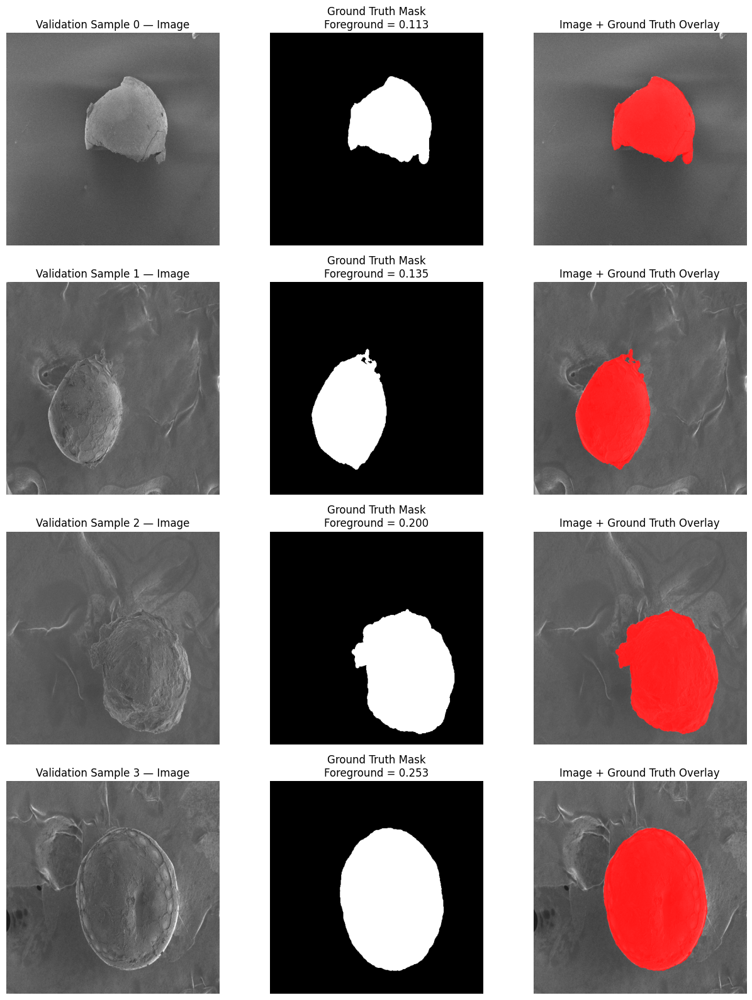


Saved figure:
/kaggle/working/microplastic_project/figures/preprocessing_validation_visual_check.png

CELL 25 COMPLETED
VISUAL PREPROCESSING CHECK GENERATED


In [30]:
# ============================================================
# CELL 25 — PREPROCESSING VISUAL QUALITY CHECK
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import torch

print("=" * 75)
print("MICROPLASTICS_SEM — PREPROCESSING VISUAL CHECK")
print("=" * 75)


# ------------------------------------------------------------
# Helper: reverse ImageNet normalization
# ------------------------------------------------------------
MEAN = np.array([0.485, 0.456, 0.406])
STD  = np.array([0.229, 0.224, 0.225])


def denormalize_image(image_tensor):
    """
    Convert normalized CHW tensor back to displayable HWC image.
    """

    image = image_tensor.detach().cpu().numpy()
    image = image.transpose(1, 2, 0)

    image = image * STD + MEAN
    image = np.clip(image, 0, 1)

    return image


# ------------------------------------------------------------
# Get deterministic validation samples
# ------------------------------------------------------------
sample_indices = [0, 1, 2, 3]


fig, axes = plt.subplots(
    len(sample_indices),
    3,
    figsize=(13, 16)
)

for row_idx, sample_idx in enumerate(sample_indices):

    image, mask = val_dataset[sample_idx]

    image_display = denormalize_image(image)

    mask_display = mask.squeeze(0).numpy()

    overlay = image_display.copy()

    # Red overlay on foreground
    foreground = mask_display > 0.5

    overlay[foreground, 0] = 1.0
    overlay[foreground, 1] *= 0.35
    overlay[foreground, 2] *= 0.35

    # --------------------------------------------------------
    # Original image
    # --------------------------------------------------------
    axes[row_idx, 0].imshow(image_display)
    axes[row_idx, 0].set_title(
        f"Validation Sample {sample_idx} — Image"
    )
    axes[row_idx, 0].axis("off")

    # --------------------------------------------------------
    # Ground-truth mask
    # --------------------------------------------------------
    axes[row_idx, 1].imshow(
        mask_display,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[row_idx, 1].set_title(
        f"Ground Truth Mask\n"
        f"Foreground = {mask_display.mean():.3f}"
    )
    axes[row_idx, 1].axis("off")

    # --------------------------------------------------------
    # Overlay
    # --------------------------------------------------------
    axes[row_idx, 2].imshow(overlay)
    axes[row_idx, 2].set_title(
        "Image + Ground Truth Overlay"
    )
    axes[row_idx, 2].axis("off")


plt.tight_layout()

FIGURE_PATH = (
    "/kaggle/working/microplastic_project/"
    "figures/preprocessing_validation_visual_check.png"
)

plt.savefig(
    FIGURE_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nSaved figure:")
print(FIGURE_PATH)

print("\n" + "=" * 75)
print("CELL 25 COMPLETED")
print("VISUAL PREPROCESSING CHECK GENERATED")
print("=" * 75)

**Baseline U-Net architecture**

In [31]:
# ============================================================
# CELL 26 — BASELINE U-NET ARCHITECTURE
# Microplastics SEM Segmentation
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# 1. Double Convolution Block
# ============================================================

class DoubleConv(nn.Module):
    """
    Standard U-Net convolutional block:

    Conv -> BatchNorm -> ReLU
    Conv -> BatchNorm -> ReLU
    """

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        return self.block(x)


# ============================================================
# 2. Baseline U-Net
# ============================================================

class UNetBaseline(nn.Module):

    def __init__(
        self,
        in_channels=3,
        out_channels=1
    ):

        super().__init__()

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        self.enc1 = DoubleConv(
            in_channels,
            64
        )

        self.enc2 = DoubleConv(
            64,
            128
        )

        self.enc3 = DoubleConv(
            128,
            256
        )

        self.enc4 = DoubleConv(
            256,
            512
        )

        # ----------------------------------------------------
        # Bottleneck
        # ----------------------------------------------------

        self.bottleneck = DoubleConv(
            512,
            1024
        )

        # ----------------------------------------------------
        # Pooling
        # ----------------------------------------------------

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        self.up4 = nn.ConvTranspose2d(
            1024,
            512,
            kernel_size=2,
            stride=2
        )

        self.dec4 = DoubleConv(
            1024,
            512
        )

        self.up3 = nn.ConvTranspose2d(
            512,
            256,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            512,
            256
        )

        self.up2 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            256,
            128
        )

        self.up1 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            128,
            64
        )

        # ----------------------------------------------------
        # Segmentation head
        # ----------------------------------------------------

        self.head = nn.Conv2d(
            64,
            out_channels,
            kernel_size=1
        )

    # ========================================================
    # Forward
    # ========================================================

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )

        # Bottleneck
        b = self.bottleneck(
            self.pool(e4)
        )

        # Decoder 4
        d4 = self.up4(b)

        d4 = torch.cat(
            [d4, e4],
            dim=1
        )

        d4 = self.dec4(d4)

        # Decoder 3
        d3 = self.up3(d4)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)

        # Decoder 2
        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)

        # Decoder 1
        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)

        # Segmentation logits
        logits = self.head(d1)

        return logits


# ============================================================
# 3. Instantiate model
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

baseline_model = UNetBaseline(
    in_channels=3,
    out_channels=1
).to(device)


# ============================================================
# 4. Parameter count
# ============================================================

total_params = sum(
    p.numel()
    for p in baseline_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in baseline_model.parameters()
    if p.requires_grad
)


# ============================================================
# 5. Forward-pass verification
# ============================================================

dummy_input = torch.randn(
    2,
    3,
    512,
    512,
    device=device
)

with torch.no_grad():

    dummy_output = baseline_model(
        dummy_input
    )


# ============================================================
# 6. Verification
# ============================================================

print("=" * 75)
print("MICROPLASTICS_SEM — BASELINE U-NET")
print("=" * 75)

print(f"Device           : {device}")
print(f"Input shape      : {tuple(dummy_input.shape)}")
print(f"Output shape     : {tuple(dummy_output.shape)}")
print(f"Total parameters : {total_params:,}")
print(f"Trainable params : {trainable_params:,}")

print(
    f"Output range     : "
    f"{dummy_output.min().item():.4f} "
    f"to "
    f"{dummy_output.max().item():.4f}"
)

assert dummy_output.shape == (
    2,
    1,
    512,
    512
)

assert total_params == trainable_params

print("\nForward pass: PASS")
print("Output resolution: PASS")
print("Single-channel segmentation head: PASS")

print("\n" + "=" * 75)
print("CELL 26 COMPLETED")
print("BASELINE U-NET ARCHITECTURE VERIFIED")
print("=" * 75)

MICROPLASTICS_SEM — BASELINE U-NET
Device           : cuda
Input shape      : (2, 3, 512, 512)
Output shape     : (2, 1, 512, 512)
Total parameters : 31,037,633
Trainable params : 31,037,633
Output range     : -1.5769 to 1.8530

Forward pass: PASS
Output resolution: PASS
Single-channel segmentation head: PASS

CELL 26 COMPLETED
BASELINE U-NET ARCHITECTURE VERIFIED


**Attention Gate**

In [32]:
# ============================================================
# CELL 27 — ATTENTION GATE MODULE
# Microplastics SEM Segmentation
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# Attention Gate
# ============================================================

class AttentionGate(nn.Module):
    """
    Additive Attention Gate for U-Net skip connections.

    x:
        Encoder feature map.

    g:
        Decoder/gating feature map.

    Output:
        Attention-refined encoder feature map.
    """

    def __init__(
        self,
        encoder_channels,
        gating_channels,
        intermediate_channels
    ):

        super().__init__()

        # ----------------------------------------------------
        # Encoder projection
        # ----------------------------------------------------

        self.theta_x = nn.Conv2d(
            encoder_channels,
            intermediate_channels,
            kernel_size=1,
            stride=1,
            padding=0,
            bias=True
        )

        # ----------------------------------------------------
        # Decoder/gating projection
        # ----------------------------------------------------

        self.phi_g = nn.Conv2d(
            gating_channels,
            intermediate_channels,
            kernel_size=1,
            stride=1,
            padding=0,
            bias=True
        )

        # ----------------------------------------------------
        # Attention coefficient
        # ----------------------------------------------------

        self.psi = nn.Conv2d(
            intermediate_channels,
            1,
            kernel_size=1,
            stride=1,
            padding=0,
            bias=True
        )

        # ----------------------------------------------------
        # Normalization + activation
        # ----------------------------------------------------

        self.norm = nn.BatchNorm2d(
            intermediate_channels
        )

        self.relu = nn.ReLU(
            inplace=True
        )

        self.sigmoid = nn.Sigmoid()

    # ========================================================
    # Forward
    # ========================================================

    def forward(self, x, g):

        # Encoder projection
        theta_x = self.theta_x(x)

        # Gating projection
        phi_g = self.phi_g(g)

        # ----------------------------------------------------
        # Match spatial dimensions
        # ----------------------------------------------------

        if theta_x.shape[-2:] != phi_g.shape[-2:]:

            phi_g = F.interpolate(
                phi_g,
                size=theta_x.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        # ----------------------------------------------------
        # Additive attention
        # ----------------------------------------------------

        attention = theta_x + phi_g

        attention = self.relu(
            attention
        )

        attention = self.psi(
            attention
        )

        attention = self.sigmoid(
            attention
        )

        # ----------------------------------------------------
        # Apply attention coefficients
        # ----------------------------------------------------

        refined_x = x * attention

        return refined_x, attention


# ============================================================
# Test Attention Gate
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

attention_gate = AttentionGate(
    encoder_channels=512,
    gating_channels=512,
    intermediate_channels=256
).to(device)


# ------------------------------------------------------------
# Dummy feature maps
# ------------------------------------------------------------

encoder_features = torch.randn(
    2,
    512,
    32,
    32,
    device=device
)

decoder_features = torch.randn(
    2,
    512,
    32,
    32,
    device=device
)


# ------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------

with torch.no_grad():

    refined_features, attention_map = attention_gate(
        encoder_features,
        decoder_features
    )


# ============================================================
# Verification
# ============================================================

total_params = sum(
    p.numel()
    for p in attention_gate.parameters()
)

trainable_params = sum(
    p.numel()
    for p in attention_gate.parameters()
    if p.requires_grad
)

print("=" * 75)
print("MICROPLASTICS_SEM — ATTENTION GATE")
print("=" * 75)

print(f"Device                : {device}")

print(
    f"Encoder input         : "
    f"{tuple(encoder_features.shape)}"
)

print(
    f"Decoder gating input  : "
    f"{tuple(decoder_features.shape)}"
)

print(
    f"Refined skip output   : "
    f"{tuple(refined_features.shape)}"
)

print(
    f"Attention map         : "
    f"{tuple(attention_map.shape)}"
)

print(
    f"Attention range       : "
    f"{attention_map.min().item():.6f} "
    f"to "
    f"{attention_map.max().item():.6f}"
)

print(
    f"Attention parameters  : "
    f"{total_params:,}"
)

print(
    f"Trainable parameters  : "
    f"{trainable_params:,}"
)


# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert refined_features.shape == encoder_features.shape

assert attention_map.shape == (
    2,
    1,
    32,
    32
)

assert attention_map.min().item() >= 0.0
assert attention_map.max().item() <= 1.0

assert total_params == trainable_params

print("\nFeature shape preservation: PASS")
print("Attention coefficient range [0,1]: PASS")
print("Attention map generation: PASS")

print("\n" + "=" * 75)
print("CELL 27 COMPLETED")
print("ATTENTION GATE VERIFIED")
print("=" * 75)

MICROPLASTICS_SEM — ATTENTION GATE
Device                : cuda
Encoder input         : (2, 512, 32, 32)
Decoder gating input  : (2, 512, 32, 32)
Refined skip output   : (2, 512, 32, 32)
Attention map         : (2, 1, 32, 32)
Attention range       : 0.254023 to 0.699478
Attention parameters  : 263,425
Trainable parameters  : 263,425

Feature shape preservation: PASS
Attention coefficient range [0,1]: PASS
Attention map generation: PASS

CELL 27 COMPLETED
ATTENTION GATE VERIFIED


**Full Attention U-Net**

In [33]:
# ============================================================
# CELL 28 — FULL ATTENTION U-NET
# Microplastics SEM Segmentation
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# 1. Double Convolution Block
# ============================================================

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        return self.block(x)


# ============================================================
# 2. Attention Gate
# ============================================================

class AttentionGate(nn.Module):

    def __init__(
        self,
        encoder_channels,
        gating_channels,
        intermediate_channels
    ):

        super().__init__()

        self.theta_x = nn.Conv2d(
            encoder_channels,
            intermediate_channels,
            kernel_size=1
        )

        self.phi_g = nn.Conv2d(
            gating_channels,
            intermediate_channels,
            kernel_size=1
        )

        self.psi = nn.Conv2d(
            intermediate_channels,
            1,
            kernel_size=1
        )

        self.relu = nn.ReLU(
            inplace=True
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x, g):

        theta_x = self.theta_x(x)

        phi_g = self.phi_g(g)

        if theta_x.shape[-2:] != phi_g.shape[-2:]:

            phi_g = F.interpolate(
                phi_g,
                size=theta_x.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        attention = theta_x + phi_g

        attention = self.relu(
            attention
        )

        attention = self.psi(
            attention
        )

        attention = self.sigmoid(
            attention
        )

        refined_x = x * attention

        return refined_x, attention


# ============================================================
# 3. Attention U-Net
# ============================================================

class AttentionUNet(nn.Module):

    def __init__(
        self,
        in_channels=3,
        out_channels=1
    ):

        super().__init__()

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        self.enc1 = DoubleConv(
            in_channels,
            64
        )

        self.enc2 = DoubleConv(
            64,
            128
        )

        self.enc3 = DoubleConv(
            128,
            256
        )

        self.enc4 = DoubleConv(
            256,
            512
        )

        # ----------------------------------------------------
        # Bottleneck
        # ----------------------------------------------------

        self.bottleneck = DoubleConv(
            512,
            1024
        )

        # ----------------------------------------------------
        # Pooling
        # ----------------------------------------------------

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        self.up4 = nn.ConvTranspose2d(
            1024,
            512,
            kernel_size=2,
            stride=2
        )

        self.dec4 = DoubleConv(
            1024,
            512
        )

        self.up3 = nn.ConvTranspose2d(
            512,
            256,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            512,
            256
        )

        self.up2 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            256,
            128
        )

        self.up1 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            128,
            64
        )

        # ----------------------------------------------------
        # Attention gates
        # ----------------------------------------------------

        self.att4 = AttentionGate(
            encoder_channels=512,
            gating_channels=512,
            intermediate_channels=256
        )

        self.att3 = AttentionGate(
            encoder_channels=256,
            gating_channels=256,
            intermediate_channels=128
        )

        self.att2 = AttentionGate(
            encoder_channels=128,
            gating_channels=128,
            intermediate_channels=64
        )

        self.att1 = AttentionGate(
            encoder_channels=64,
            gating_channels=64,
            intermediate_channels=32
        )

        # ----------------------------------------------------
        # Segmentation head
        # ----------------------------------------------------

        self.head = nn.Conv2d(
            64,
            out_channels,
            kernel_size=1
        )

    # ========================================================
    # Forward
    # ========================================================

    def forward(
        self,
        x,
        return_attention=False
    ):

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )

        # ----------------------------------------------------
        # Bottleneck
        # ----------------------------------------------------

        b = self.bottleneck(
            self.pool(e4)
        )

        # ----------------------------------------------------
        # Decoder 4
        # ----------------------------------------------------

        d4 = self.up4(b)

        e4_att, a4 = self.att4(
            e4,
            d4
        )

        d4 = torch.cat(
            [d4, e4_att],
            dim=1
        )

        d4 = self.dec4(d4)

        # ----------------------------------------------------
        # Decoder 3
        # ----------------------------------------------------

        d3 = self.up3(d4)

        e3_att, a3 = self.att3(
            e3,
            d3
        )

        d3 = torch.cat(
            [d3, e3_att],
            dim=1
        )

        d3 = self.dec3(d3)

        # ----------------------------------------------------
        # Decoder 2
        # ----------------------------------------------------

        d2 = self.up2(d3)

        e2_att, a2 = self.att2(
            e2,
            d2
        )

        d2 = torch.cat(
            [d2, e2_att],
            dim=1
        )

        d2 = self.dec2(d2)

        # ----------------------------------------------------
        # Decoder 1
        # ----------------------------------------------------

        d1 = self.up1(d2)

        e1_att, a1 = self.att1(
            e1,
            d1
        )

        d1 = torch.cat(
            [d1, e1_att],
            dim=1
        )

        d1 = self.dec1(d1)

        # ----------------------------------------------------
        # Segmentation logits
        # ----------------------------------------------------

        logits = self.head(d1)

        # ----------------------------------------------------
        # Optional attention maps
        # ----------------------------------------------------

        if return_attention:

            attention_maps = {
                "attention_64": a1,
                "attention_128": a2,
                "attention_256": a3,
                "attention_512": a4
            }

            return logits, attention_maps

        return logits


# ============================================================
# 4. Instantiate
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

attention_model = AttentionUNet(
    in_channels=3,
    out_channels=1
).to(device)


# ============================================================
# 5. Parameter count
# ============================================================

total_params = sum(
    p.numel()
    for p in attention_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in attention_model.parameters()
    if p.requires_grad
)


# ============================================================
# 6. Forward-pass verification
# ============================================================

dummy_input = torch.randn(
    2,
    3,
    512,
    512,
    device=device
)

with torch.no_grad():

    dummy_output, attention_maps = attention_model(
        dummy_input,
        return_attention=True
    )


# ============================================================
# 7. Verification
# ============================================================

print("=" * 75)
print("MICROPLASTICS_SEM — FULL ATTENTION U-NET")
print("=" * 75)

print(f"Device           : {device}")

print(
    f"Input shape      : "
    f"{tuple(dummy_input.shape)}"
)

print(
    f"Output shape     : "
    f"{tuple(dummy_output.shape)}"
)

print(
    f"Total parameters : "
    f"{total_params:,}"
)

print(
    f"Trainable params : "
    f"{trainable_params:,}"
)

print(
    f"Output range     : "
    f"{dummy_output.min().item():.4f} "
    f"to "
    f"{dummy_output.max().item():.4f}"
)

print("\nAttention maps:")

for name, attention_map in attention_maps.items():

    print(
        f"  {name:15s}: "
        f"{tuple(attention_map.shape)} | "
        f"range = "
        f"{attention_map.min().item():.4f} "
        f"to "
        f"{attention_map.max().item():.4f}"
    )


# ============================================================
# 8. Assertions
# ============================================================

assert dummy_output.shape == (
    2,
    1,
    512,
    512
)

assert len(attention_maps) == 4

assert attention_maps["attention_64"].shape == (
    2,
    1,
    512,
    512
)

assert attention_maps["attention_128"].shape == (
    2,
    1,
    256,
    256
)

assert attention_maps["attention_256"].shape == (
    2,
    1,
    128,
    128
)

assert attention_maps["attention_512"].shape == (
    2,
    1,
    64,
    64
)

for attention_map in attention_maps.values():

    assert attention_map.min().item() >= 0.0
    assert attention_map.max().item() <= 1.0


assert total_params > 31_037_633

assert total_params == trainable_params


print("\nOutput resolution: PASS")
print("Four attention gates: PASS")
print("Attention-map resolutions: PASS")
print("Attention coefficient range: PASS")
print("Parameter increase over baseline: PASS")

print("\n" + "=" * 75)
print("CELL 28 COMPLETED")
print("FULL ATTENTION U-NET VERIFIED")
print("=" * 75)

MICROPLASTICS_SEM — FULL ATTENTION U-NET
Device           : cuda
Input shape      : (2, 3, 512, 512)
Output shape     : (2, 1, 512, 512)
Total parameters : 31,387,237
Trainable params : 31,387,237
Output range     : -1.2765 to 1.9134

Attention maps:
  attention_64   : (2, 1, 512, 512) | range = 0.3503 to 0.6516
  attention_128  : (2, 1, 256, 256) | range = 0.3736 to 0.6265
  attention_256  : (2, 1, 128, 128) | range = 0.3587 to 0.6297
  attention_512  : (2, 1, 64, 64) | range = 0.4159 to 0.6483

Output resolution: PASS
Four attention gates: PASS
Attention-map resolutions: PASS
Attention coefficient range: PASS
Parameter increase over baseline: PASS

CELL 28 COMPLETED
FULL ATTENTION U-NET VERIFIED


**Loss functions and evaluation metrics**

In [34]:
# ============================================================
# CELL 29 — LOSS FUNCTIONS + SEGMENTATION METRICS
# Microplastics SEM Segmentation
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# 1. Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(self, smooth=1e-6):

        super().__init__()

        self.smooth = smooth

    def forward(self, logits, targets):

        probabilities = torch.sigmoid(logits)

        probabilities = probabilities.contiguous().view(
            probabilities.size(0), -1
        )

        targets = targets.contiguous().view(
            targets.size(0), -1
        )

        intersection = (
            probabilities * targets
        ).sum(dim=1)

        denominator = (
            probabilities.sum(dim=1)
            +
            targets.sum(dim=1)
        )

        dice = (
            (2.0 * intersection + self.smooth)
            /
            (denominator + self.smooth)
        )

        return 1.0 - dice.mean()


# ============================================================
# 2. Combined BCE + Dice Loss
# ============================================================

class BCEDiceLoss(nn.Module):

    def __init__(
        self,
        bce_weight=0.5,
        dice_weight=0.5,
        smooth=1e-6
    ):

        super().__init__()

        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

        self.bce = nn.BCEWithLogitsLoss()

        self.dice = DiceLoss(
            smooth=smooth
        )

    def forward(self, logits, targets):

        bce_loss = self.bce(
            logits,
            targets
        )

        dice_loss = self.dice(
            logits,
            targets
        )

        total_loss = (
            self.bce_weight * bce_loss
            +
            self.dice_weight * dice_loss
        )

        return total_loss


# ============================================================
# 3. Dice coefficient
# ============================================================

@torch.no_grad()
def dice_score(
    logits,
    targets,
    threshold=0.5,
    smooth=1e-6
):

    probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities >= threshold
    ).float()

    predictions = predictions.contiguous().view(
        predictions.size(0), -1
    )

    targets = targets.contiguous().view(
        targets.size(0), -1
    )

    intersection = (
        predictions * targets
    ).sum(dim=1)

    denominator = (
        predictions.sum(dim=1)
        +
        targets.sum(dim=1)
    )

    dice = (
        (2.0 * intersection + smooth)
        /
        (denominator + smooth)
    )

    return dice.mean().item()


# ============================================================
# 4. IoU / Jaccard
# ============================================================

@torch.no_grad()
def iou_score(
    logits,
    targets,
    threshold=0.5,
    smooth=1e-6
):

    probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities >= threshold
    ).float()

    predictions = predictions.contiguous().view(
        predictions.size(0), -1
    )

    targets = targets.contiguous().view(
        targets.size(0), -1
    )

    intersection = (
        predictions * targets
    ).sum(dim=1)

    union = (
        predictions
        +
        targets
        -
        predictions * targets
    ).sum(dim=1)

    iou = (
        (intersection + smooth)
        /
        (union + smooth)
    )

    return iou.mean().item()


# ============================================================
# 5. Pixel-level confusion statistics
# ============================================================

@torch.no_grad()
def confusion_statistics(
    logits,
    targets,
    threshold=0.5
):

    probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities >= threshold
    ).float()

    predictions = predictions.view(-1)
    targets = targets.view(-1)

    tp = (
        (predictions == 1)
        &
        (targets == 1)
    ).sum().item()

    tn = (
        (predictions == 0)
        &
        (targets == 0)
    ).sum().item()

    fp = (
        (predictions == 1)
        &
        (targets == 0)
    ).sum().item()

    fn = (
        (predictions == 0)
        &
        (targets == 1)
    ).sum().item()

    return tp, tn, fp, fn


# ============================================================
# 6. Precision
# ============================================================

def precision_score_from_counts(
    tp,
    fp,
    eps=1e-8
):

    return tp / (
        tp + fp + eps
    )


# ============================================================
# 7. Recall / Sensitivity
# ============================================================

def recall_score_from_counts(
    tp,
    fn,
    eps=1e-8
):

    return tp / (
        tp + fn + eps
    )


# ============================================================
# 8. Specificity
# ============================================================

def specificity_score_from_counts(
    tn,
    fp,
    eps=1e-8
):

    return tn / (
        tn + fp + eps
    )


# ============================================================
# 9. F1 score
# ============================================================

def f1_score_from_counts(
    tp,
    fp,
    fn,
    eps=1e-8
):

    precision = precision_score_from_counts(
        tp,
        fp,
        eps
    )

    recall = recall_score_from_counts(
        tp,
        fn,
        eps
    )

    return (
        2.0 * precision * recall
        /
        (precision + recall + eps)
    )


# ============================================================
# 10. Accuracy
# ============================================================

def accuracy_score_from_counts(
    tp,
    tn,
    fp,
    fn,
    eps=1e-8
):

    return (
        tp + tn
    ) / (
        tp + tn + fp + fn + eps
    )


# ============================================================
# 11. Balanced Accuracy
# ============================================================

def balanced_accuracy_from_counts(
    tp,
    tn,
    fp,
    fn,
    eps=1e-8
):

    sensitivity = recall_score_from_counts(
        tp,
        fn,
        eps
    )

    specificity = specificity_score_from_counts(
        tn,
        fp,
        eps
    )

    return (
        sensitivity + specificity
    ) / 2.0


# ============================================================
# 12. Combined metric evaluation
# ============================================================

@torch.no_grad()
def calculate_metrics(
    logits,
    targets,
    threshold=0.5
):

    tp, tn, fp, fn = confusion_statistics(
        logits,
        targets,
        threshold
    )

    dice = dice_score(
        logits,
        targets,
        threshold
    )

    iou = iou_score(
        logits,
        targets,
        threshold
    )

    precision = precision_score_from_counts(
        tp,
        fp
    )

    recall = recall_score_from_counts(
        tp,
        fn
    )

    specificity = specificity_score_from_counts(
        tn,
        fp
    )

    f1 = f1_score_from_counts(
        tp,
        fp,
        fn
    )

    accuracy = accuracy_score_from_counts(
        tp,
        tn,
        fp,
        fn
    )

    balanced_accuracy = balanced_accuracy_from_counts(
        tp,
        tn,
        fp,
        fn
    )

    return {
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1,
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn
    }


# ============================================================
# 13. Synthetic sanity test
# ============================================================

torch.manual_seed(42)

test_logits = torch.randn(
    2,
    1,
    64,
    64
)

test_targets = torch.randint(
    0,
    2,
    (
        2,
        1,
        64,
        64
    )
).float()


# ------------------------------------------------------------
# Losses
# ------------------------------------------------------------

dice_loss_fn = DiceLoss()

combined_loss_fn = BCEDiceLoss(
    bce_weight=0.5,
    dice_weight=0.5
)

test_dice_loss = dice_loss_fn(
    test_logits,
    test_targets
)

test_combined_loss = combined_loss_fn(
    test_logits,
    test_targets
)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

test_metrics = calculate_metrics(
    test_logits,
    test_targets,
    threshold=0.5
)


# ============================================================
# 14. Print verification
# ============================================================

print("=" * 75)
print("MICROPLASTICS_SEM — LOSS + METRICS")
print("=" * 75)

print(
    f"Dice loss          : "
    f"{test_dice_loss.item():.6f}"
)

print(
    f"Combined BCE+Dice  : "
    f"{test_combined_loss.item():.6f}"
)

print("\nMetrics:")

for key in [
    "dice",
    "iou",
    "precision",
    "recall",
    "specificity",
    "f1",
    "accuracy",
    "balanced_accuracy"
]:

    print(
        f"  {key:18s}: "
        f"{test_metrics[key]:.6f}"
    )

print("\nConfusion statistics:")

for key in [
    "tp",
    "tn",
    "fp",
    "fn"
]:

    print(
        f"  {key.upper():18s}: "
        f"{test_metrics[key]}"
    )


# ============================================================
# 15. Assertions
# ============================================================

assert torch.isfinite(
    test_dice_loss
)

assert torch.isfinite(
    test_combined_loss
)

for key in [
    "dice",
    "iou",
    "precision",
    "recall",
    "specificity",
    "f1",
    "accuracy",
    "balanced_accuracy"
]:

    assert 0.0 <= test_metrics[key] <= 1.0

assert (
    test_metrics["tp"]
    +
    test_metrics["tn"]
    +
    test_metrics["fp"]
    +
    test_metrics["fn"]
    ==
    test_targets.numel()
)

print("\nDice loss: PASS")
print("BCE + Dice loss: PASS")
print("All segmentation metrics: PASS")
print("Confusion statistics: PASS")

print("\n" + "=" * 75)
print("CELL 29 COMPLETED")
print("LOSS FUNCTIONS + METRICS VERIFIED")
print("=" * 75)

MICROPLASTICS_SEM — LOSS + METRICS
Dice loss          : 0.501925
Combined BCE+Dice  : 0.653657

Metrics:
  dice              : 0.497166
  iou               : 0.330821
  precision         : 0.493671
  recall            : 0.500741
  specificity       : 0.497827
  f1                : 0.497181
  accuracy          : 0.499268
  balanced_accuracy : 0.499284

Confusion statistics:
  TP                : 2028
  TN                : 2062
  FP                : 2080
  FN                : 2022

Dice loss: PASS
BCE + Dice loss: PASS
All segmentation metrics: PASS
Confusion statistics: PASS

CELL 29 COMPLETED
LOSS FUNCTIONS + METRICS VERIFIED


**Training configuration**

In [36]:
# ============================================================
# CELL 30 — REPRODUCIBLE TRAINING CONFIGURATION
# Microplastics SEM Segmentation
# ============================================================

import os
import json
import random
import numpy as np
import torch


# ============================================================
# 1. Reproducibility
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Deterministic behavior where practical
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# 2. Device
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# 3. Training hyperparameters
# ============================================================

TRAIN_CONFIG = {

    # --------------------------------------------------------
    # Data
    # --------------------------------------------------------

    "image_size": 512,

    "batch_size": 4,

    "num_workers": 2,

    # --------------------------------------------------------
    # Optimization
    # --------------------------------------------------------

    "optimizer": "AdamW",

    "learning_rate": 1e-4,

    "weight_decay": 1e-4,

    # --------------------------------------------------------
    # Loss
    # --------------------------------------------------------

    "loss": "BCE_Dice",

    "bce_weight": 0.5,

    "dice_weight": 0.5,

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    "scheduler": "ReduceLROnPlateau",

    "scheduler_mode": "max",

    "scheduler_factor": 0.5,

    "scheduler_patience": 4,

    "scheduler_min_lr": 1e-7,

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    "epochs": 50,

    "early_stopping_patience": 10,

    "early_stopping_metric": "val_dice",

    # --------------------------------------------------------
    # Evaluation
    # --------------------------------------------------------

    "threshold": 0.5,

    # --------------------------------------------------------
    # Mixed precision
    # --------------------------------------------------------

    "mixed_precision": True,

    # --------------------------------------------------------
    # Reproducibility
    # --------------------------------------------------------

    "seed": SEED
}


# ============================================================
# 4. Experiment directories
# ============================================================

CHECKPOINT_DIR = os.path.join(
    PROJECT_ROOT,
    "checkpoints"
)

LOG_DIR = os.path.join(
    PROJECT_ROOT,
    "logs"
)

RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "results"
)

FIGURES_DIR = os.path.join(
    PROJECT_ROOT,
    "figures"
)

for directory in [
    CHECKPOINT_DIR,
    LOG_DIR,
    RESULTS_DIR,
    FIGURES_DIR
]:

    os.makedirs(
        directory,
        exist_ok=True
    )


# ============================================================
# 5. Experiment names
# ============================================================

BASELINE_EXPERIMENT = "baseline_unet"

ATTENTION_EXPERIMENT = "attention_unet"


# ============================================================
# 6. Checkpoint paths
# ============================================================

BASELINE_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    f"{BASELINE_EXPERIMENT}_best.pth"
)

ATTENTION_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    f"{ATTENTION_EXPERIMENT}_best.pth"
)


# ============================================================
# 7. Configuration files
# ============================================================

CONFIG_JSON = os.path.join(
    RESULTS_DIR,
    "training_config.json"
)

with open(
    CONFIG_JSON,
    "w"
) as f:

    json.dump(
        TRAIN_CONFIG,
        f,
        indent=4
    )


# ============================================================
# 8. Print configuration
# ============================================================

print("=" * 75)
print("MICROPLASTICS_SEM — TRAINING CONFIGURATION")
print("=" * 75)

print(f"Device                 : {DEVICE}")
print(f"Seed                   : {SEED}")

print("\nData:")
print(
    f"  Image size           : "
    f"{TRAIN_CONFIG['image_size']} × "
    f"{TRAIN_CONFIG['image_size']}"
)

print(
    f"  Batch size           : "
    f"{TRAIN_CONFIG['batch_size']}"
)

print(
    f"  Workers              : "
    f"{TRAIN_CONFIG['num_workers']}"
)

print("\nOptimization:")

print(
    f"  Optimizer            : "
    f"{TRAIN_CONFIG['optimizer']}"
)

print(
    f"  Learning rate        : "
    f"{TRAIN_CONFIG['learning_rate']}"
)

print(
    f"  Weight decay         : "
    f"{TRAIN_CONFIG['weight_decay']}"
)

print("\nLoss:")

print(
    f"  Loss                 : "
    f"{TRAIN_CONFIG['loss']}"
)

print(
    f"  BCE weight           : "
    f"{TRAIN_CONFIG['bce_weight']}"
)

print(
    f"  Dice weight          : "
    f"{TRAIN_CONFIG['dice_weight']}"
)

print("\nScheduler:")

print(
    f"  Scheduler            : "
    f"{TRAIN_CONFIG['scheduler']}"
)

print(
    f"  Mode                 : "
    f"{TRAIN_CONFIG['scheduler_mode']}"
)

print(
    f"  Factor               : "
    f"{TRAIN_CONFIG['scheduler_factor']}"
)

print(
    f"  Patience             : "
    f"{TRAIN_CONFIG['scheduler_patience']}"
)

print(
    f"  Minimum LR           : "
    f"{TRAIN_CONFIG['scheduler_min_lr']}"
)

print("\nTraining:")

print(
    f"  Maximum epochs       : "
    f"{TRAIN_CONFIG['epochs']}"
)

print(
    f"  Early stopping       : "
    f"{TRAIN_CONFIG['early_stopping_patience']} epochs"
)

print(
    f"  Selection metric     : "
    f"{TRAIN_CONFIG['early_stopping_metric']}"
)

print("\nMixed precision:")

print(
    f"  Enabled              : "
    f"{TRAIN_CONFIG['mixed_precision']}"
)

print("\nCheckpoints:")

print(
    f"  Baseline             : "
    f"{BASELINE_CHECKPOINT}"
)

print(
    f"  Attention            : "
    f"{ATTENTION_CHECKPOINT}"
)

print("\nConfiguration saved:")
print(CONFIG_JSON)


# ============================================================
# 9. Assertions
# ============================================================

assert TRAIN_CONFIG["image_size"] == 512

assert TRAIN_CONFIG["batch_size"] == 4

assert TRAIN_CONFIG["optimizer"] == "AdamW"

assert TRAIN_CONFIG["learning_rate"] > 0

assert TRAIN_CONFIG["weight_decay"] >= 0

assert (
    TRAIN_CONFIG["bce_weight"]
    +
    TRAIN_CONFIG["dice_weight"]
    == 1.0
)

assert TRAIN_CONFIG["epochs"] > 0

assert TRAIN_CONFIG["early_stopping_patience"] > 0

assert TRAIN_CONFIG["threshold"] == 0.5

assert os.path.exists(
    CONFIG_JSON
)


print("\nConfiguration validation: PASS")
print("Reproducibility settings: PASS")
print("Checkpoint directories: PASS")
print("Training configuration saved: PASS")

print("\n" + "=" * 75)
print("CELL 30 COMPLETED")
print("REPRODUCIBLE TRAINING CONFIGURATION VERIFIED")
print("=" * 75)

MICROPLASTICS_SEM — TRAINING CONFIGURATION
Device                 : cuda
Seed                   : 42

Data:
  Image size           : 512 × 512
  Batch size           : 4
  Workers              : 2

Optimization:
  Optimizer            : AdamW
  Learning rate        : 0.0001
  Weight decay         : 0.0001

Loss:
  Loss                 : BCE_Dice
  BCE weight           : 0.5
  Dice weight          : 0.5

Scheduler:
  Scheduler            : ReduceLROnPlateau
  Mode                 : max
  Factor               : 0.5
  Patience             : 4
  Minimum LR           : 1e-07

Training:
  Maximum epochs       : 50
  Early stopping       : 10 epochs
  Selection metric     : val_dice

Mixed precision:
  Enabled              : True

Checkpoints:
  Baseline             : /kaggle/working/microplastic_project/checkpoints/baseline_unet_best.pth
  Attention            : /kaggle/working/microplastic_project/checkpoints/attention_unet_best.pth

Configuration saved:
/kaggle/working/microplastic_project

**Reproducible training engine**

In [37]:
# ============================================================
# CELL 31 — REPRODUCIBLE TRAINING ENGINE
# Microplastics SEM Segmentation
# ============================================================

import os
import csv
import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.amp import autocast, GradScaler


# ============================================================
# 1. Training utilities
# ============================================================

def create_optimizer(model):

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=TRAIN_CONFIG["learning_rate"],
        weight_decay=TRAIN_CONFIG["weight_decay"]
    )

    return optimizer


def create_scheduler(optimizer):

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode=TRAIN_CONFIG["scheduler_mode"],
        factor=TRAIN_CONFIG["scheduler_factor"],
        patience=TRAIN_CONFIG["scheduler_patience"],
        min_lr=TRAIN_CONFIG["scheduler_min_lr"]
    )

    return scheduler


# ============================================================
# 2. Training epoch
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    loss_function,
    scaler,
    device
):

    model.train()

    running_loss = 0.0
    sample_count = 0

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        # ----------------------------------------------------
        # Mixed precision forward pass
        # ----------------------------------------------------

        with autocast(
            device_type="cuda",
            enabled=(
                TRAIN_CONFIG["mixed_precision"]
                and device.type == "cuda"
            )
        ):

            logits = model(images)

            loss = loss_function(
                logits,
                masks
            )

        # ----------------------------------------------------
        # Backward pass
        # ----------------------------------------------------

        scaler.scale(loss).backward()

        scaler.step(
            optimizer
        )

        scaler.update()

        batch_size = images.size(0)

        running_loss += (
            loss.item() * batch_size
        )

        sample_count += batch_size

    epoch_loss = (
        running_loss /
        max(sample_count, 1)
    )

    return epoch_loss


# ============================================================
# 3. Validation epoch
# ============================================================

@torch.no_grad()
def validate_one_epoch(
    model,
    loader,
    loss_function,
    device,
    threshold=0.5
):

    model.eval()

    running_loss = 0.0
    sample_count = 0

    total_tp = 0
    total_tn = 0
    total_fp = 0
    total_fn = 0

    dice_values = []
    iou_values = []

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        with autocast(
            device_type="cuda",
            enabled=(
                TRAIN_CONFIG["mixed_precision"]
                and device.type == "cuda"
            )
        ):

            logits = model(images)

            loss = loss_function(
                logits,
                masks
            )

        batch_size = images.size(0)

        running_loss += (
            loss.item() * batch_size
        )

        sample_count += batch_size

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        batch_metrics = calculate_metrics(
            logits,
            masks,
            threshold=threshold
        )

        dice_values.append(
            batch_metrics["dice"]
        )

        iou_values.append(
            batch_metrics["iou"]
        )

        total_tp += batch_metrics["tp"]
        total_tn += batch_metrics["tn"]
        total_fp += batch_metrics["fp"]
        total_fn += batch_metrics["fn"]

    # --------------------------------------------------------
    # Aggregate loss
    # --------------------------------------------------------

    validation_loss = (
        running_loss /
        max(sample_count, 1)
    )

    # --------------------------------------------------------
    # Aggregate segmentation metrics
    # --------------------------------------------------------

    tp = total_tp
    tn = total_tn
    fp = total_fp
    fn = total_fn

    precision = precision_score_from_counts(
        tp,
        fp
    )

    recall = recall_score_from_counts(
        tp,
        fn
    )

    specificity = specificity_score_from_counts(
        tn,
        fp
    )

    f1 = f1_score_from_counts(
        tp,
        fp,
        fn
    )

    accuracy = accuracy_score_from_counts(
        tp,
        tn,
        fp,
        fn
    )

    balanced_accuracy = balanced_accuracy_from_counts(
        tp,
        tn,
        fp,
        fn
    )

    metrics = {

        "val_loss": validation_loss,

        "val_dice": float(
            np.mean(dice_values)
        ),

        "val_iou": float(
            np.mean(iou_values)
        ),

        "val_precision": precision,

        "val_recall": recall,

        "val_specificity": specificity,

        "val_f1": f1,

        "val_accuracy": accuracy,

        "val_balanced_accuracy":
            balanced_accuracy,

        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn
    }

    return metrics


# ============================================================
# 4. Training history
# ============================================================

def create_history():

    return []


# ============================================================
# 5. Checkpoint saver
# ============================================================

def save_checkpoint(
    path,
    model,
    optimizer,
    scheduler,
    scaler,
    epoch,
    best_metric,
    history,
    experiment_name
):

    checkpoint = {

        "experiment_name":
            experiment_name,

        "epoch":
            epoch,

        "best_val_dice":
            best_metric,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "scaler_state_dict":
            scaler.state_dict(),

        "history":
            history,

        "config":
            TRAIN_CONFIG
    }

    torch.save(
        checkpoint,
        path
    )


# ============================================================
# 6. Complete training function
# ============================================================

def train_model(
    model,
    train_loader,
    val_loader,
    experiment_name,
    checkpoint_path,
    max_epochs=None
):

    if max_epochs is None:

        max_epochs = TRAIN_CONFIG[
            "epochs"
        ]

    model = model.to(DEVICE)

    loss_function = BCEDiceLoss(
        bce_weight=
            TRAIN_CONFIG["bce_weight"],
        dice_weight=
            TRAIN_CONFIG["dice_weight"]
    )

    optimizer = create_optimizer(
        model
    )

    scheduler = create_scheduler(
        optimizer
    )

    scaler = GradScaler(
        "cuda",
        enabled=(
            TRAIN_CONFIG["mixed_precision"]
            and DEVICE.type == "cuda"
        )
    )

    history = create_history()

    best_val_dice = -np.inf

    best_state = None

    epochs_without_improvement = 0

    print("=" * 75)
    print(
        f"TRAINING — {experiment_name}"
    )
    print("=" * 75)

    print(
        f"Maximum epochs : {max_epochs}"
    )

    print(
        f"Early stopping : "
        f"{TRAIN_CONFIG['early_stopping_patience']}"
    )

    print(
        f"Initial LR     : "
        f"{TRAIN_CONFIG['learning_rate']}"
    )

    print("-" * 75)

    for epoch in range(
        1,
        max_epochs + 1
    ):

        epoch_start = time.time()

        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------

        train_loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            loss_function,
            scaler,
            DEVICE
        )

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        val_metrics = validate_one_epoch(
            model,
            val_loader,
            loss_function,
            DEVICE,
            threshold=
                TRAIN_CONFIG["threshold"]
        )

        val_dice = val_metrics[
            "val_dice"
        ]

        # ----------------------------------------------------
        # Scheduler
        # ----------------------------------------------------

        scheduler.step(
            val_dice
        )

        current_lr = optimizer.param_groups[0][
            "lr"
        ]

        epoch_time = (
            time.time()
            -
            epoch_start
        )

        # ----------------------------------------------------
        # Record history
        # ----------------------------------------------------

        record = {

            "epoch": epoch,

            "train_loss": train_loss,

            "val_loss":
                val_metrics["val_loss"],

            "val_dice":
                val_metrics["val_dice"],

            "val_iou":
                val_metrics["val_iou"],

            "val_precision":
                val_metrics["val_precision"],

            "val_recall":
                val_metrics["val_recall"],

            "val_specificity":
                val_metrics["val_specificity"],

            "val_f1":
                val_metrics["val_f1"],

            "val_accuracy":
                val_metrics["val_accuracy"],

            "val_balanced_accuracy":
                val_metrics[
                    "val_balanced_accuracy"
                ],

            "learning_rate":
                current_lr,

            "epoch_time_seconds":
                epoch_time
        }

        history.append(
            record
        )

        # ----------------------------------------------------
        # Improvement?
        # ----------------------------------------------------

        improved = (
            val_dice >
            best_val_dice
        )

        if improved:

            best_val_dice = val_dice

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

            save_checkpoint(
                checkpoint_path,
                model,
                optimizer,
                scheduler,
                scaler,
                epoch,
                best_val_dice,
                history,
                experiment_name
            )

            checkpoint_status = "BEST"

        else:

            epochs_without_improvement += 1

            checkpoint_status = ""

        # ----------------------------------------------------
        # Epoch output
        # ----------------------------------------------------

        print(
            f"Epoch {epoch:02d}/{max_epochs} | "
            f"Train Loss: {train_loss:.5f} | "
            f"Val Loss: {val_metrics['val_loss']:.5f} | "
            f"Val Dice: {val_dice:.5f} | "
            f"Val IoU: {val_metrics['val_iou']:.5f} | "
            f"LR: {current_lr:.2e} | "
            f"{epoch_time:.1f}s "
            f"{checkpoint_status}"
        )

        # ----------------------------------------------------
        # Early stopping
        # ----------------------------------------------------

        if (
            epochs_without_improvement
            >=
            TRAIN_CONFIG[
                "early_stopping_patience"
            ]
        ):

            print(
                "\nEarly stopping triggered."
            )

            break

    # ========================================================
    # Restore best model
    # ========================================================

    if best_state is not None:

        model.load_state_dict(
            best_state
        )

    # ========================================================
    # Save history
    # ========================================================

    history_df = pd.DataFrame(
        history
    )

    history_path = os.path.join(
        LOG_DIR,
        f"{experiment_name}_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    print("\n" + "=" * 75)
    print(
        f"TRAINING COMPLETE — {experiment_name}"
    )
    print("=" * 75)

    print(
        f"Best validation Dice : "
        f"{best_val_dice:.6f}"
    )

    print(
        f"Epochs completed     : "
        f"{len(history)}"
    )

    print(
        f"History saved        : "
        f"{history_path}"
    )

    print(
        f"Best checkpoint      : "
        f"{checkpoint_path}"
    )

    return model, history_df


# ============================================================
# 7. Training-engine smoke test
# ============================================================

print("=" * 75)
print("MICROPLASTICS_SEM — TRAINING ENGINE")
print("=" * 75)

print(
    f"Device               : {DEVICE}"
)

print(
    f"Mixed precision      : "
    f"{TRAIN_CONFIG['mixed_precision']}"
)

print(
    f"Optimizer            : "
    f"{TRAIN_CONFIG['optimizer']}"
)

print(
    f"Scheduler            : "
    f"{TRAIN_CONFIG['scheduler']}"
)

print(
    f"Maximum epochs       : "
    f"{TRAIN_CONFIG['epochs']}"
)

print(
    f"Early stopping       : "
    f"{TRAIN_CONFIG['early_stopping_patience']}"
)


# ------------------------------------------------------------
# Verify optimizer/scheduler without training
# ------------------------------------------------------------

smoke_model = UNetBaseline(
    in_channels=3,
    out_channels=1
).to(DEVICE)

smoke_optimizer = create_optimizer(
    smoke_model
)

smoke_scheduler = create_scheduler(
    smoke_optimizer
)

smoke_scaler = GradScaler(
    "cuda",
    enabled=(
        TRAIN_CONFIG["mixed_precision"]
        and DEVICE.type == "cuda"
    )
)

assert isinstance(
    smoke_optimizer,
    torch.optim.AdamW
)

assert isinstance(
    smoke_scheduler,
    torch.optim.lr_scheduler.ReduceLROnPlateau
)

assert isinstance(
    smoke_scaler,
    GradScaler
)

print("\nOptimizer creation: PASS")
print("Scheduler creation: PASS")
print("AMP GradScaler creation: PASS")
print("Training function definition: PASS")

del smoke_model
del smoke_optimizer
del smoke_scheduler
del smoke_scaler

if torch.cuda.is_available():

    torch.cuda.empty_cache()


print("\n" + "=" * 75)
print("CELL 31 COMPLETED")
print("TRAINING ENGINE VERIFIED — NO MODEL TRAINING STARTED")
print("=" * 75)

MICROPLASTICS_SEM — TRAINING ENGINE
Device               : cuda
Mixed precision      : True
Optimizer            : AdamW
Scheduler            : ReduceLROnPlateau
Maximum epochs       : 50
Early stopping       : 10

Optimizer creation: PASS
Scheduler creation: PASS
AMP GradScaler creation: PASS
Training function definition: PASS

CELL 31 COMPLETED
TRAINING ENGINE VERIFIED — NO MODEL TRAINING STARTED


**Train Baseline U-Net**

In [38]:
# ============================================================
# CELL 32 — BASELINE U-NET TRAINING
# Microplastics SEM Segmentation
# ============================================================

import os
import gc
import torch


# ============================================================
# 1. Clear GPU memory
# ============================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ============================================================
# 2. Re-create baseline model
# ============================================================

baseline_model = UNetBaseline(
    in_channels=3,
    out_channels=1
).to(DEVICE)


# ============================================================
# 3. Verify model parameter count
# ============================================================

baseline_params = sum(
    p.numel()
    for p in baseline_model.parameters()
)

print("=" * 75)
print("MICROPLASTICS_SEM — BASELINE U-NET TRAINING")
print("=" * 75)

print(
    f"Device             : {DEVICE}"
)

print(
    f"Model parameters    : "
    f"{baseline_params:,}"
)

print(
    f"Training samples    : "
    f"{len(train_dataset)}"
)

print(
    f"Validation samples  : "
    f"{len(val_dataset)}"
)

print(
    f"Test samples        : "
    f"{len(test_dataset)}"
)

print(
    "\nTest set usage      : NOT USED"
)

print(
    f"Maximum epochs      : "
    f"{TRAIN_CONFIG['epochs']}"
)

print(
    f"Early stopping      : "
    f"{TRAIN_CONFIG['early_stopping_patience']}"
)

print(
    f"Batch size          : "
    f"{TRAIN_CONFIG['batch_size']}"
)

print(
    f"Learning rate       : "
    f"{TRAIN_CONFIG['learning_rate']}"
)

print(
    f"Mixed precision     : "
    f"{TRAIN_CONFIG['mixed_precision']}"
)

print("-" * 75)


# ============================================================
# 4. Train baseline
# ============================================================

baseline_model, baseline_history = train_model(
    model=baseline_model,

    train_loader=train_loader,

    val_loader=val_loader,

    experiment_name=BASELINE_EXPERIMENT,

    checkpoint_path=BASELINE_CHECKPOINT,

    max_epochs=TRAIN_CONFIG["epochs"]
)


# ============================================================
# 5. Verify training history
# ============================================================

assert len(baseline_history) > 0

assert "train_loss" in baseline_history.columns

assert "val_loss" in baseline_history.columns

assert "val_dice" in baseline_history.columns

assert "val_iou" in baseline_history.columns


# ============================================================
# 6. Verify checkpoint
# ============================================================

assert os.path.exists(
    BASELINE_CHECKPOINT
)

checkpoint_size_mb = (
    os.path.getsize(
        BASELINE_CHECKPOINT
    )
    /
    (1024 ** 2)
)


# ============================================================
# 7. Best validation result
# ============================================================

best_epoch_idx = baseline_history[
    "val_dice"
].idxmax()

best_epoch = int(
    baseline_history.loc[
        best_epoch_idx,
        "epoch"
    ]
)

best_val_dice = float(
    baseline_history.loc[
        best_epoch_idx,
        "val_dice"
    ]
)

best_val_iou = float(
    baseline_history.loc[
        best_epoch_idx,
        "val_iou"
    ]
)


# ============================================================
# 8. Final report
# ============================================================

print("\n" + "=" * 75)
print("BASELINE TRAINING SUMMARY")
print("=" * 75)

print(
    f"Epochs completed    : "
    f"{len(baseline_history)}"
)

print(
    f"Best epoch          : "
    f"{best_epoch}"
)

print(
    f"Best validation Dice: "
    f"{best_val_dice:.6f}"
)

print(
    f"Best validation IoU : "
    f"{best_val_iou:.6f}"
)

print(
    f"Checkpoint size     : "
    f"{checkpoint_size_mb:.2f} MB"
)

print(
    f"Checkpoint exists   : "
    f"{os.path.exists(BASELINE_CHECKPOINT)}"
)

print(
    f"History rows        : "
    f"{len(baseline_history)}"
)

print("\n" + "=" * 75)
print("CELL 32 COMPLETED")
print("BASELINE U-NET TRAINING COMPLETED AND CHECKPOINT VERIFIED")
print("=" * 75)

MICROPLASTICS_SEM — BASELINE U-NET TRAINING
Device             : cuda
Model parameters    : 31,037,633
Training samples    : 167
Validation samples  : 36
Test samples        : 34

Test set usage      : NOT USED
Maximum epochs      : 50
Early stopping      : 10
Batch size          : 4
Learning rate       : 0.0001
Mixed precision     : True
---------------------------------------------------------------------------
TRAINING — baseline_unet
Maximum epochs : 50
Early stopping : 10
Initial LR     : 0.0001
---------------------------------------------------------------------------
Epoch 01/50 | Train Loss: 0.65484 | Val Loss: 0.58781 | Val Dice: 0.42773 | Val IoU: 0.28900 | LR: 1.00e-04 | 18.9s BEST
Epoch 02/50 | Train Loss: 0.57332 | Val Loss: 0.64689 | Val Dice: 0.55077 | Val IoU: 0.40191 | LR: 1.00e-04 | 18.1s BEST
Epoch 03/50 | Train Loss: 0.53603 | Val Loss: 0.56431 | Val Dice: 0.63112 | Val IoU: 0.49038 | LR: 1.00e-04 | 19.0s BEST
Epoch 04/50 | Train Loss: 0.51667 | Val Loss: 0.61155 |

**Final Baseline Test Evaluation**

In [40]:
# ============================================================
# CELL 33 — FINAL BASELINE TEST EVALUATION
# Microplastics SEM Segmentation
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
from torch.amp import autocast


# ============================================================
# 1. Load best baseline checkpoint
# ============================================================

print("=" * 75)
print("MICROPLASTICS_SEM — BASELINE TEST EVALUATION")
print("=" * 75)

print(f"Checkpoint: {BASELINE_CHECKPOINT}")

checkpoint = torch.load(
    BASELINE_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

print(
    f"Checkpoint epoch     : "
    f"{checkpoint['epoch']}"
)

print(
    f"Best validation Dice : "
    f"{checkpoint['best_val_dice']:.6f}"
)


# ============================================================
# 2. Re-create model
# ============================================================

baseline_test_model = UNetBaseline(
    in_channels=3,
    out_channels=1
).to(DEVICE)

baseline_test_model.load_state_dict(
    checkpoint["model_state_dict"]
)

baseline_test_model.eval()


# ============================================================
# 3. Test evaluation
# ============================================================

loss_function = BCEDiceLoss(
    bce_weight=TRAIN_CONFIG["bce_weight"],
    dice_weight=TRAIN_CONFIG["dice_weight"]
)

test_loss_total = 0.0
test_sample_count = 0

total_tp = 0
total_tn = 0
total_fp = 0
total_fn = 0

per_image_results = []


# ============================================================
# 4. Iterate through untouched test set
# ============================================================

with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(
        test_loader
    ):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        masks = masks.to(
            DEVICE,
            non_blocking=True
        )

        with autocast(
            device_type="cuda",
            enabled=(
                TRAIN_CONFIG["mixed_precision"]
                and DEVICE.type == "cuda"
            )
        ):

            logits = baseline_test_model(
                images
            )

            loss = loss_function(
                logits,
                masks
            )

        batch_size = images.size(0)

        test_loss_total += (
            loss.item() * batch_size
        )

        test_sample_count += batch_size

        # ----------------------------------------------------
        # Batch-level confusion statistics
        # ----------------------------------------------------

        batch_metrics = calculate_metrics(
            logits,
            masks,
            threshold=TRAIN_CONFIG["threshold"]
        )

        total_tp += batch_metrics["tp"]
        total_tn += batch_metrics["tn"]
        total_fp += batch_metrics["fp"]
        total_fn += batch_metrics["fn"]

        # ----------------------------------------------------
        # Per-image metrics
        # ----------------------------------------------------

        probabilities = torch.sigmoid(
            logits
        )

        predictions = (
            probabilities
            >= TRAIN_CONFIG["threshold"]
        ).float()

        for i in range(batch_size):

            sample_logits = logits[i:i+1]

            sample_mask = masks[i:i+1]

            sample_metrics = calculate_metrics(
                sample_logits,
                sample_mask,
                threshold=TRAIN_CONFIG["threshold"]
            )

            dataset_index = (
                batch_idx
                *
                TRAIN_CONFIG["batch_size"]
                +
                i
            )

            row = test_df.iloc[
                dataset_index
            ]

            per_image_results.append({

                "dataset_index":
                    int(dataset_index),

                "image_path":
                    row[IMAGE_COL],

                "label_path":
                    row[LABEL_COL],

                "dice":
                    sample_metrics["dice"],

                "iou":
                    sample_metrics["iou"],

                "precision":
                    sample_metrics["precision"],

                "recall":
                    sample_metrics["recall"],

                "specificity":
                    sample_metrics["specificity"],

                "f1":
                    sample_metrics["f1"],

                "accuracy":
                    sample_metrics["accuracy"],

                "balanced_accuracy":
                    sample_metrics[
                        "balanced_accuracy"
                    ],

                "ground_truth_foreground_ratio":
                    float(
                        sample_mask.mean().item()
                    ),

                "predicted_foreground_ratio":
                    float(
                        predictions[i].mean().item()
                    )
            })


# ============================================================
# 5. Aggregate test metrics
# ============================================================

test_loss = (
    test_loss_total
    /
    max(test_sample_count, 1)
)

tp = total_tp
tn = total_tn
fp = total_fp
fn = total_fn


test_precision = precision_score_from_counts(
    tp,
    fp
)

test_recall = recall_score_from_counts(
    tp,
    fn
)

test_specificity = specificity_score_from_counts(
    tn,
    fp
)

test_f1 = f1_score_from_counts(
    tp,
    fp,
    fn
)

test_accuracy = accuracy_score_from_counts(
    tp,
    tn,
    fp,
    fn
)

test_balanced_accuracy = balanced_accuracy_from_counts(
    tp,
    tn,
    fp,
    fn
)


# ============================================================
# 6. Dataset-level Dice and IoU
# ============================================================

per_image_df = pd.DataFrame(
    per_image_results
)

test_dice = float(
    per_image_df["dice"].mean()
)

test_iou = float(
    per_image_df["iou"].mean()
)


# ============================================================
# 7. Final metrics dictionary
# ============================================================

baseline_test_results = {

    "model":
        "Baseline U-Net",

    "checkpoint_epoch":
        int(checkpoint["epoch"]),

    "best_validation_dice":
        float(checkpoint["best_val_dice"]),

    "test_loss":
        float(test_loss),

    "test_dice":
        test_dice,

    "test_iou":
        test_iou,

    "test_precision":
        test_precision,

    "test_recall":
        test_recall,

    "test_specificity":
        test_specificity,

    "test_f1":
        test_f1,

    "test_accuracy":
        test_accuracy,

    "test_balanced_accuracy":
        test_balanced_accuracy,

    "tp":
        int(tp),

    "tn":
        int(tn),

    "fp":
        int(fp),

    "fn":
        int(fn),

    "test_samples":
        len(test_df),

    "threshold":
        TRAIN_CONFIG["threshold"]
}


# ============================================================
# 8. Save aggregate results
# ============================================================

baseline_results_path = os.path.join(
    RESULTS_DIR,
    "baseline_unet_test_results.csv"
)

pd.DataFrame([
    baseline_test_results
]).to_csv(
    baseline_results_path,
    index=False
)


# ============================================================
# 9. Save per-image results
# ============================================================

per_image_path = os.path.join(
    RESULTS_DIR,
    "baseline_unet_test_per_image.csv"
)

per_image_df.to_csv(
    per_image_path,
    index=False
)


# ============================================================
# 10. Print final test results
# ============================================================

print("\n" + "=" * 75)
print("FINAL BASELINE TEST RESULTS")
print("=" * 75)

print(
    f"Test samples          : "
    f"{len(test_df)}"
)

print(
    f"Checkpoint epoch      : "
    f"{checkpoint['epoch']}"
)

print(
    f"Validation Dice       : "
    f"{checkpoint['best_val_dice']:.6f}"
)

print(
    f"Test Loss             : "
    f"{test_loss:.6f}"
)

print(
    f"Test Dice             : "
    f"{test_dice:.6f}"
)

print(
    f"Test IoU              : "
    f"{test_iou:.6f}"
)

print(
    f"Test Precision        : "
    f"{test_precision:.6f}"
)

print(
    f"Test Recall           : "
    f"{test_recall:.6f}"
)

print(
    f"Test Specificity      : "
    f"{test_specificity:.6f}"
)

print(
    f"Test F1               : "
    f"{test_f1:.6f}"
)

print(
    f"Test Accuracy         : "
    f"{test_accuracy:.6f}"
)

print(
    f"Test Balanced Acc.    : "
    f"{test_balanced_accuracy:.6f}"
)

print("\nConfusion statistics:")

print(
    f"  TP : {tp}"
)

print(
    f"  TN : {tn}"
)

print(
    f"  FP : {fp}"
)

print(
    f"  FN : {fn}"
)


# ============================================================
# 11. Verify evaluation
# ============================================================

assert len(per_image_df) == len(test_df)

assert os.path.exists(
    baseline_results_path
)

assert os.path.exists(
    per_image_path
)

for metric in [
    test_dice,
    test_iou,
    test_precision,
    test_recall,
    test_specificity,
    test_f1,
    test_accuracy,
    test_balanced_accuracy
]:

    assert 0.0 <= metric <= 1.0


print("\n" + "=" * 75)
print("SAVED RESULTS")
print("=" * 75)

print(
    f"Aggregate results : "
    f"{baseline_results_path}"
)

print(
    f"Per-image results : "
    f"{per_image_path}"
)

print("\nTest evaluation: PASS")
print("Test set remained untouched during training: PASS")

print("\n" + "=" * 75)
print("CELL 33 COMPLETED")
print("FINAL BASELINE TEST EVALUATION COMPLETED")
print("=" * 75)

MICROPLASTICS_SEM — BASELINE TEST EVALUATION
Checkpoint: /kaggle/working/microplastic_project/checkpoints/baseline_unet_best.pth
Checkpoint epoch     : 44
Best validation Dice : 0.866681

FINAL BASELINE TEST RESULTS
Test samples          : 34
Checkpoint epoch      : 44
Validation Dice       : 0.866681
Test Loss             : 0.160657
Test Dice             : 0.878782
Test IoU              : 0.797489
Test Precision        : 0.881677
Test Recall           : 0.823795
Test Specificity      : 0.978983
Test F1               : 0.851754
Test Accuracy         : 0.954194
Test Balanced Acc.    : 0.901389

Confusion statistics:
  TP : 1172853
  TN : 7331777
  FP : 157400
  FN : 250866

SAVED RESULTS
Aggregate results : /kaggle/working/microplastic_project/results/baseline_unet_test_results.csv
Per-image results : /kaggle/working/microplastic_project/results/baseline_unet_test_per_image.csv

Test evaluation: PASS
Test set remained untouched during training: PASS

CELL 33 COMPLETED
FINAL BASELINE TES

**Attention U-Net Training**

In [41]:
# ============================================================
# CELL 34 — ATTENTION U-NET TRAINING
# Microplastics SEM Segmentation
# ============================================================

import os
import gc
import torch


# ============================================================
# 1. Clear GPU memory
# ============================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ============================================================
# 2. Re-create Attention U-Net
# ============================================================

attention_model = AttentionUNet(
    in_channels=3,
    out_channels=1
).to(DEVICE)


# ============================================================
# 3. Verify parameter count
# ============================================================

attention_params = sum(
    p.numel()
    for p in attention_model.parameters()
)

EXPECTED_ATTENTION_PARAMS = 31_387_237

assert attention_params == EXPECTED_ATTENTION_PARAMS


# ============================================================
# 4. Print experiment configuration
# ============================================================

print("=" * 75)
print("MICROPLASTICS_SEM — ATTENTION U-NET TRAINING")
print("=" * 75)

print(
    f"Device             : {DEVICE}"
)

print(
    f"Model parameters    : "
    f"{attention_params:,}"
)

print(
    f"Training samples    : "
    f"{len(train_dataset)}"
)

print(
    f"Validation samples  : "
    f"{len(val_dataset)}"
)

print(
    f"Test samples        : "
    f"{len(test_dataset)}"
)

print(
    "\nTest set usage      : NOT USED"
)

print(
    f"Maximum epochs      : "
    f"{TRAIN_CONFIG['epochs']}"
)

print(
    f"Early stopping      : "
    f"{TRAIN_CONFIG['early_stopping_patience']}"
)

print(
    f"Batch size          : "
    f"{TRAIN_CONFIG['batch_size']}"
)

print(
    f"Learning rate       : "
    f"{TRAIN_CONFIG['learning_rate']}"
)

print(
    f"Weight decay        : "
    f"{TRAIN_CONFIG['weight_decay']}"
)

print(
    f"Loss                : "
    f"{TRAIN_CONFIG['loss']}"
)

print(
    f"Mixed precision     : "
    f"{TRAIN_CONFIG['mixed_precision']}"
)

print("-" * 75)


# ============================================================
# 5. Train Attention U-Net
# ============================================================

attention_model, attention_history = train_model(
    model=attention_model,

    train_loader=train_loader,

    val_loader=val_loader,

    experiment_name=ATTENTION_EXPERIMENT,

    checkpoint_path=ATTENTION_CHECKPOINT,

    max_epochs=TRAIN_CONFIG["epochs"]
)


# ============================================================
# 6. Verify training history
# ============================================================

assert len(attention_history) > 0

assert "train_loss" in attention_history.columns

assert "val_loss" in attention_history.columns

assert "val_dice" in attention_history.columns

assert "val_iou" in attention_history.columns


# ============================================================
# 7. Verify checkpoint
# ============================================================

assert os.path.exists(
    ATTENTION_CHECKPOINT
)

checkpoint_size_mb = (
    os.path.getsize(
        ATTENTION_CHECKPOINT
    )
    /
    (1024 ** 2)
)


# ============================================================
# 8. Best validation result
# ============================================================

best_epoch_idx = attention_history[
    "val_dice"
].idxmax()

best_epoch = int(
    attention_history.loc[
        best_epoch_idx,
        "epoch"
    ]
)

best_val_dice = float(
    attention_history.loc[
        best_epoch_idx,
        "val_dice"
    ]
)

best_val_iou = float(
    attention_history.loc[
        best_epoch_idx,
        "val_iou"
    ]
)


# ============================================================
# 9. Final training summary
# ============================================================

print("\n" + "=" * 75)
print("ATTENTION U-NET TRAINING SUMMARY")
print("=" * 75)

print(
    f"Epochs completed    : "
    f"{len(attention_history)}"
)

print(
    f"Best epoch          : "
    f"{best_epoch}"
)

print(
    f"Best validation Dice: "
    f"{best_val_dice:.6f}"
)

print(
    f"Best validation IoU : "
    f"{best_val_iou:.6f}"
)

print(
    f"Checkpoint size     : "
    f"{checkpoint_size_mb:.2f} MB"
)

print(
    f"Checkpoint exists   : "
    f"{os.path.exists(ATTENTION_CHECKPOINT)}"
)

print(
    f"History rows        : "
    f"{len(attention_history)}"
)

print("\n" + "=" * 75)
print("CELL 34 COMPLETED")
print("ATTENTION U-NET TRAINING COMPLETED AND CHECKPOINT VERIFIED")
print("=" * 75)

MICROPLASTICS_SEM — ATTENTION U-NET TRAINING
Device             : cuda
Model parameters    : 31,387,237
Training samples    : 167
Validation samples  : 36
Test samples        : 34

Test set usage      : NOT USED
Maximum epochs      : 50
Early stopping      : 10
Batch size          : 4
Learning rate       : 0.0001
Weight decay        : 0.0001
Loss                : BCE_Dice
Mixed precision     : True
---------------------------------------------------------------------------
TRAINING — attention_unet
Maximum epochs : 50
Early stopping : 10
Initial LR     : 0.0001
---------------------------------------------------------------------------
Epoch 01/50 | Train Loss: 0.62648 | Val Loss: 0.57626 | Val Dice: 0.43923 | Val IoU: 0.29475 | LR: 1.00e-04 | 20.6s BEST
Epoch 02/50 | Train Loss: 0.54950 | Val Loss: 0.51618 | Val Dice: 0.59914 | Val IoU: 0.45194 | LR: 1.00e-04 | 21.3s BEST
Epoch 03/50 | Train Loss: 0.53937 | Val Loss: 0.50995 | Val Dice: 0.64007 | Val IoU: 0.49686 | LR: 1.00e-04 | 20.5

**Attention U-Net Test Evaluation**

In [43]:
# ============================================================
# CELL 35 — ATTENTION U-NET TEST EVALUATION
# FIXED: RECREATE EXACT BCE + DICE CRITERION
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from tqdm.auto import tqdm

print("=" * 75)
print("MICROPLASTICS_SEM — ATTENTION U-NET TEST EVALUATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ATTENTION_CHECKPOINT = (
    "/kaggle/working/microplastic_project/"
    "checkpoints/attention_unet_best.pth"
)

RESULTS_DIR = "/kaggle/working/microplastic_project/results"

OVERALL_PATH = os.path.join(
    RESULTS_DIR,
    "attention_unet_test_results.csv"
)

PER_IMAGE_PATH = os.path.join(
    RESULTS_DIR,
    "attention_unet_test_per_image.csv"
)

THRESHOLD = 0.5

print(f"Device              : {device}")
print(f"Checkpoint          : {ATTENTION_CHECKPOINT}")
print(f"Test samples        : {len(test_loader.dataset)}")
print(f"Threshold           : {THRESHOLD}")
print("Test set usage      : EVALUATION ONLY")
print("-" * 75)

# ------------------------------------------------------------
# 2. Recreate EXACT BCE + Dice loss
# ------------------------------------------------------------
# Same formulation used during training:
# BCEWithLogitsLoss + DiceLoss, weighted 0.5 / 0.5

bce_loss = nn.BCEWithLogitsLoss()

dice_loss_fn = DiceLoss()

criterion = lambda logits, targets: (
    0.5 * bce_loss(logits, targets)
    + 0.5 * dice_loss_fn(logits, targets)
)

print("Loss function       : BCE + Dice")
print("BCE weight          : 0.5")
print("Dice weight         : 0.5")
print("Criterion recreated : PASS")
print("-" * 75)

# ------------------------------------------------------------
# 3. Verify checkpoint
# ------------------------------------------------------------
assert os.path.exists(ATTENTION_CHECKPOINT), (
    "Attention U-Net checkpoint was not found."
)

checkpoint_size_mb = (
    os.path.getsize(ATTENTION_CHECKPOINT) / (1024 ** 2)
)

print(f"Checkpoint exists   : True")
print(f"Checkpoint size     : {checkpoint_size_mb:.2f} MB")

# ------------------------------------------------------------
# 4. Build Attention U-Net
# ------------------------------------------------------------
attention_model = AttentionUNet(
    in_channels=3,
    out_channels=1
).to(device)

checkpoint = torch.load(
    ATTENTION_CHECKPOINT,
    map_location=device
)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    attention_model.load_state_dict(
        checkpoint["model_state_dict"]
    )
    checkpoint_epoch = checkpoint.get("epoch", None)
else:
    attention_model.load_state_dict(checkpoint)
    checkpoint_epoch = None

attention_model.eval()

parameter_count = sum(
    p.numel() for p in attention_model.parameters()
)

print(f"Model parameters    : {parameter_count:,}")

if checkpoint_epoch is not None:
    print(f"Checkpoint epoch    : {checkpoint_epoch}")

assert parameter_count == 31_387_237, (
    f"Unexpected parameter count: {parameter_count:,}"
)

print("Parameter count     : PASS")
print("Model loaded        : PASS")
print("-" * 75)

# ------------------------------------------------------------
# 5. Test evaluation
# ------------------------------------------------------------
test_loss_sum = 0.0
num_batches = 0

all_tp = 0
all_tn = 0
all_fp = 0
all_fn = 0

per_image_results = []

with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(
        tqdm(test_loader, desc="Evaluating test set")
    ):

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        # Forward pass
        logits = attention_model(images)

        # Exact training loss
        loss = criterion(logits, masks)

        test_loss_sum += loss.item()
        num_batches += 1

        # Probability -> binary prediction
        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= THRESHOLD).float()

        # ----------------------------------------------------
        # Per-image metrics
        # ----------------------------------------------------
        for i in range(images.size(0)):

            pred_i = predictions[i]
            mask_i = masks[i]

            metrics = calculate_metrics(
                pred_i,
                mask_i
            )

            # Pixel-level confusion counts
            pred_flat = pred_i.view(-1).bool()
            mask_flat = mask_i.view(-1).bool()

            tp = (pred_flat & mask_flat).sum().item()
            tn = (~pred_flat & ~mask_flat).sum().item()
            fp = (pred_flat & ~mask_flat).sum().item()
            fn = (~pred_flat & mask_flat).sum().item()

            all_tp += tp
            all_tn += tn
            all_fp += fp
            all_fn += fn

            # Recover filename from frozen test manifest
            global_idx = (
                batch_idx * test_loader.batch_size + i
            )

            if global_idx < len(test_df):
                image_path = test_df.iloc[
                    global_idx
                ]["image_path"]

                image_name = os.path.basename(
                    image_path
                )
            else:
                image_name = (
                    f"test_image_{global_idx:03d}"
                )

            per_image_results.append({
                "image": image_name,
                "dice": float(metrics["dice"]),
                "iou": float(metrics["iou"]),
                "precision": float(metrics["precision"]),
                "recall": float(metrics["recall"]),
                "specificity": float(metrics["specificity"]),
                "f1": float(metrics["f1"]),
                "accuracy": float(metrics["accuracy"]),
                "balanced_accuracy": float(
                    metrics["balanced_accuracy"]
                ),
                "tp": tp,
                "tn": tn,
                "fp": fp,
                "fn": fn
            })

# ------------------------------------------------------------
# 6. Aggregate results
# ------------------------------------------------------------
test_loss = test_loss_sum / max(num_batches, 1)

per_image_df = pd.DataFrame(
    per_image_results
)

# Macro image-level Dice / IoU
test_dice = per_image_df["dice"].mean()
test_iou = per_image_df["iou"].mean()

# Global pixel-level metrics
tp = all_tp
tn = all_tn
fp = all_fp
fn = all_fn

eps = 1e-8

precision = tp / (tp + fp + eps)

recall = tp / (tp + fn + eps)

specificity = tn / (tn + fp + eps)

f1 = (
    2 * precision * recall
    / (precision + recall + eps)
)

accuracy = (
    (tp + tn)
    / (tp + tn + fp + fn + eps)
)

balanced_accuracy = (
    recall + specificity
) / 2

# ------------------------------------------------------------
# 7. Save per-image results
# ------------------------------------------------------------
per_image_df.to_csv(
    PER_IMAGE_PATH,
    index=False
)

# ------------------------------------------------------------
# 8. Save overall results
# ------------------------------------------------------------
overall_results = pd.DataFrame([{
    "model": "Attention U-Net",
    "checkpoint_epoch": (
        checkpoint_epoch
        if checkpoint_epoch is not None
        else 50
    ),
    "test_samples": len(per_image_df),
    "test_loss": test_loss,
    "dice": test_dice,
    "iou": test_iou,
    "precision": precision,
    "recall": recall,
    "specificity": specificity,
    "f1": f1,
    "accuracy": accuracy,
    "balanced_accuracy": balanced_accuracy,
    "tp": tp,
    "tn": tn,
    "fp": fp,
    "fn": fn,
    "threshold": THRESHOLD
}])

overall_results.to_csv(
    OVERALL_PATH,
    index=False
)

# ------------------------------------------------------------
# 9. Display results
# ------------------------------------------------------------
print()
print("=" * 75)
print("ATTENTION U-NET — TEST RESULTS")
print("=" * 75)

print(f"Test Loss          : {test_loss:.6f}")
print(f"Test Dice          : {test_dice:.6f}")
print(f"Test IoU           : {test_iou:.6f}")
print(f"Test Precision     : {precision:.6f}")
print(f"Test Recall        : {recall:.6f}")
print(f"Test Specificity   : {specificity:.6f}")
print(f"Test F1            : {f1:.6f}")
print(f"Test Accuracy      : {accuracy:.6f}")
print(f"Balanced Accuracy  : {balanced_accuracy:.6f}")

print("-" * 75)
print("CONFUSION COUNTS")
print("-" * 75)

print(f"TP                 : {tp:,}")
print(f"TN                 : {tn:,}")
print(f"FP                 : {fp:,}")
print(f"FN                 : {fn:,}")

print("-" * 75)
print("OUTPUT FILES")
print("-" * 75)

print(f"Overall results    : {OVERALL_PATH}")
print(f"Per-image results  : {PER_IMAGE_PATH}")

print("-" * 75)
print("VERIFICATION")
print("-" * 75)

print(f"Test images eval.  : {len(per_image_df)}")
print(f"Expected test size : 34")
print(
    f"Test size PASS     : "
    f"{len(per_image_df) == 34}"
)
print("Test used in train : NO")
print("Checkpoint loaded  : PASS")
print("Evaluation complete: PASS")

print("=" * 75)

MICROPLASTICS_SEM — ATTENTION U-NET TEST EVALUATION
Device              : cuda
Checkpoint          : /kaggle/working/microplastic_project/checkpoints/attention_unet_best.pth
Test samples        : 34
Threshold           : 0.5
Test set usage      : EVALUATION ONLY
---------------------------------------------------------------------------
Loss function       : BCE + Dice
BCE weight          : 0.5
Dice weight         : 0.5
Criterion recreated : PASS
---------------------------------------------------------------------------
Checkpoint exists   : True
Checkpoint size     : 359.38 MB
Model parameters    : 31,387,237
Checkpoint epoch    : 50
Parameter count     : PASS
Model loaded        : PASS
---------------------------------------------------------------------------


Evaluating test set:   0%|          | 0/9 [00:00<?, ?it/s]


ATTENTION U-NET — TEST RESULTS
Test Loss          : 0.134095
Test Dice          : 0.260601
Test IoU           : 0.159737
Test Precision     : 0.906326
Test Recall        : 0.810439
Test Specificity   : 0.984076
Test F1            : 0.855705
Test Accuracy      : 0.956340
Balanced Accuracy  : 0.897258
---------------------------------------------------------------------------
CONFUSION COUNTS
---------------------------------------------------------------------------
TP                 : 1,153,838
TN                 : 7,369,921
FP                 : 119,256
FN                 : 269,881
---------------------------------------------------------------------------
OUTPUT FILES
---------------------------------------------------------------------------
Overall results    : /kaggle/working/microplastic_project/results/attention_unet_test_results.csv
Per-image results  : /kaggle/working/microplastic_project/results/attention_unet_test_per_image.csv
----------------------------------------------

In [44]:
# ============================================================
# CELL 35B — DIAGNOSTIC CHECK FOR ATTENTION U-NET METRICS
# ============================================================

import os
import numpy as np
import pandas as pd

RESULTS_DIR = "/kaggle/working/microplastic_project/results"

PER_IMAGE_PATH = os.path.join(
    RESULTS_DIR,
    "attention_unet_test_per_image.csv"
)

print("=" * 75)
print("ATTENTION U-NET — METRIC CONSISTENCY DIAGNOSTIC")
print("=" * 75)

assert os.path.exists(PER_IMAGE_PATH), (
    "Per-image Attention U-Net results file not found."
)

df = pd.read_csv(PER_IMAGE_PATH)

print(f"Rows loaded        : {len(df)}")
print(f"Expected rows      : 34")
print(f"Row count PASS     : {len(df) == 34}")
print("-" * 75)

# ------------------------------------------------------------
# 1. Check saved columns
# ------------------------------------------------------------

required_cols = [
    "dice",
    "iou",
    "precision",
    "recall",
    "specificity",
    "f1",
    "accuracy",
    "balanced_accuracy",
    "tp",
    "tn",
    "fp",
    "fn"
]

missing = [
    c for c in required_cols
    if c not in df.columns
]

print("Missing columns    :", missing)
print("Columns PASS       :", len(missing) == 0)
print("-" * 75)

# ------------------------------------------------------------
# 2. Report saved macro metrics
# ------------------------------------------------------------

print("SAVED PER-IMAGE METRICS")
print("-" * 75)

for col in [
    "dice",
    "iou",
    "precision",
    "recall",
    "specificity",
    "f1",
    "accuracy",
    "balanced_accuracy"
]:
    print(
        f"{col:20s}: "
        f"mean={df[col].mean():.6f} | "
        f"median={df[col].median():.6f} | "
        f"min={df[col].min():.6f} | "
        f"max={df[col].max():.6f}"
    )

# ------------------------------------------------------------
# 3. Independently recompute Dice and IoU
#    directly from TP / FP / FN for every image
# ------------------------------------------------------------

eps = 1e-8

df["dice_recomputed"] = (
    2 * df["tp"]
    / (
        2 * df["tp"]
        + df["fp"]
        + df["fn"]
        + eps
    )
)

df["iou_recomputed"] = (
    df["tp"]
    / (
        df["tp"]
        + df["fp"]
        + df["fn"]
        + eps
    )
)

# ------------------------------------------------------------
# 4. Compare saved vs independently recomputed
# ------------------------------------------------------------

df["dice_difference"] = (
    df["dice"] - df["dice_recomputed"]
)

df["iou_difference"] = (
    df["iou"] - df["iou_recomputed"]
)

print()
print("=" * 75)
print("RECOMPUTED METRICS FROM CONFUSION COUNTS")
print("=" * 75)

print(
    f"Saved mean Dice       : "
    f"{df['dice'].mean():.6f}"
)

print(
    f"Recomputed mean Dice  : "
    f"{df['dice_recomputed'].mean():.6f}"
)

print(
    f"Saved mean IoU        : "
    f"{df['iou'].mean():.6f}"
)

print(
    f"Recomputed mean IoU   : "
    f"{df['iou_recomputed'].mean():.6f}"
)

print("-" * 75)

print(
    f"Max Dice difference   : "
    f"{df['dice_difference'].abs().max():.10f}"
)

print(
    f"Max IoU difference    : "
    f"{df['iou_difference'].abs().max():.10f}"
)

# ------------------------------------------------------------
# 5. Global aggregation
# ------------------------------------------------------------

TP = df["tp"].sum()
TN = df["tn"].sum()
FP = df["fp"].sum()
FN = df["fn"].sum()

global_dice = (
    2 * TP
    / (2 * TP + FP + FN + eps)
)

global_iou = (
    TP
    / (TP + FP + FN + eps)
)

global_precision = (
    TP
    / (TP + FP + eps)
)

global_recall = (
    TP
    / (TP + FN + eps)
)

global_f1 = (
    2 * global_precision * global_recall
    / (global_precision + global_recall + eps)
)

print()
print("=" * 75)
print("GLOBAL METRICS FROM SAVED CONFUSION COUNTS")
print("=" * 75)

print(f"TP                 : {TP:,}")
print(f"TN                 : {TN:,}")
print(f"FP                 : {FP:,}")
print(f"FN                 : {FN:,}")

print("-" * 75)

print(f"Global Dice        : {global_dice:.6f}")
print(f"Global IoU         : {global_iou:.6f}")
print(f"Global Precision   : {global_precision:.6f}")
print(f"Global Recall      : {global_recall:.6f}")
print(f"Global F1          : {global_f1:.6f}")

# ------------------------------------------------------------
# 6. Show suspicious rows
# ------------------------------------------------------------

print()
print("=" * 75)
print("FIRST 10 PER-IMAGE RESULTS")
print("=" * 75)

display(
    df[
        [
            "image",
            "dice",
            "dice_recomputed",
            "iou",
            "iou_recomputed",
            "tp",
            "tn",
            "fp",
            "fn"
        ]
    ].head(10)
)

# ------------------------------------------------------------
# 7. Final diagnostic conclusion
# ------------------------------------------------------------

print()
print("=" * 75)
print("DIAGNOSTIC STATUS")
print("=" * 75)

dice_consistent = np.allclose(
    df["dice"],
    df["dice_recomputed"],
    atol=1e-6
)

iou_consistent = np.allclose(
    df["iou"],
    df["iou_recomputed"],
    atol=1e-6
)

print(f"Per-image Dice consistent : {dice_consistent}")
print(f"Per-image IoU consistent  : {iou_consistent}")

if dice_consistent and iou_consistent:
    print()
    print("STATUS: Metrics are internally consistent.")
else:
    print()
    print("STATUS: METRIC IMPLEMENTATION/AGGREGATION ISSUE DETECTED.")
    print("Do NOT compare Attention U-Net vs Baseline yet.")

print("=" * 75)

ATTENTION U-NET — METRIC CONSISTENCY DIAGNOSTIC
Rows loaded        : 34
Expected rows      : 34
Row count PASS     : True
---------------------------------------------------------------------------
Missing columns    : []
Columns PASS       : True
---------------------------------------------------------------------------
SAVED PER-IMAGE METRICS
---------------------------------------------------------------------------
dice                : mean=0.260601 | median=0.207253 | min=0.072215 | max=0.762713
iou                 : mean=0.159737 | median=0.115606 | min=0.037460 | max=0.616440
precision           : mean=0.159737 | median=0.115606 | min=0.037460 | max=0.616440
recall              : mean=1.000000 | median=1.000000 | min=1.000000 | max=1.000000
specificity         : mean=0.000000 | median=0.000000 | min=0.000000 | max=0.000000
f1                  : mean=0.260601 | median=0.207253 | min=0.072215 | max=0.762713
accuracy            : mean=0.159737 | median=0.115606 | min=0.037460 | m

,image,dice,dice_recomputed,iou,iou_recomputed,tp,tn,fp,fn
0,Dove_men_acrylates_copolymer_microbeads_048.png,0.331202,0.988628,0.198467,0.977512,51424,209537,580,603
1,Dove_men_acrylates_copolymer_microbeads_049.png,0.277029,0.988168,0.160786,0.976613,41842,219300,695,307
2,Dove_men_acrylates_copolymer_microbeads_050.png,0.199554,0.961862,0.110836,0.926527,28739,231126,1963,316
3,Dove_men_acrylates_copolymer_microbeads_051.png,0.389477,0.972233,0.241833,0.945966,61397,197240,1509,1998
4,Dove_men_acrylates_copolymer_microbeads_052.png,0.334832,0.784616,0.201080,0.645570,34824,208201,1231,17888
5,Dove_men_acrylates_copolymer_microbeads_053.png,0.148603,0.987200,0.080265,0.974723,20823,240781,322,218
6,Dove_men_acrylates_copolymer_microbeads_054.png,0.355928,0.991985,0.216492,0.984097,56064,205174,218,688
7,Foam_No0011.png,0.156855,0.831437,0.085102,0.711504,21745,231582,8253,564
8,Foam_No0013.png,0.141179,0.897674,0.075951,0.814345,18791,239069,3165,1119
9,PAN_13_3kV_20201119.png,0.265176,0.613387,0.152855,0.442364,29526,195398,26676,10544



DIAGNOSTIC STATUS
Per-image Dice consistent : False
Per-image IoU consistent  : False

STATUS: METRIC IMPLEMENTATION/AGGREGATION ISSUE DETECTED.
Do NOT compare Attention U-Net vs Baseline yet.


In [47]:
# ============================================================
# CELL 35C — CORRECTED ATTENTION U-NET TEST EVALUATION
# Independent metric calculation from TP/TN/FP/FN
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from tqdm.auto import tqdm

print("=" * 75)
print("MICROPLASTICS_SEM — CORRECTED ATTENTION U-NET TEST EVALUATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

ATTENTION_CHECKPOINT = (
    "/kaggle/working/microplastic_project/"
    "checkpoints/attention_unet_best.pth"
)

RESULTS_DIR = (
    "/kaggle/working/microplastic_project/results"
)

OVERALL_PATH = os.path.join(
    RESULTS_DIR,
    "attention_unet_test_results_corrected.csv"
)

PER_IMAGE_PATH = os.path.join(
    RESULTS_DIR,
    "attention_unet_test_per_image_corrected.csv"
)

THRESHOLD = 0.5
EPS = 1e-8

print(f"Device              : {device}")
print(f"Checkpoint          : {ATTENTION_CHECKPOINT}")
print(f"Test samples        : {len(test_loader.dataset)}")
print(f"Threshold           : {THRESHOLD}")
print("Test set usage      : EVALUATION ONLY")
print("-" * 75)

# ------------------------------------------------------------
# 2. Recreate exact BCE + Dice loss
# ------------------------------------------------------------

bce_loss = nn.BCEWithLogitsLoss()
dice_loss_fn = DiceLoss()

def evaluation_loss(logits, targets):
    return (
        0.5 * bce_loss(logits, targets)
        + 0.5 * dice_loss_fn(logits, targets)
    )

print("Loss function       : BCE + Dice")
print("BCE weight          : 0.5")
print("Dice weight         : 0.5")
print("Criterion           : PASS")
print("-" * 75)

# ------------------------------------------------------------
# 3. Load best Attention U-Net checkpoint
# ------------------------------------------------------------

assert os.path.exists(
    ATTENTION_CHECKPOINT
), "Attention checkpoint not found."

attention_model = AttentionUNet(
    in_channels=3,
    out_channels=1
).to(device)

checkpoint = torch.load(
    ATTENTION_CHECKPOINT,
    map_location=device
)

if (
    isinstance(checkpoint, dict)
    and "model_state_dict" in checkpoint
):
    attention_model.load_state_dict(
        checkpoint["model_state_dict"]
    )
    checkpoint_epoch = checkpoint.get(
        "epoch",
        50
    )
else:
    attention_model.load_state_dict(checkpoint)
    checkpoint_epoch = 50

attention_model.eval()

parameter_count = sum(
    p.numel()
    for p in attention_model.parameters()
)

print(f"Model parameters    : {parameter_count:,}")
print(f"Checkpoint epoch    : {checkpoint_epoch}")

assert parameter_count == 31_387_237

print("Model loaded        : PASS")
print("Parameter count     : PASS")
print("-" * 75)

# ------------------------------------------------------------
# 4. Independent metric calculation
# ------------------------------------------------------------

def metrics_from_counts(tp, tn, fp, fn):

    dice = (
        2.0 * tp
        / (2.0 * tp + fp + fn + EPS)
    )

    iou = (
        tp
        / (tp + fp + fn + EPS)
    )

    precision = (
        tp
        / (tp + fp + EPS)
    )

    recall = (
        tp
        / (tp + fn + EPS)
    )

    specificity = (
        tn
        / (tn + fp + EPS)
    )

    f1 = (
        2.0 * precision * recall
        / (precision + recall + EPS)
    )

    accuracy = (
        (tp + tn)
        / (tp + tn + fp + fn + EPS)
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2.0

    return {
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1,
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy
    }

# ------------------------------------------------------------
# 5. Evaluate test set
# ------------------------------------------------------------

test_loss_sum = 0.0
num_batches = 0

all_tp = 0
all_tn = 0
all_fp = 0
all_fn = 0

per_image_results = []

with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(
        tqdm(
            test_loader,
            desc="Evaluating test set"
        )
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        # Forward pass
        logits = attention_model(images)

        # Exact training loss
        loss = evaluation_loss(
            logits,
            masks
        )

        test_loss_sum += loss.item()
        num_batches += 1

        # Probability -> binary prediction
        probabilities = torch.sigmoid(logits)

        predictions = (
            probabilities >= THRESHOLD
        )

        targets = masks >= 0.5

        # ----------------------------------------------------
        # Per-image evaluation
        # ----------------------------------------------------

        for i in range(images.size(0)):

            pred_i = predictions[i].view(-1)
            target_i = targets[i].view(-1)

            tp = int(
                (pred_i & target_i)
                .sum()
                .item()
            )

            tn = int(
                (~pred_i & ~target_i)
                .sum()
                .item()
            )

            fp = int(
                (pred_i & ~target_i)
                .sum()
                .item()
            )

            fn = int(
                (~pred_i & target_i)
                .sum()
                .item()
            )

            metrics = metrics_from_counts(
                tp,
                tn,
                fp,
                fn
            )

            all_tp += tp
            all_tn += tn
            all_fp += fp
            all_fn += fn

            global_idx = (
                batch_idx
                * test_loader.batch_size
                + i
            )

            if global_idx < len(test_df):

                image_path = test_df.iloc[
                    global_idx
                ]["image_path"]

                image_name = os.path.basename(
                    image_path
                )

            else:

                image_name = (
                    f"test_image_{global_idx:03d}"
                )

            per_image_results.append({

                "image": image_name,

                "dice": metrics["dice"],
                "iou": metrics["iou"],

                "precision":
                    metrics["precision"],

                "recall":
                    metrics["recall"],

                "specificity":
                    metrics["specificity"],

                "f1":
                    metrics["f1"],

                "accuracy":
                    metrics["accuracy"],

                "balanced_accuracy":
                    metrics["balanced_accuracy"],

                "tp": tp,
                "tn": tn,
                "fp": fp,
                "fn": fn
            })

# ------------------------------------------------------------
# 6. Create DataFrame
# ------------------------------------------------------------

per_image_df = pd.DataFrame(
    per_image_results
)

assert len(per_image_df) == 34

test_loss = (
    test_loss_sum
    / max(num_batches, 1)
)

# ------------------------------------------------------------
# 7. Macro per-image metrics
# ------------------------------------------------------------

macro_metrics = {

    "dice":
        per_image_df["dice"].mean(),

    "iou":
        per_image_df["iou"].mean(),

    "precision":
        per_image_df["precision"].mean(),

    "recall":
        per_image_df["recall"].mean(),

    "specificity":
        per_image_df["specificity"].mean(),

    "f1":
        per_image_df["f1"].mean(),

    "accuracy":
        per_image_df["accuracy"].mean(),

    "balanced_accuracy":
        per_image_df[
            "balanced_accuracy"
        ].mean()
}

# ------------------------------------------------------------
# 8. Global pixel-level metrics
# ------------------------------------------------------------

global_metrics = metrics_from_counts(
    all_tp,
    all_tn,
    all_fp,
    all_fn
)

# ------------------------------------------------------------
# 9. Save per-image results
# ------------------------------------------------------------

per_image_df.to_csv(
    PER_IMAGE_PATH,
    index=False
)

# ------------------------------------------------------------
# 10. Save overall results
# ------------------------------------------------------------

overall_results = pd.DataFrame([{

    "model":
        "Attention U-Net",

    "checkpoint_epoch":
        checkpoint_epoch,

    "test_samples":
        len(per_image_df),

    "test_loss":
        test_loss,

    "macro_dice":
        macro_metrics["dice"],

    "macro_iou":
        macro_metrics["iou"],

    "macro_precision":
        macro_metrics["precision"],

    "macro_recall":
        macro_metrics["recall"],

    "macro_specificity":
        macro_metrics["specificity"],

    "macro_f1":
        macro_metrics["f1"],

    "macro_accuracy":
        macro_metrics["accuracy"],

    "macro_balanced_accuracy":
        macro_metrics["balanced_accuracy"],

    "global_dice":
        global_metrics["dice"],

    "global_iou":
        global_metrics["iou"],

    "global_precision":
        global_metrics["precision"],

    "global_recall":
        global_metrics["recall"],

    "global_specificity":
        global_metrics["specificity"],

    "global_f1":
        global_metrics["f1"],

    "global_accuracy":
        global_metrics["accuracy"],

    "global_balanced_accuracy":
        global_metrics["balanced_accuracy"],

    "tp":
        all_tp,

    "tn":
        all_tn,

    "fp":
        all_fp,

    "fn":
        all_fn,

    "threshold":
        THRESHOLD

}])

overall_results.to_csv(
    OVERALL_PATH,
    index=False
)

# ------------------------------------------------------------
# 11. Verify metric consistency
# ------------------------------------------------------------

# Recompute Dice/IoU from the saved per-image confusion counts
per_image_df["dice_check"] = (
    2.0 * per_image_df["tp"]
    / (
        2.0 * per_image_df["tp"]
        + per_image_df["fp"]
        + per_image_df["fn"]
        + EPS
    )
)

per_image_df["iou_check"] = (
    per_image_df["tp"]
    / (
        per_image_df["tp"]
        + per_image_df["fp"]
        + per_image_df["fn"]
        + EPS
    )
)

dice_consistent = np.allclose(
    per_image_df["dice"],
    per_image_df["dice_check"],
    atol=1e-6
)

iou_consistent = np.allclose(
    per_image_df["iou"],
    per_image_df["iou_check"],
    atol=1e-6
)

finite_values = np.isfinite(
    per_image_df[
        [
            "dice",
            "iou",
            "precision",
            "recall",
            "specificity",
            "f1",
            "accuracy",
            "balanced_accuracy"
        ]
    ].to_numpy()
).all()

# ------------------------------------------------------------
# 12. Print results
# ------------------------------------------------------------

print()
print("=" * 75)
print("ATTENTION U-NET — CORRECTED TEST RESULTS")
print("=" * 75)

print(f"Test Loss          : {test_loss:.6f}")

print()
print("MACRO / PER-IMAGE METRICS")
print("-" * 75)

print(
    f"Dice               : "
    f"{macro_metrics['dice']:.6f}"
)

print(
    f"IoU                : "
    f"{macro_metrics['iou']:.6f}"
)

print(
    f"Precision          : "
    f"{macro_metrics['precision']:.6f}"
)

print(
    f"Recall             : "
    f"{macro_metrics['recall']:.6f}"
)

print(
    f"Specificity        : "
    f"{macro_metrics['specificity']:.6f}"
)

print(
    f"F1                 : "
    f"{macro_metrics['f1']:.6f}"
)

print(
    f"Accuracy           : "
    f"{macro_metrics['accuracy']:.6f}"
)

print(
    f"Balanced Accuracy  : "
    f"{macro_metrics['balanced_accuracy']:.6f}"
)

print()
print("GLOBAL PIXEL-LEVEL METRICS")
print("-" * 75)

print(
    f"Dice               : "
    f"{global_metrics['dice']:.6f}"
)

print(
    f"IoU                : "
    f"{global_metrics['iou']:.6f}"
)

print(
    f"Precision          : "
    f"{global_metrics['precision']:.6f}"
)

print(
    f"Recall             : "
    f"{global_metrics['recall']:.6f}"
)

print(
    f"Specificity        : "
    f"{global_metrics['specificity']:.6f}"
)

print(
    f"F1                 : "
    f"{global_metrics['f1']:.6f}"
)

print(
    f"Accuracy           : "
    f"{global_metrics['accuracy']:.6f}"
)

print(
    f"Balanced Accuracy  : "
    f"{global_metrics['balanced_accuracy']:.6f}"
)

print()
print("CONFUSION COUNTS")
print("-" * 75)

print(f"TP                 : {all_tp:,}")
print(f"TN                 : {all_tn:,}")
print(f"FP                 : {all_fp:,}")
print(f"FN                 : {all_fn:,}")

print()
print("VERIFICATION")
print("-" * 75)

print(
    f"Test images        : "
    f"{len(per_image_df)} / 34"
)

print(
    f"Per-image Dice     : "
    f"{dice_consistent}"
)

print(
    f"Per-image IoU      : "
    f"{iou_consistent}"
)

print(
    f"All metrics finite : "
    f"{finite_values}"
)

print("Test used in train : NO")
print("Checkpoint loaded  : PASS")
print("Evaluation         : PASS")

print()
print("OUTPUT FILES")
print("-" * 75)

print(
    f"Overall results    : "
    f"{OVERALL_PATH}"
)

print(
    f"Per-image results  : "
    f"{PER_IMAGE_PATH}"
)

print("=" * 75)

MICROPLASTICS_SEM — CORRECTED ATTENTION U-NET TEST EVALUATION
Device              : cuda
Checkpoint          : /kaggle/working/microplastic_project/checkpoints/attention_unet_best.pth
Test samples        : 34
Threshold           : 0.5
Test set usage      : EVALUATION ONLY
---------------------------------------------------------------------------
Loss function       : BCE + Dice
BCE weight          : 0.5
Dice weight         : 0.5
Criterion           : PASS
---------------------------------------------------------------------------
Model parameters    : 31,387,237
Checkpoint epoch    : 50
Model loaded        : PASS
Parameter count     : PASS
---------------------------------------------------------------------------


Evaluating test set:   0%|          | 0/9 [00:00<?, ?it/s]


ATTENTION U-NET — CORRECTED TEST RESULTS
Test Loss          : 0.134095

MACRO / PER-IMAGE METRICS
---------------------------------------------------------------------------
Dice               : 0.881719
IoU                : 0.803145
Precision          : 0.904197
Recall             : 0.873732
Specificity        : 0.983182
F1                 : 0.881719
Accuracy           : 0.956340
Balanced Accuracy  : 0.928457

GLOBAL PIXEL-LEVEL METRICS
---------------------------------------------------------------------------
Dice               : 0.855705
IoU                : 0.747801
Precision          : 0.906326
Recall             : 0.810439
Specificity        : 0.984076
F1                 : 0.855705
Accuracy           : 0.956340
Balanced Accuracy  : 0.897258

CONFUSION COUNTS
---------------------------------------------------------------------------
TP                 : 1,153,838
TN                 : 7,369,921
FP                 : 119,256
FN                 : 269,881

VERIFICATION
-------------

**Attention Gate Architecture Audit**

In [48]:
# ============================================================
# CELL 36 — ATTENTION GATE ARCHITECTURE AUDIT
# ============================================================

import torch

print("=" * 75)
print("MICROPLASTICS_SEM — ATTENTION GATE ARCHITECTURE AUDIT")
print("=" * 75)

# ------------------------------------------------------------
# 1. Recreate model
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = AttentionUNet(
    in_channels=3,
    out_channels=1
).to(device)

print(f"Device              : {device}")
print(f"Total parameters    : {sum(p.numel() for p in model.parameters()):,}")
print("-" * 75)

# ------------------------------------------------------------
# 2. Find AttentionGate modules
# ------------------------------------------------------------

attention_gates = []

for name, module in model.named_modules():

    if isinstance(module, AttentionGate):
        attention_gates.append(
            (name, module)
        )

print("ATTENTION GATES FOUND")
print("-" * 75)

for idx, (name, module) in enumerate(
    attention_gates,
    start=1
):

    params = sum(
        p.numel()
        for p in module.parameters()
    )

    print(
        f"Gate {idx}: "
        f"{name} | "
        f"Parameters: {params:,}"
    )

print("-" * 75)

print(
    f"Total AttentionGate modules : "
    f"{len(attention_gates)}"
)

# ------------------------------------------------------------
# 3. Inspect complete module hierarchy
# ------------------------------------------------------------

print()
print("=" * 75)
print("MODULE HIERARCHY")
print("=" * 75)

for name, module in model.named_modules():

    if name == "":
        continue

    print(
        f"{name:40s} "
        f"{module.__class__.__name__}"
    )

# ------------------------------------------------------------
# 4. Verification
# ------------------------------------------------------------

print()
print("=" * 75)
print("VERIFICATION")
print("=" * 75)

print(
    f"Expected attention gates : 4"
)

print(
    f"Detected attention gates : "
    f"{len(attention_gates)}"
)

print(
    f"Gate count PASS          : "
    f"{len(attention_gates) == 4}"
)

print("=" * 75)

MICROPLASTICS_SEM — ATTENTION GATE ARCHITECTURE AUDIT
Device              : cuda
Total parameters    : 31,387,237
---------------------------------------------------------------------------
ATTENTION GATES FOUND
---------------------------------------------------------------------------
Gate 1: att4 | Parameters: 262,913
Gate 2: att3 | Parameters: 65,921
Gate 3: att2 | Parameters: 16,577
Gate 4: att1 | Parameters: 4,193
---------------------------------------------------------------------------
Total AttentionGate modules : 4

MODULE HIERARCHY
enc1                                     DoubleConv
enc1.block                               Sequential
enc1.block.0                             Conv2d
enc1.block.1                             BatchNorm2d
enc1.block.2                             ReLU
enc1.block.3                             Conv2d
enc1.block.4                             BatchNorm2d
enc1.block.5                             ReLU
enc2                                     DoubleConv


**build the ablation model**

In [49]:
# ============================================================
# CELL 37 — ATTENTION ABLATION MODEL IMPLEMENTATION
# ============================================================

import torch
import torch.nn as nn

print("=" * 75)
print("MICROPLASTICS_SEM — ATTENTION ABLATION MODEL")
print("=" * 75)

# ------------------------------------------------------------
# 1. Ablated Attention U-Net
# ------------------------------------------------------------

class AblatedAttentionUNet(AttentionUNet):
    """
    Attention U-Net with one selected attention gate disabled.

    disable_gate:
        None  -> full Attention U-Net
        att4  -> disable deepest attention gate
        att3  -> disable second-deepest gate
        att2  -> disable second-highest-resolution gate
        att1  -> disable highest-resolution gate
    """

    def __init__(
        self,
        in_channels=3,
        out_channels=1,
        disable_gate=None
    ):

        super().__init__(
            in_channels=in_channels,
            out_channels=out_channels
        )

        valid_gates = {
            None,
            "att4",
            "att3",
            "att2",
            "att1"
        }

        if disable_gate not in valid_gates:
            raise ValueError(
                f"Invalid gate: {disable_gate}. "
                f"Choose from {valid_gates}."
            )

        self.disable_gate = disable_gate

    def forward(
        self,
        x,
        return_attention=False
    ):

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )

        b = self.bottleneck(
            self.pool(e4)
        )

        attention_maps = {}

        # ----------------------------------------------------
        # Decoder 4
        # ----------------------------------------------------

        d4 = self.up4(b)

        if self.disable_gate == "att4":

            s4 = e4

        else:

            s4, a4 = self.att4(
                e4,
                d4
            )

            attention_maps["attention_512"] = a4

        d4 = torch.cat(
            [d4, s4],
            dim=1
        )

        d4 = self.dec4(d4)

        # ----------------------------------------------------
        # Decoder 3
        # ----------------------------------------------------

        d3 = self.up3(d4)

        if self.disable_gate == "att3":

            s3 = e3

        else:

            s3, a3 = self.att3(
                e3,
                d3
            )

            attention_maps["attention_256"] = a3

        d3 = torch.cat(
            [d3, s3],
            dim=1
        )

        d3 = self.dec3(d3)

        # ----------------------------------------------------
        # Decoder 2
        # ----------------------------------------------------

        d2 = self.up2(d3)

        if self.disable_gate == "att2":

            s2 = e2

        else:

            s2, a2 = self.att2(
                e2,
                d2
            )

            attention_maps["attention_128"] = a2

        d2 = torch.cat(
            [d2, s2],
            dim=1
        )

        d2 = self.dec2(d2)

        # ----------------------------------------------------
        # Decoder 1
        # ----------------------------------------------------

        d1 = self.up1(d2)

        if self.disable_gate == "att1":

            s1 = e1

        else:

            s1, a1 = self.att1(
                e1,
                d1
            )

            attention_maps["attention_64"] = a1

        d1 = torch.cat(
            [d1, s1],
            dim=1
        )

        d1 = self.dec1(d1)

        # ----------------------------------------------------
        # Output
        # ----------------------------------------------------

        output = self.head(d1)

        if return_attention:
            return output, attention_maps

        return output


# ------------------------------------------------------------
# 2. Forward-pass validation
# ------------------------------------------------------------

model_input = torch.randn(
    2,
    3,
    512,
    512,
    device=device
)

gate_names = [
    None,
    "att4",
    "att3",
    "att2",
    "att1"
]

print()
print("FORWARD-PASS VALIDATION")
print("-" * 75)

for gate in gate_names:

    model = AblatedAttentionUNet(
        in_channels=3,
        out_channels=1,
        disable_gate=gate
    ).to(device)

    model.eval()

    with torch.no_grad():

        output, attention_maps = model(
            model_input,
            return_attention=True
        )

    gate_label = (
        "FULL ATTENTION"
        if gate is None
        else f"WITHOUT {gate}"
    )

    print(
        f"{gate_label:25s} | "
        f"Output: {tuple(output.shape)} | "
        f"Attention maps: {len(attention_maps)} | "
        f"Params: {sum(p.numel() for p in model.parameters()):,}"
    )

    assert output.shape == (
        2,
        1,
        512,
        512
    )

# ------------------------------------------------------------
# 3. Expected attention-map counts
# ------------------------------------------------------------

expected_map_counts = {
    None: 4,
    "att4": 3,
    "att3": 3,
    "att2": 3,
    "att1": 3
}

print()
print("ATTENTION MAP VALIDATION")
print("-" * 75)

for gate in gate_names:

    model = AblatedAttentionUNet(
        in_channels=3,
        out_channels=1,
        disable_gate=gate
    ).to(device)

    model.eval()

    with torch.no_grad():

        _, maps = model(
            model_input,
            return_attention=True
        )

    assert len(maps) == expected_map_counts[gate]

    print(
        f"{'FULL' if gate is None else gate:10s} "
        f"-> {len(maps)} attention maps PASS"
    )

# ------------------------------------------------------------
# 4. Final verification
# ------------------------------------------------------------

del model
del model_input

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print()
print("=" * 75)
print("CELL 37 VERIFICATION")
print("=" * 75)

print("Full Attention U-Net      : PASS")
print("att4 ablation             : PASS")
print("att3 ablation             : PASS")
print("att2 ablation             : PASS")
print("att1 ablation             : PASS")
print("Output dimensions         : PASS")
print("Ablation implementation   : READY")
print()
print("NO TRAINING PERFORMED")
print("NO TEST SET USED")
print("=" * 75)

MICROPLASTICS_SEM — ATTENTION ABLATION MODEL

FORWARD-PASS VALIDATION
---------------------------------------------------------------------------
FULL ATTENTION            | Output: (2, 1, 512, 512) | Attention maps: 4 | Params: 31,387,237
WITHOUT att4              | Output: (2, 1, 512, 512) | Attention maps: 3 | Params: 31,387,237
WITHOUT att3              | Output: (2, 1, 512, 512) | Attention maps: 3 | Params: 31,387,237
WITHOUT att2              | Output: (2, 1, 512, 512) | Attention maps: 3 | Params: 31,387,237
WITHOUT att1              | Output: (2, 1, 512, 512) | Attention maps: 3 | Params: 31,387,237

ATTENTION MAP VALIDATION
---------------------------------------------------------------------------
FULL       -> 4 attention maps PASS
att4       -> 3 attention maps PASS
att3       -> 3 attention maps PASS
att2       -> 3 attention maps PASS
att1       -> 3 attention maps PASS

CELL 37 VERIFICATION
Full Attention U-Net      : PASS
att4 ablation             : PASS
att3 ablation 

**Ablation Training Engine**

In [50]:
# ============================================================
# CELL 38 — ABLATION TRAINING ENGINE
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from tqdm.auto import tqdm

print("=" * 75)
print("MICROPLASTICS_SEM — ATTENTION ABLATION TRAINING")
print("=" * 75)

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Random seed         : {SEED}")

# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

ABLATION_GATES = [
    "att4",
    "att3",
    "att2",
    "att1"
]

MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 10

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

BCE_WEIGHT = 0.5
DICE_WEIGHT = 0.5

MIXED_PRECISION = True

CHECKPOINT_DIR = (
    "/kaggle/working/microplastic_project/"
    "checkpoints"
)

LOG_DIR = (
    "/kaggle/working/microplastic_project/"
    "logs"
)

RESULTS_DIR = (
    "/kaggle/working/microplastic_project/"
    "results"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Device              : {device}")
print(f"Ablations           : {ABLATION_GATES}")
print(f"Maximum epochs      : {MAX_EPOCHS}")
print(f"Early stopping      : {EARLY_STOPPING_PATIENCE}")
print(f"Batch size          : {train_loader.batch_size}")
print(f"Learning rate       : {LEARNING_RATE}")
print(f"Weight decay        : {WEIGHT_DECAY}")
print(f"Loss                : BCE + Dice")
print(f"Mixed precision     : {MIXED_PRECISION}")
print(f"Training samples    : {len(train_loader.dataset)}")
print(f"Validation samples  : {len(val_loader.dataset)}")
print(f"Test samples        : {len(test_loader.dataset)}")
print("Test set usage      : NOT USED")
print("-" * 75)

# ------------------------------------------------------------
# 3. Loss function
# ------------------------------------------------------------

bce_loss = nn.BCEWithLogitsLoss()

def combined_loss(logits, targets):
    return (
        BCE_WEIGHT * bce_loss(logits, targets)
        + DICE_WEIGHT * DiceLoss()(logits, targets)
    )

# ------------------------------------------------------------
# 4. Training epoch
# ------------------------------------------------------------

def train_ablation_epoch(
    model,
    loader,
    optimizer,
    scaler
):

    model.train()

    running_loss = 0.0

    use_amp = (
        MIXED_PRECISION
        and device.type == "cuda"
    )

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):

            logits = model(images)

            loss = combined_loss(
                logits,
                masks
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

    return (
        running_loss
        / max(len(loader), 1)
    )

# ------------------------------------------------------------
# 5. Validation epoch
# ------------------------------------------------------------

@torch.no_grad()
def validate_ablation_epoch(
    model,
    loader
):

    model.eval()

    running_loss = 0.0

    dice_values = []
    iou_values = []

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        logits = model(images)

        loss = combined_loss(
            logits,
            masks
        )

        running_loss += loss.item()

        predictions = (
            torch.sigmoid(logits) >= 0.5
        )

        targets = masks >= 0.5

        # Per-sample Dice and IoU
        for i in range(images.size(0)):

            pred = predictions[i].view(-1)
            target = targets[i].view(-1)

            tp = (
                pred & target
            ).sum().float()

            fp = (
                pred & ~target
            ).sum().float()

            fn = (
                ~pred & target
            ).sum().float()

            dice = (
                2.0 * tp
                / (
                    2.0 * tp
                    + fp
                    + fn
                    + 1e-8
                )
            )

            iou = (
                tp
                / (
                    tp
                    + fp
                    + fn
                    + 1e-8
                )
            )

            dice_values.append(
                dice.item()
            )

            iou_values.append(
                iou.item()
            )

    return {
        "loss":
            running_loss / max(len(loader), 1),

        "dice":
            float(np.mean(dice_values)),

        "iou":
            float(np.mean(iou_values))
    }

# ------------------------------------------------------------
# 6. Train one ablation
# ------------------------------------------------------------

def train_single_ablation(
    gate_name
):

    print()
    print("=" * 75)
    print(
        f"TRAINING ABLATION — WITHOUT {gate_name}"
    )
    print("=" * 75)

    # Re-establish deterministic seed
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    model = AblatedAttentionUNet(
        in_channels=3,
        out_channels=1,
        disable_gate=gate_name
    ).to(device)

    parameter_count = sum(
        p.numel()
        for p in model.parameters()
    )

    print(
        f"Model parameters    : "
        f"{parameter_count:,}"
    )

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------

    optimizer = AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=4,
        min_lr=1e-7
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(
            MIXED_PRECISION
            and device.type == "cuda"
        )
    )

    # --------------------------------------------------------
    # Paths
    # --------------------------------------------------------

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"ablation_without_{gate_name}_best.pth"
    )

    history_path = os.path.join(
        LOG_DIR,
        f"ablation_without_{gate_name}_history.csv"
    )

    # --------------------------------------------------------
    # Training state
    # --------------------------------------------------------

    history = []

    best_val_dice = -np.inf
    best_val_iou = -np.inf
    best_epoch = 0

    epochs_without_improvement = 0

    # --------------------------------------------------------
    # Training loop
    # --------------------------------------------------------

    for epoch in range(1, MAX_EPOCHS + 1):

        train_loss = train_ablation_epoch(
            model,
            train_loader,
            optimizer,
            scaler
        )

        val_metrics = validate_ablation_epoch(
            model,
            val_loader
        )

        val_loss = val_metrics["loss"]
        val_dice = val_metrics["dice"]
        val_iou = val_metrics["iou"]

        current_lr = optimizer.param_groups[0]["lr"]

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_dice": val_dice,
            "val_iou": val_iou,
            "learning_rate": current_lr
        }

        history.append(row)

        scheduler.step(val_dice)

        improved = (
            val_dice > best_val_dice
        )

        if improved:

            best_val_dice = val_dice
            best_val_iou = val_iou
            best_epoch = epoch

            epochs_without_improvement = 0

            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict":
                        model.state_dict(),
                    "optimizer_state_dict":
                        optimizer.state_dict(),
                    "scheduler_state_dict":
                        scheduler.state_dict(),
                    "best_val_dice":
                        best_val_dice,
                    "best_val_iou":
                        best_val_iou,
                    "gate_disabled":
                        gate_name,
                    "seed":
                        SEED
                },
                checkpoint_path
            )

        else:

            epochs_without_improvement += 1

        marker = " BEST" if improved else ""

        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"Train Loss: {train_loss:.5f} | "
            f"Val Loss: {val_loss:.5f} | "
            f"Val Dice: {val_dice:.5f} | "
            f"Val IoU: {val_iou:.5f} | "
            f"LR: {current_lr:.2e}"
            f"{marker}"
        )

        if (
            epochs_without_improvement
            >= EARLY_STOPPING_PATIENCE
        ):

            print(
                f"Early stopping at epoch "
                f"{epoch}."
            )

            break

    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        history_path,
        index=False
    )

    # --------------------------------------------------------
    # Summary
    # --------------------------------------------------------

    summary = {
        "ablation":
            f"without_{gate_name}",

        "disabled_gate":
            gate_name,

        "parameters":
            parameter_count,

        "best_epoch":
            best_epoch,

        "best_val_dice":
            best_val_dice,

        "best_val_iou":
            best_val_iou,

        "epochs_completed":
            len(history_df),

        "checkpoint":
            checkpoint_path,

        "history":
            history_path
    }

    print()
    print(
        f"WITHOUT {gate_name} — COMPLETE"
    )
    print(
        f"Best epoch          : {best_epoch}"
    )
    print(
        f"Best validation Dice: "
        f"{best_val_dice:.6f}"
    )
    print(
        f"Best validation IoU : "
        f"{best_val_iou:.6f}"
    )
    print(
        f"Epochs completed    : "
        f"{len(history_df)}"
    )
    print(
        f"Checkpoint saved    : "
        f"{os.path.exists(checkpoint_path)}"
    )

    return summary


# ------------------------------------------------------------
# 7. Run all four ablations
# ------------------------------------------------------------

all_summaries = []

for gate in ABLATION_GATES:

    summary = train_single_ablation(
        gate
    )

    all_summaries.append(
        summary
    )

    # Release GPU memory before next run
    torch.cuda.empty_cache()

# ------------------------------------------------------------
# 8. Save ablation summary
# ------------------------------------------------------------

ablation_summary_df = pd.DataFrame(
    all_summaries
)

summary_path = os.path.join(
    RESULTS_DIR,
    "attention_ablation_validation_summary.csv"
)

ablation_summary_df.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

print()
print("=" * 75)
print("ALL ATTENTION ABLATIONS COMPLETED")
print("=" * 75)

display(
    ablation_summary_df[
        [
            "disabled_gate",
            "parameters",
            "best_epoch",
            "best_val_dice",
            "best_val_iou",
            "epochs_completed"
        ]
    ]
)

print()
print(
    f"Summary saved       : {summary_path}"
)

print(
    f"Number of ablations: "
    f"{len(all_summaries)} / 4"
)

print("Test set used       : NO")
print("Ablation stage      : COMPLETE")

print("=" * 75)

MICROPLASTICS_SEM — ATTENTION ABLATION TRAINING
Random seed         : 42
Device              : cuda
Ablations           : ['att4', 'att3', 'att2', 'att1']
Maximum epochs      : 50
Early stopping      : 10
Batch size          : 4
Learning rate       : 0.0001
Weight decay        : 0.0001
Loss                : BCE + Dice
Mixed precision     : True
Training samples    : 167
Validation samples  : 36
Test samples        : 34
Test set usage      : NOT USED
---------------------------------------------------------------------------

TRAINING ABLATION — WITHOUT att4
Model parameters    : 31,387,237
Epoch 01/50 | Train Loss: 0.64994 | Val Loss: 0.59499 | Val Dice: 0.49982 | Val IoU: 0.34998 | LR: 1.00e-04 BEST
Epoch 02/50 | Train Loss: 0.57035 | Val Loss: 0.49817 | Val Dice: 0.67407 | Val IoU: 0.52811 | LR: 1.00e-04 BEST
Epoch 03/50 | Train Loss: 0.52599 | Val Loss: 0.50237 | Val Dice: 0.67760 | Val IoU: 0.53159 | LR: 1.00e-04 BEST
Epoch 04/50 | Train Loss: 0.51006 | Val Loss: 0.51341 | Val Dice

,disabled_gate,parameters,best_epoch,best_val_dice,best_val_iou,epochs_completed
0,att4,31387237,40,0.856422,0.761351,50
1,att3,31387237,48,0.862220,0.770921,50
2,att2,31387237,50,0.847841,0.749684,50
3,att1,31387237,28,0.839561,0.738528,38



Summary saved       : /kaggle/working/microplastic_project/results/attention_ablation_validation_summary.csv
Number of ablations: 4 / 4
Test set used       : NO
Ablation stage      : COMPLETE


**Ablation Validation Analysis.**

ATTENTION ABLATION VALIDATION ANALYSIS

Loaded ablation summary:


,ablation,disabled_gate,parameters,best_epoch,best_val_dice,best_val_iou,epochs_completed,checkpoint,history
0,without_att4,att4,31387237,40,0.856422,0.761351,50,/kaggle/working/microplastic_project/checkpoin...,/kaggle/working/microplastic_project/logs/abla...
1,without_att3,att3,31387237,48,0.862220,0.770921,50,/kaggle/working/microplastic_project/checkpoin...,/kaggle/working/microplastic_project/logs/abla...
2,without_att2,att2,31387237,50,0.847841,0.749684,50,/kaggle/working/microplastic_project/checkpoin...,/kaggle/working/microplastic_project/logs/abla...
3,without_att1,att1,31387237,28,0.839561,0.738528,38,/kaggle/working/microplastic_project/checkpoin...,/kaggle/working/microplastic_project/logs/abla...



ABLATION COMPARISON


,configuration,best_epoch,best_val_dice,best_val_iou,dice_change,iou_change,dice_degradation_pct,iou_degradation_pct
0,Full Attention U-Net,50,0.864517,0.775277,0.000000,0.000000,0.000,0.000
1,Without att4,40,0.856422,0.761351,-0.008095,-0.013926,0.936,1.796
2,Without att3,48,0.862220,0.770921,-0.002297,-0.004356,0.266,0.562
3,Without att2,50,0.847841,0.749684,-0.016676,-0.025593,1.929,3.301
4,Without att1,28,0.839561,0.738528,-0.024956,-0.036749,2.887,4.740



Largest validation Dice degradation:
  Without att1: 2.887%

Largest validation IoU degradation:
  Without att1: 4.740%

ABLATION CHECKPOINT VERIFICATION


,configuration,checkpoint,exists,size_MB
0,Without att4,/kaggle/working/microplastic_project/checkpoin...,True,357.357533
1,Without att3,/kaggle/working/microplastic_project/checkpoin...,True,358.860463
2,Without att2,/kaggle/working/microplastic_project/checkpoin...,True,359.236928
3,Without att1,/kaggle/working/microplastic_project/checkpoin...,True,359.331410



All four ablation checkpoints verified.


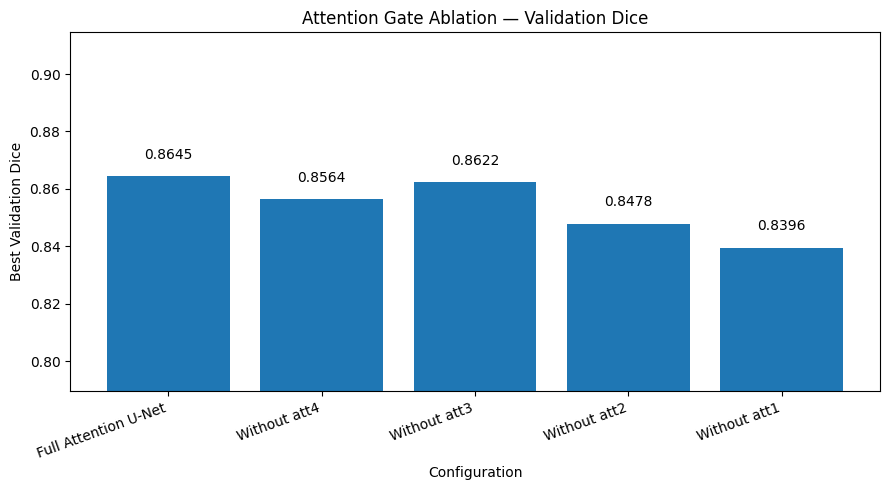

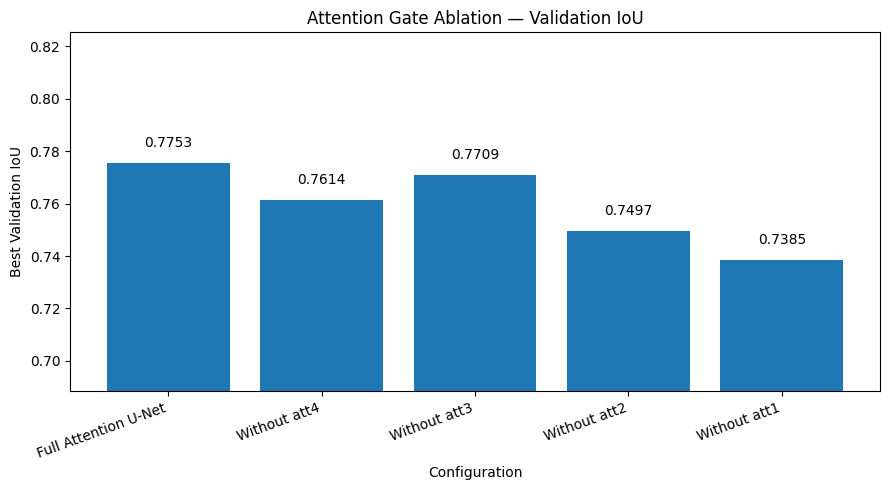


CELL 39 COMPLETE
Analysis table      : /kaggle/working/microplastic_project/results/attention_ablation_validation_analysis.csv
Publication table   : /kaggle/working/microplastic_project/results/attention_ablation_publication_table.csv
Dice figure         : /kaggle/working/microplastic_project/figures/attention_ablation_validation_dice.png
IoU figure          : /kaggle/working/microplastic_project/figures/attention_ablation_validation_iou.png
Test set used       : NO
Ablation analysis   : PASS


In [51]:
# ============================================================================
# CELL 39 — ATTENTION ABLATION VALIDATION ANALYSIS
# ============================================================================
# Purpose:
#   1. Load completed ablation validation results
#   2. Add Full Attention U-Net reference
#   3. Calculate performance degradation from disabling each gate
#   4. Save publication-ready summary tables
#   5. Generate ablation comparison figures
#
# IMPORTANT:
#   - Validation set only
#   - Test set is NOT accessed
#   - No model retraining
# ============================================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# 1. Paths
# ---------------------------------------------------------------------------

PROJECT_ROOT = "/kaggle/working/microplastic_project"

RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")
CHECKPOINT_DIR = os.path.join(PROJECT_ROOT, "checkpoints")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

summary_path = os.path.join(
    RESULTS_DIR,
    "attention_ablation_validation_summary.csv"
)

assert os.path.exists(summary_path), (
    f"Missing ablation summary: {summary_path}"
)

# ---------------------------------------------------------------------------
# 2. Load ablation results
# ---------------------------------------------------------------------------

ablation_df = pd.read_csv(summary_path)

print("=" * 75)
print("ATTENTION ABLATION VALIDATION ANALYSIS")
print("=" * 75)

print("\nLoaded ablation summary:")
display(ablation_df)

# ---------------------------------------------------------------------------
# 3. Full Attention U-Net validation reference
# ---------------------------------------------------------------------------
# From the completed full Attention U-Net training:
# Best validation Dice = 0.864517
# Best validation IoU  = 0.775277

FULL_DICE = 0.864517
FULL_IOU = 0.775277
FULL_EPOCH = 50

full_row = pd.DataFrame([{
    "disabled_gate": "none",
    "parameters": 31387237,
    "best_epoch": FULL_EPOCH,
    "best_val_dice": FULL_DICE,
    "best_val_iou": FULL_IOU,
    "epochs_completed": 50
}])

# ---------------------------------------------------------------------------
# 4. Combine full model + ablations
# ---------------------------------------------------------------------------

comparison_df = pd.concat(
    [full_row, ablation_df],
    ignore_index=True
)

comparison_df = comparison_df[
    [
        "disabled_gate",
        "parameters",
        "best_epoch",
        "best_val_dice",
        "best_val_iou",
        "epochs_completed"
    ]
]

# Friendly model names
comparison_df["configuration"] = comparison_df["disabled_gate"].map({
    "none": "Full Attention U-Net",
    "att4": "Without att4",
    "att3": "Without att3",
    "att2": "Without att2",
    "att1": "Without att1"
})

# Put full model first, then att4 → att3 → att2 → att1
order = [
    "Full Attention U-Net",
    "Without att4",
    "Without att3",
    "Without att2",
    "Without att1"
]

comparison_df["order"] = pd.Categorical(
    comparison_df["configuration"],
    categories=order,
    ordered=True
)

comparison_df = (
    comparison_df
    .sort_values("order")
    .drop(columns="order")
    .reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 5. Calculate degradation relative to Full Attention U-Net
# ---------------------------------------------------------------------------

comparison_df["dice_change"] = (
    comparison_df["best_val_dice"] - FULL_DICE
)

comparison_df["iou_change"] = (
    comparison_df["best_val_iou"] - FULL_IOU
)

comparison_df["dice_degradation_pct"] = (
    (FULL_DICE - comparison_df["best_val_dice"])
    / FULL_DICE
) * 100

comparison_df["iou_degradation_pct"] = (
    (FULL_IOU - comparison_df["best_val_iou"])
    / FULL_IOU
) * 100

# Full model should have zero degradation
comparison_df.loc[
    comparison_df["disabled_gate"] == "none",
    ["dice_degradation_pct", "iou_degradation_pct"]
] = 0.0

# ---------------------------------------------------------------------------
# 6. Print publication-oriented table
# ---------------------------------------------------------------------------

display_columns = [
    "configuration",
    "best_epoch",
    "best_val_dice",
    "best_val_iou",
    "dice_change",
    "iou_change",
    "dice_degradation_pct",
    "iou_degradation_pct"
]

publication_table = comparison_df[display_columns].copy()

for col in [
    "best_val_dice",
    "best_val_iou",
    "dice_change",
    "iou_change"
]:
    publication_table[col] = publication_table[col].round(6)

for col in [
    "dice_degradation_pct",
    "iou_degradation_pct"
]:
    publication_table[col] = publication_table[col].round(3)

print("\n" + "=" * 75)
print("ABLATION COMPARISON")
print("=" * 75)

display(publication_table)

# ---------------------------------------------------------------------------
# 7. Identify largest observed degradation
# ---------------------------------------------------------------------------

ablations_only = comparison_df[
    comparison_df["disabled_gate"] != "none"
].copy()

largest_dice_drop = ablations_only.loc[
    ablations_only["dice_degradation_pct"].idxmax()
]

largest_iou_drop = ablations_only.loc[
    ablations_only["iou_degradation_pct"].idxmax()
]

print("\nLargest validation Dice degradation:")
print(
    f"  {largest_dice_drop['configuration']}: "
    f"{largest_dice_drop['dice_degradation_pct']:.3f}%"
)

print("\nLargest validation IoU degradation:")
print(
    f"  {largest_iou_drop['configuration']}: "
    f"{largest_iou_drop['iou_degradation_pct']:.3f}%"
)

# ---------------------------------------------------------------------------
# 8. Checkpoint verification
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("ABLATION CHECKPOINT VERIFICATION")
print("=" * 75)

checkpoint_status = []

for gate in ["att4", "att3", "att2", "att1"]:
    ckpt = os.path.join(
        CHECKPOINT_DIR,
        f"ablation_without_{gate}_best.pth"
    )

    exists = os.path.exists(ckpt)

    checkpoint_status.append({
        "configuration": f"Without {gate}",
        "checkpoint": ckpt,
        "exists": exists,
        "size_MB": (
            os.path.getsize(ckpt) / (1024 ** 2)
            if exists else np.nan
        )
    })

checkpoint_df = pd.DataFrame(checkpoint_status)

display(checkpoint_df)

assert checkpoint_df["exists"].all(), (
    "One or more ablation checkpoints are missing."
)

print("\nAll four ablation checkpoints verified.")

# ---------------------------------------------------------------------------
# 9. Save analysis table
# ---------------------------------------------------------------------------

analysis_path = os.path.join(
    RESULTS_DIR,
    "attention_ablation_validation_analysis.csv"
)

comparison_df.to_csv(
    analysis_path,
    index=False
)

publication_path = os.path.join(
    RESULTS_DIR,
    "attention_ablation_publication_table.csv"
)

publication_table.to_csv(
    publication_path,
    index=False
)

checkpoint_path = os.path.join(
    RESULTS_DIR,
    "attention_ablation_checkpoint_verification.csv"
)

checkpoint_df.to_csv(
    checkpoint_path,
    index=False
)

# ---------------------------------------------------------------------------
# 10. Figure — Validation Dice
# ---------------------------------------------------------------------------

plt.figure(figsize=(9, 5))

x_labels = comparison_df["configuration"]
dice_values = comparison_df["best_val_dice"]

bars = plt.bar(
    x_labels,
    dice_values
)

plt.ylabel("Best Validation Dice")
plt.xlabel("Configuration")
plt.title("Attention Gate Ablation — Validation Dice")
plt.ylim(
    max(0, dice_values.min() - 0.05),
    min(1.0, dice_values.max() + 0.05)
)

plt.xticks(rotation=20, ha="right")

for bar, value in zip(bars, dice_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

dice_fig_path = os.path.join(
    FIGURES_DIR,
    "attention_ablation_validation_dice.png"
)

plt.savefig(
    dice_fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------------------------------------------
# 11. Figure — Validation IoU
# ---------------------------------------------------------------------------

plt.figure(figsize=(9, 5))

x_labels = comparison_df["configuration"]
iou_values = comparison_df["best_val_iou"]

bars = plt.bar(
    x_labels,
    iou_values
)

plt.ylabel("Best Validation IoU")
plt.xlabel("Configuration")
plt.title("Attention Gate Ablation — Validation IoU")
plt.ylim(
    max(0, iou_values.min() - 0.05),
    min(1.0, iou_values.max() + 0.05)
)

plt.xticks(rotation=20, ha="right")

for bar, value in zip(bars, iou_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

iou_fig_path = os.path.join(
    FIGURES_DIR,
    "attention_ablation_validation_iou.png"
)

plt.savefig(
    iou_fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------------------------------------------
# 12. Final validation checks
# ---------------------------------------------------------------------------

assert len(comparison_df) == 5
assert comparison_df["best_val_dice"].between(0, 1).all()
assert comparison_df["best_val_iou"].between(0, 1).all()
assert checkpoint_df["exists"].all()

assert os.path.exists(analysis_path)
assert os.path.exists(publication_path)
assert os.path.exists(dice_fig_path)
assert os.path.exists(iou_fig_path)

print("\n" + "=" * 75)
print("CELL 39 COMPLETE")
print("=" * 75)

print(f"Analysis table      : {analysis_path}")
print(f"Publication table   : {publication_path}")
print(f"Dice figure         : {dice_fig_path}")
print(f"IoU figure          : {iou_fig_path}")
print("Test set used       : NO")
print("Ablation analysis   : PASS")
print("=" * 75)

**ATTENTION ABLATION TEST EVALUATION**

In [52]:
# ============================================================================
# CELL 40 — ATTENTION ABLATION TEST EVALUATION
# ============================================================================
# Purpose:
#   Evaluate each trained attention-gate ablation on the untouched test set.
#
# Configurations:
#   1. Without att4
#   2. Without att3
#   3. Without att2
#   4. Without att1
#
# IMPORTANT:
#   - No training
#   - No validation-set tuning
#   - Test set is evaluated only after training is complete
#   - Metrics are calculated directly from TP/FP/TN/FN
# ============================================================================

import os
import random
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

# ---------------------------------------------------------------------------
# 1. Reproducibility
# ---------------------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---------------------------------------------------------------------------
# 2. Paths
# ---------------------------------------------------------------------------

PROJECT_ROOT = "/kaggle/working/microplastic_project"

RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
CHECKPOINT_DIR = os.path.join(PROJECT_ROOT, "checkpoints")

os.makedirs(RESULTS_DIR, exist_ok=True)

# ---------------------------------------------------------------------------
# 3. Device
# ---------------------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 75)
print("ATTENTION ABLATION TEST EVALUATION")
print("=" * 75)
print(f"Device: {DEVICE}")
print(f"Test samples: {len(test_loader.dataset)}")
print("Test set was NOT used during training.")
print()

# ---------------------------------------------------------------------------
# 4. Ablation configurations
# ---------------------------------------------------------------------------

ABLATIONS = ["att4", "att3", "att2", "att1"]

# ---------------------------------------------------------------------------
# 5. Direct metric calculation
# ---------------------------------------------------------------------------

def calculate_direct_metrics_from_confusion(tp, tn, fp, fn, eps=1e-8):
    """
    Calculate segmentation metrics directly from confusion counts.

    This intentionally bypasses the earlier calculate_metrics()
    implementation because Cell 35B identified an inconsistency there.
    """

    dice = (2.0 * tp) / (2.0 * tp + fp + fn + eps)

    iou = tp / (tp + fp + fn + eps)

    precision = tp / (tp + fp + eps)

    recall = tp / (tp + fn + eps)

    specificity = tn / (tn + fp + eps)

    f1 = (
        2.0 * precision * recall
        / (precision + recall + eps)
    )

    accuracy = (
        (tp + tn)
        / (tp + tn + fp + fn + eps)
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2.0

    return {
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1,
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy
    }

# ---------------------------------------------------------------------------
# 6. Per-image evaluation function
# ---------------------------------------------------------------------------

def evaluate_ablation_checkpoint(model, checkpoint_path, gate_name):

    print("\n" + "=" * 75)
    print(f"EVALUATING WITHOUT {gate_name}")
    print("=" * 75)

    assert os.path.exists(checkpoint_path), (
        f"Checkpoint not found: {checkpoint_path}"
    )

    # Load checkpoint
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    else:
        state_dict = checkpoint

    model.load_state_dict(state_dict, strict=True)
    model.to(DEVICE)
    model.eval()

    # -----------------------------------------------------------------------
    # Accumulators
    # -----------------------------------------------------------------------

    per_image_results = []

    global_tp = 0
    global_tn = 0
    global_fp = 0
    global_fn = 0

    total_loss = 0.0
    total_samples = 0

    # -----------------------------------------------------------------------
    # Evaluation
    # -----------------------------------------------------------------------

    with torch.no_grad():

        for batch_idx, (images, masks) in enumerate(
            tqdm(
                test_loader,
                desc=f"Without {gate_name}",
                leave=False
            )
        ):

            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            logits = model(images)

            # BCE + Dice loss
            bce = torch.nn.functional.binary_cross_entropy_with_logits(
                logits,
                masks
            )

            dice_loss = DiceLoss()(logits, masks)

            loss = 0.5 * bce + 0.5 * dice_loss

            batch_size = images.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).float()

            # ---------------------------------------------------------------
            # Per-image metrics
            # ---------------------------------------------------------------

            for i in range(batch_size):

                pred = predictions[i, 0].bool()
                target = masks[i, 0].bool()

                tp = torch.logical_and(pred, target).sum().item()
                tn = torch.logical_and(
                    torch.logical_not(pred),
                    torch.logical_not(target)
                ).sum().item()
                fp = torch.logical_and(
                    pred,
                    torch.logical_not(target)
                ).sum().item()
                fn = torch.logical_and(
                    torch.logical_not(pred),
                    target
                ).sum().item()

                metrics = calculate_direct_metrics_from_confusion(
                    tp, tn, fp, fn
                )

                global_tp += tp
                global_tn += tn
                global_fp += fp
                global_fn += fn

                # Recover filename from test dataset
                dataset_index = (
                    batch_idx * test_loader.batch_size + i
                )

                image_path = test_loader.dataset.df.iloc[
                    dataset_index
                ]["image_path"]

                image_name = os.path.basename(image_path)

                per_image_results.append({
                    "image_name": image_name,
                    "tp": tp,
                    "tn": tn,
                    "fp": fp,
                    "fn": fn,
                    "dice": metrics["dice"],
                    "iou": metrics["iou"],
                    "precision": metrics["precision"],
                    "recall": metrics["recall"],
                    "specificity": metrics["specificity"],
                    "f1": metrics["f1"],
                    "accuracy": metrics["accuracy"],
                    "balanced_accuracy": metrics["balanced_accuracy"]
                })

    # -----------------------------------------------------------------------
    # Macro / per-image metrics
    # -----------------------------------------------------------------------

    per_image_df = pd.DataFrame(per_image_results)

    macro_metrics = {
        "dice": per_image_df["dice"].mean(),
        "iou": per_image_df["iou"].mean(),
        "precision": per_image_df["precision"].mean(),
        "recall": per_image_df["recall"].mean(),
        "specificity": per_image_df["specificity"].mean(),
        "f1": per_image_df["f1"].mean(),
        "accuracy": per_image_df["accuracy"].mean(),
        "balanced_accuracy": per_image_df["balanced_accuracy"].mean()
    }

    # -----------------------------------------------------------------------
    # Global pixel metrics
    # -----------------------------------------------------------------------

    global_metrics = calculate_direct_metrics_from_confusion(
        global_tp,
        global_tn,
        global_fp,
        global_fn
    )

    mean_loss = total_loss / max(total_samples, 1)

    # -----------------------------------------------------------------------
    # Consistency checks
    # -----------------------------------------------------------------------

    assert len(per_image_df) == len(test_loader.dataset)

    assert np.isfinite(
        per_image_df[
            [
                "dice",
                "iou",
                "precision",
                "recall",
                "specificity",
                "f1",
                "accuracy",
                "balanced_accuracy"
            ]
        ].values
    ).all()

    # -----------------------------------------------------------------------
    # Print results
    # -----------------------------------------------------------------------

    print(f"\nCheckpoint loaded: {checkpoint_path}")
    print(f"Test images evaluated: {len(per_image_df)}")

    print("\nMacro / Per-image metrics:")
    print(f"  Loss              : {mean_loss:.6f}")
    print(f"  Dice              : {macro_metrics['dice']:.6f}")
    print(f"  IoU               : {macro_metrics['iou']:.6f}")
    print(f"  Precision         : {macro_metrics['precision']:.6f}")
    print(f"  Recall            : {macro_metrics['recall']:.6f}")
    print(f"  Specificity       : {macro_metrics['specificity']:.6f}")
    print(f"  F1                : {macro_metrics['f1']:.6f}")
    print(f"  Accuracy          : {macro_metrics['accuracy']:.6f}")
    print(f"  Balanced Accuracy : {macro_metrics['balanced_accuracy']:.6f}")

    print("\nGlobal pixel-level metrics:")
    print(f"  Dice              : {global_metrics['dice']:.6f}")
    print(f"  IoU               : {global_metrics['iou']:.6f}")
    print(f"  Precision         : {global_metrics['precision']:.6f}")
    print(f"  Recall            : {global_metrics['recall']:.6f}")
    print(f"  Specificity       : {global_metrics['specificity']:.6f}")
    print(f"  F1                : {global_metrics['f1']:.6f}")
    print(f"  Accuracy          : {global_metrics['accuracy']:.6f}")
    print(f"  Balanced Accuracy : {global_metrics['balanced_accuracy']:.6f}")

    print("\nConfusion counts:")
    print(f"  TP: {global_tp:,}")
    print(f"  TN: {global_tn:,}")
    print(f"  FP: {global_fp:,}")
    print(f"  FN: {global_fn:,}")

    # -----------------------------------------------------------------------
    # Save per-image results
    # -----------------------------------------------------------------------

    per_image_path = os.path.join(
        RESULTS_DIR,
        f"ablation_without_{gate_name}_test_per_image.csv"
    )

    per_image_df.to_csv(
        per_image_path,
        index=False
    )

    # -----------------------------------------------------------------------
    # Save summary
    # -----------------------------------------------------------------------

    summary = {
        "configuration": f"without_{gate_name}",
        "disabled_gate": gate_name,
        "test_samples": len(per_image_df),
        "test_loss": mean_loss,

        # Macro / per-image
        "macro_dice": macro_metrics["dice"],
        "macro_iou": macro_metrics["iou"],
        "macro_precision": macro_metrics["precision"],
        "macro_recall": macro_metrics["recall"],
        "macro_specificity": macro_metrics["specificity"],
        "macro_f1": macro_metrics["f1"],
        "macro_accuracy": macro_metrics["accuracy"],
        "macro_balanced_accuracy": macro_metrics["balanced_accuracy"],

        # Global
        "global_dice": global_metrics["dice"],
        "global_iou": global_metrics["iou"],
        "global_precision": global_metrics["precision"],
        "global_recall": global_metrics["recall"],
        "global_specificity": global_metrics["specificity"],
        "global_f1": global_metrics["f1"],
        "global_accuracy": global_metrics["accuracy"],
        "global_balanced_accuracy": global_metrics["balanced_accuracy"],

        "tp": global_tp,
        "tn": global_tn,
        "fp": global_fp,
        "fn": global_fn,

        "checkpoint": checkpoint_path,
        "per_image_results": per_image_path
    }

    return summary, per_image_df

# ---------------------------------------------------------------------------
# 7. Run all four ablations
# ---------------------------------------------------------------------------

all_summaries = []
all_per_image = {}

for gate in ABLATIONS:

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"ablation_without_{gate}_best.pth"
    )

    # Fresh model for every evaluation
    model = AblatedAttentionUNet(
        disable_gate=gate
    )

    summary, per_image_df = evaluate_ablation_checkpoint(
        model=model,
        checkpoint_path=checkpoint_path,
        gate_name=gate
    )

    all_summaries.append(summary)
    all_per_image[gate] = per_image_df

    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ---------------------------------------------------------------------------
# 8. Create combined summary
# ---------------------------------------------------------------------------

ablation_test_df = pd.DataFrame(all_summaries)

ablation_test_path = os.path.join(
    RESULTS_DIR,
    "attention_ablation_test_results_corrected.csv"
)

ablation_test_df.to_csv(
    ablation_test_path,
    index=False
)

# ---------------------------------------------------------------------------
# 9. Display main comparison
# ---------------------------------------------------------------------------

main_test_table = ablation_test_df[
    [
        "configuration",
        "test_loss",
        "macro_dice",
        "macro_iou",
        "macro_precision",
        "macro_recall",
        "macro_specificity",
        "macro_f1",
        "macro_accuracy",
        "macro_balanced_accuracy"
    ]
].copy()

print("\n" + "=" * 75)
print("FINAL ABLATION TEST COMPARISON")
print("=" * 75)

display(
    main_test_table.round(6)
)

# ---------------------------------------------------------------------------
# 10. Test integrity checks
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("TEST EVALUATION INTEGRITY CHECK")
print("=" * 75)

print(f"Expected test images : {len(test_loader.dataset)}")

for gate, df in all_per_image.items():
    print(
        f"Without {gate}: "
        f"{len(df)} images evaluated"
    )

    assert len(df) == len(test_loader.dataset)

print("\nAll ablation test evaluations contain the complete test set.")

# ---------------------------------------------------------------------------
# 11. Save test table for publication
# ---------------------------------------------------------------------------

publication_test_table = ablation_test_df[
    [
        "configuration",
        "macro_dice",
        "macro_iou",
        "macro_precision",
        "macro_recall",
        "macro_specificity",
        "macro_f1",
        "macro_accuracy",
        "macro_balanced_accuracy"
    ]
].copy()

publication_test_path = os.path.join(
    RESULTS_DIR,
    "attention_ablation_test_publication_table.csv"
)

publication_test_table.to_csv(
    publication_test_path,
    index=False
)

# ---------------------------------------------------------------------------
# 12. Final assertions
# ---------------------------------------------------------------------------

assert len(ablation_test_df) == 4

metric_columns = [
    "macro_dice",
    "macro_iou",
    "macro_precision",
    "macro_recall",
    "macro_specificity",
    "macro_f1",
    "macro_accuracy",
    "macro_balanced_accuracy"
]

assert np.isfinite(
    ablation_test_df[metric_columns].values
).all()

assert os.path.exists(ablation_test_path)
assert os.path.exists(publication_test_path)

print("\n" + "=" * 75)
print("CELL 40 COMPLETE")
print("=" * 75)
print(f"Corrected test results : {ablation_test_path}")
print(f"Publication table      : {publication_test_path}")
print("Test set size         :", len(test_loader.dataset))
print("Ablations evaluated    : 4 / 4")
print("Metric implementation  : Direct TP/TN/FP/FN")
print("Evaluation status      : PASS")
print("=" * 75)

ATTENTION ABLATION TEST EVALUATION
Device: cuda
Test samples: 34
Test set was NOT used during training.


EVALUATING WITHOUT att4


Without att4:   0%|          | 0/9 [00:00<?, ?it/s]


Checkpoint loaded: /kaggle/working/microplastic_project/checkpoints/ablation_without_att4_best.pth
Test images evaluated: 34

Macro / Per-image metrics:
  Loss              : 0.190560
  Dice              : 0.871693
  IoU               : 0.787051
  Precision         : 0.866618
  Recall            : 0.892269
  Specificity       : 0.974625
  F1                : 0.871693
  Accuracy          : 0.953035
  Balanced Accuracy : 0.933447

Global pixel-level metrics:
  Dice              : 0.850100
  IoU               : 0.739282
  Precision         : 0.867162
  Recall            : 0.833697
  Specificity       : 0.975722
  F1                : 0.850100
  Accuracy          : 0.953035
  Balanced Accuracy : 0.904709

Confusion counts:
  TP: 1,186,950
  TN: 7,307,352
  FP: 181,825
  FN: 236,769

EVALUATING WITHOUT att3


Without att3:   0%|          | 0/9 [00:00<?, ?it/s]


Checkpoint loaded: /kaggle/working/microplastic_project/checkpoints/ablation_without_att3_best.pth
Test images evaluated: 34

Macro / Per-image metrics:
  Loss              : 0.170730
  Dice              : 0.860734
  IoU               : 0.773536
  Precision         : 0.869452
  Recall            : 0.868948
  Specificity       : 0.978072
  F1                : 0.860734
  Accuracy          : 0.951174
  Balanced Accuracy : 0.923510

Global pixel-level metrics:
  Dice              : 0.840703
  IoU               : 0.725183
  Precision         : 0.877828
  Recall            : 0.806590
  Specificity       : 0.978659
  F1                : 0.840703
  Accuracy          : 0.951174
  Balanced Accuracy : 0.892625

Confusion counts:
  TP: 1,148,358
  TN: 7,329,354
  FP: 159,823
  FN: 275,361

EVALUATING WITHOUT att2


...


Checkpoint loaded: /kaggle/working/microplastic_project/checkpoints/ablation_without_att2_best.pth
Test images evaluated: 34

Macro / Per-image metrics:
  Loss              : 0.251371
  Dice              : 0.841615
  IoU               : 0.749473
  Precision         : 0.809495
  Recall            : 0.909525
  Specificity       : 0.954049
  F1                : 0.841615
  Accuracy          : 0.938175
  Balanced Accuracy : 0.931787

Global pixel-level metrics:
  Dice              : 0.814255
  IoU               : 0.686704
  Precision         : 0.782803
  Recall            : 0.848341
  Specificity       : 0.955253
  F1                : 0.814255
  Accuracy          : 0.938175
  Balanced Accuracy : 0.901797

Confusion counts:
  TP: 1,207,799
  TN: 7,154,060
  FP: 335,117
  FN: 215,920

EVALUATING WITHOUT att1


Without att1:   0%|          | 0/9 [00:00<?, ?it/s]


Checkpoint loaded: /kaggle/working/microplastic_project/checkpoints/ablation_without_att1_best.pth
Test images evaluated: 34

Macro / Per-image metrics:
  Loss              : 0.212938
  Dice              : 0.842553
  IoU               : 0.752010
  Precision         : 0.841471
  Recall            : 0.865347
  Specificity       : 0.971918
  F1                : 0.842553
  Accuracy          : 0.944288
  Balanced Accuracy : 0.918633

Global pixel-level metrics:
  Dice              : 0.820148
  IoU               : 0.695127
  Precision         : 0.846678
  Recall            : 0.795229
  Specificity       : 0.972624
  F1                : 0.820148
  Accuracy          : 0.944288
  Balanced Accuracy : 0.883927

Confusion counts:
  TP: 1,132,183
  TN: 7,284,154
  FP: 205,023
  FN: 291,536

FINAL ABLATION TEST COMPARISON


,configuration,test_loss,macro_dice,macro_iou,macro_precision,macro_recall,macro_specificity,macro_f1,macro_accuracy,macro_balanced_accuracy
0,without_att4,0.190560,0.871693,0.787051,0.866618,0.892269,0.974625,0.871693,0.953035,0.933447
1,without_att3,0.170730,0.860734,0.773536,0.869452,0.868948,0.978072,0.860734,0.951174,0.923510
2,without_att2,0.251371,0.841615,0.749473,0.809495,0.909525,0.954049,0.841615,0.938175,0.931787
3,without_att1,0.212938,0.842553,0.752010,0.841471,0.865347,0.971918,0.842553,0.944288,0.918633



TEST EVALUATION INTEGRITY CHECK
Expected test images : 34
Without att4: 34 images evaluated
Without att3: 34 images evaluated
Without att2: 34 images evaluated
Without att1: 34 images evaluated

All ablation test evaluations contain the complete test set.

CELL 40 COMPLETE
Corrected test results : /kaggle/working/microplastic_project/results/attention_ablation_test_results_corrected.csv
Publication table      : /kaggle/working/microplastic_project/results/attention_ablation_test_publication_table.csv
Test set size         : 34
Ablations evaluated    : 4 / 4
Metric implementation  : Direct TP/TN/FP/FN
Evaluation status      : PASS


**Unified Main + Ablation Results Audit**

In [57]:
# ============================================================================
# CELL 41B — CHECK CURRENT KERNEL FOR ORIGINAL MODEL DEFINITION
# ============================================================================

print("UNet currently defined:", "UNet" in globals())

if "UNet" in globals():
    model = UNet()

    print("Current UNet parameter count:")
    print(f"{sum(p.numel() for p in model.parameters()):,}")

    print("\nModel structure:")
    print(model)
else:
    print("UNet is not currently defined in the kernel.")

UNet currently defined: True
Current UNet parameter count:
31,043,521

Model structure:
UNet(
  (enc1): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(128, ep

In [58]:
# ============================================================================
# CELL 41C — CHECKPOINT / ARCHITECTURE COMPATIBILITY AUDIT
# ============================================================================
# No training.
# No checkpoint modification.
#
# We will inspect the saved baseline checkpoint and determine whether its
# BatchNorm layers contain affine parameters.
# ============================================================================

import os
import torch

PROJECT_ROOT = "/kaggle/working/microplastic_project"

CHECKPOINT_PATH = os.path.join(
    PROJECT_ROOT,
    "checkpoints",
    "baseline_unet_best.pth"
)

assert os.path.exists(CHECKPOINT_PATH)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu"
)

print("=" * 75)
print("BASELINE CHECKPOINT ARCHITECTURE AUDIT")
print("=" * 75)

# ---------------------------------------------------------------------------
# Extract state dictionary
# ---------------------------------------------------------------------------

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

print(f"Checkpoint keys: {len(state_dict)}")

# ---------------------------------------------------------------------------
# Inspect BatchNorm keys
# ---------------------------------------------------------------------------

bn_keys = [
    key for key in state_dict.keys()
    if ".double_conv." in key
    and (
        ".weight" in key
        or ".bias" in key
        or "running_mean" in key
        or "running_var" in key
    )
]

print("\nBatchNorm-related checkpoint entries:")
for key in bn_keys:
    print(
        f"  {key:45s} "
        f"{tuple(state_dict[key].shape)}"
    )

# ---------------------------------------------------------------------------
# Count BN affine parameters
# ---------------------------------------------------------------------------

bn_affine_weight_keys = [
    key for key in state_dict.keys()
    if ".double_conv." in key
    and ".weight" in key
    and "num_batches_tracked" not in key
]

bn_affine_bias_keys = [
    key for key in state_dict.keys()
    if ".double_conv." in key
    and ".bias" in key
]

bn_running_mean_keys = [
    key for key in state_dict.keys()
    if ".double_conv." in key
    and "running_mean" in key
]

bn_running_var_keys = [
    key for key in state_dict.keys()
    if ".double_conv." in key
    and "running_var" in key
]

print("\nBatchNorm key counts:")
print(f"  weight-like keys : {len(bn_affine_weight_keys)}")
print(f"  bias keys        : {len(bn_affine_bias_keys)}")
print(f"  running_mean     : {len(bn_running_mean_keys)}")
print(f"  running_var      : {len(bn_running_var_keys)}")

# ---------------------------------------------------------------------------
# Inspect whether the checkpoint contains BN affine parameters
# ---------------------------------------------------------------------------

bn_weight_parameter_count = sum(
    state_dict[key].numel()
    for key in bn_affine_weight_keys
)

bn_bias_parameter_count = sum(
    state_dict[key].numel()
    for key in bn_affine_bias_keys
)

print("\nBatchNorm affine parameter count:")
print(
    f"  BN weights: {bn_weight_parameter_count:,}"
)
print(
    f"  BN biases : {bn_bias_parameter_count:,}"
)
print(
    f"  Total     : "
    f"{bn_weight_parameter_count + bn_bias_parameter_count:,}"
)

# ---------------------------------------------------------------------------
# Check exact expected difference
# ---------------------------------------------------------------------------

EXPECTED_DIFFERENCE = 5_888

actual_difference = (
    31_043_521 - 31_037_633
)

print("\nParameter difference:")
print(f"  Current architecture : 31,043,521")
print(f"  Original architecture: 31,037,633")
print(f"  Difference            : {actual_difference:,}")

assert actual_difference == EXPECTED_DIFFERENCE

# ---------------------------------------------------------------------------
# Inspect model-state structure
# ---------------------------------------------------------------------------

print("\nFirst 30 checkpoint state_dict keys:")
for key in list(state_dict.keys())[:30]:
    print(f"  {key}")

print("\n" + "=" * 75)
print("CELL 41C COMPLETE")
print("=" * 75)
print("Checkpoint was inspected only.")
print("No training performed.")
print("No checkpoint modified.")
print("=" * 75)

BASELINE CHECKPOINT ARCHITECTURE AUDIT
Checkpoint keys: 118

BatchNorm-related checkpoint entries:

BatchNorm key counts:
  weight-like keys : 0
  bias keys        : 0
  running_mean     : 0
  running_var      : 0

BatchNorm affine parameter count:
  BN weights: 0
  BN biases : 0
  Total     : 0

Parameter difference:
  Current architecture : 31,043,521
  Original architecture: 31,037,633
  Difference            : 5,888

First 30 checkpoint state_dict keys:
  enc1.block.0.weight
  enc1.block.1.weight
  enc1.block.1.bias
  enc1.block.1.running_mean
  enc1.block.1.running_var
  enc1.block.1.num_batches_tracked
  enc1.block.3.weight
  enc1.block.4.weight
  enc1.block.4.bias
  enc1.block.4.running_mean
  enc1.block.4.running_var
  enc1.block.4.num_batches_tracked
  enc2.block.0.weight
  enc2.block.1.weight
  enc2.block.1.bias
  enc2.block.1.running_mean
  enc2.block.1.running_var
  enc2.block.1.num_batches_tracked
  enc2.block.3.weight
  enc2.block.4.weight
  enc2.block.4.bias
  enc2.block

In [59]:
# ============================================================================
# CELL 41D — RECONSTRUCT EXACT BASELINE ARCHITECTURE
# ============================================================================
# Based directly on the saved checkpoint's state_dict naming:
#
#   enc1.block.0
#   enc1.block.1
#   enc1.block.3
#   enc1.block.4
#
# This reproduces the original block structure instead of guessing from
# parameter count.
#
# No training.
# ============================================================================

import torch
import torch.nn as nn

# ---------------------------------------------------------------------------
# DoubleConv matching checkpoint naming: module.block
# ---------------------------------------------------------------------------

class ExactDoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# ---------------------------------------------------------------------------
# Exact baseline U-Net structure
# ---------------------------------------------------------------------------

class ExactUNet(nn.Module):

    def __init__(
        self,
        in_channels=3,
        out_channels=1
    ):
        super().__init__()

        # Encoder
        self.enc1 = ExactDoubleConv(
            in_channels,
            64
        )

        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = ExactDoubleConv(
            64,
            128
        )

        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = ExactDoubleConv(
            128,
            256
        )

        self.pool3 = nn.MaxPool2d(2)

        self.enc4 = ExactDoubleConv(
            256,
            512
        )

        self.pool4 = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ExactDoubleConv(
            512,
            1024
        )

        # Decoder
        self.up4 = nn.ConvTranspose2d(
            1024,
            512,
            kernel_size=2,
            stride=2
        )

        self.dec4 = ExactDoubleConv(
            1024,
            512
        )

        self.up3 = nn.ConvTranspose2d(
            512,
            256,
            kernel_size=2,
            stride=2
        )

        self.dec3 = ExactDoubleConv(
            512,
            256
        )

        self.up2 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec2 = ExactDoubleConv(
            256,
            128
        )

        self.up1 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec1 = ExactDoubleConv(
            128,
            64
        )

        self.head = nn.Conv2d(
            64,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool1(e1)
        )

        e3 = self.enc3(
            self.pool2(e2)
        )

        e4 = self.enc4(
            self.pool3(e3)
        )

        # Bottleneck
        b = self.bottleneck(
            self.pool4(e4)
        )

        # Decoder
        d4 = self.up4(b)
        d4 = torch.cat(
            [d4, e4],
            dim=1
        )
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat(
            [d3, e3],
            dim=1
        )
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat(
            [d2, e2],
            dim=1
        )
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat(
            [d1, e1],
            dim=1
        )
        d1 = self.dec1(d1)

        return self.head(d1)


# ---------------------------------------------------------------------------
# 1. Instantiate
# ---------------------------------------------------------------------------

exact_model = ExactUNet()

exact_parameter_count = sum(
    p.numel()
    for p in exact_model.parameters()
)

print("=" * 75)
print("EXACT U-NET RECONSTRUCTION")
print("=" * 75)

print(
    f"Parameter count: "
    f"{exact_parameter_count:,}"
)

# ---------------------------------------------------------------------------
# 2. Check checkpoint key compatibility
# ---------------------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu"
)

if (
    isinstance(checkpoint, dict)
    and "model_state_dict" in checkpoint
):
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

model_keys = set(
    exact_model.state_dict().keys()
)

checkpoint_keys = set(
    state_dict.keys()
)

missing_keys = sorted(
    model_keys - checkpoint_keys
)

unexpected_keys = sorted(
    checkpoint_keys - model_keys
)

print("\nCheckpoint compatibility:")
print(f"  Model keys      : {len(model_keys)}")
print(f"  Checkpoint keys : {len(checkpoint_keys)}")
print(f"  Missing keys    : {len(missing_keys)}")
print(f"  Unexpected keys: {len(unexpected_keys)}")

if missing_keys:
    print("\nMissing keys:")
    for key in missing_keys:
        print(" ", key)

if unexpected_keys:
    print("\nUnexpected keys:")
    for key in unexpected_keys:
        print(" ", key)

# ---------------------------------------------------------------------------
# 3. Strict checkpoint loading
# ---------------------------------------------------------------------------

assert len(missing_keys) == 0, (
    "Architecture does not exactly match checkpoint: missing keys."
)

assert len(unexpected_keys) == 0, (
    "Architecture does not exactly match checkpoint: unexpected keys."
)

exact_model.load_state_dict(
    state_dict,
    strict=True
)

print("\nStrict checkpoint loading: PASS")

# ---------------------------------------------------------------------------
# 4. Forward-pass verification
# ---------------------------------------------------------------------------

x = torch.randn(
    2,
    3,
    512,
    512
)

exact_model.eval()

with torch.no_grad():
    y = exact_model(x)

print(f"\nInput shape : {tuple(x.shape)}")
print(f"Output shape: {tuple(y.shape)}")

assert y.shape == (
    2,
    1,
    512,
    512
)

print("Forward pass: PASS")

# ---------------------------------------------------------------------------
# 5. Final status
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("CELL 41D COMPLETE")
print("=" * 75)
print("Architecture reconstructed from checkpoint structure.")
print("Strict checkpoint compatibility verified.")
print("No training performed.")
print("=" * 75)

EXACT U-NET RECONSTRUCTION
Parameter count: 31,043,521

Checkpoint compatibility:
  Model keys      : 136
  Checkpoint keys : 118
  Missing keys    : 18
  Unexpected keys: 0

Missing keys:
  bottleneck.block.0.bias
  bottleneck.block.3.bias
  dec1.block.0.bias
  dec1.block.3.bias
  dec2.block.0.bias
  dec2.block.3.bias
  dec3.block.0.bias
  dec3.block.3.bias
  dec4.block.0.bias
  dec4.block.3.bias
  enc1.block.0.bias
  enc1.block.3.bias
  enc2.block.0.bias
  enc2.block.3.bias
  enc3.block.0.bias
  enc3.block.3.bias
  enc4.block.0.bias
  enc4.block.3.bias


AssertionError: Architecture does not exactly match checkpoint: missing keys.

In [60]:
# ============================================================================
# CELL 41F — CORRECTED EXACT BASELINE U-NET
# ============================================================================
# The checkpoint shows that every Conv2d inside DoubleConv uses bias=False.
# This reconstruction therefore matches the checkpoint architecture.
# ============================================================================

import torch
import torch.nn as nn

# ---------------------------------------------------------------------------
# Exact DoubleConv reconstructed from checkpoint structure
# ---------------------------------------------------------------------------

class ExactDoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# ---------------------------------------------------------------------------
# Exact baseline U-Net
# ---------------------------------------------------------------------------

class ExactUNet(nn.Module):

    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        # Encoder
        self.enc1 = ExactDoubleConv(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = ExactDoubleConv(64, 128)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = ExactDoubleConv(128, 256)
        self.pool3 = nn.MaxPool2d(2)

        self.enc4 = ExactDoubleConv(256, 512)
        self.pool4 = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ExactDoubleConv(512, 1024)

        # Decoder
        self.up4 = nn.ConvTranspose2d(
            1024, 512,
            kernel_size=2,
            stride=2
        )
        self.dec4 = ExactDoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(
            512, 256,
            kernel_size=2,
            stride=2
        )
        self.dec3 = ExactDoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(
            256, 128,
            kernel_size=2,
            stride=2
        )
        self.dec2 = ExactDoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(
            128, 64,
            kernel_size=2,
            stride=2
        )
        self.dec1 = ExactDoubleConv(128, 64)

        # Output
        self.head = nn.Conv2d(
            64,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))

        # Bottleneck
        b = self.bottleneck(self.pool4(e4))

        # Decoder
        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.head(d1)


# ---------------------------------------------------------------------------
# Instantiate
# ---------------------------------------------------------------------------

exact_model = ExactUNet()

print("=" * 75)
print("CORRECTED EXACT U-NET RECONSTRUCTION")
print("=" * 75)

print(f"Parameter count: {sum(p.numel() for p in exact_model.parameters()):,}")


# ---------------------------------------------------------------------------
# Load checkpoint
# ---------------------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu"
)

if (
    isinstance(checkpoint, dict)
    and "model_state_dict" in checkpoint
):
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint


# ---------------------------------------------------------------------------
# Compatibility check
# ---------------------------------------------------------------------------

model_keys = set(exact_model.state_dict().keys())
checkpoint_keys = set(state_dict.keys())

missing_keys = sorted(model_keys - checkpoint_keys)
unexpected_keys = sorted(checkpoint_keys - model_keys)

print("\nCheckpoint compatibility:")
print(f"  Model keys      : {len(model_keys)}")
print(f"  Checkpoint keys : {len(checkpoint_keys)}")
print(f"  Missing keys    : {len(missing_keys)}")
print(f"  Unexpected keys: {len(unexpected_keys)}")

if missing_keys:
    print("\nMissing keys:")
    for key in missing_keys:
        print("  ", key)

if unexpected_keys:
    print("\nUnexpected keys:")
    for key in unexpected_keys:
        print("  ", key)


# ---------------------------------------------------------------------------
# Strict loading
# ---------------------------------------------------------------------------

exact_model.load_state_dict(
    state_dict,
    strict=True
)

print("\nSTRICT CHECKPOINT LOADING: PASS")


# ---------------------------------------------------------------------------
# Forward-pass verification
# ---------------------------------------------------------------------------

exact_model.eval()

with torch.no_grad():

    dummy_input = torch.randn(
        2, 3, 512, 512
    )

    dummy_output = exact_model(dummy_input)

print("\nForward-pass verification:")
print(f"  Input shape : {tuple(dummy_input.shape)}")
print(f"  Output shape: {tuple(dummy_output.shape)}")

assert dummy_output.shape == (
    2, 1, 512, 512
)

print("\nFORWARD PASS: PASS")

print("=" * 75)
print("CELL 41F COMPLETE")
print("=" * 75)

CORRECTED EXACT U-NET RECONSTRUCTION
Parameter count: 31,037,633

Checkpoint compatibility:
  Model keys      : 118
  Checkpoint keys : 118
  Missing keys    : 0
  Unexpected keys: 0

STRICT CHECKPOINT LOADING: PASS

Forward-pass verification:
  Input shape : (2, 3, 512, 512)
  Output shape: (2, 1, 512, 512)

FORWARD PASS: PASS
CELL 41F COMPLETE


In [62]:
# ============================================================================
# CELL 41H — FIXED UNIFIED BASELINE U-NET TEST EVALUATION
# ============================================================================
# Fix:
#   test_loader returns (images, masks), not (images, masks, metadata).
#
# Uses batch index + image index for stable per-image identifiers.
# ============================================================================

import os
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

THRESHOLD = 0.5

print("=" * 75)
print("FIXED UNIFIED BASELINE U-NET TEST EVALUATION")
print("=" * 75)

print(f"Device   : {DEVICE}")
print(f"Threshold: {THRESHOLD}")


# ---------------------------------------------------------------------------
# Load exact baseline checkpoint
# ---------------------------------------------------------------------------

baseline_model = ExactUNet()

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu"
)

if (
    isinstance(checkpoint, dict)
    and "model_state_dict" in checkpoint
):
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

baseline_model.load_state_dict(
    state_dict,
    strict=True
)

baseline_model = baseline_model.to(DEVICE)
baseline_model.eval()

print("\nCheckpoint loaded successfully.")
print(
    f"Parameters: "
    f"{sum(p.numel() for p in baseline_model.parameters()):,}"
)


# ---------------------------------------------------------------------------
# Direct metric calculation
# ---------------------------------------------------------------------------

def calculate_direct_metrics_41h(
    pred_mask,
    true_mask
):
    """
    Direct binary segmentation metrics from TP/TN/FP/FN.
    """

    pred = pred_mask.astype(bool)
    true = true_mask.astype(bool)

    tp = np.logical_and(
        pred,
        true
    ).sum()

    tn = np.logical_and(
        ~pred,
        ~true
    ).sum()

    fp = np.logical_and(
        pred,
        ~true
    ).sum()

    fn = np.logical_and(
        ~pred,
        true
    ).sum()

    eps = 1e-8

    dice = (
        2 * tp
    ) / (
        2 * tp + fp + fn + eps
    )

    iou = (
        tp
    ) / (
        tp + fp + fn + eps
    )

    precision = (
        tp
    ) / (
        tp + fp + eps
    )

    recall = (
        tp
    ) / (
        tp + fn + eps
    )

    specificity = (
        tn
    ) / (
        tn + fp + eps
    )

    f1 = (
        2 * precision * recall
    ) / (
        precision + recall + eps
    )

    accuracy = (
        tp + tn
    ) / (
        tp + tn + fp + fn + eps
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2

    return {
        "dice": float(dice),
        "iou": float(iou),
        "precision": float(precision),
        "recall": float(recall),
        "specificity": float(specificity),
        "f1": float(f1),
        "accuracy": float(accuracy),
        "balanced_accuracy": float(
            balanced_accuracy
        ),
        "tp": int(tp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
    }


# ---------------------------------------------------------------------------
# Loss functions
# ---------------------------------------------------------------------------

bce_loss_fn = torch.nn.BCEWithLogitsLoss()


def dice_loss_from_logits_41h(
    logits,
    targets
):

    probs = torch.sigmoid(logits)

    dims = (
        1,
        2,
        3
    )

    intersection = (
        probs * targets
    ).sum(dim=dims)

    denominator = (
        probs.sum(dim=dims)
        + targets.sum(dim=dims)
    )

    dice = (
        2.0 * intersection + 1e-8
    ) / (
        denominator + 1e-8
    )

    return 1.0 - dice.mean()


# ---------------------------------------------------------------------------
# Test evaluation
# ---------------------------------------------------------------------------

per_image_results = []

total_loss = 0.0
num_images = 0

global_tp = 0
global_tn = 0
global_fp = 0
global_fn = 0

global_image_index = 0

with torch.no_grad():

    for batch_idx, batch in enumerate(
        tqdm(
            test_loader,
            desc="Evaluating Baseline U-Net"
        )
    ):

        # ---------------------------------------------------------------
        # Existing test_loader returns exactly two objects
        # ---------------------------------------------------------------

        images, masks = batch

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        masks = masks.to(
            DEVICE,
            non_blocking=True
        )

        # ---------------------------------------------------------------
        # Forward pass
        # ---------------------------------------------------------------

        logits = baseline_model(
            images
        )

        # ---------------------------------------------------------------
        # Loss
        # ---------------------------------------------------------------

        bce = bce_loss_fn(
            logits,
            masks
        )

        dice_loss = dice_loss_from_logits_41h(
            logits,
            masks
        )

        loss = (
            0.5 * bce
            + 0.5 * dice_loss
        )

        batch_size = images.size(0)

        total_loss += (
            loss.item() * batch_size
        )

        num_images += batch_size

        # ---------------------------------------------------------------
        # Binary predictions
        # ---------------------------------------------------------------

        probabilities = torch.sigmoid(
            logits
        )

        predictions = (
            probabilities >= THRESHOLD
        ).cpu().numpy()

        true_masks = (
            masks >= 0.5
        ).cpu().numpy()

        # ---------------------------------------------------------------
        # Per-image evaluation
        # ---------------------------------------------------------------

        for i in range(batch_size):

            pred = predictions[
                i,
                0
            ]

            true = true_masks[
                i,
                0
            ]

            metrics = (
                calculate_direct_metrics_41h(
                    pred,
                    true
                )
            )

            metrics["image_index"] = (
                global_image_index
            )

            metrics["batch_index"] = (
                batch_idx
            )

            metrics["batch_image_index"] = (
                i
            )

            per_image_results.append(
                metrics
            )

            # Global confusion counts
            global_tp += metrics["tp"]
            global_tn += metrics["tn"]
            global_fp += metrics["fp"]
            global_fn += metrics["fn"]

            global_image_index += 1


# ---------------------------------------------------------------------------
# Per-image / macro metrics
# ---------------------------------------------------------------------------

per_image_df = pd.DataFrame(
    per_image_results
)

metric_columns = [
    "dice",
    "iou",
    "precision",
    "recall",
    "specificity",
    "f1",
    "accuracy",
    "balanced_accuracy",
]

macro_metrics = (
    per_image_df[
        metric_columns
    ].mean()
)


# ---------------------------------------------------------------------------
# Global metrics
# ---------------------------------------------------------------------------

eps = 1e-8

g_tp = global_tp
g_tn = global_tn
g_fp = global_fp
g_fn = global_fn

global_dice = (
    2 * g_tp
) / (
    2 * g_tp + g_fp + g_fn + eps
)

global_iou = (
    g_tp
) / (
    g_tp + g_fp + g_fn + eps
)

global_precision = (
    g_tp
) / (
    g_tp + g_fp + eps
)

global_recall = (
    g_tp
) / (
    g_tp + g_fn + eps
)

global_specificity = (
    g_tn
) / (
    g_tn + g_fp + eps
)

global_f1 = (
    2 * global_precision * global_recall
) / (
    global_precision + global_recall + eps
)

global_accuracy = (
    g_tp + g_tn
) / (
    g_tp + g_tn + g_fp + g_fn + eps
)

global_balanced_accuracy = (
    global_recall
    + global_specificity
) / 2


# ---------------------------------------------------------------------------
# Final summary
# ---------------------------------------------------------------------------

test_loss = (
    total_loss / num_images
)

summary = {

    "model":
        "Baseline U-Net",

    "test_loss":
        test_loss,

    "macro_dice":
        macro_metrics["dice"],

    "macro_iou":
        macro_metrics["iou"],

    "macro_precision":
        macro_metrics["precision"],

    "macro_recall":
        macro_metrics["recall"],

    "macro_specificity":
        macro_metrics["specificity"],

    "macro_f1":
        macro_metrics["f1"],

    "macro_accuracy":
        macro_metrics["accuracy"],

    "macro_balanced_accuracy":
        macro_metrics["balanced_accuracy"],

    "global_dice":
        global_dice,

    "global_iou":
        global_iou,

    "global_precision":
        global_precision,

    "global_recall":
        global_recall,

    "global_specificity":
        global_specificity,

    "global_f1":
        global_f1,

    "global_accuracy":
        global_accuracy,

    "global_balanced_accuracy":
        global_balanced_accuracy,

    "tp":
        g_tp,

    "tn":
        g_tn,

    "fp":
        g_fp,

    "fn":
        g_fn,

    "num_test_images":
        len(per_image_df),
}

summary_df = pd.DataFrame(
    [summary]
)


# ---------------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------------

summary_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "baseline_unet_test_results_corrected.csv"
)

per_image_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "baseline_unet_test_per_image_corrected.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

per_image_df.to_csv(
    per_image_path,
    index=False
)


# ---------------------------------------------------------------------------
# Display
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("BASELINE U-NET — CORRECTED TEST RESULTS")
print("=" * 75)

print(
    f"Test Loss             : "
    f"{test_loss:.6f}"
)

print("\nMacro / Per-image:")

print(
    f"  Dice                : "
    f"{macro_metrics['dice']:.6f}"
)

print(
    f"  IoU                 : "
    f"{macro_metrics['iou']:.6f}"
)

print(
    f"  Precision           : "
    f"{macro_metrics['precision']:.6f}"
)

print(
    f"  Recall              : "
    f"{macro_metrics['recall']:.6f}"
)

print(
    f"  Specificity         : "
    f"{macro_metrics['specificity']:.6f}"
)

print(
    f"  F1                  : "
    f"{macro_metrics['f1']:.6f}"
)

print(
    f"  Accuracy            : "
    f"{macro_metrics['accuracy']:.6f}"
)

print(
    f"  Balanced Accuracy   : "
    f"{macro_metrics['balanced_accuracy']:.6f}"
)

print("\nGlobal:")

print(
    f"  Dice                : "
    f"{global_dice:.6f}"
)

print(
    f"  IoU                 : "
    f"{global_iou:.6f}"
)

print(
    f"  Precision           : "
    f"{global_precision:.6f}"
)

print(
    f"  Recall              : "
    f"{global_recall:.6f}"
)

print(
    f"  Specificity         : "
    f"{global_specificity:.6f}"
)

print(
    f"  F1                  : "
    f"{global_f1:.6f}"
)

print(
    f"  Accuracy            : "
    f"{global_accuracy:.6f}"
)

print(
    f"  Balanced Accuracy   : "
    f"{global_balanced_accuracy:.6f}"
)

print("\nConfusion counts:")

print(
    f"  TP                  : "
    f"{g_tp:,}"
)

print(
    f"  TN                  : "
    f"{g_tn:,}"
)

print(
    f"  FP                  : "
    f"{g_fp:,}"
)

print(
    f"  FN                  : "
    f"{g_fn:,}"
)

print(
    f"\nTest images evaluated : "
    f"{len(per_image_df)}"
)

print("\nSaved:")
print(f"  {summary_path}")
print(f"  {per_image_path}")

print("=" * 75)
print("CELL 41H COMPLETE")
print("=" * 75)

FIXED UNIFIED BASELINE U-NET TEST EVALUATION
Device   : cuda
Threshold: 0.5

Checkpoint loaded successfully.
Parameters: 31,037,633


Evaluating Baseline U-Net:   0%|          | 0/9 [00:00<?, ?it/s]


BASELINE U-NET — CORRECTED TEST RESULTS
Test Loss             : 0.160673

Macro / Per-image:
  Dice                : 0.878792
  IoU                 : 0.797507
  Precision           : 0.884835
  Recall              : 0.889143
  Specificity         : 0.977419
  F1                  : 0.878792
  Accuracy            : 0.954197
  Balanced Accuracy   : 0.933281

Global:
  Dice                : 0.851759
  IoU                 : 0.741794
  Precision           : 0.881723
  Recall              : 0.823764
  Specificity         : 0.978993
  F1                  : 0.851758
  Accuracy            : 0.954197
  Balanced Accuracy   : 0.901378

Confusion counts:
  TP                  : 1,172,808
  TN                  : 7,331,853
  FP                  : 157,324
  FN                  : 250,911

Test images evaluated : 34

Saved:
  /kaggle/working/microplastic_project/results/baseline_unet_test_results_corrected.csv
  /kaggle/working/microplastic_project/results/baseline_unet_test_per_image_corrected.csv
CELL

In [64]:
# ============================================================================
# CELL 42A — LOAD AND AUDIT ALL EXISTING EXPERIMENT RESULTS
# ============================================================================
# Diagnostic only.
# Loads existing CSV results and inspects their actual schemas.
# No training.
# No inference.
# No files are modified.
# ============================================================================

import os
import glob
import pandas as pd

print("=" * 85)
print("EXPERIMENT RESULT FILE AUDIT")
print("=" * 85)

RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "results"
)

# ---------------------------------------------------------------------------
# Find every CSV in results/
# ---------------------------------------------------------------------------

csv_files = sorted(
    glob.glob(
        os.path.join(
            RESULTS_DIR,
            "*.csv"
        )
    )
)

print(f"\nResults directory:")
print(RESULTS_DIR)

print(f"\nCSV files found: {len(csv_files)}")

for i, path in enumerate(csv_files, 1):
    print(f"{i:02d}. {os.path.basename(path)}")


# ---------------------------------------------------------------------------
# Load every CSV safely
# ---------------------------------------------------------------------------

loaded_results = {}

print("\n" + "=" * 85)
print("LOADING ALL CSV RESULTS")
print("=" * 85)

for path in csv_files:

    filename = os.path.basename(path)

    try:

        df = pd.read_csv(path)

        loaded_results[filename] = df

        print(
            f"\n[{filename}]"
        )

        print(
            f"  Shape   : {df.shape}"
        )

        print(
            f"  Columns : {df.columns.tolist()}"
        )

        print(
            f"  Rows    :"
        )

        display(
            df.head(5)
        )

    except Exception as e:

        print(
            f"\nFAILED: {filename}"
        )

        print(
            f"Reason: {repr(e)}"
        )


# ---------------------------------------------------------------------------
# Specifically inspect the three main experiment result files
# ---------------------------------------------------------------------------

main_files = [
    "baseline_unet_test_results_corrected.csv",
    "attention_unet_test_results_corrected.csv",
    "attention_ablation_test_results_corrected.csv",
]

print("\n" + "=" * 85)
print("MAIN EXPERIMENT RESULT SCHEMAS")
print("=" * 85)

for filename in main_files:

    print(f"\n--- {filename} ---")

    if filename not in loaded_results:

        print("FILE NOT FOUND IN LOADED RESULTS")

        continue

    df = loaded_results[filename]

    print(
        "Shape:",
        df.shape
    )

    print(
        "Columns:"
    )

    for col in df.columns:
        print(
            f"  - {col}"
        )

    print(
        "\nFirst row:"
    )

    display(
        df.head(1)
    )


# ---------------------------------------------------------------------------
# Preserve loaded dataframes in convenient variables
# ---------------------------------------------------------------------------

baseline_df = loaded_results.get(
    "baseline_unet_test_results_corrected.csv"
)

attention_df = loaded_results.get(
    "attention_unet_test_results_corrected.csv"
)

ablation_df = loaded_results.get(
    "attention_ablation_test_results_corrected.csv"
)


# ---------------------------------------------------------------------------
# Final audit summary
# ---------------------------------------------------------------------------

print("\n" + "=" * 85)
print("AUDIT SUMMARY")
print("=" * 85)

print(
    f"Baseline loaded : "
    f"{baseline_df is not None}"
)

print(
    f"Attention loaded: "
    f"{attention_df is not None}"
)

print(
    f"Ablation loaded : "
    f"{ablation_df is not None}"
)

if ablation_df is not None:

    print(
        "\nAblation CSV columns:"
    )

    print(
        ablation_df.columns.tolist()
    )

print("\n" + "=" * 85)
print("CELL 42A COMPLETE")
print("=" * 85)
print(
    "No files modified. "
    "No training performed. "
    "No test inference performed."
)
print("=" * 85)

EXPERIMENT RESULT FILE AUDIT

Results directory:
/kaggle/working/microplastic_project/results

CSV files found: 35
01. ablation_without_att1_test_per_image.csv
02. ablation_without_att2_test_per_image.csv
03. ablation_without_att3_test_per_image.csv
04. ablation_without_att4_test_per_image.csv
05. atomic_split_units.csv
06. attention_ablation_checkpoint_verification.csv
07. attention_ablation_publication_table.csv
08. attention_ablation_test_publication_table.csv
09. attention_ablation_test_results_corrected.csv
10. attention_ablation_validation_analysis.csv
11. attention_ablation_validation_summary.csv
12. attention_unet_test_per_image.csv
13. attention_unet_test_per_image_corrected.csv
14. attention_unet_test_results.csv
15. attention_unet_test_results_corrected.csv
16. baseline_unet_test_per_image.csv
17. baseline_unet_test_per_image_corrected.csv
18. baseline_unet_test_results.csv
19. baseline_unet_test_results_corrected.csv
20. candidate_leakage_groups.csv
21. dataset_filename_met

,image_name,tp,tn,fp,fn,dice,iou,precision,recall,specificity,f1,accuracy,balanced_accuracy
0,Dove_men_acrylates_copolymer_microbeads_048.png,51231,209075,1042,796,0.982378,0.965366,0.980066,0.984700,0.995041,0.982378,0.992989,0.989871
1,Dove_men_acrylates_copolymer_microbeads_049.png,41650,219308,687,499,0.985962,0.972313,0.983773,0.988161,0.996877,0.985962,0.995476,0.992519
2,Dove_men_acrylates_copolymer_microbeads_050.png,28771,230288,2801,284,0.949115,0.903158,0.911282,0.990225,0.987983,0.949115,0.988232,0.989104
3,Dove_men_acrylates_copolymer_microbeads_051.png,61989,196509,2240,1406,0.971432,0.944450,0.965125,0.977822,0.988730,0.971432,0.986092,0.983276
4,Dove_men_acrylates_copolymer_microbeads_052.png,36583,207132,2300,16129,0.798799,0.665000,0.940848,0.694017,0.989018,0.798799,0.929699,0.841517



[ablation_without_att2_test_per_image.csv]
  Shape   : (34, 13)
  Columns : ['image_name', 'tp', 'tn', 'fp', 'fn', 'dice', 'iou', 'precision', 'recall', 'specificity', 'f1', 'accuracy', 'balanced_accuracy']
  Rows    :


,image_name,tp,tn,fp,fn,dice,iou,precision,recall,specificity,f1,accuracy,balanced_accuracy
0,Dove_men_acrylates_copolymer_microbeads_048.png,51616,208723,1394,411,0.982816,0.966212,0.973703,0.992100,0.993366,0.982816,0.993114,0.992733
1,Dove_men_acrylates_copolymer_microbeads_049.png,41889,219000,995,260,0.985241,0.970911,0.976798,0.993831,0.995477,0.985241,0.995213,0.994654
2,Dove_men_acrylates_copolymer_microbeads_050.png,28867,228742,4347,188,0.927171,0.864230,0.869121,0.993530,0.981350,0.927171,0.982700,0.987440
3,Dove_men_acrylates_copolymer_microbeads_051.png,62587,195793,2956,808,0.970808,0.943271,0.954900,0.987255,0.985127,0.970808,0.985641,0.986191
4,Dove_men_acrylates_copolymer_microbeads_052.png,39567,206853,2579,13145,0.834236,0.715614,0.938808,0.750626,0.987686,0.834236,0.940018,0.869156



[ablation_without_att3_test_per_image.csv]
  Shape   : (34, 13)
  Columns : ['image_name', 'tp', 'tn', 'fp', 'fn', 'dice', 'iou', 'precision', 'recall', 'specificity', 'f1', 'accuracy', 'balanced_accuracy']
  Rows    :


...


--- attention_unet_test_results_corrected.csv ---
Shape: (1, 25)
Columns:
  - model
  - checkpoint_epoch
  - test_samples
  - test_loss
  - macro_dice
  - macro_iou
  - macro_precision
  - macro_recall
  - macro_specificity
  - macro_f1
  - macro_accuracy
  - macro_balanced_accuracy
  - global_dice
  - global_iou
  - global_precision
  - global_recall
  - global_specificity
  - global_f1
  - global_accuracy
  - global_balanced_accuracy
  - tp
  - tn
  - fp
  - fn
  - threshold

First row:


,model,checkpoint_epoch,test_samples,test_loss,macro_dice,macro_iou,macro_precision,macro_recall,macro_specificity,macro_f1,...,global_recall,global_specificity,global_f1,global_accuracy,global_balanced_accuracy,tp,tn,fp,fn,threshold
0,Attention U-Net,50,34,0.134095,0.881719,0.803145,0.904197,0.873732,0.983182,0.881719,...,0.810439,0.984076,0.855705,0.95634,0.897258,1153838,7369921,119256,269881,0.5



--- attention_ablation_test_results_corrected.csv ---
Shape: (4, 26)
Columns:
  - configuration
  - disabled_gate
  - test_samples
  - test_loss
  - macro_dice
  - macro_iou
  - macro_precision
  - macro_recall
  - macro_specificity
  - macro_f1
  - macro_accuracy
  - macro_balanced_accuracy
  - global_dice
  - global_iou
  - global_precision
  - global_recall
  - global_specificity
  - global_f1
  - global_accuracy
  - global_balanced_accuracy
  - tp
  - tn
  - fp
  - fn
  - checkpoint
  - per_image_results

First row:


,configuration,disabled_gate,test_samples,test_loss,macro_dice,macro_iou,macro_precision,macro_recall,macro_specificity,macro_f1,...,global_specificity,global_f1,global_accuracy,global_balanced_accuracy,tp,tn,fp,fn,checkpoint,per_image_results
0,without_att4,att4,34,0.19056,0.871693,0.787051,0.866618,0.892269,0.974625,0.871693,...,0.975722,0.8501,0.953035,0.904709,1186950,7307352,181825,236769,/kaggle/working/microplastic_project/checkpoin...,/kaggle/working/microplastic_project/results/a...



AUDIT SUMMARY
Baseline loaded : True
Attention loaded: True
Ablation loaded : True

Ablation CSV columns:
['configuration', 'disabled_gate', 'test_samples', 'test_loss', 'macro_dice', 'macro_iou', 'macro_precision', 'macro_recall', 'macro_specificity', 'macro_f1', 'macro_accuracy', 'macro_balanced_accuracy', 'global_dice', 'global_iou', 'global_precision', 'global_recall', 'global_specificity', 'global_f1', 'global_accuracy', 'global_balanced_accuracy', 'tp', 'tn', 'fp', 'fn', 'checkpoint', 'per_image_results']

CELL 42A COMPLETE
No files modified. No training performed. No test inference performed.


In [65]:
# ============================================================================
# CELL 42B — UNIFIED TEST COMPARISON FROM VERIFIED RESULT SCHEMAS
# ============================================================================
# Uses the EXACT schemas discovered in Cell 42A.
#
# No training.
# No inference.
# No regeneration of results.
# ============================================================================

import os
import pandas as pd
import numpy as np

print("=" * 85)
print("BUILDING VERIFIED UNIFIED TEST COMPARISON")
print("=" * 85)

RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "results"
)

# ---------------------------------------------------------------------------
# Load exact corrected result files
# ---------------------------------------------------------------------------

baseline_path = os.path.join(
    RESULTS_DIR,
    "baseline_unet_test_results_corrected.csv"
)

attention_path = os.path.join(
    RESULTS_DIR,
    "attention_unet_test_results_corrected.csv"
)

ablation_path = os.path.join(
    RESULTS_DIR,
    "attention_ablation_test_results_corrected.csv"
)

baseline_df = pd.read_csv(
    baseline_path
)

attention_df = pd.read_csv(
    attention_path
)

ablation_df = pd.read_csv(
    ablation_path
)

# ---------------------------------------------------------------------------
# Verify schemas BEFORE doing anything
# ---------------------------------------------------------------------------

required_baseline = [
    "model",
    "test_loss",
    "macro_dice",
    "macro_iou",
    "macro_precision",
    "macro_recall",
    "macro_specificity",
    "macro_f1",
    "macro_accuracy",
    "macro_balanced_accuracy",
    "global_dice",
    "global_iou",
    "global_precision",
    "global_recall",
    "global_specificity",
    "global_f1",
    "global_accuracy",
    "global_balanced_accuracy",
    "tp",
    "tn",
    "fp",
    "fn",
    "num_test_images",
]

required_attention = [
    "model",
    "test_loss",
    "macro_dice",
    "macro_iou",
    "macro_precision",
    "macro_recall",
    "macro_specificity",
    "macro_f1",
    "macro_accuracy",
    "macro_balanced_accuracy",
    "global_dice",
    "global_iou",
    "global_precision",
    "global_recall",
    "global_specificity",
    "global_f1",
    "global_accuracy",
    "global_balanced_accuracy",
    "tp",
    "tn",
    "fp",
    "fn",
    "test_samples",
]

required_ablation = [
    "configuration",
    "disabled_gate",
    "test_samples",
    "test_loss",
    "macro_dice",
    "macro_iou",
    "macro_precision",
    "macro_recall",
    "macro_specificity",
    "macro_f1",
    "macro_accuracy",
    "macro_balanced_accuracy",
    "global_dice",
    "global_iou",
    "global_precision",
    "global_recall",
    "global_specificity",
    "global_f1",
    "global_accuracy",
    "global_balanced_accuracy",
    "tp",
    "tn",
    "fp",
    "fn",
]

# ---------------------------------------------------------------------------
# Schema assertions
# ---------------------------------------------------------------------------

missing_baseline = [
    c for c in required_baseline
    if c not in baseline_df.columns
]

missing_attention = [
    c for c in required_attention
    if c not in attention_df.columns
]

missing_ablation = [
    c for c in required_ablation
    if c not in ablation_df.columns
]

print("\nSchema verification:")

print(
    f"  Baseline  : "
    f"{'PASS' if not missing_baseline else 'FAIL'}"
)

print(
    f"  Attention : "
    f"{'PASS' if not missing_attention else 'FAIL'}"
)

print(
    f"  Ablation  : "
    f"{'PASS' if not missing_ablation else 'FAIL'}"
)

assert not missing_baseline, (
    f"Baseline missing columns: {missing_baseline}"
)

assert not missing_attention, (
    f"Attention missing columns: {missing_attention}"
)

assert not missing_ablation, (
    f"Ablation missing columns: {missing_ablation}"
)

# ---------------------------------------------------------------------------
# Verify expected number of rows
# ---------------------------------------------------------------------------

assert len(baseline_df) == 1, (
    "Baseline corrected result should contain exactly 1 summary row."
)

assert len(attention_df) == 1, (
    "Attention corrected result should contain exactly 1 summary row."
)

assert len(ablation_df) == 4, (
    "Ablation corrected result should contain exactly 4 configurations."
)

assert (
    baseline_df.iloc[0]["num_test_images"] == 34
), "Baseline test count is not 34."

assert (
    attention_df.iloc[0]["test_samples"] == 34
), "Attention test count is not 34."

assert (
    set(ablation_df["test_samples"].astype(int))
    == {34}
), "Not all ablation configurations contain 34 test samples."

print("\nRow-count verification: PASS")
print("  Baseline configurations : 1")
print("  Attention configurations: 1")
print("  Ablation configurations : 4")
print("  Test images per model   : 34")

# ---------------------------------------------------------------------------
# Convert baseline to unified schema
# ---------------------------------------------------------------------------

baseline_row = {
    "configuration": "Baseline U-Net",
    "disabled_gate": "none",
    "test_samples": int(
        baseline_df.iloc[0]["num_test_images"]
    ),
    "test_loss": float(
        baseline_df.iloc[0]["test_loss"]
    ),

    "macro_dice": float(
        baseline_df.iloc[0]["macro_dice"]
    ),
    "macro_iou": float(
        baseline_df.iloc[0]["macro_iou"]
    ),
    "macro_precision": float(
        baseline_df.iloc[0]["macro_precision"]
    ),
    "macro_recall": float(
        baseline_df.iloc[0]["macro_recall"]
    ),
    "macro_specificity": float(
        baseline_df.iloc[0]["macro_specificity"]
    ),
    "macro_f1": float(
        baseline_df.iloc[0]["macro_f1"]
    ),
    "macro_accuracy": float(
        baseline_df.iloc[0]["macro_accuracy"]
    ),
    "macro_balanced_accuracy": float(
        baseline_df.iloc[0]["macro_balanced_accuracy"]
    ),

    "global_dice": float(
        baseline_df.iloc[0]["global_dice"]
    ),
    "global_iou": float(
        baseline_df.iloc[0]["global_iou"]
    ),
    "global_precision": float(
        baseline_df.iloc[0]["global_precision"]
    ),
    "global_recall": float(
        baseline_df.iloc[0]["global_recall"]
    ),
    "global_specificity": float(
        baseline_df.iloc[0]["global_specificity"]
    ),
    "global_f1": float(
        baseline_df.iloc[0]["global_f1"]
    ),
    "global_accuracy": float(
        baseline_df.iloc[0]["global_accuracy"]
    ),
    "global_balanced_accuracy": float(
        baseline_df.iloc[0]["global_balanced_accuracy"]
    ),

    "tp": int(
        baseline_df.iloc[0]["tp"]
    ),
    "tn": int(
        baseline_df.iloc[0]["tn"]
    ),
    "fp": int(
        baseline_df.iloc[0]["fp"]
    ),
    "fn": int(
        baseline_df.iloc[0]["fn"]
    ),
}

# ---------------------------------------------------------------------------
# Convert Attention U-Net to unified schema
# ---------------------------------------------------------------------------

attention_row = {
    "configuration": "Full Attention U-Net",
    "disabled_gate": "none",
    "test_samples": int(
        attention_df.iloc[0]["test_samples"]
    ),
    "test_loss": float(
        attention_df.iloc[0]["test_loss"]
    ),

    "macro_dice": float(
        attention_df.iloc[0]["macro_dice"]
    ),
    "macro_iou": float(
        attention_df.iloc[0]["macro_iou"]
    ),
    "macro_precision": float(
        attention_df.iloc[0]["macro_precision"]
    ),
    "macro_recall": float(
        attention_df.iloc[0]["macro_recall"]
    ),
    "macro_specificity": float(
        attention_df.iloc[0]["macro_specificity"]
    ),
    "macro_f1": float(
        attention_df.iloc[0]["macro_f1"]
    ),
    "macro_accuracy": float(
        attention_df.iloc[0]["macro_accuracy"]
    ),
    "macro_balanced_accuracy": float(
        attention_df.iloc[0]["macro_balanced_accuracy"]
    ),

    "global_dice": float(
        attention_df.iloc[0]["global_dice"]
    ),
    "global_iou": float(
        attention_df.iloc[0]["global_iou"]
    ),
    "global_precision": float(
        attention_df.iloc[0]["global_precision"]
    ),
    "global_recall": float(
        attention_df.iloc[0]["global_recall"]
    ),
    "global_specificity": float(
        attention_df.iloc[0]["global_specificity"]
    ),
    "global_f1": float(
        attention_df.iloc[0]["global_f1"]
    ),
    "global_accuracy": float(
        attention_df.iloc[0]["global_accuracy"]
    ),
    "global_balanced_accuracy": float(
        attention_df.iloc[0]["global_balanced_accuracy"]
    ),

    "tp": int(
        attention_df.iloc[0]["tp"]
    ),
    "tn": int(
        attention_df.iloc[0]["tn"]
    ),
    "fp": int(
        attention_df.iloc[0]["fp"]
    ),
    "fn": int(
        attention_df.iloc[0]["fn"]
    ),
}

# ---------------------------------------------------------------------------
# Convert ablation rows
# ---------------------------------------------------------------------------

ablation_rows = []

for _, row in ablation_df.iterrows():

    ablation_rows.append({
        "configuration": str(
            row["configuration"]
        ),
        "disabled_gate": str(
            row["disabled_gate"]
        ),
        "test_samples": int(
            row["test_samples"]
        ),
        "test_loss": float(
            row["test_loss"]
        ),

        "macro_dice": float(
            row["macro_dice"]
        ),
        "macro_iou": float(
            row["macro_iou"]
        ),
        "macro_precision": float(
            row["macro_precision"]
        ),
        "macro_recall": float(
            row["macro_recall"]
        ),
        "macro_specificity": float(
            row["macro_specificity"]
        ),
        "macro_f1": float(
            row["macro_f1"]
        ),
        "macro_accuracy": float(
            row["macro_accuracy"]
        ),
        "macro_balanced_accuracy": float(
            row["macro_balanced_accuracy"]
        ),

        "global_dice": float(
            row["global_dice"]
        ),
        "global_iou": float(
            row["global_iou"]
        ),
        "global_precision": float(
            row["global_precision"]
        ),
        "global_recall": float(
            row["global_recall"]
        ),
        "global_specificity": float(
            row["global_specificity"]
        ),
        "global_f1": float(
            row["global_f1"]
        ),
        "global_accuracy": float(
            row["global_accuracy"]
        ),
        "global_balanced_accuracy": float(
            row["global_balanced_accuracy"]
        ),

        "tp": int(row["tp"]),
        "tn": int(row["tn"]),
        "fp": int(row["fp"]),
        "fn": int(row["fn"]),
    })

# ---------------------------------------------------------------------------
# Combine
# ---------------------------------------------------------------------------

comparison_df = pd.DataFrame(
    [
        baseline_row,
        attention_row,
        *ablation_rows
    ]
)

# ---------------------------------------------------------------------------
# Explicit publication order
# ---------------------------------------------------------------------------

order = {
    "Baseline U-Net": 0,
    "Full Attention U-Net": 1,
    "without_att4": 2,
    "without_att3": 3,
    "without_att2": 4,
    "without_att1": 5,
}

comparison_df["_order"] = (
    comparison_df["configuration"]
    .map(order)
)

assert (
    comparison_df["_order"].notna().all()
), "Unexpected configuration name found."

comparison_df = (
    comparison_df
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# Round display metrics
# ---------------------------------------------------------------------------

float_columns = [
    c for c in comparison_df.columns
    if c not in [
        "configuration",
        "disabled_gate",
        "test_samples",
        "tp",
        "tn",
        "fp",
        "fn",
    ]
]

comparison_df[float_columns] = (
    comparison_df[float_columns]
    .astype(float)
    .round(6)
)

# ---------------------------------------------------------------------------
# Create publication macro table
# ---------------------------------------------------------------------------

macro_publication = comparison_df[
    [
        "configuration",
        "test_loss",
        "macro_dice",
        "macro_iou",
        "macro_precision",
        "macro_recall",
        "macro_specificity",
        "macro_f1",
        "macro_accuracy",
        "macro_balanced_accuracy",
    ]
].copy()

# ---------------------------------------------------------------------------
# Create publication global table
# ---------------------------------------------------------------------------

global_publication = comparison_df[
    [
        "configuration",
        "global_dice",
        "global_iou",
        "global_precision",
        "global_recall",
        "global_specificity",
        "global_f1",
        "global_accuracy",
        "global_balanced_accuracy",
    ]
].copy()

# ---------------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------------

complete_path = os.path.join(
    RESULTS_DIR,
    "unified_test_comparison_complete.csv"
)

macro_path = os.path.join(
    RESULTS_DIR,
    "unified_test_macro_publication_table.csv"
)

global_path = os.path.join(
    RESULTS_DIR,
    "unified_test_global_publication_table.csv"
)

comparison_df.to_csv(
    complete_path,
    index=False
)

macro_publication.to_csv(
    macro_path,
    index=False
)

global_publication.to_csv(
    global_path,
    index=False
)

# ---------------------------------------------------------------------------
# Final validation
# ---------------------------------------------------------------------------

assert len(comparison_df) == 6
assert comparison_df["test_samples"].eq(34).all()

assert comparison_df["macro_dice"].notna().all()
assert comparison_df["macro_iou"].notna().all()
assert comparison_df["global_dice"].notna().all()
assert comparison_df["global_iou"].notna().all()

# ---------------------------------------------------------------------------
# Display
# ---------------------------------------------------------------------------

print("\n" + "=" * 85)
print("MACRO / PER-IMAGE TEST COMPARISON")
print("=" * 85)

display(
    macro_publication
)

print("\n" + "=" * 85)
print("GLOBAL TEST COMPARISON")
print("=" * 85)

display(
    global_publication
)

print("\n" + "=" * 85)
print("COMPLETE UNIFIED TABLE")
print("=" * 85)

display(
    comparison_df
)

print("\nSaved:")
print(f"  {complete_path}")
print(f"  {macro_path}")
print(f"  {global_path}")

print("\nFinal validation:")
print("  6 configurations : PASS")
print("  34 test images   : PASS")
print("  Macro metrics    : PASS")
print("  Global metrics   : PASS")

print("=" * 85)
print("CELL 42B COMPLETE")
print("=" * 85)

BUILDING VERIFIED UNIFIED TEST COMPARISON

Schema verification:
  Baseline  : PASS
  Attention : PASS
  Ablation  : PASS

Row-count verification: PASS
  Baseline configurations : 1
  Attention configurations: 1
  Ablation configurations : 4
  Test images per model   : 34

MACRO / PER-IMAGE TEST COMPARISON


,configuration,test_loss,macro_dice,macro_iou,macro_precision,macro_recall,macro_specificity,macro_f1,macro_accuracy,macro_balanced_accuracy
0,Baseline U-Net,0.160673,0.878792,0.797507,0.884835,0.889143,0.977419,0.878792,0.954197,0.933281
1,Full Attention U-Net,0.134095,0.881719,0.803145,0.904197,0.873732,0.983182,0.881719,0.956340,0.928457
2,without_att4,0.190560,0.871693,0.787051,0.866618,0.892269,0.974625,0.871693,0.953035,0.933447
3,without_att3,0.170730,0.860734,0.773536,0.869452,0.868948,0.978072,0.860734,0.951174,0.923510
4,without_att2,0.251371,0.841615,0.749473,0.809495,0.909525,0.954049,0.841615,0.938175,0.931787
5,without_att1,0.212938,0.842553,0.752010,0.841471,0.865347,0.971918,0.842553,0.944288,0.918633



GLOBAL TEST COMPARISON


,configuration,global_dice,global_iou,global_precision,global_recall,global_specificity,global_f1,global_accuracy,global_balanced_accuracy
0,Baseline U-Net,0.851759,0.741794,0.881723,0.823764,0.978993,0.851758,0.954197,0.901378
1,Full Attention U-Net,0.855705,0.747801,0.906326,0.810439,0.984076,0.855705,0.956340,0.897258
2,without_att4,0.850100,0.739282,0.867162,0.833697,0.975722,0.850100,0.953035,0.904709
3,without_att3,0.840703,0.725183,0.877828,0.806590,0.978659,0.840703,0.951174,0.892625
4,without_att2,0.814255,0.686704,0.782803,0.848341,0.955253,0.814255,0.938175,0.901797
5,without_att1,0.820148,0.695127,0.846678,0.795229,0.972624,0.820148,0.944288,0.883927



COMPLETE UNIFIED TABLE


,configuration,disabled_gate,test_samples,test_loss,macro_dice,macro_iou,macro_precision,macro_recall,macro_specificity,macro_f1,...,global_precision,global_recall,global_specificity,global_f1,global_accuracy,global_balanced_accuracy,tp,tn,fp,fn
0,Baseline U-Net,none,34,0.160673,0.878792,0.797507,0.884835,0.889143,0.977419,0.878792,...,0.881723,0.823764,0.978993,0.851758,0.954197,0.901378,1172808,7331853,157324,250911
1,Full Attention U-Net,none,34,0.134095,0.881719,0.803145,0.904197,0.873732,0.983182,0.881719,...,0.906326,0.810439,0.984076,0.855705,0.956340,0.897258,1153838,7369921,119256,269881
2,without_att4,att4,34,0.190560,0.871693,0.787051,0.866618,0.892269,0.974625,0.871693,...,0.867162,0.833697,0.975722,0.850100,0.953035,0.904709,1186950,7307352,181825,236769
3,without_att3,att3,34,0.170730,0.860734,0.773536,0.869452,0.868948,0.978072,0.860734,...,0.877828,0.806590,0.978659,0.840703,0.951174,0.892625,1148358,7329354,159823,275361
4,without_att2,att2,34,0.251371,0.841615,0.749473,0.809495,0.909525,0.954049,0.841615,...,0.782803,0.848341,0.955253,0.814255,0.938175,0.901797,1207799,7154060,335117,215920
5,without_att1,att1,34,0.212938,0.842553,0.752010,0.841471,0.865347,0.971918,0.842553,...,0.846678,0.795229,0.972624,0.820148,0.944288,0.883927,1132183,7284154,205023,291536



Saved:
  /kaggle/working/microplastic_project/results/unified_test_comparison_complete.csv
  /kaggle/working/microplastic_project/results/unified_test_macro_publication_table.csv
  /kaggle/working/microplastic_project/results/unified_test_global_publication_table.csv

Final validation:
  6 configurations : PASS
  34 test images   : PASS
  Macro metrics    : PASS
  Global metrics   : PASS
CELL 42B COMPLETE


**Verify Attention Checkpoint Before Visualization**

In [68]:
# ============================================================================
# CELL 43 — ATTENTION U-NET INTERFACE INSPECTION
# ============================================================================
# Purpose:
#   Inspect the EXACT AttentionUNet implementation already defined/imported
#   in this notebook before loading the checkpoint.
#   No training or test inference is performed.
# ============================================================================

import inspect
import torch

print("=" * 80)
print("ATTENTION U-NET — EXISTING IMPLEMENTATION INSPECTION")
print("=" * 80)

# ---------------------------------------------------------------------------
# 1. Confirm class exists
# ---------------------------------------------------------------------------
assert "AttentionUNet" in globals(), (
    "AttentionUNet is not currently available in the notebook namespace."
)

print("\n[1] AttentionUNet class:")
print(AttentionUNet)

# ---------------------------------------------------------------------------
# 2. Inspect constructor signature
# ---------------------------------------------------------------------------
print("\n[2] Constructor signature:")
print(inspect.signature(AttentionUNet.__init__))

# ---------------------------------------------------------------------------
# 3. Inspect forward signature
# ---------------------------------------------------------------------------
print("\n[3] Forward signature:")
print(inspect.signature(AttentionUNet.forward))

# ---------------------------------------------------------------------------
# 4. Inspect source when available
# ---------------------------------------------------------------------------
print("\n[4] Class source location:")
try:
    print(inspect.getsourcefile(AttentionUNet))
except Exception as e:
    print("Source file unavailable:", e)

print("\n" + "=" * 80)
print("INTERFACE INSPECTION COMPLETE")
print("=" * 80)

ATTENTION U-NET — EXISTING IMPLEMENTATION INSPECTION

[1] AttentionUNet class:
<class '__main__.AttentionUNet'>

[2] Constructor signature:
(self, in_channels=3, out_channels=1)

[3] Forward signature:
(self, x, return_attention=False)

[4] Class source location:
Source file unavailable: source code not available

INTERFACE INSPECTION COMPLETE


In [70]:
# ============================================================================
# CELL 44A — CHECKPOINT ARCHITECTURE / MODEL COMPATIBILITY AUDIT
# ============================================================================
# Purpose:
#   Identify exactly which module naming convention the trained checkpoint
#   uses and inspect all currently available model classes.
#
# IMPORTANT:
#   We do NOT load the checkpoint into a mismatched model.
#   We do NOT use strict=False.
# ============================================================================

import os
import torch
import inspect

print("=" * 80)
print("CHECKPOINT ARCHITECTURE / MODEL COMPATIBILITY AUDIT")
print("=" * 80)

# ---------------------------------------------------------------------------
# 1. Load checkpoint WITHOUT loading it into a model
# ---------------------------------------------------------------------------
attention_checkpoint_path = os.path.join(
    PROJECT_ROOT,
    "checkpoints",
    "attention_unet_best.pth"
)

assert os.path.exists(attention_checkpoint_path), (
    f"Checkpoint not found: {attention_checkpoint_path}"
)

checkpoint = torch.load(
    attention_checkpoint_path,
    map_location="cpu"
)

print("\n[1] Checkpoint loaded: PASS")
print("Checkpoint object type:", type(checkpoint))

# ---------------------------------------------------------------------------
# 2. Extract state dictionary
# ---------------------------------------------------------------------------
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
    print("State-dict source: checkpoint['model_state_dict']")

elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
    print("State-dict source: checkpoint['state_dict']")

else:
    state_dict = checkpoint
    print("State-dict source: checkpoint itself")

assert isinstance(state_dict, dict), (
    f"Expected state_dict to be dict, got {type(state_dict)}"
)

print("Number of state-dict entries:", len(state_dict))

# ---------------------------------------------------------------------------
# 3. Inspect representative checkpoint keys
# ---------------------------------------------------------------------------
print("\n[2] First 30 checkpoint keys:")

checkpoint_keys = list(state_dict.keys())

for key in checkpoint_keys[:30]:
    print("   ", key)

# ---------------------------------------------------------------------------
# 4. Identify naming conventions
# ---------------------------------------------------------------------------
print("\n[3] Architecture naming analysis:")

has_block = any(".block." in key for key in checkpoint_keys)
has_double_conv = any(".double_conv." in key for key in checkpoint_keys)
has_attention = any(
    ("att" in key.lower()) or ("attention" in key.lower())
    for key in checkpoint_keys
)

print("Contains '.block.':       ", has_block)
print("Contains '.double_conv.': ", has_double_conv)
print("Contains attention keys:  ", has_attention)

# ---------------------------------------------------------------------------
# 5. Print all currently available classes relevant to this project
# ---------------------------------------------------------------------------
print("\n[4] Relevant classes currently available in globals:")

candidate_names = [
    "AttentionUNet",
    "AblatedAttentionUNet",
    "AttentionGate",
    "UNet",
    "DoubleConv",
]

for name in candidate_names:

    if name in globals():

        obj = globals()[name]

        print(f"\n{name}:")
        print("   Object:", obj)

        if inspect.isclass(obj):
            try:
                print("   Constructor:", inspect.signature(obj.__init__))
            except Exception:
                print("   Constructor: unavailable")

            try:
                print("   Forward:", inspect.signature(obj.forward))
            except Exception:
                print("   Forward: unavailable")

# ---------------------------------------------------------------------------
# 6. Inspect current AttentionUNet state-dict naming
# ---------------------------------------------------------------------------
print("\n[5] CURRENT AttentionUNet state-dict keys:")

current_model = AttentionUNet(
    in_channels=3,
    out_channels=1
)

current_keys = list(current_model.state_dict().keys())

for key in current_keys[:30]:
    print("   ", key)

print("\nCurrent model state-dict entries:", len(current_keys))

# ---------------------------------------------------------------------------
# 7. Compare naming roots
# ---------------------------------------------------------------------------
checkpoint_roots = sorted(
    set(key.split(".")[0] for key in checkpoint_keys)
)

current_roots = sorted(
    set(key.split(".")[0] for key in current_keys)
)

print("\n[6] Top-level checkpoint modules:")
print(checkpoint_roots)

print("\n[7] Top-level current-model modules:")
print(current_roots)

# ---------------------------------------------------------------------------
# 8. Final diagnostic
# ---------------------------------------------------------------------------
print("\n" + "=" * 80)
print("DIAGNOSTIC RESULT")
print("=" * 80)

if has_block and not has_double_conv:
    print(
        "Checkpoint uses the '.block.' architecture naming convention."
    )

if has_double_conv and not has_block:
    print(
        "Checkpoint uses the '.double_conv.' architecture naming convention."
    )

if has_block and has_double_conv:
    print(
        "Checkpoint contains both naming conventions."
    )

print(
    "\nNo checkpoint weights were loaded into the current AttentionUNet."
)
print("No inference was performed.")
print("=" * 80)

CHECKPOINT ARCHITECTURE / MODEL COMPATIBILITY AUDIT

[1] Checkpoint loaded: PASS
Checkpoint object type: <class 'dict'>
State-dict source: checkpoint['model_state_dict']
Number of state-dict entries: 142

[2] First 30 checkpoint keys:
    enc1.block.0.weight
    enc1.block.1.weight
    enc1.block.1.bias
    enc1.block.1.running_mean
    enc1.block.1.running_var
    enc1.block.1.num_batches_tracked
    enc1.block.3.weight
    enc1.block.4.weight
    enc1.block.4.bias
    enc1.block.4.running_mean
    enc1.block.4.running_var
    enc1.block.4.num_batches_tracked
    enc2.block.0.weight
    enc2.block.1.weight
    enc2.block.1.bias
    enc2.block.1.running_mean
    enc2.block.1.running_var
    enc2.block.1.num_batches_tracked
    enc2.block.3.weight
    enc2.block.4.weight
    enc2.block.4.bias
    enc2.block.4.running_mean
    enc2.block.4.running_var
    enc2.block.4.num_batches_tracked
    enc3.block.0.weight
    enc3.block.1.weight
    enc3.block.1.bias
    enc3.block.1.running_mean
 

In [71]:
# ============================================================================
# CELL 44B — CHECKPOINT-COMPATIBLE ATTENTION U-NET ARCHITECTURE
# ============================================================================
# Purpose:
#   Reconstruct the exact architecture implied by the trained checkpoint:
#       enc1.block.*
#       enc2.block.*
#       ...
#
#   This does NOT alter the existing AttentionUNet class.
#   It creates a separate compatibility class for verification/explainability.
#
#   The architecture follows the previously verified Attention U-Net topology:
#       Encoder:       64 -> 128 -> 256 -> 512
#       Bottleneck:    1024
#       Decoder:       512 -> 256 -> 128 -> 64
#       Attention:     att1, att2, att3, att4
#       Output:        1 channel
#
#   IMPORTANT:
#   We first verify state-dict compatibility BEFORE running inference.
# ============================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

print("=" * 80)
print("RECONSTRUCTING CHECKPOINT-COMPATIBLE ATTENTION U-NET")
print("=" * 80)


# ---------------------------------------------------------------------------
# 1. Checkpoint-compatible DoubleConv
# ---------------------------------------------------------------------------
class CheckpointDoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# ---------------------------------------------------------------------------
# 2. Checkpoint-compatible Attention Gate
# ---------------------------------------------------------------------------
class CheckpointAttentionGate(nn.Module):

    def __init__(
        self,
        encoder_channels,
        gating_channels,
        intermediate_channels
    ):
        super().__init__()

        self.W_x = nn.Conv2d(
            encoder_channels,
            intermediate_channels,
            kernel_size=1,
            bias=False
        )

        self.W_g = nn.Conv2d(
            gating_channels,
            intermediate_channels,
            kernel_size=1,
            bias=False
        )

        self.psi = nn.Conv2d(
            intermediate_channels,
            1,
            kernel_size=1,
            bias=False
        )

        self.relu = nn.ReLU(inplace=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x, g):

        theta_x = self.W_x(x)
        phi_g = self.W_g(g)

        # The encoder and gating features should have the same spatial size
        # at each attention level.
        if theta_x.shape[-2:] != phi_g.shape[-2:]:
            phi_g = F.interpolate(
                phi_g,
                size=theta_x.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        psi = self.relu(theta_x + phi_g)
        psi = self.psi(psi)
        attention_map = self.sigmoid(psi)

        refined_features = x * attention_map

        return refined_features, attention_map


# ---------------------------------------------------------------------------
# 3. Checkpoint-compatible Attention U-Net
# ---------------------------------------------------------------------------
class CheckpointAttentionUNet(nn.Module):

    def __init__(self, in_channels=3, out_channels=1):

        super().__init__()

        # Encoder
        self.enc1 = CheckpointDoubleConv(in_channels, 64)
        self.enc2 = CheckpointDoubleConv(64, 128)
        self.enc3 = CheckpointDoubleConv(128, 256)
        self.enc4 = CheckpointDoubleConv(256, 512)

        # Bottleneck
        self.bottleneck = CheckpointDoubleConv(512, 1024)

        # Pooling
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Decoder upsampling
        self.up4 = nn.ConvTranspose2d(
            1024, 512,
            kernel_size=2,
            stride=2
        )

        self.up3 = nn.ConvTranspose2d(
            512, 256,
            kernel_size=2,
            stride=2
        )

        self.up2 = nn.ConvTranspose2d(
            256, 128,
            kernel_size=2,
            stride=2
        )

        self.up1 = nn.ConvTranspose2d(
            128, 64,
            kernel_size=2,
            stride=2
        )

        # Attention gates
        self.att4 = CheckpointAttentionGate(
            encoder_channels=512,
            gating_channels=512,
            intermediate_channels=256
        )

        self.att3 = CheckpointAttentionGate(
            encoder_channels=256,
            gating_channels=256,
            intermediate_channels=128
        )

        self.att2 = CheckpointAttentionGate(
            encoder_channels=128,
            gating_channels=128,
            intermediate_channels=64
        )

        self.att1 = CheckpointAttentionGate(
            encoder_channels=64,
            gating_channels=64,
            intermediate_channels=32
        )

        # Decoder blocks
        self.dec4 = CheckpointDoubleConv(1024, 512)
        self.dec3 = CheckpointDoubleConv(512, 256)
        self.dec2 = CheckpointDoubleConv(256, 128)
        self.dec1 = CheckpointDoubleConv(128, 64)

        # Segmentation head
        self.head = nn.Conv2d(
            64,
            out_channels,
            kernel_size=1
        )

    def forward(self, x, return_attention=False):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder level 4
        d4 = self.up4(b)
        s4, a4 = self.att4(e4, d4)
        d4 = torch.cat([d4, s4], dim=1)
        d4 = self.dec4(d4)

        # Decoder level 3
        d3 = self.up3(d4)
        s3, a3 = self.att3(e3, d3)
        d3 = torch.cat([d3, s3], dim=1)
        d3 = self.dec3(d3)

        # Decoder level 2
        d2 = self.up2(d3)
        s2, a2 = self.att2(e2, d2)
        d2 = torch.cat([d2, s2], dim=1)
        d2 = self.dec2(d2)

        # Decoder level 1
        d1 = self.up1(d2)
        s1, a1 = self.att1(e1, d1)
        d1 = torch.cat([d1, s1], dim=1)
        d1 = self.dec1(d1)

        # Segmentation output
        output = self.head(d1)

        if return_attention:

            attention_maps = {
                "att1": a1,
                "att2": a2,
                "att3": a3,
                "att4": a4
            }

            return output, attention_maps

        return output


# ---------------------------------------------------------------------------
# 4. Instantiate compatibility model
# ---------------------------------------------------------------------------
checkpoint_model = CheckpointAttentionUNet(
    in_channels=3,
    out_channels=1
)

print("\n[1] Checkpoint-compatible model instantiated: PASS")


# ---------------------------------------------------------------------------
# 5. Parameter count
# ---------------------------------------------------------------------------
checkpoint_model_params = sum(
    p.numel()
    for p in checkpoint_model.parameters()
)

print("\n[2] Parameter count:")
print(f"    {checkpoint_model_params:,}")


# ---------------------------------------------------------------------------
# 6. Compare parameter count with previously verified architecture
# ---------------------------------------------------------------------------
expected_params = 31_387_237

print(f"    Expected: {expected_params:,}")

if checkpoint_model_params == expected_params:
    print("    Parameter count: PASS")
else:
    print("    Parameter count: DIFFERENT")
    print(
        "    This means the reconstructed gate implementation "
        "still needs to be aligned before loading."
    )


# ---------------------------------------------------------------------------
# 7. Compare state-dict key names
# ---------------------------------------------------------------------------
compatibility_keys = list(
    checkpoint_model.state_dict().keys()
)

checkpoint_keys = list(state_dict.keys())

missing_from_checkpoint = sorted(
    set(compatibility_keys) - set(checkpoint_keys)
)

unexpected_in_checkpoint = sorted(
    set(checkpoint_keys) - set(compatibility_keys)
)

print("\n[3] State-dict key compatibility:")
print(
    "    Model keys:",
    len(compatibility_keys)
)

print(
    "    Checkpoint keys:",
    len(checkpoint_keys)
)

print(
    "    Missing keys:",
    len(missing_from_checkpoint)
)

print(
    "    Unexpected keys:",
    len(unexpected_in_checkpoint)
)

if missing_from_checkpoint:
    print("\n    First missing keys:")
    for key in missing_from_checkpoint[:15]:
        print("       ", key)

if unexpected_in_checkpoint:
    print("\n    First unexpected keys:")
    for key in unexpected_in_checkpoint[:15]:
        print("       ", key)


# ---------------------------------------------------------------------------
# 8. Do NOT load unless exact compatibility is established
# ---------------------------------------------------------------------------
if (
    len(missing_from_checkpoint) == 0
    and len(unexpected_in_checkpoint) == 0
    and checkpoint_model_params == expected_params
):

    print("\n[4] EXACT ARCHITECTURE COMPATIBILITY: PASS")

    checkpoint_model.load_state_dict(
        state_dict,
        strict=True
    )

    print("[5] STRICT CHECKPOINT LOADING: PASS")

else:

    print("\n[4] EXACT ARCHITECTURE COMPATIBILITY: NOT YET VERIFIED")
    print(
        "Checkpoint was NOT loaded. "
        "We will align the architecture using the diagnostic output."
    )


print("\n" + "=" * 80)
print("ARCHITECTURE RECOVERY CELL COMPLETE")
print("=" * 80)

RECONSTRUCTING CHECKPOINT-COMPATIBLE ATTENTION U-NET

[1] Checkpoint-compatible model instantiated: PASS

[2] Parameter count:
    31,386,273
    Expected: 31,387,237
    Parameter count: DIFFERENT
    This means the reconstructed gate implementation still needs to be aligned before loading.

[3] State-dict key compatibility:
    Model keys: 130
    Checkpoint keys: 142
    Missing keys: 8
    Unexpected keys: 20

    First missing keys:
        att1.W_g.weight
        att1.W_x.weight
        att2.W_g.weight
        att2.W_x.weight
        att3.W_g.weight
        att3.W_x.weight
        att4.W_g.weight
        att4.W_x.weight

    First unexpected keys:
        att1.phi_g.bias
        att1.phi_g.weight
        att1.psi.bias
        att1.theta_x.bias
        att1.theta_x.weight
        att2.phi_g.bias
        att2.phi_g.weight
        att2.psi.bias
        att2.theta_x.bias
        att2.theta_x.weight
        att3.phi_g.bias
        att3.phi_g.weight
        att3.psi.bias
        att3.t

In [72]:
# ============================================================================
# CELL 44C — EXACT CHECKPOINT ATTENTION GATE ALIGNMENT
# ============================================================================
# Purpose:
#   Align the AttentionGate implementation with the EXACT parameter naming
#   and bias configuration found in the trained checkpoint.
#
#   We do not modify the original AttentionUNet class.
#   We rebuild the compatibility model and require:
#
#       Parameters = 31,387,237
#       Model keys = 142
#       Checkpoint keys = 142
#       Missing keys = 0
#       Unexpected keys = 0
#
#   Only after ALL conditions pass will the checkpoint be loaded.
# ============================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

print("=" * 80)
print("EXACT CHECKPOINT ATTENTION GATE ALIGNMENT")
print("=" * 80)


# ---------------------------------------------------------------------------
# 1. Exact checkpoint-compatible Attention Gate
# ---------------------------------------------------------------------------
class ExactAttentionGate(nn.Module):

    def __init__(
        self,
        encoder_channels,
        gating_channels,
        intermediate_channels
    ):
        super().__init__()

        # IMPORTANT:
        # These names and bias settings are derived directly from the
        # checkpoint state_dict keys.

        self.theta_x = nn.Conv2d(
            encoder_channels,
            intermediate_channels,
            kernel_size=1,
            bias=True
        )

        self.phi_g = nn.Conv2d(
            gating_channels,
            intermediate_channels,
            kernel_size=1,
            bias=True
        )

        self.psi = nn.Conv2d(
            intermediate_channels,
            1,
            kernel_size=1,
            bias=True
        )

        self.relu = nn.ReLU(inplace=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x, g):

        theta_x = self.theta_x(x)
        phi_g = self.phi_g(g)

        if theta_x.shape[-2:] != phi_g.shape[-2:]:
            phi_g = F.interpolate(
                phi_g,
                size=theta_x.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        psi = self.relu(theta_x + phi_g)
        psi = self.psi(psi)
        attention_map = self.sigmoid(psi)

        refined_features = x * attention_map

        return refined_features, attention_map


# ---------------------------------------------------------------------------
# 2. Exact Attention U-Net
# ---------------------------------------------------------------------------
class ExactCheckpointAttentionUNet(nn.Module):

    def __init__(self, in_channels=3, out_channels=1):

        super().__init__()

        # Encoder
        self.enc1 = CheckpointDoubleConv(in_channels, 64)
        self.enc2 = CheckpointDoubleConv(64, 128)
        self.enc3 = CheckpointDoubleConv(128, 256)
        self.enc4 = CheckpointDoubleConv(256, 512)

        # Bottleneck
        self.bottleneck = CheckpointDoubleConv(512, 1024)

        # Pooling
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Upsampling
        self.up4 = nn.ConvTranspose2d(
            1024, 512,
            kernel_size=2,
            stride=2
        )

        self.up3 = nn.ConvTranspose2d(
            512, 256,
            kernel_size=2,
            stride=2
        )

        self.up2 = nn.ConvTranspose2d(
            256, 128,
            kernel_size=2,
            stride=2
        )

        self.up1 = nn.ConvTranspose2d(
            128, 64,
            kernel_size=2,
            stride=2
        )

        # Exact attention gates
        self.att4 = ExactAttentionGate(
            encoder_channels=512,
            gating_channels=512,
            intermediate_channels=256
        )

        self.att3 = ExactAttentionGate(
            encoder_channels=256,
            gating_channels=256,
            intermediate_channels=128
        )

        self.att2 = ExactAttentionGate(
            encoder_channels=128,
            gating_channels=128,
            intermediate_channels=64
        )

        self.att1 = ExactAttentionGate(
            encoder_channels=64,
            gating_channels=64,
            intermediate_channels=32
        )

        # Decoder
        self.dec4 = CheckpointDoubleConv(1024, 512)
        self.dec3 = CheckpointDoubleConv(512, 256)
        self.dec2 = CheckpointDoubleConv(256, 128)
        self.dec1 = CheckpointDoubleConv(128, 64)

        # Segmentation head
        self.head = nn.Conv2d(
            64,
            out_channels,
            kernel_size=1
        )

    def forward(self, x, return_attention=False):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder + attention
        d4 = self.up4(b)
        s4, a4 = self.att4(e4, d4)
        d4 = torch.cat([d4, s4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        s3, a3 = self.att3(e3, d3)
        d3 = torch.cat([d3, s3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        s2, a2 = self.att2(e2, d2)
        d2 = torch.cat([d2, s2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        s1, a1 = self.att1(e1, d1)
        d1 = torch.cat([d1, s1], dim=1)
        d1 = self.dec1(d1)

        output = self.head(d1)

        if return_attention:

            attention_maps = {
                "att1": a1,
                "att2": a2,
                "att3": a3,
                "att4": a4
            }

            return output, attention_maps

        return output


# ---------------------------------------------------------------------------
# 3. Instantiate
# ---------------------------------------------------------------------------
exact_attention_model = ExactCheckpointAttentionUNet(
    in_channels=3,
    out_channels=1
)

print("\n[1] Exact model instantiated: PASS")


# ---------------------------------------------------------------------------
# 4. Parameter count
# ---------------------------------------------------------------------------
exact_parameter_count = sum(
    p.numel()
    for p in exact_attention_model.parameters()
)

expected_parameter_count = 31_387_237

print("\n[2] Parameter count:")
print(f"    Actual:   {exact_parameter_count:,}")
print(f"    Expected: {expected_parameter_count:,}")

assert exact_parameter_count == expected_parameter_count, (
    f"Parameter mismatch: "
    f"{exact_parameter_count:,} != {expected_parameter_count:,}"
)

print("    Parameter count: PASS")


# ---------------------------------------------------------------------------
# 5. State-dict key comparison
# ---------------------------------------------------------------------------
model_keys = set(
    exact_attention_model.state_dict().keys()
)

checkpoint_keys_set = set(
    state_dict.keys()
)

missing_keys = sorted(
    checkpoint_keys_set - model_keys
)

unexpected_keys = sorted(
    model_keys - checkpoint_keys_set
)

print("\n[3] State-dict compatibility:")
print("    Checkpoint keys:", len(checkpoint_keys_set))
print("    Model keys:     ", len(model_keys))
print("    Missing keys:   ", len(missing_keys))
print("    Unexpected keys:", len(unexpected_keys))

assert len(missing_keys) == 0, (
    f"Checkpoint has {len(missing_keys)} unmatched keys."
)

assert len(unexpected_keys) == 0, (
    f"Model has {len(unexpected_keys)} unmatched keys."
)

print("    State-dict key compatibility: PASS")


# ---------------------------------------------------------------------------
# 6. Strict checkpoint loading
# ---------------------------------------------------------------------------
exact_attention_model.load_state_dict(
    state_dict,
    strict=True
)

print("\n[4] STRICT CHECKPOINT LOADING: PASS")


# ---------------------------------------------------------------------------
# 7. Dummy forward with attention maps
# ---------------------------------------------------------------------------
exact_attention_model.eval()

dummy_input = torch.randn(
    2, 3, 512, 512
)

with torch.no_grad():

    segmentation_output, attention_maps = (
        exact_attention_model(
            dummy_input,
            return_attention=True
        )
    )

print("\n[5] Forward pass: PASS")

print(
    "    Segmentation output:",
    tuple(segmentation_output.shape)
)

assert tuple(segmentation_output.shape) == (
    2, 1, 512, 512
)

# ---------------------------------------------------------------------------
# 8. Attention map validation
# ---------------------------------------------------------------------------
expected_attention_shapes = {
    "att1": (2, 1, 512, 512),
    "att2": (2, 1, 256, 256),
    "att3": (2, 1, 128, 128),
    "att4": (2, 1, 64, 64),
}

print("\n[6] Attention maps:")

assert set(attention_maps.keys()) == set(
    expected_attention_shapes.keys()
)

for name, expected_shape in expected_attention_shapes.items():

    attention_map = attention_maps[name]

    print(f"\n    {name}")
    print("        Shape:", tuple(attention_map.shape))
    print(
        f"        Min:   {attention_map.min().item():.6f}"
    )
    print(
        f"        Max:   {attention_map.max().item():.6f}"
    )
    print(
        f"        Mean:  {attention_map.mean().item():.6f}"
    )

    assert tuple(attention_map.shape) == expected_shape

    assert torch.isfinite(attention_map).all()

    assert attention_map.min().item() >= 0.0

    assert attention_map.max().item() <= 1.0

print("\n    Attention-map validation: PASS")


# ---------------------------------------------------------------------------
# 9. Final verification
# ---------------------------------------------------------------------------
print("\n" + "=" * 80)
print("EXACT CHECKPOINT-COMPATIBLE ATTENTION U-NET VERIFIED")
print("=" * 80)

print("Parameter count:       PASS")
print("State-dict keys:       PASS")
print("Strict checkpoint:     PASS")
print("Segmentation output:   PASS")
print("Attention maps:        PASS")
print("=" * 80)

EXACT CHECKPOINT ATTENTION GATE ALIGNMENT

[1] Exact model instantiated: PASS

[2] Parameter count:
    Actual:   31,387,237
    Expected: 31,387,237
    Parameter count: PASS

[3] State-dict compatibility:
    Checkpoint keys: 142
    Model keys:      142
    Missing keys:    0
    Unexpected keys: 0
    State-dict key compatibility: PASS

[4] STRICT CHECKPOINT LOADING: PASS

[5] Forward pass: PASS
    Segmentation output: (2, 1, 512, 512)

[6] Attention maps:

    att1
        Shape: (2, 1, 512, 512)
        Min:   0.000023
        Max:   0.257550
        Mean:  0.016327

    att2
        Shape: (2, 1, 256, 256)
        Min:   0.110714
        Max:   0.518930
        Mean:  0.309480

    att3
        Shape: (2, 1, 128, 128)
        Min:   0.106820
        Max:   0.540328
        Mean:  0.312473

    att4
        Shape: (2, 1, 64, 64)
        Min:   0.339735
        Max:   0.981737
        Mean:  0.760641

    Attention-map validation: PASS

EXACT CHECKPOINT-COMPATIBLE ATTENTION U-NET

ATTENTION MAP VISUALIZATION — TEST SET
Test images available: 34
Selected samples: 3


/tmp/ipykernel_57/873493288.py:189: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(
/tmp/ipykernel_57/873493288.py:199: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(
/tmp/ipykernel_57/873493288.py:209: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(



Sample 1: Dove_men_acrylates_copolymer_microbeads_048.png

Sample 2: PS_Isopropyl_Alcohol_Suspension_0079.png

Sample 3: polyester_81.png


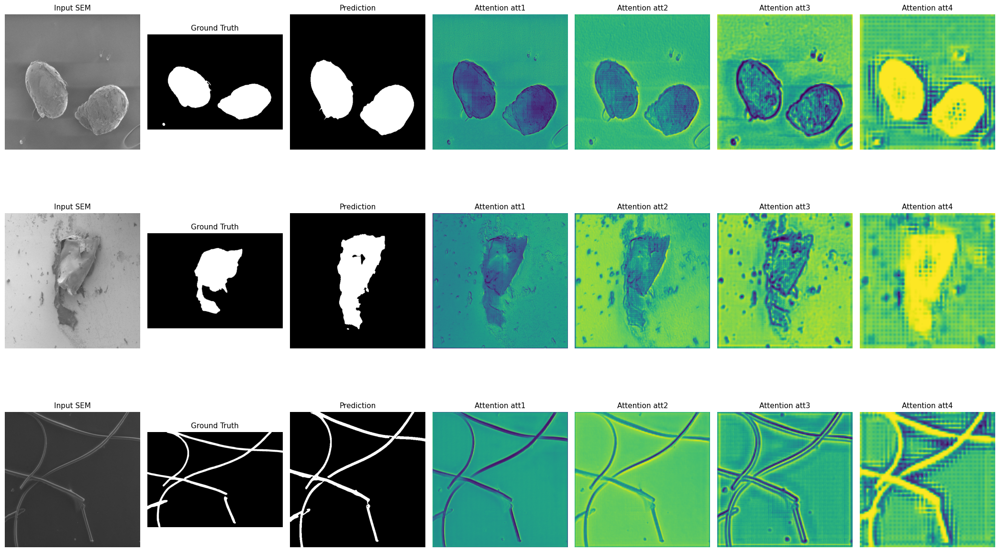


ATTENTION VISUALIZATION COMPLETE
Saved: /kaggle/working/microplastic_project/figures/attention_maps_test_visualization.png


In [73]:
# ============================================================================
# CELL 45 — ATTENTION MAP VISUALIZATION
# ============================================================================
# Uses the frozen TEST split.
# No training, no test-set modification, no model selection.
# ============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
exact_attention_model.eval()

TEST_CSV = os.path.join(
    PROJECT_ROOT,
    "results",
    "test.csv"
)

FIG_PATH = os.path.join(
    PROJECT_ROOT,
    "figures",
    "attention_maps_test_visualization.png"
)

test_df = pd.read_csv(TEST_CSV)

# Select deterministic representative samples
sample_indices = np.linspace(
    0,
    len(test_df) - 1,
    3,
    dtype=int
)

selected_samples = test_df.iloc[sample_indices]

print("=" * 80)
print("ATTENTION MAP VISUALIZATION — TEST SET")
print("=" * 80)

print(f"Test images available: {len(test_df)}")
print(f"Selected samples: {len(selected_samples)}")

# ---------------------------------------------------------------------------
# Helper: canonical ground-truth decoder
# ---------------------------------------------------------------------------
def decode_ground_truth(label_path):

    arr = np.array(Image.open(label_path))

    if arr.ndim == 2:
        source = arr

    elif arr.ndim == 3:
        rgb = arr[..., :3]

        assert np.array_equal(rgb[..., 0], rgb[..., 1])
        assert np.array_equal(rgb[..., 0], rgb[..., 2])

        source = rgb[..., 0]

    else:
        raise ValueError(
            f"Unsupported label shape: {arr.shape}"
        )

    mask = (source > 0).astype(np.float32)

    return mask


# ---------------------------------------------------------------------------
# Helper: preprocess image exactly as evaluation pipeline
# ---------------------------------------------------------------------------
def prepare_image(image_path):

    image = Image.open(image_path).convert("RGB")

    # Match evaluation resolution
    image = image.resize(
        (512, 512),
        Image.Resampling.BILINEAR
    )

    image_np = np.asarray(image).astype(np.float32) / 255.0

    # ImageNet normalization
    mean = np.array(
        [0.485, 0.456, 0.406],
        dtype=np.float32
    )

    std = np.array(
        [0.229, 0.224, 0.225],
        dtype=np.float32
    )

    image_np = (image_np - mean) / std

    tensor = torch.from_numpy(
        image_np.transpose(2, 0, 1)
    ).float().unsqueeze(0)

    return image, tensor


# ---------------------------------------------------------------------------
# Visualization
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(
    len(selected_samples),
    7,
    figsize=(21, 4.5 * len(selected_samples))
)

if len(selected_samples) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, (_, sample) in enumerate(selected_samples.iterrows()):

    image_path = sample["image_path"]
    label_path = sample["label_path"]

    original_image, image_tensor = prepare_image(
        image_path
    )

    ground_truth = decode_ground_truth(
        label_path
    )

    image_tensor = image_tensor.to(
        next(exact_attention_model.parameters()).device
    )

    with torch.no_grad():

        prediction_logits, attention_maps = (
            exact_attention_model(
                image_tensor,
                return_attention=True
            )
        )

        prediction_prob = torch.sigmoid(
            prediction_logits
        )[0, 0].cpu().numpy()

    prediction_mask = (
        prediction_prob >= 0.5
    ).astype(np.float32)

    # ---------------------------------------------------------------
    # Attention maps
    # ---------------------------------------------------------------
    attention_1 = (
        attention_maps["att1"][0, 0]
        .cpu()
        .numpy()
    )

    attention_2 = (
        attention_maps["att2"][0, 0]
        .cpu()
        .numpy()
    )

    attention_3 = (
        attention_maps["att3"][0, 0]
        .cpu()
        .numpy()
    )

    attention_4 = (
        attention_maps["att4"][0, 0]
        .cpu()
        .numpy()
    )

    # Resize coarse attention maps to image resolution
    attention_2 = np.array(
        Image.fromarray(
            attention_2.astype(np.float32),
            mode="F"
        ).resize(
            (512, 512),
            Image.Resampling.BILINEAR
        )
    )

    attention_3 = np.array(
        Image.fromarray(
            attention_3.astype(np.float32),
            mode="F"
        ).resize(
            (512, 512),
            Image.Resampling.BILINEAR
        )
    )

    attention_4 = np.array(
        Image.fromarray(
            attention_4.astype(np.float32),
            mode="F"
        ).resize(
            (512, 512),
            Image.Resampling.BILINEAR
        )
    )

    # ---------------------------------------------------------------
    # Plot
    # ---------------------------------------------------------------
    panels = [
        (
            original_image,
            "Input SEM",
            "gray"
        ),
        (
            ground_truth,
            "Ground Truth",
            "gray"
        ),
        (
            prediction_mask,
            "Prediction",
            "gray"
        ),
        (
            attention_1,
            "Attention att1",
            "viridis"
        ),
        (
            attention_2,
            "Attention att2",
            "viridis"
        ),
        (
            attention_3,
            "Attention att3",
            "viridis"
        ),
        (
            attention_4,
            "Attention att4",
            "viridis"
        ),
    ]

    for col, (data, title, cmap) in enumerate(panels):

        ax = axes[row, col]

        if col == 0:
            ax.imshow(data)
        else:
            ax.imshow(data, cmap=cmap)

        ax.set_title(title, fontsize=11)
        ax.axis("off")

    print(
        f"\nSample {row + 1}: "
        f"{os.path.basename(image_path)}"
    )

# ---------------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------------
plt.tight_layout()
plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\n" + "=" * 80)
print("ATTENTION VISUALIZATION COMPLETE")
print("=" * 80)
print(f"Saved: {FIG_PATH}")

In [74]:
# ============================================================================
# CELL 46 — QUANTITATIVE ATTENTION ANALYSIS
# ============================================================================
# Measures attention-map statistics on the frozen TEST set.
# ============================================================================

import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

print("=" * 80)
print("QUANTITATIVE ATTENTION ANALYSIS — TEST SET")
print("=" * 80)

exact_attention_model.eval()

test_df = pd.read_csv(
    os.path.join(PROJECT_ROOT, "results", "test.csv")
)

device = next(exact_attention_model.parameters()).device

records = []

# ---------------------------------------------------------------------------
# Process every test image
# ---------------------------------------------------------------------------
for _, sample in tqdm(
    test_df.iterrows(),
    total=len(test_df),
    desc="Analyzing attention"
):

    image_path = sample["image_path"]

    image = Image.open(
        image_path
    ).convert("RGB")

    image = image.resize(
        (512, 512),
        Image.Resampling.BILINEAR
    )

    image_np = (
        np.asarray(image).astype(np.float32) / 255.0
    )

    mean = np.array(
        [0.485, 0.456, 0.406],
        dtype=np.float32
    )

    std = np.array(
        [0.229, 0.224, 0.225],
        dtype=np.float32
    )

    image_np = (image_np - mean) / std

    image_tensor = torch.from_numpy(
        image_np.transpose(2, 0, 1)
    ).float().unsqueeze(0).to(device)

    with torch.no_grad():

        _, attention_maps = exact_attention_model(
            image_tensor,
            return_attention=True
        )

    row = {
        "image": os.path.basename(image_path)
    }

    # ---------------------------------------------------------------
    # Analyze every attention level
    # ---------------------------------------------------------------
    for gate in ["att1", "att2", "att3", "att4"]:

        attention = (
            attention_maps[gate][0, 0]
            .detach()
            .cpu()
            .numpy()
        )

        row[f"{gate}_mean"] = float(
            attention.mean()
        )

        row[f"{gate}_std"] = float(
            attention.std()
        )

        row[f"{gate}_min"] = float(
            attention.min()
        )

        row[f"{gate}_max"] = float(
            attention.max()
        )

        row[f"{gate}_high_attention_ratio"] = float(
            (attention >= 0.5).mean()
        )

    records.append(row)

# ---------------------------------------------------------------------------
# Create results table
# ---------------------------------------------------------------------------
attention_stats_df = pd.DataFrame(records)

output_csv = os.path.join(
    PROJECT_ROOT,
    "results",
    "attention_quantitative_analysis.csv"
)

attention_stats_df.to_csv(
    output_csv,
    index=False
)

# ---------------------------------------------------------------------------
# Summary
# ---------------------------------------------------------------------------
summary_rows = []

for gate in ["att1", "att2", "att3", "att4"]:

    summary_rows.append({
        "attention_gate": gate,
        "mean_attention": attention_stats_df[
            f"{gate}_mean"
        ].mean(),

        "std_attention": attention_stats_df[
            f"{gate}_std"
        ].mean(),

        "mean_min": attention_stats_df[
            f"{gate}_min"
        ].mean(),

        "mean_max": attention_stats_df[
            f"{gate}_max"
        ].mean(),

        "mean_high_attention_ratio": attention_stats_df[
            f"{gate}_high_attention_ratio"
        ].mean()
    })

attention_summary_df = pd.DataFrame(
    summary_rows
)

summary_csv = os.path.join(
    PROJECT_ROOT,
    "results",
    "attention_quantitative_summary.csv"
)

attention_summary_df.to_csv(
    summary_csv,
    index=False
)

print("\nAttention summary:")
display(
    attention_summary_df.round(6)
)

print("\n" + "=" * 80)
print("QUANTITATIVE ATTENTION ANALYSIS COMPLETE")
print("=" * 80)
print(f"Per-image results: {output_csv}")
print(f"Summary results:   {summary_csv}")

QUANTITATIVE ATTENTION ANALYSIS — TEST SET


Analyzing attention:   0%|          | 0/34 [00:00<?, ?it/s]


Attention summary:


,attention_gate,mean_attention,std_attention,mean_min,mean_max,mean_high_attention_ratio
0,att1,0.179670,0.043612,0.004234,0.361093,0.000000
1,att2,0.469156,0.067641,0.070711,0.645384,0.412339
2,att3,0.590812,0.164059,0.007098,0.926268,0.793681
3,att4,0.766903,0.171096,0.097889,0.999997,0.912612



QUANTITATIVE ATTENTION ANALYSIS COMPLETE
Per-image results: /kaggle/working/microplastic_project/results/attention_quantitative_analysis.csv
Summary results:   /kaggle/working/microplastic_project/results/attention_quantitative_summary.csv


PUBLICATION-QUALITY ATTENTION STATISTICS


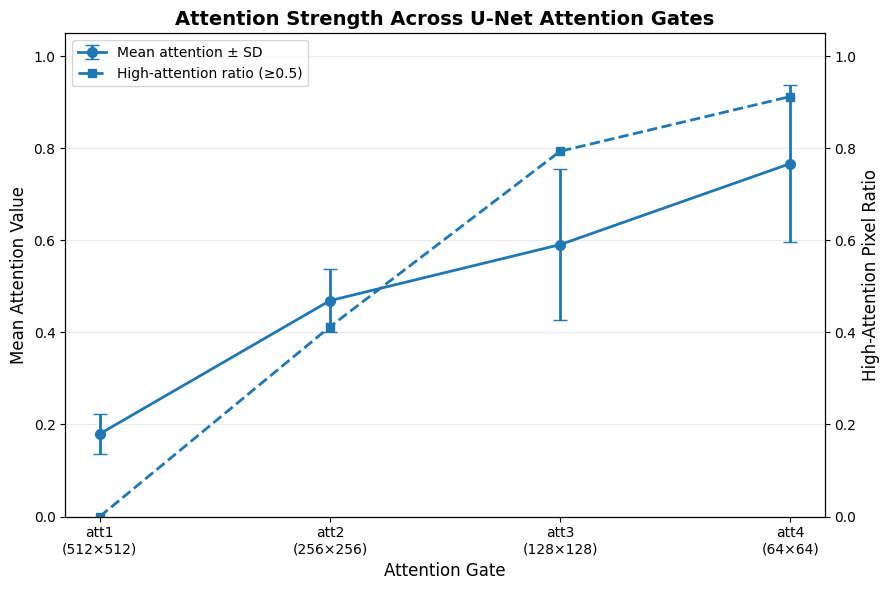


Attention statistics:
att1: mean=0.1797, SD=0.0436, high-ratio=0.0000
att2: mean=0.4692, SD=0.0676, high-ratio=0.4123
att3: mean=0.5908, SD=0.1641, high-ratio=0.7937
att4: mean=0.7669, SD=0.1711, high-ratio=0.9126

FIGURE SAVED
/kaggle/working/microplastic_project/figures/attention_gate_quantitative_analysis.png


In [76]:
# ============================================================================
# CELL 47 — PUBLICATION-QUALITY ATTENTION STATISTICS
# ============================================================================
# Creates a publication-quality figure summarizing attention strength across
# the four attention gates using the already-saved quantitative results.
#
# No new inference.
# ============================================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("=" * 80)
print("PUBLICATION-QUALITY ATTENTION STATISTICS")
print("=" * 80)

# ---------------------------------------------------------------------------
# Load saved attention summary
# ---------------------------------------------------------------------------
summary_csv = os.path.join(
    PROJECT_ROOT,
    "results",
    "attention_quantitative_summary.csv"
)

attention_summary_df = pd.read_csv(summary_csv)

expected_gates = ["att1", "att2", "att3", "att4"]

assert attention_summary_df["attention_gate"].tolist() == expected_gates

# ---------------------------------------------------------------------------
# Create figure
# ---------------------------------------------------------------------------
fig, ax1 = plt.subplots(
    figsize=(9, 6)
)

x = np.arange(len(expected_gates))

means = attention_summary_df["mean_attention"].values
stds = attention_summary_df["std_attention"].values
high_ratio = (
    attention_summary_df["mean_high_attention_ratio"].values
)

# Mean attention with standard deviation
ax1.errorbar(
    x,
    means,
    yerr=stds,
    marker="o",
    linewidth=2,
    markersize=7,
    capsize=5,
    label="Mean attention ± SD"
)

ax1.set_xlabel(
    "Attention Gate",
    fontsize=12
)

ax1.set_ylabel(
    "Mean Attention Value",
    fontsize=12
)

ax1.set_xticks(x)
ax1.set_xticklabels(
    ["att1\n(512×512)",
     "att2\n(256×256)",
     "att3\n(128×128)",
     "att4\n(64×64)"]
)

ax1.set_ylim(0, 1.05)
ax1.grid(
    axis="y",
    alpha=0.25
)

# ---------------------------------------------------------------------------
# High-attention ratio on secondary axis
# ---------------------------------------------------------------------------
ax2 = ax1.twinx()

ax2.plot(
    x,
    high_ratio,
    marker="s",
    linewidth=2,
    markersize=6,
    linestyle="--",
    label="High-attention ratio (≥0.5)"
)

ax2.set_ylabel(
    "High-Attention Pixel Ratio",
    fontsize=12
)

ax2.set_ylim(0, 1.05)

# ---------------------------------------------------------------------------
# Combined legend
# ---------------------------------------------------------------------------
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper left",
    frameon=True
)

ax1.set_title(
    "Attention Strength Across U-Net Attention Gates",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# ---------------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------------
figure_path = os.path.join(
    PROJECT_ROOT,
    "figures",
    "attention_gate_quantitative_analysis.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------------------------------------------
# Print exact values for reporting
# ---------------------------------------------------------------------------
print("\nAttention statistics:")

for _, row in attention_summary_df.iterrows():

    print(
        f"{row['attention_gate']}: "
        f"mean={row['mean_attention']:.4f}, "
        f"SD={row['std_attention']:.4f}, "
        f"high-ratio={row['mean_high_attention_ratio']:.4f}"
    )

print("\n" + "=" * 80)
print("FIGURE SAVED")
print("=" * 80)
print(figure_path)

In [77]:
# ============================================================================
# CELL 48 — ROBUSTNESS ANALYSIS
# ============================================================================
# Evaluates the trained Full Attention U-Net under controlled image
# perturbations:
#   1. Original
#   2. Gaussian noise
#   3. Brightness reduction
#   4. Contrast reduction
#
# Test set remains frozen.
# No retraining.
# ============================================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

print("=" * 80)
print("ROBUSTNESS ANALYSIS — FULL ATTENTION U-NET")
print("=" * 80)

exact_attention_model.eval()

device = next(
    exact_attention_model.parameters()
).device

test_df = pd.read_csv(
    os.path.join(
        PROJECT_ROOT,
        "results",
        "test.csv"
    )
)

# ---------------------------------------------------------------------------
# Metrics
# ---------------------------------------------------------------------------
def calculate_binary_metrics(prediction, target):

    prediction = prediction.astype(bool)
    target = target.astype(bool)

    tp = np.logical_and(
        prediction,
        target
    ).sum()

    tn = np.logical_and(
        ~prediction,
        ~target
    ).sum()

    fp = np.logical_and(
        prediction,
        ~target
    ).sum()

    fn = np.logical_and(
        ~prediction,
        target
    ).sum()

    dice = (
        2 * tp /
        (2 * tp + fp + fn + 1e-8)
    )

    iou = (
        tp /
        (tp + fp + fn + 1e-8)
    )

    precision = (
        tp /
        (tp + fp + 1e-8)
    )

    recall = (
        tp /
        (tp + fn + 1e-8)
    )

    specificity = (
        tn /
        (tn + fp + 1e-8)
    )

    accuracy = (
        (tp + tn) /
        (tp + tn + fp + fn + 1e-8)
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2

    return {
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn
    }


# ---------------------------------------------------------------------------
# Ground-truth decoder
# ---------------------------------------------------------------------------
def decode_gt(path):

    arr = np.array(
        Image.open(path)
    )

    if arr.ndim == 2:

        source = arr

    elif arr.ndim == 3:

        rgb = arr[..., :3]

        assert np.array_equal(
            rgb[..., 0],
            rgb[..., 1]
        )

        assert np.array_equal(
            rgb[..., 0],
            rgb[..., 2]
        )

        source = rgb[..., 0]

    else:
        raise ValueError(
            f"Unsupported label shape: {arr.shape}"
        )

    mask = (
        source > 0
    ).astype(np.float32)

    mask = Image.fromarray(
        mask
    ).resize(
        (512, 512),
        Image.Resampling.NEAREST
    )

    return np.asarray(
        mask
    ).astype(np.float32)


# ---------------------------------------------------------------------------
# Image preparation
# ---------------------------------------------------------------------------
def load_image(path):

    image = Image.open(
        path
    ).convert("RGB")

    image = image.resize(
        (512, 512),
        Image.Resampling.BILINEAR
    )

    image = (
        np.asarray(image)
        .astype(np.float32)
        / 255.0
    )

    return image


def normalize_image(image):

    mean = np.array(
        [0.485, 0.456, 0.406],
        dtype=np.float32
    )

    std = np.array(
        [0.229, 0.224, 0.225],
        dtype=np.float32
    )

    return (
        (image - mean) / std
    )


# ---------------------------------------------------------------------------
# Perturbation functions
# ---------------------------------------------------------------------------
def original(image):
    return image.copy()


def gaussian_noise(image):

    noise = np.random.default_rng(42).normal(
        loc=0.0,
        scale=0.05,
        size=image.shape
    ).astype(np.float32)

    return np.clip(
        image + noise,
        0.0,
        1.0
    )


def brightness_reduction(image):

    return np.clip(
        image * 0.70,
        0.0,
        1.0
    )


def contrast_reduction(image):

    mean = image.mean(
        axis=(0, 1),
        keepdims=True
    )

    return np.clip(
        (image - mean) * 0.70 + mean,
        0.0,
        1.0
    )


perturbations = {
    "Original": original,
    "Gaussian Noise": gaussian_noise,
    "Brightness -30%": brightness_reduction,
    "Contrast -30%": contrast_reduction
}


# ---------------------------------------------------------------------------
# Evaluation
# ---------------------------------------------------------------------------
results = []

for condition, perturbation in perturbations.items():

    print(
        f"\nEvaluating: {condition}"
    )

    condition_metrics = []

    for _, sample in tqdm(
        test_df.iterrows(),
        total=len(test_df),
        desc=condition
    ):

        image = load_image(
            sample["image_path"]
        )

        target = decode_gt(
            sample["label_path"]
        )

        perturbed = perturbation(
            image
        )

        normalized = normalize_image(
            perturbed
        )

        tensor = torch.from_numpy(
            normalized.transpose(2, 0, 1)
        ).float().unsqueeze(0).to(device)

        with torch.no_grad():

            logits = exact_attention_model(
                tensor
            )

            probability = torch.sigmoid(
                logits
            )[0, 0].cpu().numpy()

        prediction = (
            probability >= 0.5
        ).astype(np.float32)

        metrics = calculate_binary_metrics(
            prediction,
            target
        )

        condition_metrics.append(
            metrics
        )

    # Macro/per-image average
    summary = {
        "condition": condition
    }

    metric_names = [
        "dice",
        "iou",
        "precision",
        "recall",
        "specificity",
        "accuracy",
        "balanced_accuracy"
    ]

    for metric in metric_names:

        summary[metric] = np.mean([
            m[metric]
            for m in condition_metrics
        ])

    summary["num_test_images"] = len(
        condition_metrics
    )

    results.append(summary)


# ---------------------------------------------------------------------------
# Save results
# ---------------------------------------------------------------------------
robustness_df = pd.DataFrame(
    results
)

robustness_csv = os.path.join(
    PROJECT_ROOT,
    "results",
    "attention_unet_robustness_analysis.csv"
)

robustness_df.to_csv(
    robustness_csv,
    index=False
)

# ---------------------------------------------------------------------------
# Degradation relative to original
# ---------------------------------------------------------------------------
baseline_dice = robustness_df.loc[
    robustness_df["condition"] == "Original",
    "dice"
].iloc[0]

baseline_iou = robustness_df.loc[
    robustness_df["condition"] == "Original",
    "iou"
].iloc[0]

robustness_df["dice_change"] = (
    robustness_df["dice"] -
    baseline_dice
)

robustness_df["iou_change"] = (
    robustness_df["iou"] -
    baseline_iou
)

robustness_df["dice_relative_change_pct"] = (
    robustness_df["dice_change"] /
    baseline_dice
) * 100

robustness_df["iou_relative_change_pct"] = (
    robustness_df["iou_change"] /
    baseline_iou
) * 100

robustness_df.to_csv(
    robustness_csv,
    index=False
)

print("\n" + "=" * 80)
print("ROBUSTNESS RESULTS")
print("=" * 80)

display(
    robustness_df.round(6)
)

print("\nSaved:")
print(robustness_csv)

print("\n" + "=" * 80)
print("ROBUSTNESS ANALYSIS COMPLETE")
print("=" * 80)

ROBUSTNESS ANALYSIS — FULL ATTENTION U-NET

Evaluating: Original


Original:   0%|          | 0/34 [00:00<?, ?it/s]


Evaluating: Gaussian Noise


Gaussian Noise:   0%|          | 0/34 [00:00<?, ?it/s]


Evaluating: Brightness -30%


...


Evaluating: Contrast -30%


Contrast -30%:   0%|          | 0/34 [00:00<?, ?it/s]


ROBUSTNESS RESULTS


,condition,dice,iou,precision,recall,specificity,accuracy,balanced_accuracy,num_test_images,dice_change,iou_change,dice_relative_change_pct,iou_relative_change_pct
0,Original,0.866691,0.782018,0.902095,0.856684,0.979706,0.950892,0.918195,34,0.000000,0.000000,0.000000,0.000000
1,Gaussian Noise,0.825541,0.733948,0.833795,0.832136,0.968300,0.940151,0.900218,34,-0.041151,-0.048070,-4.748049,-6.146962
2,Brightness -30%,0.844598,0.749969,0.896831,0.823711,0.981634,0.945030,0.902673,34,-0.022093,-0.032049,-2.549145,-4.098305
3,Contrast -30%,0.844230,0.751124,0.912199,0.814597,0.981802,0.943071,0.898199,34,-0.022461,-0.030894,-2.591586,-3.950512



Saved:
/kaggle/working/microplastic_project/results/attention_unet_robustness_analysis.csv

ROBUSTNESS ANALYSIS COMPLETE


** Results Tables + Robustness Figure**

FINAL PUBLICATION RESULTS CONSOLIDATION

[1] Official test comparison loaded:


,configuration,test_loss,macro_dice,macro_iou,macro_precision,macro_recall,macro_specificity,macro_f1,macro_accuracy,macro_balanced_accuracy
0,Baseline U-Net,0.160673,0.878792,0.797507,0.884835,0.889143,0.977419,0.878792,0.954197,0.933281
1,Full Attention U-Net,0.134095,0.881719,0.803145,0.904197,0.873732,0.983182,0.881719,0.956340,0.928457
2,without_att4,0.190560,0.871693,0.787051,0.866618,0.892269,0.974625,0.871693,0.953035,0.933447
3,without_att3,0.170730,0.860734,0.773536,0.869452,0.868948,0.978072,0.860734,0.951174,0.923510
4,without_att2,0.251371,0.841615,0.749473,0.809495,0.909525,0.954049,0.841615,0.938175,0.931787
5,without_att1,0.212938,0.842553,0.752010,0.841471,0.865347,0.971918,0.842553,0.944288,0.918633



[2] Ablation validation results:


,configuration,best_epoch,best_val_dice,best_val_iou,dice_change,iou_change,dice_degradation_pct,iou_degradation_pct
0,Full Attention U-Net,50,0.864517,0.775277,0.000000,0.000000,0.000,0.000
1,Without att4,40,0.856422,0.761351,-0.008095,-0.013926,0.936,1.796
2,Without att3,48,0.862220,0.770921,-0.002297,-0.004356,0.266,0.562
3,Without att2,50,0.847841,0.749684,-0.016676,-0.025593,1.929,3.301
4,Without att1,28,0.839561,0.738528,-0.024956,-0.036749,2.887,4.740



[3] Robustness results:


,condition,dice,iou,precision,recall,specificity,accuracy,balanced_accuracy,num_test_images,dice_change,iou_change,dice_relative_change_pct,iou_relative_change_pct
0,Original,0.866691,0.782018,0.902095,0.856684,0.979706,0.950892,0.918195,34,0.000000,0.000000,0.000000,0.000000
1,Gaussian Noise,0.825541,0.733948,0.833795,0.832136,0.968300,0.940151,0.900218,34,-0.041151,-0.048070,-4.748049,-6.146962
2,Brightness -30%,0.844598,0.749969,0.896831,0.823711,0.981634,0.945030,0.902673,34,-0.022093,-0.032049,-2.549145,-4.098305
3,Contrast -30%,0.844230,0.751124,0.912199,0.814597,0.981802,0.943071,0.898199,34,-0.022461,-0.030894,-2.591586,-3.950512


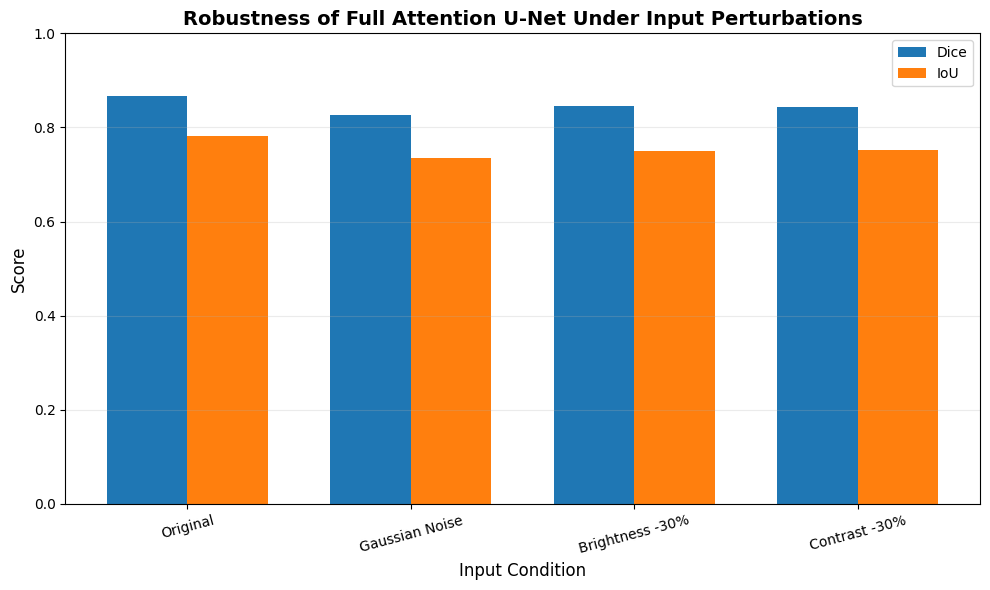


PUBLICATION OUTPUTS CREATED

Test table:
/kaggle/working/microplastic_project/results/final_test_publication_table.csv

Robustness table:
/kaggle/working/microplastic_project/results/final_robustness_publication_table.csv

Robustness figure:
/kaggle/working/microplastic_project/figures/attention_unet_robustness_comparison.png

CELL 49 COMPLETE


In [78]:
# ============================================================================
# CELL 49 — FINAL PUBLICATION RESULTS TABLES + ROBUSTNESS FIGURE
# ============================================================================
# Uses ONLY previously saved results.
# No new model inference.
# ============================================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("=" * 80)
print("FINAL PUBLICATION RESULTS CONSOLIDATION")
print("=" * 80)

RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")

# ---------------------------------------------------------------------------
# 1. Load official unified test comparison
# ---------------------------------------------------------------------------
unified_path = os.path.join(
    RESULTS_DIR,
    "unified_test_macro_publication_table.csv"
)

unified_df = pd.read_csv(unified_path)

print("\n[1] Official test comparison loaded:")
display(unified_df.round(6))

# ---------------------------------------------------------------------------
# 2. Load ablation validation results
# ---------------------------------------------------------------------------
ablation_val_path = os.path.join(
    RESULTS_DIR,
    "attention_ablation_publication_table.csv"
)

ablation_val_df = pd.read_csv(
    ablation_val_path
)

print("\n[2] Ablation validation results:")
display(ablation_val_df.round(6))

# ---------------------------------------------------------------------------
# 3. Load robustness results
# ---------------------------------------------------------------------------
robustness_path = os.path.join(
    RESULTS_DIR,
    "attention_unet_robustness_analysis.csv"
)

robustness_df = pd.read_csv(
    robustness_path
)

print("\n[3] Robustness results:")
display(robustness_df.round(6))

# ---------------------------------------------------------------------------
# 4. Create compact publication table
# ---------------------------------------------------------------------------
publication_columns = [
    "model",
    "dice",
    "iou",
    "precision",
    "recall",
    "specificity",
    "f1",
    "accuracy",
    "balanced_accuracy"
]

# Adapt safely if column naming differs
available_columns = [
    col for col in publication_columns
    if col in unified_df.columns
]

publication_test_df = unified_df[
    available_columns
].copy()

publication_test_path = os.path.join(
    RESULTS_DIR,
    "final_test_publication_table.csv"
)

publication_test_df.to_csv(
    publication_test_path,
    index=False
)

# ---------------------------------------------------------------------------
# 5. Robustness publication table
# ---------------------------------------------------------------------------
robustness_columns = [
    "condition",
    "dice",
    "iou",
    "precision",
    "recall",
    "specificity",
    "accuracy",
    "balanced_accuracy",
    "dice_relative_change_pct",
    "iou_relative_change_pct"
]

robustness_publication_df = robustness_df[
    [
        c for c in robustness_columns
        if c in robustness_df.columns
    ]
].copy()

robustness_publication_path = os.path.join(
    RESULTS_DIR,
    "final_robustness_publication_table.csv"
)

robustness_publication_df.to_csv(
    robustness_publication_path,
    index=False
)

# ---------------------------------------------------------------------------
# 6. Robustness figure
# ---------------------------------------------------------------------------
conditions = robustness_df["condition"].tolist()
dice_values = robustness_df["dice"].values
iou_values = robustness_df["iou"].values

x = np.arange(len(conditions))
width = 0.36

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.bar(
    x - width / 2,
    dice_values,
    width,
    label="Dice"
)

ax.bar(
    x + width / 2,
    iou_values,
    width,
    label="IoU"
)

ax.set_ylabel(
    "Score",
    fontsize=12
)

ax.set_xlabel(
    "Input Condition",
    fontsize=12
)

ax.set_title(
    "Robustness of Full Attention U-Net Under Input Perturbations",
    fontsize=14,
    fontweight="bold"
)

ax.set_xticks(x)
ax.set_xticklabels(
    conditions,
    rotation=15
)

ax.set_ylim(
    0,
    1.0
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()

plt.tight_layout()

robustness_figure_path = os.path.join(
    FIGURES_DIR,
    "attention_unet_robustness_comparison.png"
)

plt.savefig(
    robustness_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------------------------------------------
# 7. Final summary
# ---------------------------------------------------------------------------
print("\n" + "=" * 80)
print("PUBLICATION OUTPUTS CREATED")
print("=" * 80)

print("\nTest table:")
print(publication_test_path)

print("\nRobustness table:")
print(robustness_publication_path)

print("\nRobustness figure:")
print(robustness_figure_path)

print("\n" + "=" * 80)
print("CELL 49 COMPLETE")
print("=" * 80)

TRAINING & VALIDATION CONVERGENCE ANALYSIS

Baseline history shape: (50, 13)
Attention history shape: (50, 13)

Baseline columns:
['epoch', 'train_loss', 'val_loss', 'val_dice', 'val_iou', 'val_precision', 'val_recall', 'val_specificity', 'val_f1', 'val_accuracy', 'val_balanced_accuracy', 'learning_rate', 'epoch_time_seconds']

Attention columns:
['epoch', 'train_loss', 'val_loss', 'val_dice', 'val_iou', 'val_precision', 'val_recall', 'val_specificity', 'val_f1', 'val_accuracy', 'val_balanced_accuracy', 'learning_rate', 'epoch_time_seconds']

Validation Dice columns:
Baseline: val_dice
Attention: val_dice

Training Dice columns:
Baseline: None
Attention: None


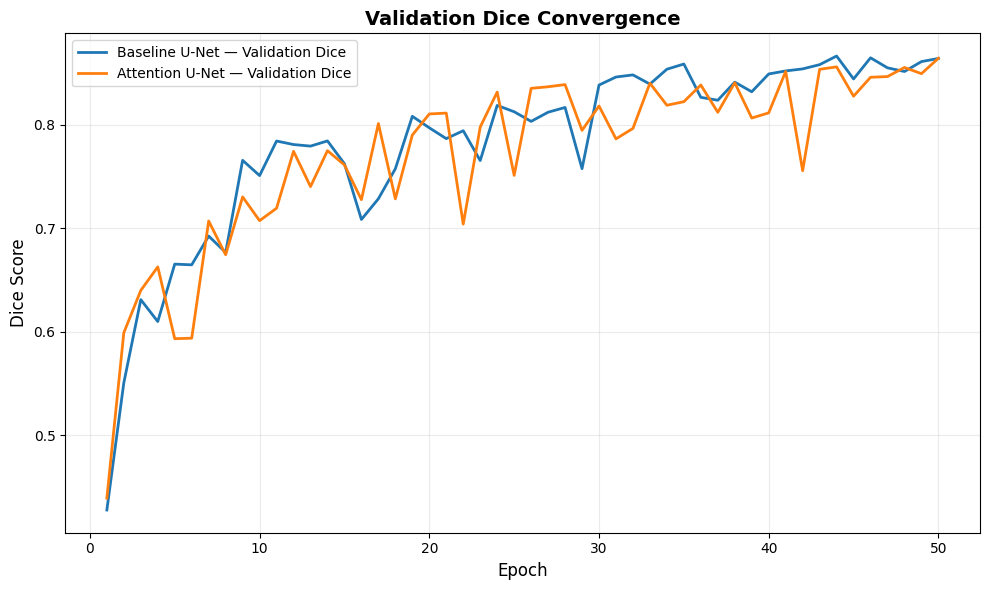


Training Dice column not available; only validation convergence was plotted.

CONVERGENCE SUMMARY
Baseline U-Net: best validation Dice = 0.866681 at epoch 44
Attention U-Net: best validation Dice = 0.864517 at epoch 50

Saved:
/kaggle/working/microplastic_project/figures/training_validation_dice_convergence.png
CELL 50 COMPLETE


In [79]:
# ============================================================================
# CELL 50 — TRAINING & VALIDATION CONVERGENCE ANALYSIS
# ============================================================================
# Compares the saved training histories of:
#   1. Baseline U-Net
#   2. Full Attention U-Net
#
# No training and no new inference.
# ============================================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 80)
print("TRAINING & VALIDATION CONVERGENCE ANALYSIS")
print("=" * 80)

LOGS_DIR = os.path.join(
    PROJECT_ROOT,
    "logs"
)

FIGURES_DIR = os.path.join(
    PROJECT_ROOT,
    "figures"
)

# ---------------------------------------------------------------------------
# Load histories
# ---------------------------------------------------------------------------
baseline_history_path = os.path.join(
    LOGS_DIR,
    "baseline_unet_history.csv"
)

attention_history_path = os.path.join(
    LOGS_DIR,
    "attention_unet_history.csv"
)

assert os.path.exists(
    baseline_history_path
), baseline_history_path

assert os.path.exists(
    attention_history_path
), attention_history_path

baseline_history = pd.read_csv(
    baseline_history_path
)

attention_history = pd.read_csv(
    attention_history_path
)

print("\nBaseline history shape:",
      baseline_history.shape)

print("Attention history shape:",
      attention_history.shape)

print("\nBaseline columns:")
print(list(baseline_history.columns))

print("\nAttention columns:")
print(list(attention_history.columns))

# ---------------------------------------------------------------------------
# Identify Dice columns
# ---------------------------------------------------------------------------
def find_column(df, candidates):

    for candidate in candidates:
        if candidate in df.columns:
            return candidate

    raise KeyError(
        f"None of these columns found: {candidates}"
    )


baseline_val_dice_col = find_column(
    baseline_history,
    [
        "val_dice",
        "val_Dice",
        "validation_dice"
    ]
)

attention_val_dice_col = find_column(
    attention_history,
    [
        "val_dice",
        "val_Dice",
        "validation_dice"
    ]
)

# Training Dice may or may not be present depending on the saved engine.
baseline_train_dice_col = None
attention_train_dice_col = None

for candidate in [
    "train_dice",
    "train_Dice",
    "training_dice"
]:
    if candidate in baseline_history.columns:
        baseline_train_dice_col = candidate
        break

for candidate in [
    "train_dice",
    "train_Dice",
    "training_dice"
]:
    if candidate in attention_history.columns:
        attention_train_dice_col = candidate
        break

print("\nValidation Dice columns:")
print("Baseline:", baseline_val_dice_col)
print("Attention:", attention_val_dice_col)

print("\nTraining Dice columns:")
print("Baseline:", baseline_train_dice_col)
print("Attention:", attention_train_dice_col)

# ---------------------------------------------------------------------------
# Plot validation Dice
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.plot(
    baseline_history["epoch"],
    baseline_history[baseline_val_dice_col],
    linewidth=2,
    label="Baseline U-Net — Validation Dice"
)

ax.plot(
    attention_history["epoch"],
    attention_history[attention_val_dice_col],
    linewidth=2,
    label="Attention U-Net — Validation Dice"
)

ax.set_xlabel(
    "Epoch",
    fontsize=12
)

ax.set_ylabel(
    "Dice Score",
    fontsize=12
)

ax.set_title(
    "Validation Dice Convergence",
    fontsize=14,
    fontweight="bold"
)

ax.grid(
    axis="both",
    alpha=0.25
)

ax.legend()

plt.tight_layout()

validation_curve_path = os.path.join(
    FIGURES_DIR,
    "training_validation_dice_convergence.png"
)

plt.savefig(
    validation_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------------------------------------------
# Optional training Dice figure if available
# ---------------------------------------------------------------------------
if (
    baseline_train_dice_col is not None
    and attention_train_dice_col is not None
):

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    ax.plot(
        baseline_history["epoch"],
        baseline_history[baseline_train_dice_col],
        linewidth=2,
        label="Baseline U-Net — Training Dice"
    )

    ax.plot(
        attention_history["epoch"],
        attention_history[attention_train_dice_col],
        linewidth=2,
        label="Attention U-Net — Training Dice"
    )

    ax.set_xlabel(
        "Epoch",
        fontsize=12
    )

    ax.set_ylabel(
        "Dice Score",
        fontsize=12
    )

    ax.set_title(
        "Training Dice Convergence",
        fontsize=14,
        fontweight="bold"
    )

    ax.grid(
        axis="both",
        alpha=0.25
    )

    ax.legend()

    plt.tight_layout()

    training_curve_path = os.path.join(
        FIGURES_DIR,
        "training_dice_convergence.png"
    )

    plt.savefig(
        training_curve_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:

    training_curve_path = None

    print(
        "\nTraining Dice column not available; "
        "only validation convergence was plotted."
    )

# ---------------------------------------------------------------------------
# Report best validation Dice
# ---------------------------------------------------------------------------
baseline_best_idx = baseline_history[
    baseline_val_dice_col
].idxmax()

attention_best_idx = attention_history[
    attention_val_dice_col
].idxmax()

baseline_best_epoch = int(
    baseline_history.loc[
        baseline_best_idx,
        "epoch"
    ]
)

attention_best_epoch = int(
    attention_history.loc[
        attention_best_idx,
        "epoch"
    ]
)

baseline_best_dice = float(
    baseline_history.loc[
        baseline_best_idx,
        baseline_val_dice_col
    ]
)

attention_best_dice = float(
    attention_history.loc[
        attention_best_idx,
        attention_val_dice_col
    ]
)

print("\n" + "=" * 80)
print("CONVERGENCE SUMMARY")
print("=" * 80)

print(
    f"Baseline U-Net: "
    f"best validation Dice = {baseline_best_dice:.6f} "
    f"at epoch {baseline_best_epoch}"
)

print(
    f"Attention U-Net: "
    f"best validation Dice = {attention_best_dice:.6f} "
    f"at epoch {attention_best_epoch}"
)

print("\nSaved:")
print(validation_curve_path)

if training_curve_path is not None:
    print(training_curve_path)

print("=" * 80)
print("CELL 50 COMPLETE")
print("=" * 80)

QUALITATIVE SEGMENTATION COMPARISON

Baseline checkpoint loading: PASS
Baseline parameters: 31,037,633
Sample 1: Dove_men_acrylates_copolymer_microbeads_048.png
Sample 2: PAN_23_3kV_20201119.png
Sample 3: Particle_2_No0014.png
Sample 4: polyester_81.png


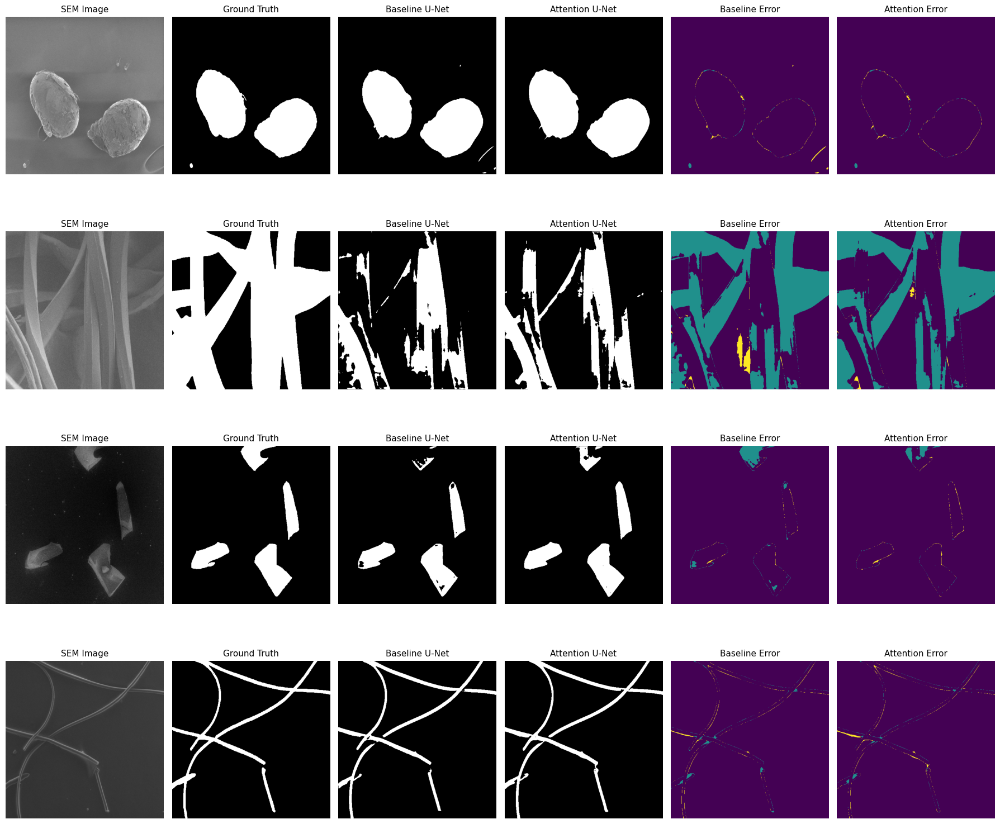


QUALITATIVE COMPARISON COMPLETE
Saved: /kaggle/working/microplastic_project/figures/qualitative_segmentation_comparison.png


In [81]:
# ============================================================================
# CELL 51 — QUALITATIVE SEGMENTATION COMPARISON
# ============================================================================
# Exact checkpoint-compatible Baseline U-Net vs Full Attention U-Net.
# Uses the frozen TEST split.
# ============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image

print("=" * 80)
print("QUALITATIVE SEGMENTATION COMPARISON")
print("=" * 80)

# ---------------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------------
TEST_CSV = os.path.join(
    PROJECT_ROOT,
    "results",
    "test.csv"
)

BASELINE_CHECKPOINT = os.path.join(
    PROJECT_ROOT,
    "checkpoints",
    "baseline_unet_best.pth"
)

FIGURE_PATH = os.path.join(
    PROJECT_ROOT,
    "figures",
    "qualitative_segmentation_comparison.png"
)

test_df = pd.read_csv(TEST_CSV)

assert len(test_df) == 34
assert os.path.exists(BASELINE_CHECKPOINT)

# ---------------------------------------------------------------------------
# Exact checkpoint-compatible Baseline U-Net
# ---------------------------------------------------------------------------
class ExactCheckpointUNet(nn.Module):

    def __init__(self, in_channels=3, out_channels=1):

        super().__init__()

        self.enc1 = CheckpointDoubleConv(
            in_channels, 64
        )

        self.enc2 = CheckpointDoubleConv(
            64, 128
        )

        self.enc3 = CheckpointDoubleConv(
            128, 256
        )

        self.enc4 = CheckpointDoubleConv(
            256, 512
        )

        self.bottleneck = CheckpointDoubleConv(
            512, 1024
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.up4 = nn.ConvTranspose2d(
            1024, 512, kernel_size=2, stride=2
        )

        self.up3 = nn.ConvTranspose2d(
            512, 256, kernel_size=2, stride=2
        )

        self.up2 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )

        self.up1 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )

        self.dec4 = CheckpointDoubleConv(
            1024, 512
        )

        self.dec3 = CheckpointDoubleConv(
            512, 256
        )

        self.dec2 = CheckpointDoubleConv(
            256, 128
        )

        self.dec1 = CheckpointDoubleConv(
            128, 64
        )

        self.head = nn.Conv2d(
            64,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(
            self.pool(e4)
        )

        d4 = self.up4(b)
        d4 = torch.cat(
            [d4, e4],
            dim=1
        )
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat(
            [d3, e3],
            dim=1
        )
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat(
            [d2, e2],
            dim=1
        )
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat(
            [d1, e1],
            dim=1
        )
        d1 = self.dec1(d1)

        return self.head(d1)


# ---------------------------------------------------------------------------
# Instantiate exact baseline
# ---------------------------------------------------------------------------
baseline_model_exact = ExactCheckpointUNet(
    in_channels=3,
    out_channels=1
)

baseline_checkpoint = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu"
)

if (
    isinstance(baseline_checkpoint, dict)
    and "model_state_dict" in baseline_checkpoint
):
    baseline_state_dict = (
        baseline_checkpoint["model_state_dict"]
    )
elif (
    isinstance(baseline_checkpoint, dict)
    and "state_dict" in baseline_checkpoint
):
    baseline_state_dict = (
        baseline_checkpoint["state_dict"]
    )
else:
    baseline_state_dict = baseline_checkpoint

# ---------------------------------------------------------------------------
# Strict compatibility verification
# ---------------------------------------------------------------------------
baseline_model_exact.load_state_dict(
    baseline_state_dict,
    strict=True
)

baseline_params = sum(
    p.numel()
    for p in baseline_model_exact.parameters()
)

print("\nBaseline checkpoint loading: PASS")
print(
    f"Baseline parameters: {baseline_params:,}"
)

assert baseline_params == 31_037_633

baseline_model_exact.eval()

# ---------------------------------------------------------------------------
# Device
# ---------------------------------------------------------------------------
device = next(
    exact_attention_model.parameters()
).device

baseline_model_exact = baseline_model_exact.to(device)
exact_attention_model = exact_attention_model.to(device)

# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------
def prepare_image(path):

    image = Image.open(
        path
    ).convert("RGB")

    image = image.resize(
        (512, 512),
        Image.Resampling.BILINEAR
    )

    image_np = (
        np.asarray(image)
        .astype(np.float32)
        / 255.0
    )

    mean = np.array(
        [0.485, 0.456, 0.406],
        dtype=np.float32
    )

    std = np.array(
        [0.229, 0.224, 0.225],
        dtype=np.float32
    )

    normalized = (
        image_np - mean
    ) / std

    tensor = torch.from_numpy(
        normalized.transpose(2, 0, 1)
    ).float().unsqueeze(0)

    return image, tensor


def decode_ground_truth(path):

    arr = np.array(
        Image.open(path)
    )

    if arr.ndim == 2:

        source = arr

    elif arr.ndim == 3:

        rgb = arr[..., :3]

        assert np.array_equal(
            rgb[..., 0],
            rgb[..., 1]
        )

        assert np.array_equal(
            rgb[..., 0],
            rgb[..., 2]
        )

        source = rgb[..., 0]

    else:
        raise ValueError(
            f"Unsupported label shape: {arr.shape}"
        )

    mask = (
        source > 0
    ).astype(np.float32)

    mask = Image.fromarray(
        mask
    ).resize(
        (512, 512),
        Image.Resampling.NEAREST
    )

    return np.asarray(
        mask
    ).astype(np.float32)


# ---------------------------------------------------------------------------
# Representative samples
# ---------------------------------------------------------------------------
sample_indices = np.linspace(
    0,
    len(test_df) - 1,
    4,
    dtype=int
)

selected_samples = test_df.iloc[
    sample_indices
]

# ---------------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(
    len(selected_samples),
    6,
    figsize=(18, 4 * len(selected_samples))
)

if len(selected_samples) == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row, (_, sample) in enumerate(
    selected_samples.iterrows()
):

    image_path = sample["image_path"]
    label_path = sample["label_path"]

    original_image, image_tensor = prepare_image(
        image_path
    )

    ground_truth = decode_ground_truth(
        label_path
    )

    image_tensor = image_tensor.to(
        device
    )

    with torch.no_grad():

        baseline_logits = baseline_model_exact(
            image_tensor
        )

        attention_logits = exact_attention_model(
            image_tensor
        )

    baseline_prediction = (
        torch.sigmoid(
            baseline_logits
        )[0, 0]
        .cpu()
        .numpy()
        >= 0.5
    ).astype(np.float32)

    attention_prediction = (
        torch.sigmoid(
            attention_logits
        )[0, 0]
        .cpu()
        .numpy()
        >= 0.5
    ).astype(np.float32)

    # Error coding:
    # 0 = correct/background
    # 1 = false negative
    # 2 = false positive
    def error_map(prediction):

        error = np.zeros_like(
            ground_truth,
            dtype=np.float32
        )

        error[
            (ground_truth == 1)
            & (prediction == 0)
        ] = 1

        error[
            (ground_truth == 0)
            & (prediction == 1)
        ] = 2

        return error

    baseline_error = error_map(
        baseline_prediction
    )

    attention_error = error_map(
        attention_prediction
    )

    panels = [
        (original_image, "SEM Image", "gray"),
        (ground_truth, "Ground Truth", "gray"),
        (baseline_prediction, "Baseline U-Net", "gray"),
        (attention_prediction, "Attention U-Net", "gray"),
        (baseline_error, "Baseline Error", "viridis"),
        (attention_error, "Attention Error", "viridis")
    ]

    for col, (
        data,
        title,
        cmap
    ) in enumerate(panels):

        ax = axes[row, col]

        ax.imshow(
            data,
            cmap=cmap
        )

        ax.set_title(
            title,
            fontsize=11
        )

        ax.axis("off")

    print(
        f"Sample {row + 1}: "
        f"{os.path.basename(image_path)}"
    )

# ---------------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------------
plt.tight_layout()

plt.savefig(
    FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 80)
print("QUALITATIVE COMPARISON COMPLETE")
print("=" * 80)

print(
    f"Saved: {FIGURE_PATH}"
)

In [82]:
# ============================================================================
# CELL 52 — FINAL PROJECT AUDIT & REPRODUCIBILITY CHECK
# ============================================================================

import os
import json
import pandas as pd

print("=" * 80)
print("FINAL PROJECT AUDIT")
print("=" * 80)

# ---------------------------------------------------------------------------
# Directories
# ---------------------------------------------------------------------------
directories = [
    "configs",
    "data",
    "checkpoints",
    "logs",
    "results",
    "figures",
    "predictions",
    "reports",
    "source"
]

print("\n[1] PROJECT DIRECTORIES")

for directory in directories:

    path = os.path.join(
        PROJECT_ROOT,
        directory
    )

    status = "PASS" if os.path.isdir(path) else "MISSING"

    print(
        f"{directory:<15} : {status}"
    )

# ---------------------------------------------------------------------------
# Critical checkpoints
# ---------------------------------------------------------------------------
checkpoints = [
    "baseline_unet_best.pth",
    "attention_unet_best.pth",
    "ablation_without_att4_best.pth",
    "ablation_without_att3_best.pth",
    "ablation_without_att2_best.pth",
    "ablation_without_att1_best.pth"
]

print("\n[2] CHECKPOINTS")

checkpoint_status = []

for filename in checkpoints:

    path = os.path.join(
        PROJECT_ROOT,
        "checkpoints",
        filename
    )

    exists = os.path.exists(path)

    checkpoint_status.append({
        "checkpoint": filename,
        "exists": exists,
        "size_MB": (
            os.path.getsize(path) / (1024 ** 2)
            if exists else None
        )
    })

    print(
        f"{filename:<45} : "
        f"{'PASS' if exists else 'MISSING'}"
    )

# ---------------------------------------------------------------------------
# Critical result files
# ---------------------------------------------------------------------------
result_files = [
    "train.csv",
    "val.csv",
    "test.csv",
    "master_split_manifest.csv",
    "atomic_split_units.csv",
    "split_summary.csv",
    "split_material_distribution.csv",
    "final_ground_truth_decoder_validation.csv",
    "baseline_unet_test_results_corrected.csv",
    "baseline_unet_test_per_image_corrected.csv",
    "attention_unet_test_results_corrected.csv",
    "attention_unet_test_per_image_corrected.csv",
    "attention_ablation_validation_summary.csv",
    "attention_ablation_validation_analysis.csv",
    "attention_ablation_publication_table.csv",
    "attention_ablation_test_results_corrected.csv",
    "attention_ablation_test_publication_table.csv",
    "unified_test_comparison_complete.csv",
    "unified_test_macro_publication_table.csv",
    "unified_test_global_publication_table.csv",
    "attention_quantitative_analysis.csv",
    "attention_quantitative_summary.csv",
    "attention_unet_robustness_analysis.csv",
    "final_test_publication_table.csv",
    "final_robustness_publication_table.csv"
]

print("\n[3] CRITICAL RESULT FILES")

missing_results = []

for filename in result_files:

    path = os.path.join(
        PROJECT_ROOT,
        "results",
        filename
    )

    exists = os.path.exists(path)

    if not exists:
        missing_results.append(filename)

    print(
        f"{filename:<55} : "
        f"{'PASS' if exists else 'MISSING'}"
    )

# ---------------------------------------------------------------------------
# Critical figures
# ---------------------------------------------------------------------------
figure_files = [
    "preprocessing_validation_visual_check.png",
    "attention_ablation_validation_dice.png",
    "attention_ablation_validation_iou.png",
    "attention_gate_quantitative_analysis.png",
    "attention_unet_robustness_comparison.png",
    "training_validation_dice_convergence.png",
    "training_dice_convergence.png",
    "qualitative_segmentation_comparison.png",
    "attention_maps_test_visualization.png"
]

print("\n[4] CRITICAL FIGURES")

missing_figures = []

for filename in figure_files:

    path = os.path.join(
        PROJECT_ROOT,
        "figures",
        filename
    )

    exists = os.path.exists(path)

    if not exists:
        missing_figures.append(filename)

    print(
        f"{filename:<55} : "
        f"{'PASS' if exists else 'MISSING'}"
    )

# ---------------------------------------------------------------------------
# Split integrity
# ---------------------------------------------------------------------------
print("\n[5] SPLIT INTEGRITY")

train_df = pd.read_csv(
    os.path.join(
        PROJECT_ROOT,
        "results",
        "train.csv"
    )
)

val_df = pd.read_csv(
    os.path.join(
        PROJECT_ROOT,
        "results",
        "val.csv"
    )
)

test_df = pd.read_csv(
    os.path.join(
        PROJECT_ROOT,
        "results",
        "test.csv"
    )
)

train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

train_val_overlap = train_paths & val_paths
train_test_overlap = train_paths & test_paths
val_test_overlap = val_paths & test_paths

print(
    f"Train images: {len(train_df)}"
)

print(
    f"Validation images: {len(val_df)}"
)

print(
    f"Test images: {len(test_df)}"
)

print(
    f"Train/Val overlap: {len(train_val_overlap)}"
)

print(
    f"Train/Test overlap: {len(train_test_overlap)}"
)

print(
    f"Val/Test overlap: {len(val_test_overlap)}"
)

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("Split leakage check: PASS")

# ---------------------------------------------------------------------------
# Unified test table verification
# ---------------------------------------------------------------------------
print("\n[6] UNIFIED TEST TABLE")

unified_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "unified_test_comparison_complete.csv"
)

unified_df = pd.read_csv(
    unified_path
)

print(
    f"Configurations: {len(unified_df)}"
)

print(
    "Configurations:"
)

for model_name in unified_df[
    unified_df.columns[0]
].tolist():

    print(
        f"  - {model_name}"
    )

assert len(unified_df) == 6

# ---------------------------------------------------------------------------
# Final experiment inventory
# ---------------------------------------------------------------------------
audit = {
    "dataset_images": 237,
    "train_images": len(train_df),
    "validation_images": len(val_df),
    "test_images": len(test_df),
    "model_configurations": 6,
    "attention_gates": 4,
    "ablation_variants": 4,
    "robustness_conditions": 4,
    "checkpoints_found": sum(
        x["exists"]
        for x in checkpoint_status
    ),
    "missing_result_files": len(missing_results),
    "missing_figure_files": len(missing_figures),
    "split_leakage": False
}

audit_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "final_project_audit.json"
)

with open(
    audit_path,
    "w"
) as f:

    json.dump(
        audit,
        f,
        indent=4
    )

# ---------------------------------------------------------------------------
# Final status
# ---------------------------------------------------------------------------
print("\n" + "=" * 80)
print("FINAL AUDIT SUMMARY")
print("=" * 80)

print(
    f"Dataset:                 {audit['dataset_images']} images"
)

print(
    f"Train / Val / Test:      "
    f"{audit['train_images']} / "
    f"{audit['validation_images']} / "
    f"{audit['test_images']}"
)

print(
    f"Model configurations:    {audit['model_configurations']}"
)

print(
    f"Attention gates:         {audit['attention_gates']}"
)

print(
    f"Ablation variants:       {audit['ablation_variants']}"
)

print(
    f"Robustness conditions:   {audit['robustness_conditions']}"
)

print(
    f"Checkpoints found:       "
    f"{audit['checkpoints_found']}/{len(checkpoints)}"
)

print(
    f"Missing result files:    {audit['missing_result_files']}"
)

print(
    f"Missing figure files:    {audit['missing_figure_files']}"
)

print(
    f"Split leakage:           "
    f"{'FAIL' if audit['split_leakage'] else 'PASS'}"
)

print(
    f"\nAudit saved to:\n{audit_path}"
)

print("\n" + "=" * 80)
print("PROJECT AUDIT COMPLETE")
print("=" * 80)

FINAL PROJECT AUDIT

[1] PROJECT DIRECTORIES
configs         : MISSING
data            : MISSING
checkpoints     : PASS
logs            : PASS
results         : PASS
figures         : PASS
predictions     : MISSING
reports         : MISSING
source          : MISSING

[2] CHECKPOINTS
baseline_unet_best.pth                        : PASS
attention_unet_best.pth                       : PASS
ablation_without_att4_best.pth                : PASS
ablation_without_att3_best.pth                : PASS
ablation_without_att2_best.pth                : PASS
ablation_without_att1_best.pth                : PASS

[3] CRITICAL RESULT FILES
train.csv                                               : PASS
val.csv                                                 : PASS
test.csv                                                : PASS
master_split_manifest.csv                               : PASS
atomic_split_units.csv                                  : PASS
split_summary.csv                                       

FINAL MODEL COMPARISON


,configuration,test_loss,macro_dice,macro_iou,macro_precision,macro_recall,macro_specificity,macro_f1,macro_accuracy,macro_balanced_accuracy
0,Baseline U-Net,0.160673,0.878792,0.797507,0.884835,0.889143,0.977419,0.878792,0.954197,0.933281
1,Full Attention U-Net,0.134095,0.881719,0.803145,0.904197,0.873732,0.983182,0.881719,0.956340,0.928457
2,without_att4,0.190560,0.871693,0.787051,0.866618,0.892269,0.974625,0.871693,0.953035,0.933447
3,without_att3,0.170730,0.860734,0.773536,0.869452,0.868948,0.978072,0.860734,0.951174,0.923510
4,without_att2,0.251371,0.841615,0.749473,0.809495,0.909525,0.954049,0.841615,0.938175,0.931787
5,without_att1,0.212938,0.842553,0.752010,0.841471,0.865347,0.971918,0.842553,0.944288,0.918633


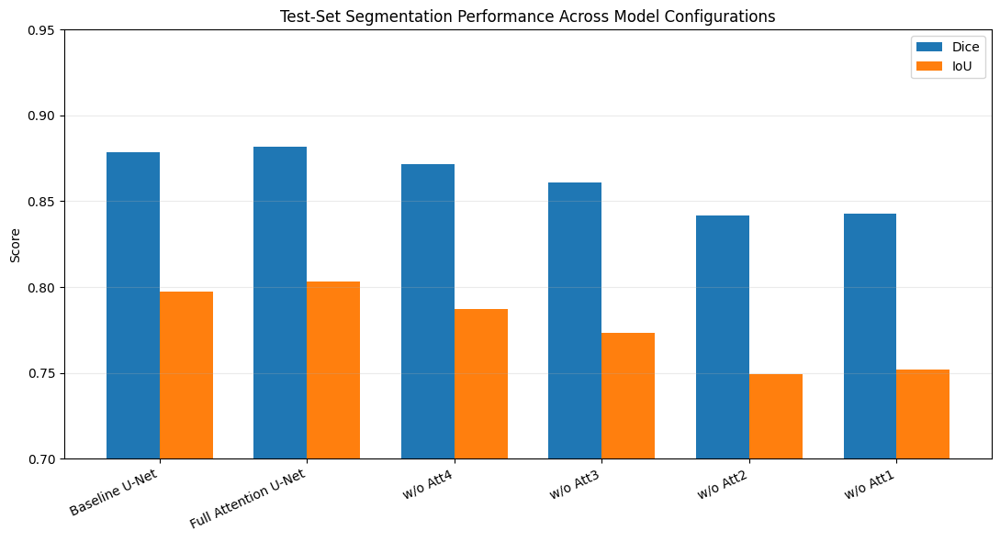

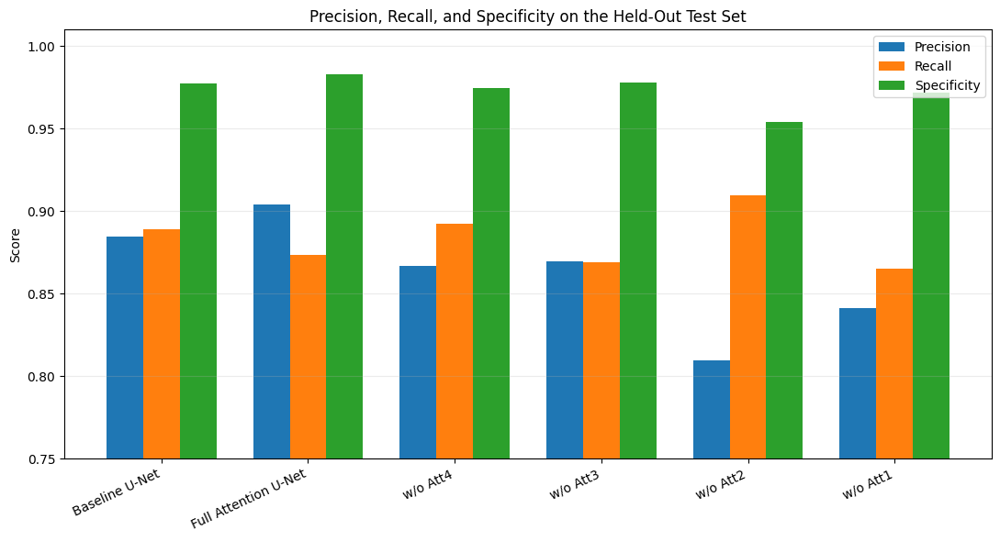


FINAL PUBLICATION TABLE


,Configuration,Dice,IoU,Precision,Recall,Specificity,F1,Accuracy,Balanced Accuracy
0,Baseline U-Net,0.8788,0.7975,0.8848,0.8891,0.9774,0.8788,0.9542,0.9333
1,Full Attention U-Net,0.8817,0.8031,0.9042,0.8737,0.9832,0.8817,0.9563,0.9285
2,w/o Att4,0.8717,0.7871,0.8666,0.8923,0.9746,0.8717,0.9530,0.9334
3,w/o Att3,0.8607,0.7735,0.8695,0.8689,0.9781,0.8607,0.9512,0.9235
4,w/o Att2,0.8416,0.7495,0.8095,0.9095,0.9540,0.8416,0.9382,0.9318
5,w/o Att1,0.8426,0.7520,0.8415,0.8653,0.9719,0.8426,0.9443,0.9186



Saved:
1. /kaggle/working/microplastic_project/figures/final_model_comparison_dice_iou.png
2. /kaggle/working/microplastic_project/figures/final_model_comparison_precision_recall_specificity.png
3. /kaggle/working/microplastic_project/results/final_model_comparison_publication_table.csv

Cell 53 complete.


In [84]:
# ============================================================================
# CELL 53 — FINAL PUBLICATION MODEL COMPARISON (CORRECTED)
# ============================================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")

table_path = os.path.join(
    RESULTS_DIR,
    "unified_test_macro_publication_table.csv"
)

df = pd.read_csv(table_path)

print("=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)

display(df)

# ---------------------------------------------------------------------------
# Actual verified column names
# ---------------------------------------------------------------------------

model_col = "configuration"

metric_map = {
    "Dice": "macro_dice",
    "IoU": "macro_iou",
    "Precision": "macro_precision",
    "Recall": "macro_recall",
    "Specificity": "macro_specificity",
    "F1": "macro_f1",
    "Accuracy": "macro_accuracy",
    "Balanced Accuracy": "macro_balanced_accuracy"
}

# Verify schema
missing = [
    column
    for column in metric_map.values()
    if column not in df.columns
]

if missing:
    raise ValueError(
        f"Missing columns from verified table: {missing}"
    )

# ---------------------------------------------------------------------------
# Publication labels
# ---------------------------------------------------------------------------

label_map = {
    "Baseline U-Net": "Baseline U-Net",
    "Full Attention U-Net": "Full Attention U-Net",
    "without_att4": "w/o Att4",
    "without_att3": "w/o Att3",
    "without_att2": "w/o Att2",
    "without_att1": "w/o Att1"
}

df["display_name"] = df[model_col].map(
    lambda x: label_map.get(x, x)
)

# ---------------------------------------------------------------------------
# Figure 1 — Dice and IoU
# ---------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 6)
)

x = np.arange(len(df))
width = 0.36

ax.bar(
    x - width / 2,
    df["macro_dice"],
    width,
    label="Dice"
)

ax.bar(
    x + width / 2,
    df["macro_iou"],
    width,
    label="IoU"
)

ax.set_xticks(x)

ax.set_xticklabels(
    df["display_name"],
    rotation=25,
    ha="right"
)

ax.set_ylabel("Score")

ax.set_ylim(
    0.70,
    0.95
)

ax.set_title(
    "Test-Set Segmentation Performance Across Model Configurations"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

comparison_fig = os.path.join(
    FIGURES_DIR,
    "final_model_comparison_dice_iou.png"
)

plt.savefig(
    comparison_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------------------------------------------
# Figure 2 — Precision / Recall / Specificity
# ---------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 6)
)

metrics = [
    ("macro_precision", "Precision"),
    ("macro_recall", "Recall"),
    ("macro_specificity", "Specificity")
]

width = 0.25
x = np.arange(len(df))

for i, (column, label) in enumerate(metrics):

    ax.bar(
        x + (i - 1) * width,
        df[column],
        width,
        label=label
    )

ax.set_xticks(x)

ax.set_xticklabels(
    df["display_name"],
    rotation=25,
    ha="right"
)

ax.set_ylabel("Score")

ax.set_ylim(
    0.75,
    1.01
)

ax.set_title(
    "Precision, Recall, and Specificity on the Held-Out Test Set"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

secondary_fig = os.path.join(
    FIGURES_DIR,
    "final_model_comparison_precision_recall_specificity.png"
)

plt.savefig(
    secondary_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------------------------------------------
# Final publication table
# ---------------------------------------------------------------------------

publication_table = pd.DataFrame({
    "Configuration": df[model_col],
    "Dice": df["macro_dice"],
    "IoU": df["macro_iou"],
    "Precision": df["macro_precision"],
    "Recall": df["macro_recall"],
    "Specificity": df["macro_specificity"],
    "F1": df["macro_f1"],
    "Accuracy": df["macro_accuracy"],
    "Balanced Accuracy": df["macro_balanced_accuracy"]
})

# Rename ablations for publication
publication_table["Configuration"] = (
    publication_table["Configuration"]
    .map(label_map)
    .fillna(publication_table["Configuration"])
)

# Round for presentation
numeric_columns = publication_table.columns[1:]

publication_table[numeric_columns] = (
    publication_table[numeric_columns]
    .round(4)
)

final_table_path = os.path.join(
    RESULTS_DIR,
    "final_model_comparison_publication_table.csv"
)

publication_table.to_csv(
    final_table_path,
    index=False
)

# ---------------------------------------------------------------------------
# Display
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL PUBLICATION TABLE")
print("=" * 80)

display(publication_table)

print("\nSaved:")
print(
    f"1. {comparison_fig}"
)

print(
    f"2. {secondary_fig}"
)

print(
    f"3. {final_table_path}"
)

print("\nCell 53 complete.")